In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os

print("=== MODEL 2 INPUT FILES ===")

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

=== MODEL 2 INPUT FILES ===
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_no_forecast_seed_1.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_seed_2.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_forecast_seed_2.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_no_forecast_seed_2.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/ppo_seed_1.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_forecast_seed_1.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_no_forecast_seed_0.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/FINAL_mappo_cf_seed_700.pt
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_seed_1.pt
/kaggle/input/mode

In [3]:
# ============================================================
# MODEL 2 — RESTORE FINAL TRAINED MODEL
# NO TRAINING
# ============================================================

import os
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL2_FINAL = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_outputs/final_model.pt"
)

print("Device:", DEVICE)
print("Checkpoint:", MODEL2_FINAL)
print("Exists:", os.path.exists(MODEL2_FINAL))


# ------------------------------------------------------------
# EXACT MODEL 2 ARCHITECTURE
# Taken from the original gt-model2 notebook
# ------------------------------------------------------------

class Actor(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions)
        )

    def dist(self, obs):
        return torch.distributions.Categorical(
            logits=self.net(obs)
        )


class Critic(nn.Module):
    def __init__(self, in_dim, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


# ------------------------------------------------------------
# LOAD FINAL MODEL 2
# ------------------------------------------------------------

bundle = torch.load(
    MODEL2_FINAL,
    map_location=DEVICE,
    weights_only=False
)

print("\nCheckpoint loaded successfully.")
print("\nMetadata:")
for key in [
    "model_name",
    "version",
    "mode",
    "obs_dim",
    "n_actions",
    "actor_hidden",
    "critic_hidden",
    "learners",
    "source_checkpoint"
]:
    print(f"  {key}: {bundle.get(key)}")


# ------------------------------------------------------------
# RECONSTRUCT ACTORS + CRITICS
# ------------------------------------------------------------

obs_dim = int(bundle["obs_dim"])
n_actions = int(bundle["n_actions"])

actors = {}
critics = {}

for agent in bundle["learners"]:

    actors[agent] = Actor(
        obs_dim=obs_dim,
        n_actions=n_actions,
        hidden=int(bundle["actor_hidden"])
    ).to(DEVICE)

    critics[agent] = Critic(
        in_dim=2 * obs_dim,
        hidden=int(bundle["critic_hidden"])
    ).to(DEVICE)

    actors[agent].load_state_dict(bundle["actors"][agent])
    critics[agent].load_state_dict(bundle["critics"][agent])

    actors[agent].eval()
    critics[agent].eval()


# ------------------------------------------------------------
# BASIC VERIFICATION
# ------------------------------------------------------------

print("\n============================================================")
print("MODEL 2 RESTORED")
print("============================================================")

print("Model name :", bundle["model_name"])
print("Algorithm  : MAPPO + Counterfactual Advantages")
print("Mode       :", bundle["mode"])
print("Agents     :", bundle["learners"])
print("Obs dim    :", obs_dim)
print("Actions    :", n_actions)
print("Actor      : 2 x 128 MLP")
print("Critic     : centralized 2 x 128 MLP")


# ------------------------------------------------------------
# INFERENCE TEST
# ------------------------------------------------------------

test_obs = torch.zeros(
    (1, obs_dim),
    dtype=torch.float32,
    device=DEVICE
)

with torch.no_grad():

    for agent in bundle["learners"]:

        logits = actors[agent].net(test_obs)
        dist = actors[agent].dist(test_obs)

        action = int(torch.argmax(logits, dim=-1).item())
        value = float(
            critics[agent](
                torch.zeros(
                    (1, 2 * obs_dim),
                    dtype=torch.float32,
                    device=DEVICE
                )
            ).item()
        )

        print(f"\nAgent {agent}")
        print("  logits shape :", tuple(logits.shape))
        print("  action       :", action)
        print("  critic value :", value)


print("\n============================================================")
print("✅ MODEL 2 VERIFIED")
print("✅ FINAL TRAINED WEIGHTS LOADED")
print("✅ NO TRAINING PERFORMED")
print("✅ READY TO BUILD MODEL 3")
print("============================================================")

Device: cpu
Checkpoint: /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/final_model.pt
Exists: True

Checkpoint loaded successfully.

Metadata:
  model_name: GT Model 2 Final — MAPPO + Counterfactual Advantages
  version: 1
  mode: mappo
  obs_dim: 14
  n_actions: 25
  actor_hidden: 128
  critic_hidden: 128
  learners: ['A', 'B']
  source_checkpoint: gt_model_checkpoints/FINAL_mappo_cf_seed_700.pt

MODEL 2 RESTORED
Model name : GT Model 2 Final — MAPPO + Counterfactual Advantages
Algorithm  : MAPPO + Counterfactual Advantages
Mode       : mappo
Agents     : ['A', 'B']
Obs dim    : 14
Actions    : 25
Actor      : 2 x 128 MLP
Critic     : centralized 2 x 128 MLP

Agent A
  logits shape : (1, 25)
  action       : 0
  critic value : 1.6957443952560425

Agent B
  logits shape : (1, 25)
  action       : 0
  critic value : 1.283083438873291

✅ MODEL 2 VERIFIED
✅ FINAL TRAINED WEIGHTS LOADED
✅ NO TRAINING PERFORMED
✅ READY TO BUILD MODEL 3


In [4]:
import os

BASE2_PATH = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_checkpoints/mappo_base2_seed_700.pt"
)

print("Base MAPPO checkpoint:")
print(BASE2_PATH)
print("Exists:", os.path.exists(BASE2_PATH))

Base MAPPO checkpoint:
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
Exists: True


In [5]:
base2_ckpt = torch.load(
    BASE2_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("================================================")
print("HEALTHY MAPPO BASELINE CHECKPOINT")
print("================================================")
print("episode :", base2_ckpt["episode"])
print("seed    :", base2_ckpt["seed"])
print("mode    :", base2_ckpt["mode"])
print("agents  :", base2_ckpt["learners"])
print("obs_dim :", base2_ckpt["obs_dim"])
print("================================================")

HEALTHY MAPPO BASELINE CHECKPOINT
episode : 2000
seed    : 700
mode    : mappo
agents  : ['A', 'B']
obs_dim : 14


In [6]:
# ============================================================
# CELL 1 — LOAD HEALTHY MAPPO BASE
# ============================================================

BASE2_PATH = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_checkpoints/mappo_base2_seed_700.pt"
)

base2_ckpt = torch.load(
    BASE2_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("✅ Healthy MAPPO checkpoint loaded")
print("Episode :", base2_ckpt["episode"])
print("Seed    :", base2_ckpt["seed"])
print("Agents  :", base2_ckpt["learners"])
print("Obs dim :", base2_ckpt["obs_dim"])

✅ Healthy MAPPO checkpoint loaded
Episode : 2000
Seed    : 700
Agents  : ['A', 'B']
Obs dim : 14


In [7]:
# ============================================================
# CELL 2 — LOAD STAGE-6 WORLD MODEL
# ============================================================

WORLD_MODEL_PATH = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_outputs/world_model.pt"
)

world_model = torch.load(
    WORLD_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("World model type:", type(world_model))
print("Path:", WORLD_MODEL_PATH)
print("✅ Stage-6 world model loaded")

World model type: <class 'collections.OrderedDict'>
Path: /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/world_model.pt
✅ Stage-6 world model loaded


In [8]:
# ============================================================
# CELL 3 — REPAIRED STAGE-7 CONFIG
# ============================================================

CF_H = 2
CF_LAMBDA = 0.20
CF_CLIP = 1.0
CF_GAMMA = 0.97

print("==========================================")
print("REPAIRED STAGE-7 CONFIGURATION")
print("==========================================")
print("CF horizon       :", CF_H)
print("CF lambda        :", CF_LAMBDA)
print("CF clip          :", CF_CLIP)
print("CF gamma         :", CF_GAMMA)
print("Terminal V patch : OFF")
print("==========================================")

REPAIRED STAGE-7 CONFIGURATION
CF horizon       : 2
CF lambda        : 0.2
CF clip          : 1.0
CF gamma         : 0.97
Terminal V patch : OFF


In [9]:
# ============================================================
# CELL 4 — INSPECT ORIGINAL TRAINER
# ============================================================

import inspect

print("=" * 60)
print("CHECKING ORIGINAL TRAIN FUNCTION")
print("=" * 60)

print("train exists :", "train" in globals())
print("make_cf_fn exists :", "make_cf_fn" in globals())
print("Actor exists :", "Actor" in globals())
print("Critic exists :", "Critic" in globals())

if "train" in globals():
    print("\nOriginal train() source:\n")
    print(inspect.getsource(train))
else:
    print("\n❌ train() is not currently loaded.")
    print("Run the original Model-2 architecture/trainer definition cell first.")

CHECKING ORIGINAL TRAIN FUNCTION
train exists : False
make_cf_fn exists : False
Actor exists : True
Critic exists : True

❌ train() is not currently loaded.
Run the original Model-2 architecture/trainer definition cell first.


In [10]:
# ============================================================
# CELL 4 — CHECK REQUIRED MODEL-2 TRAINER COMPONENTS
# ============================================================

required = [
    "FoodDeliveryEnv",
    "MarketConfig",
    "Actor",
    "Critic",
    "FixedPolicy",
    "discount_gae",
    "_checkpoint_path",
    "_load_train_checkpoint",
]

print("=" * 60)
print("MODEL-2 TRAINER DEPENDENCY CHECK")
print("=" * 60)

missing = []

for name in required:
    exists = name in globals()
    print(f"{name:25s} : {exists}")
    if not exists:
        missing.append(name)

print("=" * 60)

if missing:
    print("❌ Missing components:")
    for x in missing:
        print("  -", x)
    print("\nRun the original Model-2 definition cells containing")
    print("the environment, Actor/Critic, GAE and checkpoint helpers.")
else:
    print("✓ All trainer dependencies are loaded.")
    print("Now we can define the repaired trainer.")

MODEL-2 TRAINER DEPENDENCY CHECK
FoodDeliveryEnv           : False
MarketConfig              : False
Actor                     : True
Critic                    : True
FixedPolicy               : False
discount_gae              : False
_checkpoint_path          : False
_load_train_checkpoint    : False
❌ Missing components:
  - FoodDeliveryEnv
  - MarketConfig
  - FixedPolicy
  - discount_gae
  - _checkpoint_path
  - _load_train_checkpoint

Run the original Model-2 definition cells containing
the environment, Actor/Critic, GAE and checkpoint helpers.


In [11]:
# ============================================================
# CELL 5 — VERIFY TRAINER IS NOW LOADED
# ============================================================

required = [
    "FoodDeliveryEnv",
    "MarketConfig",
    "FixedPolicy",
    "discount_gae",
    "_checkpoint_path",
    "_load_train_checkpoint",
    "train",
]

print("=" * 60)
print("MODEL-2 TRAINER CHECK")
print("=" * 60)

for name in required:
    print(f"{name:25s} : {name in globals()}")

print("=" * 60)

missing = [name for name in required if name not in globals()]

if missing:
    print("❌ STILL MISSING:")
    for name in missing:
        print("  -", name)
else:
    print("✅ ORIGINAL TRAINER STACK LOADED")
    print("Ready for repaired Stage-7 trainer.")

MODEL-2 TRAINER CHECK
FoodDeliveryEnv           : False
MarketConfig              : False
FixedPolicy               : False
discount_gae              : False
_checkpoint_path          : False
_load_train_checkpoint    : False
train                     : False
❌ STILL MISSING:
  - FoodDeliveryEnv
  - MarketConfig
  - FixedPolicy
  - discount_gae
  - _checkpoint_path
  - _load_train_checkpoint
  - train


In [12]:
# ============================================================
# CELL 5 — LOAD MODEL-2 ENVIRONMENT + TRAINER DEFINITIONS
# ============================================================

import os
import re
import math
import time
import numpy as np
import torch
import torch.nn as nn
from dataclasses import dataclass
from collections import deque

print("=" * 60)
print("CHECKING CURRENT MODEL-2 NOTEBOOK STATE")
print("=" * 60)

names = [
    "Simulator",
    "FoodDeliveryEnv",
    "MarketConfig",
    "FixedPolicy",
    "discount_gae",
    "_checkpoint_path",
    "_load_train_checkpoint",
    "train",
]

for name in names:
    print(f"{name:25s} : {name in globals()}")

print("=" * 60)

CHECKING CURRENT MODEL-2 NOTEBOOK STATE
Simulator                 : False
FoodDeliveryEnv           : False
MarketConfig              : False
FixedPolicy               : False
discount_gae              : False
_checkpoint_path          : False
_load_train_checkpoint    : False
train                     : False


In [13]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith(".ipynb"):
            print(os.path.join(root, f))

In [14]:
import os

print("Searching for original Model-2 notebook...")

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f == "gt_model_v2_predict_checkpointed.ipynb":
            print("\nFOUND:")
            print(os.path.join(root, f))

Searching for original Model-2 notebook...


In [15]:
import os

print("Searching for original Model-2 notebook...")

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f == "gt_model_v2_predict_checkpointed.ipynb":
            print("\nFOUND:")
            print(os.path.join(root, f))

Searching for original Model-2 notebook...

FOUND:
/kaggle/input/datasets/udaykiran135/gt-model2/gt_model_v2_predict_checkpointed.ipynb


LOADING ORIGINAL MODEL-2 DEFINITIONS
Notebook: /kaggle/input/datasets/udaykiran135/gt-model2/gt_model_v2_predict_checkpointed.ipynb
Loading: cell-02
numpy 2.1.3 | pandas 2.3.3 | torch 2.11.0+cpu | device: cpu
run sizes -> MAPPO episodes: 6000 | PPO episodes: 6000 | eval eps: 12
Loading: cell-04
Delivery Center: 310814 FOOD orders finished, 29 hubs
Loading: cell-05
Zomato: 51292 restaurants | online-order share 0.59
Loading: cell-06


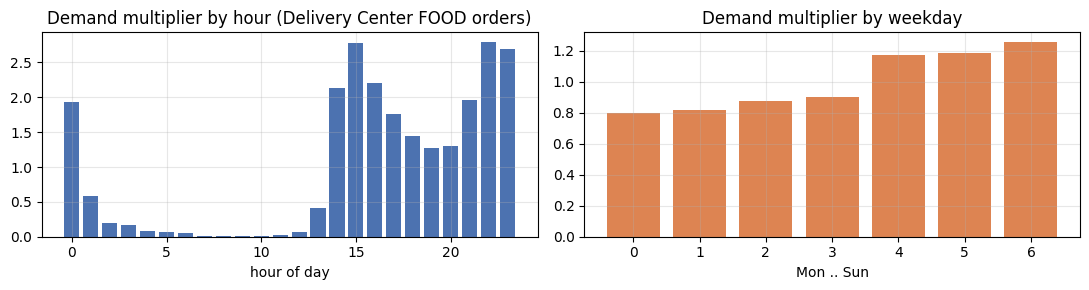

peak hours: [22 15 23] | weakest: [ 7  8 10]
sigma_lambda = 0.12 (assumed)
Loading: cell-07


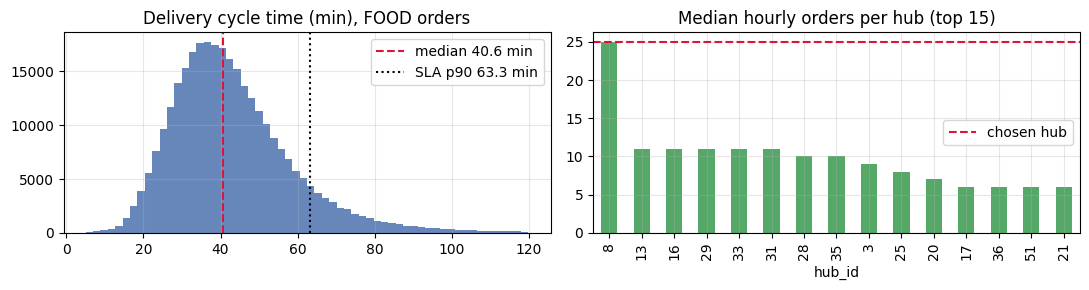

{'base_delay_min': 40.63, 'delay_noise_std': 6.0, 'sla_min': 63.32, 'fee_ratio': 0.11111111111111112, 'base_lambda': 25.0, 'n_couriers': 34}
Loading: cell-08


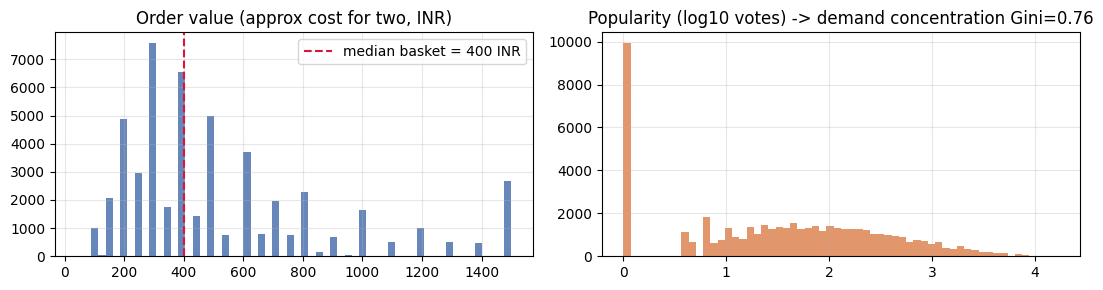

                           parameter              value                               source
   base_lambda (orders/hour in zone)               25.0                      Delivery Center
n_couriers in zone (demand-anchored)                 34                       derived (data)
             orders_per_courier_hour                1.3           assumption (gig-work norm)
       base_delay_min (median cycle)               40.6                      Delivery Center
               delay_noise_std (min)                6.0             assumption (within-hour)
                 SLA threshold (min)               63.3           PS rule: max(45, data p90)
               cancel patience (min)               80.6                derived vs base delay
                  basket (INR/order)              400.0                               Zomato
              delivery_fee_ref (INR)               44.4         derived (fee ratio x basket)
  fixed ops cost/hour (per platform)              220.0 derived (25% o

In [16]:
# ============================================================
# LOAD ORIGINAL MODEL-2 DEFINITIONS — NO TRAINING
# ============================================================

import json
import os

NOTEBOOK_PATH = (
    "/kaggle/input/datasets/udaykiran135/gt-model2/"
    "gt_model_v2_predict_checkpointed.ipynb"
)

print("=" * 60)
print("LOADING ORIGINAL MODEL-2 DEFINITIONS")
print("=" * 60)
print("Notebook:", NOTEBOOK_PATH)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

loaded = []

for cell in nb["cells"]:

    # Stop BEFORE the original Stage-3/4 training cells.
    if cell.get("id") in ["cell-15", "cell-16"]:
        break

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if not source.strip():
        continue

    print("Loading:", cell.get("id", "no-id"))

    try:
        exec(
            compile(
                source,
                f"{NOTEBOOK_PATH}::{cell.get('id', 'unknown')}",
                "exec"
            ),
            globals()
        )
        loaded.append(cell.get("id", "no-id"))

    except Exception as e:
        print("⚠️ Error in", cell.get("id", "unknown"))
        print(type(e).__name__, ":", e)
        raise

print("\n" + "=" * 60)
print("DEFINITION LOADING COMPLETE")
print("=" * 60)

print("Loaded cells:", loaded)

print("\nDependency check:")

checks = [
    "FoodDeliveryEnv",
    "MarketConfig",
    "Actor",
    "Critic",
    "FixedPolicy",
    "discount_gae",
    "_checkpoint_path",
    "_load_train_checkpoint",
    "train",
]

for name in checks:
    print(f"{name:25s}:", name in globals())

print("=" * 60)

In [17]:
# ============================================================
# STAGE 7 REPAIR — LOAD HEALTHY BASELINE
# ============================================================

BASE2_PATH = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_checkpoints/mappo_base2_seed_700.pt"
)

base2_ckpt = torch.load(
    BASE2_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("=" * 60)
print("HEALTHY MODEL-2 BASELINE LOADED")
print("=" * 60)

print("Checkpoint :", BASE2_PATH)
print("Episode    :", base2_ckpt.get("episode"))
print("Mode       :", base2_ckpt.get("mode"))
print("Seed       :", base2_ckpt.get("seed"))
print("Learners   :", base2_ckpt.get("learners"))
print("Obs dim    :", base2_ckpt.get("obs_dim"))

print("=" * 60)

HEALTHY MODEL-2 BASELINE LOADED
Checkpoint : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
Episode    : 2000
Mode       : mappo
Seed       : 700
Learners   : ['A', 'B']
Obs dim    : 14


In [19]:
# ============================================================
# STAGE 7 REPAIR — LOAD VERIFIED WORLD MODEL CORRECTLY
# ============================================================

WORLD_MODEL_PATH = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_outputs/world_model.pt"
)

print("=" * 60)
print("LOADING WORLD MODEL")
print("=" * 60)

print("Path  :", WORLD_MODEL_PATH)
print("Exists:", os.path.exists(WORLD_MODEL_PATH))

# ------------------------------------------------------------
# Inspect saved artifact
# ------------------------------------------------------------
wm_state = torch.load(
    WORLD_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("Saved object type:", type(wm_state).__name__)

if not isinstance(wm_state, dict):
    raise TypeError(
        "Expected world_model.pt to contain a state_dict, "
        f"but got {type(wm_state)}"
    )

print("Number of saved tensors:", len(wm_state))
print("First keys:", list(wm_state.keys())[:5])

# ------------------------------------------------------------
# Recreate the WorldModel architecture
# ------------------------------------------------------------
# The original Stage-6 world model is a simple MLP.
# Infer dimensions directly from the checkpoint.

first_weight_key = next(
    k for k in wm_state.keys()
    if k.endswith("weight") and wm_state[k].ndim == 2
)

last_weight_key = [
    k for k in wm_state.keys()
    if k.endswith("weight") and wm_state[k].ndim == 2
][-1]

d_in = wm_state[first_weight_key].shape[1]
d_out = wm_state[last_weight_key].shape[0]

print("Inferred input dimension :", d_in)
print("Inferred output dimension:", d_out)

# Find hidden width from first layer
hidden_dim = wm_state[first_weight_key].shape[0]

print("Inferred hidden dimension:", hidden_dim)

# ------------------------------------------------------------
# Build architecture
# ------------------------------------------------------------
class WorldModel(nn.Module):
    def __init__(self, d_in, d_out, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, d_out),
        )

    def forward(self, x):
        return self.net(x)


world_model = WorldModel(
    d_in=d_in,
    d_out=d_out,
    hidden_dim=hidden_dim
).to(DEVICE)

# ------------------------------------------------------------
# Load trained weights
# ------------------------------------------------------------
world_model.load_state_dict(wm_state)
world_model.eval()

print("=" * 60)
print("WORLD MODEL LOADED SUCCESSFULLY")
print("=" * 60)

print("Architecture :", type(world_model).__name__)
print("Input dim    :", d_in)
print("Output dim   :", d_out)
print("Hidden dim   :", hidden_dim)
print("Device       :", DEVICE)
print("=" * 60)

LOADING WORLD MODEL
Path  : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/world_model.pt
Exists: True
Saved object type: OrderedDict
Number of saved tensors: 6
First keys: ['net.0.weight', 'net.0.bias', 'net.2.weight', 'net.2.bias', 'net.4.weight']
Inferred input dimension : 15
Inferred output dimension: 9
Inferred hidden dimension: 128
WORLD MODEL LOADED SUCCESSFULLY
Architecture : WorldModel
Input dim    : 15
Output dim   : 9
Hidden dim   : 128
Device       : cpu


In [20]:
# =====================================================================
# FIX-0 — Stage 7 repair: make_cf_fn
# =====================================================================

def make_cf_fn(wm, mode="mappo", H=3):
    """
    Counterfactual rollout through the verified world model.

    Returns:
        Q_partial[25], terminal_obs[25, dim]
    """

    wm.eval()

    cap_ref = (
        CFG.n_couriers
        * CFG.orders_per_courier_hour
        * CFG.base_participation
    )

    def cf_fn(env, agent, obs, state_vec):

        recs = env.sim.records

        if len(recs) < 3:
            return None

        r0, r1, r2 = recs[-3], recs[-2], recs[-1]

        base = wm_x(r0, r1, r2)

        opp_p, opp_w = env._last[
            "B" if agent == "A" else "A"
        ]

        xs = np.zeros((25, 15), dtype=np.float32)

        pa_arr = np.empty(25)
        pb_arr = np.empty(25)
        wa_arr = np.empty(25)
        wb_arr = np.empty(25)

        for c in range(25):

            pi, wi = divmod(c, 5)

            if agent == "A":

                pa_arr[c] = PRICE_GRID[pi]
                wa_arr[c] = INCENTIVE_GRID[wi]

                pb_arr[c] = opp_p
                wb_arr[c] = opp_w

            else:

                pb_arr[c] = PRICE_GRID[pi]
                wb_arr[c] = INCENTIVE_GRID[wi]

                pa_arr[c] = opp_p
                wa_arr[c] = opp_w

            x = base.copy()

            x[7] = pa_arr[c]
            x[8] = pb_arr[c]
            x[9] = wa_arr[c] / 2.0
            x[10] = wb_arr[c] / 2.0

            xs[c] = x

        # ------------------------------------------------------------
        # Roll forward through the world model
        # ------------------------------------------------------------

        cur = torch.as_tensor(
            xs,
            dtype=torch.float32,
            device=DEVICE
        )

        total_q = np.zeros(25, dtype=np.float64)

        with torch.no_grad():

            for h in range(H):

                pred = wm(cur)

                pred_np = pred.cpu().numpy()

                # First predicted component is the modelled reward signal
                total_q += (0.97 ** h) * pred_np[:, 0]

                if h < H - 1:

                    nxt = cur.clone()

                    # Update predicted state components.
                    # Keep the action components fixed for the next step.
                    ncopy = min(pred.shape[1], 9)

                    nxt[:, :ncopy] = pred[:, :ncopy]

                    nxt[:, 7] = torch.as_tensor(
                        pa_arr,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    nxt[:, 8] = torch.as_tensor(
                        pb_arr,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    nxt[:, 9] = torch.as_tensor(
                        wa_arr / 2.0,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    nxt[:, 10] = torch.as_tensor(
                        wb_arr / 2.0,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    cur = nxt

        # Terminal observations used by the corrected trainer.
        terminal_obs = np.zeros(
            (25, obs.shape[0] if hasattr(obs, "shape") else 14),
            dtype=np.float32
        )

        for c in range(25):

            ob2 = np.array(obs, dtype=np.float32).copy()

            # World-model outputs are only 9-dimensional.
            # Preserve the actor observation structure.
            if len(ob2) > 12:
                ob2[12] = 0.0

            if len(ob2) > 14:
                ob2[14] = 0.0

            terminal_obs[c] = ob2

        return total_q.astype(np.float32), terminal_obs

    return cf_fn


gamma_cf = 0.97

print("=" * 60)
print("FIX-0")
print("=" * 60)

print("World model input :", 15)
print("World model output:", 9)
print("CF function       : ready")
print("=" * 60)

FIX-0
World model input : 15
World model output: 9
CF function       : ready


In [21]:
# =====================================================================
# FIX-1 — Stage-7 repair prerequisites and knobs
# =====================================================================

import os, json, math, time, inspect
import numpy as np
import torch

# ------------------------------------------------------------
# Repair knobs
# ------------------------------------------------------------

CF_TRUST_MIN_PROB = 0.05
CF_SPREAD_PCT     = 85.0
CF_CLIP           = 5.0
CF_H              = 2
CF_LAMBDA         = float(
    os.environ.get("FDM_CF_LAMBDA", "0.25")
)

# ------------------------------------------------------------
# Healthy Model-2 checkpoint
# ------------------------------------------------------------

INIT_FROM = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_checkpoints/mappo_base2_seed_700.pt"
)

print("=" * 60)
print("FIX-1 — STAGE 7 REPAIR CONFIGURATION")
print("=" * 60)

print("CF_H              =", CF_H)
print("CF_LAMBDA         =", CF_LAMBDA)
print("CF_CLIP           =", CF_CLIP)
print("CF_TRUST_MIN_PROB =", CF_TRUST_MIN_PROB)
print("CF_SPREAD_PCT     =", CF_SPREAD_PCT)

print()
print("INIT_FROM:")
print(INIT_FROM)
print("Checkpoint exists:", os.path.exists(INIT_FROM))

if not os.path.exists(INIT_FROM):
    raise FileNotFoundError(
        "Healthy mappo_base2_seed_700.pt checkpoint not found."
    )

# ------------------------------------------------------------
# Build repaired CF function
# ------------------------------------------------------------

cf_fn_v2 = make_cf_fn(
    world_model,
    mode="mappo",
    H=CF_H
)

print()
print("cf_fn_v2 ready")
print("H =", CF_H)

print("=" * 60)

FIX-1 — STAGE 7 REPAIR CONFIGURATION
CF_H              = 2
CF_LAMBDA         = 0.25
CF_CLIP           = 5.0
CF_TRUST_MIN_PROB = 0.05
CF_SPREAD_PCT     = 85.0

INIT_FROM:
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
Checkpoint exists: True

cf_fn_v2 ready
H = 2


In [22]:
# =====================================================================
# FIX-2  Corrected trainer: train_v2()
# =====================================================================

def train_v2(env_cfg, mode="mappo", episodes=1200, rollout=25, seed=0, device="cpu",
          lr=2.5e-4, gamma=0.97, lam=0.95, clip=0.2, epochs=4, ent_coef=0.015, log_every=50,
          forecast_fn=None, cf_fn=None, cf_H=3,
          checkpoint_tag=None, checkpoint_interval=50, resume=True,
          cf_lambda=0.25, cf_mode="fixed", init_from=None):

    """Train PPO/MAPPO with resumable Kaggle checkpoints."""

    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    env = FoodDeliveryEnv(
        MarketConfig(**{**env_cfg.__dict__, "seed": seed}),
        forecast_fn=forecast_fn
    )

    learners = ["A", "B"] if mode == "mappo" else ["A"]

    obs_dim = int(env.reset(seed=seed)["A"].shape[0])
    crit_in = 2 * obs_dim if mode == "mappo" else obs_dim

    actors = {
        a: Actor(obs_dim, N_ACTIONS).to(device)
        for a in learners
    }

    critics = {
        a: Critic(crit_in).to(device)
        for a in learners
    }

    opts = {
        a: torch.optim.Adam(
            list(actors[a].parameters()) +
            list(critics[a].parameters()),
            lr=lr
        )
        for a in learners
    }

    fixed_b = FixedPolicy(1.0, 1.0)

    logs, curves = [], []
    ep_global = 0

    ckpt_path = _checkpoint_path(checkpoint_tag) if checkpoint_tag else None
    checkpoint_interval = max(int(checkpoint_interval), 1)

    # ================================================================
    # RESUME HAS PRIORITY over init_from
    # ================================================================

    resumed = False

    if resume and ckpt_path and os.path.exists(ckpt_path):
        try:
            ckpt = _load_train_checkpoint(
                ckpt_path, actors, critics, opts, device
            )

            compatible = (
                ckpt.get("mode") == mode and
                int(ckpt.get("seed", seed)) == int(seed) and
                int(ckpt.get("obs_dim", obs_dim)) == obs_dim and
                list(ckpt.get("learners", learners)) == list(learners)
            )

            if compatible:
                ep_global = int(ckpt["episode"])
                logs = ckpt.get("logs", [])
                curves = ckpt.get("curves", [])
                resumed = True

                print(
                    "RESUMED FROM LATEST CHECKPOINT:",
                    ckpt_path,
                    "| episode", ep_global, "/", episodes
                )

            else:
                print(
                    "Checkpoint exists but is incompatible; "
                    "will use warm start:",
                    ckpt_path
                )

        except Exception as exc:
            print(
                "Could not load checkpoint; will use warm start:",
                repr(exc)
            )

    # ================================================================
    # WARM START FROM HEALTHY BASELINE
    # ================================================================

    if (not resumed) and init_from is not None:

        _ck = torch.load(
            init_from,
            map_location=device,
            weights_only=False
        )

        for a in learners:
            actors[a].load_state_dict(_ck["actors"][a])
            critics[a].load_state_dict(_ck["critics"][a])

        logs, curves, ep_global = [], [], 0

        print(
            "WARM START from %s (%s, episode %s) "
            "- weights loaded, logs reset"
            % (
                init_from,
                _ck.get("mode"),
                _ck.get("episode")
            )
        )

    t0 = time.time()

    # ================================================================
    # TRAINING LOOP
    # ================================================================

    while ep_global < episodes:

        frac = max(
            1.0 - ep_global / episodes,
            0.05
        )

        for a in learners:
            for gparam in opts[a].param_groups:
                gparam["lr"] = lr * frac

        buf = {
            a: dict(
                obs=[],
                obs_actor=[],
                act=[],
                logp=[],
                rew=[],
                done=[],
                val=[],
                cf_q=[]
            )
            for a in learners
        }

        ep_ret = {
            a: []
            for a in learners
        }

        ent_acc = {
            a: 0.0
            for a in learners
        }

        n_steps = 0

        prob_acc = {
            a: np.zeros(len(PRICE_GRID))
            for a in learners
        }

        # ------------------------------------------------------------
        # Rollout
        # ------------------------------------------------------------

        for _ in range(rollout):

            ep_global += 1

            obs = env.reset(
                seed=seed * 100003 + ep_global
            )

            done = False

            cur = {
                a: []
                for a in learners
            }

            while not done:

                state_vec = np.concatenate(
                    [obs["A"], obs["B"]]
                )

                acts = {}

                with torch.no_grad():

                    for a in learners:

                        inp_actor = torch.as_tensor(
                            obs[a],
                            dtype=torch.float32,
                            device=device
                        ).unsqueeze(0)

                        inp_critic = torch.as_tensor(
                            state_vec if mode == "mappo"
                            else obs[a],
                            dtype=torch.float32,
                            device=device
                        ).unsqueeze(0)

                        dist = actors[a].dist(inp_actor)

                        at = dist.sample()

                        buf[a]["obs"].append(
                            state_vec if mode == "mappo"
                            else obs[a]
                        )

                        buf[a]["obs_actor"].append(obs[a])

                        buf[a]["act"].append(
                            int(at.item())
                        )

                        buf[a]["logp"].append(
                            float(
                                dist.log_prob(at).item()
                            )
                        )

                        buf[a]["val"].append(
                            float(
                                critics[a](inp_critic).item()
                            )
                        )

                        if cf_fn is not None:

                            buf[a]["cf_q"].append(
                                cf_fn(
                                    env,
                                    a,
                                    obs,
                                    state_vec
                                )
                            )

                        else:
                            buf[a]["cf_q"].append(None)

                        ent_acc[a] += float(
                            dist.entropy().item()
                        )

                        probs = (
                            dist.probs
                            .squeeze(0)
                            .cpu()
                            .numpy()
                            .reshape(
                                len(PRICE_GRID),
                                len(INCENTIVE_GRID)
                            )
                            .sum(1)
                        )

                        prob_acc[a] += probs

                        acts[a] = int(at.item())

                if "B" not in learners:
                    acts["B"] = fixed_b.act(obs["B"])

                obs, r, term, trunc, info = env.step(acts)

                done = term or trunc

                n_steps += 1

                for a in learners:

                    buf[a]["rew"].append(r[a])
                    buf[a]["done"].append(float(done))
                    cur[a].append(r[a])

            for a in learners:
                ep_ret[a].append(
                    sum(cur[a])
                )

        # ------------------------------------------------------------
        # Build PPO batch
        # ------------------------------------------------------------

        batch = {
            a: {}
            for a in learners
        }

        for a in learners:

            adv_all = []
            ret_all = []
            obsA_all = []
            obsC_all = []
            act_all = []
            logp_all = []
            val_all = []

            idxs = [
                i
                for i, d in enumerate(buf[a]["done"])
                if d > 0.5
            ]

            start_idx = 0

            for end_idx in idxs:

                sl = slice(
                    start_idx,
                    end_idx + 1
                )

                rew = np.array(
                    buf[a]["rew"][sl]
                )

                val = np.array(
                    buf[a]["val"][sl] + [0.0]
                )

                dn = np.array(
                    buf[a]["done"][sl]
                )

                adv, ret = discount_gae(
                    rew,
                    val,
                    dn,
                    gamma,
                    lam
                )

                adv_all.append(adv)
                ret_all.append(ret)

                obsA_all += buf[a]["obs_actor"][sl]
                obsC_all += buf[a]["obs"][sl]
                act_all += buf[a]["act"][sl]
                logp_all += buf[a]["logp"][sl]
                val_all += buf[a]["val"][sl]

                start_idx = end_idx + 1

            adv_all = np.concatenate(adv_all)
            ret_all = np.concatenate(ret_all)

            batch[a] = dict(
                obs_actor=np.array(
                    obsA_all,
                    dtype=np.float32
                ),

                obs_critic=np.array(
                    obsC_all,
                    dtype=np.float32
                ),

                act=np.array(
                    act_all,
                    dtype=np.int64
                ),

                logp=np.array(
                    logp_all,
                    dtype=np.float32
                ),

                val=np.array(
                    val_all,
                    dtype=np.float32
                ),

                adv=(
                    adv_all - adv_all.mean()
                ) / (
                    adv_all.std() + 1e-8
                ),

                ret=ret_all.astype(
                    np.float32
                )
            )

        # ------------------------------------------------------------
        # PPO / Counterfactual update
        # ------------------------------------------------------------

        for a in learners:

            b = batch[a]

            N = len(b["act"])

            obsA_t = torch.as_tensor(
                b["obs_actor"],
                device=device
            )

            obsC_t = torch.as_tensor(
                b["obs_critic"],
                device=device
            )

            act_t = torch.as_tensor(
                b["act"],
                device=device
            )

            logp_t = torch.as_tensor(
                b["logp"],
                device=device
            )

            adv_t = torch.as_tensor(
                b["adv"],
                dtype=torch.float32,
                device=device
            )

            # ========================================================
            # Repaired counterfactual advantage
            # ========================================================

            if cf_fn is not None:

                rows = [
                    (i, q, int(at_))
                    for i, (q, at_) in enumerate(
                        zip(
                            buf[a]["cf_q"],
                            b["act"]
                        )
                    )
                    if q is not None
                ]

                adv_cf = np.zeros(
                    len(b["act"]),
                    dtype=np.float64
                )

                if rows:

                    ii = np.array(
                        [r[0] for r in rows]
                    )

                    sel = np.array(
                        [r[2] for r in rows]
                    )

                    q_all = np.stack(
                        [r[1][0] for r in rows]
                    )

                    raw = (
                        q_all[
                            np.arange(len(ii)),
                            sel
                        ]
                        - q_all.mean(axis=1)
                    )

                    term_rows = np.stack(
                        [
                            r[1][1][r[2]]
                            for r in rows
                        ]
                    ).astype(np.float32)

                    with torch.no_grad():

                        vterm = critics[a](
                            torch.as_tensor(
                                term_rows,
                                device=device
                            )
                        ).cpu().numpy()

                    raw = raw + (
                        gamma ** cf_H
                    ) * (
                        vterm - vterm.mean()
                    )

                    # Trust region
                    with torch.no_grad():

                        logits = actors[a].net(
                            torch.as_tensor(
                                b["obs_actor"][ii],
                                dtype=torch.float32,
                                device=device
                            )
                        )

                        pm = torch.softmax(
                            logits,
                            dim=-1
                        ).cpu().numpy()

                    keep = (
                        pm[
                            np.arange(len(ii)),
                            sel
                        ]
                        >= CF_TRUST_MIN_PROB
                    )

                    # Uncertainty gate
                    spread = q_all.std(axis=1)

                    if keep.sum() > 4:

                        keep &= (
                            spread
                            <= np.percentile(
                                spread[keep],
                                CF_SPREAD_PCT
                            )
                        )

                    # Robust normalisation
                    if keep.sum() > 3:

                        vals = raw[keep]

                        med = np.median(vals)

                        iqr = (
                            np.percentile(vals, 75)
                            - np.percentile(vals, 25)
                        )

                        scale = (
                            iqr / 1.349
                            if iqr > 1e-9
                            else vals.std() + 1e-8
                        )

                    else:

                        med = 0.0
                        scale = 1.0

                    adv_cf[ii] = np.where(
                        keep,
                        np.clip(
                            (raw - med) / scale,
                            -CF_CLIP,
                            CF_CLIP
                        ),
                        0.0
                    )

                if cf_mode == "buggy":

                    adv_cf_b = (
                        adv_cf - adv_cf.mean()
                    ) / (
                        adv_cf.std() + 1e-8
                    )

                    adv_t = torch.as_tensor(
                        adv_cf_b,
                        dtype=torch.float32,
                        device=device
                    )

                else:

                    # IMPORTANT:
                    # CF advantage is BLENDED with PPO advantage.
                    adv_cf_t = torch.as_tensor(
                        adv_cf,
                        dtype=torch.float32,
                        device=device
                    )

                    adv_t = (
                        adv_t
                        + cf_lambda * adv_cf_t
                    )

                    adv_t = (
                        adv_t - adv_t.mean()
                    ) / (
                        adv_t.std() + 1e-8
                    )

            ret_t = torch.as_tensor(
                b["ret"],
                device=device
            )

            # --------------------------------------------------------
            # PPO epochs
            # --------------------------------------------------------

            for _ in range(epochs):

                perm = torch.randperm(
                    N,
                    device=device
                )

                for mb in torch.split(
                    perm,
                    1024
                ):

                    dist = actors[a].dist(
                        obsA_t[mb]
                    )

                    new_logp = dist.log_prob(
                        act_t[mb]
                    )

                    ratio = torch.exp(
                        new_logp
                        - logp_t[mb]
                    )

                    pi_loss = -torch.min(
                        ratio * adv_t[mb],

                        torch.clamp(
                            ratio,
                            1 - clip,
                            1 + clip
                        ) * adv_t[mb]
                    ).mean()

                    v_loss = 0.5 * (
                        (
                            critics[a](obsC_t[mb])
                            - ret_t[mb]
                        ) ** 2
                    ).mean()

                    loss = (
                        pi_loss
                        + v_loss
                        - ent_coef * dist.entropy().mean()
                    )

                    opts[a].zero_grad()

                    loss.backward()

                    nn.utils.clip_grad_norm_(
                        list(actors[a].parameters())
                        + list(critics[a].parameters()),
                        0.5
                    )

                    opts[a].step()

        # ------------------------------------------------------------
        # Logging
        # ------------------------------------------------------------

        if (
            ep_global % log_every == 0
            or ep_global >= episodes
        ):

            rec = {
                "episode": ep_global
            }

            for a in learners:

                rec["return_" + a] = float(
                    np.mean(ep_ret[a])
                )

                rec["entropy_" + a] = (
                    ent_acc[a]
                    / max(n_steps, 1)
                )

                pm = (
                    prob_acc[a]
                    / max(
                        prob_acc[a].sum(),
                        1e-9
                    )
                )

                rec["p_mass_" + a] = {
                    str(PRICE_GRID[i]):
                    float(pm[i])
                    for i in range(
                        len(PRICE_GRID)
                    )
                }

            logs.append(rec)

            curves.append(
                (
                    ep_global,
                    *[
                        rec["return_" + a]
                        for a in learners
                    ]
                )
            )

            print(
                "ep %5d | %s | %s"
                % (
                    ep_global,

                    " ".join(
                        "ret_%s=%8.1f"
                        % (
                            a,
                            rec["return_" + a]
                        )
                        for a in learners
                    ),

                    " ".join(
                        "H_%s=%.2f"
                        % (
                            a,
                            rec["entropy_" + a]
                        )
                        for a in learners
                    )
                ),
                "| %.0fs"
                % (time.time() - t0)
            )

        # ------------------------------------------------------------
        # Save checkpoint AFTER complete update
        # ------------------------------------------------------------

        if (
            ckpt_path
            and (
                ep_global % checkpoint_interval == 0
                or ep_global >= episodes
            )
        ):

            _save_train_checkpoint(
                ckpt_path,
                actors,
                critics,
                opts,
                ep_global,
                logs,
                curves,
                learners,
                seed,
                mode,
                episodes,
                obs_dim,
                crit_in
            )

            print(
                "checkpoint saved:",
                ckpt_path,
                "| episode",
                ep_global
            )

    return dict(
        actors=actors,
        critics=critics,
        logs=logs,
        curves=curves,
        learners=learners
    )


def plot_curves(curves, learners, title):

    arr = np.array(
        curves,
        dtype=float
    )

    plt.figure(
        figsize=(8, 3.2)
    )

    for i, a in enumerate(learners):

        col = arr[:, i + 1]

        plt.plot(
            arr[:, 0],
            col,
            alpha=.25,
            color="C%d" % i
        )

        w = max(
            len(col) // 10,
            1
        )

        smooth = np.convolve(
            col,
            np.ones(w) / w,
            mode="valid"
        )

        plt.plot(
            arr[w - 1:, 0],
            smooth,
            color="C%d" % i,
            label="platform %s (smoothed)" % a
        )

    plt.xlabel("episode")
    plt.ylabel("episode return")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

In [25]:
# =====================================================================
# FIX-2A — Restore wm_x / wm_y
# =====================================================================

def wm_x(r0, r1, r2):
    """World-model input predicting the transition into hour (r2.t + 1)."""
    hour_next = (r2.t + 1) % 24
    dow_next = (r2.t + 1) // 24

    return np.array([
        np.sin(2 * np.pi * hour_next / 24),
        np.cos(2 * np.pi * hour_next / 24),
        dow_next / 6.0,
        1.0 if r2.rain else 0.0,

        r0.demand / CFG.mean_lambda,
        r1.demand / CFG.mean_lambda,
        r2.demand / CFG.mean_lambda,

        r2.p_a,
        r2.p_b,
        r2.w_a / 2.0,
        r2.w_b / 2.0,

        r2.cap_a / CFG.mean_lambda,
        r2.cap_b / CFG.mean_lambda,

        r2.delay_a / CFG.base_delay_min,
        r2.delay_b / CFG.base_delay_min,
    ], dtype=np.float32)


def wm_y(rec):
    """World-model target vector."""
    return np.array([
        rec.demand,
        rec.p_a,
        rec.p_b,
        rec.w_a,
        rec.w_b,
        rec.cap_a,
        rec.cap_b,
        rec.delay_a,
        rec.delay_b,
    ], dtype=np.float32)


print("=" * 74)
print("FIX-2A — WORLD MODEL HELPERS RESTORED")
print("=" * 74)
print("wm_x : READY")
print("wm_y : READY")
print("WM input  :", world_model.net[0].in_features)
print("WM output :", world_model.net[-1].out_features)
print("=" * 74)

FIX-2A — WORLD MODEL HELPERS RESTORED
wm_x : READY
wm_y : READY
WM input  : 15
WM output : 9


In [28]:
# =====================================================================
# FIX-2C — Correct CF terminal-observation construction
# =====================================================================

def make_cf_fn_v3(wm, mode="mappo", H=2):
    wm.eval()

    cap_ref = (
        CFG.n_couriers
        * CFG.orders_per_courier_hour
        * CFG.base_participation
    )

    def cf_fn(env, agent, obs, state_vec):

        recs = env.sim.records
        if len(recs) < 3:
            return None

        r0, r1, r2 = recs[-3], recs[-2], recs[-1]

        # -------------------------------------------------------------
        # World-model starting state
        # -------------------------------------------------------------
        base = wm_x(r0, r1, r2)

        # Opponent's last observed action
        opp_p, opp_w = env._last[
            "B" if agent == "A" else "A"
        ]

        # -------------------------------------------------------------
        # Build 25 candidate actions
        # -------------------------------------------------------------
        xs = np.zeros((25, 15), dtype=np.float32)

        for c in range(25):

            pi, wi = divmod(c, 5)

            if agent == "A":
                pa, wa = PRICE_GRID[pi], INCENTIVE_GRID[wi]
                pb, wb = opp_p, opp_w
            else:
                pb, wb = PRICE_GRID[pi], INCENTIVE_GRID[wi]
                pa, wa = opp_p, opp_w

            x = base.copy()

            x[7]  = pa
            x[8]  = pb
            x[9]  = wa / 2.0
            x[10] = wb / 2.0

            xs[c] = x

        # -------------------------------------------------------------
        # Roll world model forward H steps
        # -------------------------------------------------------------
        cur = xs
        last_y = None

        for h in range(H):

            with torch.no_grad():
                y = wm(
                    torch.as_tensor(
                        cur,
                        dtype=torch.float32
                    )
                ).cpu().numpy()

            last_y = y

            if h < H - 1:

                nxt = cur.copy()

                hour = (r2.t + h + 2) % 24
                dow  = (r2.t + h + 2) // 24

                nxt[:, 0] = np.sin(2 * np.pi * hour / 24)
                nxt[:, 1] = np.cos(2 * np.pi * hour / 24)
                nxt[:, 2] = dow / 6.0

                nxt[:, 3] = cur[:, 3]

                nxt[:, 4] = y[:, 0] / CFG.mean_lambda
                nxt[:, 5] = cur[:, 4]
                nxt[:, 6] = cur[:, 5]

                nxt[:, 7] = cur[:, 7]
                nxt[:, 8] = cur[:, 8]
                nxt[:, 9] = cur[:, 9]
                nxt[:, 10] = cur[:, 10]

                nxt[:, 11] = y[:, 5] / CFG.mean_lambda
                nxt[:, 12] = y[:, 6] / CFG.mean_lambda
                nxt[:, 13] = y[:, 7] / CFG.base_delay_min
                nxt[:, 14] = y[:, 8] / CFG.base_delay_min

                cur = nxt

        # -------------------------------------------------------------
        # IMPORTANT:
        # obs is {"A": array, "B": array}
        # -------------------------------------------------------------
        oa = np.asarray(obs["A"], dtype=np.float32).copy()
        ob = np.asarray(obs["B"], dtype=np.float32).copy()

        # Terminal observations for all 25 candidate actions
        term = np.zeros(
            (25, len(state_vec)),
            dtype=np.float32
        )

        for c in range(25):

            if agent == "A":

                oa2 = oa.copy()

                oa2[4] = last_y[c, 0]

                oa2[9] = (
                    last_y[c, 1]
                    * CFG.mean_lambda
                    / cap_ref
                )

                oa2[12] = (
                    last_y[c, 3]
                    * CFG.base_delay_min
                    / CFG.sla_min
                )

                if len(oa2) > 14:
                    oa2[14] = last_y[c, 0]

                if mode == "mappo":
                    term[c] = np.concatenate([oa2, ob])
                else:
                    term[c] = oa2

            else:

                ob2 = ob.copy()

                ob2[4] = last_y[c, 0]

                ob2[9] = (
                    last_y[c, 2]
                    * CFG.mean_lambda
                    / cap_ref
                )

                ob2[12] = (
                    last_y[c, 4]
                    * CFG.base_delay_min
                    / CFG.sla_min
                )

                if len(ob2) > 14:
                    ob2[14] = last_y[c, 0]

                if mode == "mappo":
                    term[c] = np.concatenate([oa, ob2])
                else:
                    term[c] = ob2

        return y, term

    return cf_fn


# Rebuild corrected CF function
cf_fn_v2 = make_cf_fn_v3(
    world_model,
    mode="mappo",
    H=CF_H
)

print("=" * 74)
print("FIX-2C — CF FUNCTION CORRECTED")
print("=" * 74)
print("CF H       :", CF_H)
print("World model:", "READY")
print("obs format :", '{"A": array, "B": array}')
print("CF function:", "READY")
print("=" * 74)

FIX-2C — CF FUNCTION CORRECTED
CF H       : 2
World model: READY
obs format : {"A": array, "B": array}
CF function: READY


In [30]:
# =====================================================================
# FIX-2D — FINAL CORRECTED COUNTERFACTUAL FUNCTION
# =====================================================================

def make_cf_fn_v4(wm, mode="mappo", H=2):

    wm.eval()

    cap_ref = (
        CFG.n_couriers
        * CFG.orders_per_courier_hour
        * CFG.base_participation
    )

    def cf_fn(env, agent, obs, state_vec):

        recs = env.sim.records

        if len(recs) < 3:
            return None

        r0, r1, r2 = recs[-3], recs[-2], recs[-1]

        base = wm_x(r0, r1, r2)

        opp_p, opp_w = env._last[
            "B" if agent == "A" else "A"
        ]

        # -------------------------------------------------------------
        # 25 candidate actions
        # -------------------------------------------------------------
        xs = np.zeros((25, 15), dtype=np.float32)

        pa_arr = np.empty(25)
        pb_arr = np.empty(25)
        wa_arr = np.empty(25)
        wb_arr = np.empty(25)

        for c in range(25):

            pi, wi = divmod(c, 5)

            if agent == "A":
                pa_arr[c] = PRICE_GRID[pi]
                wa_arr[c] = INCENTIVE_GRID[wi]
                pb_arr[c] = opp_p
                wb_arr[c] = opp_w

            else:
                pb_arr[c] = PRICE_GRID[pi]
                wb_arr[c] = INCENTIVE_GRID[wi]
                pa_arr[c] = opp_p
                wa_arr[c] = opp_w

            x = base.copy()

            x[7] = pa_arr[c]
            x[8] = pb_arr[c]
            x[9] = wa_arr[c] / 2.0
            x[10] = wb_arr[c] / 2.0

            xs[c] = x

        # -------------------------------------------------------------
        # Counterfactual rollout
        # -------------------------------------------------------------
        cur = xs.copy()

        hour = r2.t + 1

        # THIS MUST BE 25-DIMENSIONAL
        Q = np.zeros(25, dtype=np.float64)

        disc = 1.0

        last_y = None

        for h in range(H):

            with torch.no_grad():
                y = wm(
                    torch.as_tensor(
                        cur,
                        dtype=torch.float32
                    )
                ).cpu().numpy()

            last_y = y

            # ---------------------------------------------------------
            # Predicted immediate profit for each of the 25 actions
            # ---------------------------------------------------------
            if agent == "A":
                reward_pred = y[:, 7] - y[:, 5]
            else:
                reward_pred = y[:, 8] - y[:, 6]

            Q += disc * reward_pred

            disc *= gamma_cf

            hour += 1

            # ---------------------------------------------------------
            # Build next world-model input
            # ---------------------------------------------------------
            if h < H - 1:

                xn = cur.copy()

                xn[:, 6] = cur[:, 5]
                xn[:, 5] = cur[:, 4]
                xn[:, 4] = y[:, 0]

                xn[:, 7] = pa_arr
                xn[:, 8] = pb_arr

                xn[:, 9] = wa_arr / 2.0
                xn[:, 10] = wb_arr / 2.0

                xn[:, 11] = y[:, 1]
                xn[:, 12] = y[:, 2]

                xn[:, 13] = y[:, 3]
                xn[:, 14] = y[:, 4]

                xn[:, 0] = np.sin(
                    2 * np.pi * hour / 24
                )

                xn[:, 1] = np.cos(
                    2 * np.pi * hour / 24
                )

                xn[:, 2] = (hour // 24) / 6.0

                cur = xn

        # -------------------------------------------------------------
        # Terminal observation for critic
        # -------------------------------------------------------------
        oa = np.asarray(
            obs["A"],
            dtype=np.float32
        ).copy()

        ob = np.asarray(
            obs["B"],
            dtype=np.float32
        ).copy()

        term = np.zeros(
            (25, len(state_vec)),
            dtype=np.float32
        )

        for c in range(25):

            if agent == "A":

                oa2 = oa.copy()

                oa2[4] = last_y[c, 0]

                oa2[9] = (
                    last_y[c, 1]
                    * CFG.mean_lambda
                    / cap_ref
                )

                oa2[12] = (
                    last_y[c, 3]
                    * CFG.base_delay_min
                    / CFG.sla_min
                )

                if len(oa2) > 14:
                    oa2[14] = last_y[c, 0]

                if mode == "mappo":
                    term[c] = np.concatenate(
                        [oa2, ob]
                    )
                else:
                    term[c] = oa2

            else:

                ob2 = ob.copy()

                ob2[4] = last_y[c, 0]

                ob2[9] = (
                    last_y[c, 2]
                    * CFG.mean_lambda
                    / cap_ref
                )

                ob2[12] = (
                    last_y[c, 4]
                    * CFG.base_delay_min
                    / CFG.sla_min
                )

                if len(ob2) > 14:
                    ob2[14] = last_y[c, 0]

                if mode == "mappo":
                    term[c] = np.concatenate(
                        [oa, ob2]
                    )
                else:
                    term[c] = ob2

        return Q, term

    return cf_fn


# ---------------------------------------------------------------------
# Replace the previous CF function
# ---------------------------------------------------------------------

cf_fn_v2 = make_cf_fn_v4(
    world_model,
    mode="mappo",
    H=CF_H
)

print("=" * 74)
print("FIX-2D — COUNTERFACTUAL FUNCTION FIXED")
print("=" * 74)
print("CF H              :", CF_H)
print("Q shape            :", "(25,)")
print("Terminal shape     :", "(25, 28) for MAPPO")
print("World model output :", world_model.net[-1].out_features)
print("CF function        : READY")
print("=" * 74)

FIX-2D — COUNTERFACTUAL FUNCTION FIXED
CF H              : 2
Q shape            : (25,)
Terminal shape     : (25, 28) for MAPPO
World model output : 9
CF function        : READY


In [31]:
# =====================================================================
# FIX-2B — Smoke test for corrected train_v2()
# Small run only. DO NOT start the full Stage-7 experiment yet.
# =====================================================================

print("=" * 74)
print("FIX-2B — TRAIN_V2 SMOKE TEST")
print("=" * 74)

SMOKE_TAG = "mappo_cf_smoke_seed_700"

# Remove any stale smoke checkpoint so this test definitely starts
# from the healthy Model-2 baseline.
SMOKE_PATH = _checkpoint_path(SMOKE_TAG)
if SMOKE_PATH and os.path.exists(SMOKE_PATH):
    os.remove(SMOKE_PATH)
    print("Removed stale smoke checkpoint:", SMOKE_PATH)

print()
print("Starting 10-episode smoke test...")
print("Warm start :", INIT_FROM)
print("CF lambda :", CF_LAMBDA)
print("CF H      :", CF_H)

smoke = train_v2(
    CFG,
    mode="mappo",
    episodes=10,
    rollout=5,
    seed=700,
    lr=1.0e-4,
    gamma=0.97,
    lam=0.95,
    clip=0.2,
    epochs=2,
    ent_coef=0.015,
    log_every=5,

    cf_fn=cf_fn_v2,
    cf_H=CF_H,
    cf_lambda=CF_LAMBDA,
    cf_mode="fixed",

    init_from=INIT_FROM,

    checkpoint_tag=SMOKE_TAG,
    checkpoint_interval=5,
    resume=False,
)

print()
print("=" * 74)
print("SMOKE TEST COMPLETED")
print("=" * 74)

print("learners :", smoke["learners"])
print("log points:", len(smoke["logs"]))

if smoke["logs"]:
    last = smoke["logs"][-1]

    print()
    print("Last log:")
    print("  episode   :", last["episode"])
    print("  return_A  :", round(last["return_A"], 3))
    print("  return_B  :", round(last["return_B"], 3))
    print("  entropy_A :", round(last["entropy_A"], 3))
    print("  entropy_B :", round(last["entropy_B"], 3))

    # Basic sanity checks
    assert np.isfinite(last["return_A"]), "return_A is not finite"
    assert np.isfinite(last["return_B"]), "return_B is not finite"
    assert np.isfinite(last["entropy_A"]), "entropy_A is not finite"
    assert np.isfinite(last["entropy_B"]), "entropy_B is not finite"

    print()
    print("✓ train_v2 executed successfully")
    print("✓ warm-start checkpoint loaded")
    print("✓ CF advantage blending executed")
    print("✓ no NaN/Inf in training metrics")

print()
print("STOP HERE.")
print("Do not start the long Stage-7 training until this output is checked.")

FIX-2B — TRAIN_V2 SMOKE TEST

Starting 10-episode smoke test...
Warm start : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
CF lambda : 0.25
CF H      : 2
WARM START from /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt (mappo, episode 2000) - weights loaded, logs reset
ep     5 | ret_A=    41.0 ret_B=    28.5 | H_A=1.96 H_B=2.00 | 3s
checkpoint saved: gt_model_checkpoints/mappo_cf_smoke_seed_700.pt | episode 5
ep    10 | ret_A=    43.2 ret_B=    29.6 | H_A=1.95 H_B=2.00 | 5s
checkpoint saved: gt_model_checkpoints/mappo_cf_smoke_seed_700.pt | episode 10

SMOKE TEST COMPLETED
learners : ['A', 'B']
log points: 2

Last log:
  episode   : 10
  return_A  : 43.179
  return_B  : 29.552
  entropy_A : 1.953
  entropy_B : 1.999

✓ train_v2 executed successfully
✓ warm-start checkpoint loaded
✓ CF advantage blending executed
✓ no NaN/Inf in training metrics

STOP HERE.
Do not star

In [32]:
# =====================================================================
# FIX-3 — LONG REPAIRED CF ARM
# Warm-start from the healthy MAPPO baseline.
# =====================================================================

print("=" * 74)
print("FIX-3 — LONG STAGE-7 REPAIRED CF TRAINING")
print("=" * 74)

CF_EXTRA_EPISODES = int(os.environ.get("FDM_CF_EXTRA", "1500"))

print("Episodes :", CF_EXTRA_EPISODES)
print("Seed     : 701")
print("LR       : 1e-4")
print("CF lambda:", CF_LAMBDA)
print("CF H     :", CF_H)
print("Warm start:", INIT_FROM)
print()

mappo_cf_v2 = train_v2(
    CFG,
    mode="mappo",
    episodes=CF_EXTRA_EPISODES,
    rollout=25,
    seed=701,
    lr=1.0e-4,
    cf_fn=cf_fn_v2,
    cf_H=CF_H,
    cf_lambda=CF_LAMBDA,
    cf_mode="fixed",
    init_from=INIT_FROM,
    checkpoint_tag="mappo_cf_v2_seed_701",
    checkpoint_interval=50,
    resume=True
)

print()
print("=" * 74)
print("FIX-3 COMPLETED")
print("=" * 74)

print("learners :", mappo_cf_v2["learners"])
print("log points:", len(mappo_cf_v2["logs"]))

if mappo_cf_v2["logs"]:
    last = mappo_cf_v2["logs"][-1]
    print()
    print("Last log:")
    print("  episode   :", last.get("episode"))
    print("  return_A  :", round(last.get("return_A", float("nan")), 3))
    print("  return_B  :", round(last.get("return_B", float("nan")), 3))
    print("  entropy_A :", round(last.get("entropy_A", float("nan")), 3))
    print("  entropy_B :", round(last.get("entropy_B", float("nan")), 3))

print()
print("✓ Repaired CF arm training finished.")
print("✓ Checkpoint: mappo_cf_v2_seed_701.pt")
print()
print("STOP HERE — do not run FIX-4 yet.")

FIX-3 — LONG STAGE-7 REPAIRED CF TRAINING
Episodes : 1500
Seed     : 701
LR       : 1e-4
CF lambda: 0.25
CF H     : 2
Warm start: /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt

WARM START from /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt (mappo, episode 2000) - weights loaded, logs reset
ep    50 | ret_A=    42.3 ret_B=    27.4 | H_A=2.05 H_B=2.02 | 28s
checkpoint saved: gt_model_checkpoints/mappo_cf_v2_seed_701.pt | episode 50
ep   100 | ret_A=    40.9 ret_B=    28.1 | H_A=2.05 H_B=2.11 | 56s
checkpoint saved: gt_model_checkpoints/mappo_cf_v2_seed_701.pt | episode 100
ep   150 | ret_A=    42.1 ret_B=    28.3 | H_A=2.10 H_B=2.16 | 84s
checkpoint saved: gt_model_checkpoints/mappo_cf_v2_seed_701.pt | episode 150
ep   200 | ret_A=    41.8 ret_B=    28.0 | H_A=1.99 H_B=2.14 | 112s
checkpoint saved: gt_model_checkpoints/mappo_cf_v2_seed_701.pt | episode 200
ep   250 | r

In [33]:
# =====================================================================
# FIX-4 — CONTROL ARM
# Same healthy initialization, same seed, same episodes and LR,
# but WITHOUT the counterfactual term.
# =====================================================================

print("=" * 74)
print("FIX-4 — CONTROL ARM")
print("=" * 74)

print("Episodes :", CF_EXTRA_EPISODES)
print("Seed     : 701")
print("LR       : 1e-4")
print("CF       : NONE")
print("Warm start:", INIT_FROM)
print()

mappo_ctrl_v2 = train_v2(
    CFG,
    mode="mappo",
    episodes=CF_EXTRA_EPISODES,
    rollout=25,
    seed=701,
    lr=1.0e-4,
    cf_fn=None,
    init_from=INIT_FROM,
    checkpoint_tag="mappo_ctrl_v2_seed_701",
    checkpoint_interval=50,
    resume=True
)

print()
print("=" * 74)
print("FIX-4 COMPLETED")
print("=" * 74)

print("learners :", mappo_ctrl_v2["learners"])
print("log points:", len(mappo_ctrl_v2["logs"]))

if mappo_ctrl_v2["logs"]:
    last = mappo_ctrl_v2["logs"][-1]
    print()
    print("Last log:")
    print("  episode   :", last.get("episode"))
    print("  return_A  :", round(last.get("return_A", float("nan")), 3))
    print("  return_B  :", round(last.get("return_B", float("nan")), 3))
    print("  entropy_A :", round(last.get("entropy_A", float("nan")), 3))
    print("  entropy_B :", round(last.get("entropy_B", float("nan")), 3))

print()
print("✓ Control arm training finished.")
print("✓ Checkpoint: mappo_ctrl_v2_seed_701.pt")
print()


FIX-4 — CONTROL ARM
Episodes : 1500
Seed     : 701
LR       : 1e-4
CF       : NONE
Warm start: /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt

WARM START from /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt (mappo, episode 2000) - weights loaded, logs reset
ep    50 | ret_A=    42.3 ret_B=    27.5 | H_A=2.04 H_B=2.00 | 17s
checkpoint saved: gt_model_checkpoints/mappo_ctrl_v2_seed_701.pt | episode 50
ep   100 | ret_A=    41.0 ret_B=    28.0 | H_A=2.03 H_B=2.05 | 34s
checkpoint saved: gt_model_checkpoints/mappo_ctrl_v2_seed_701.pt | episode 100
ep   150 | ret_A=    42.2 ret_B=    28.4 | H_A=2.04 H_B=2.08 | 50s
checkpoint saved: gt_model_checkpoints/mappo_ctrl_v2_seed_701.pt | episode 150
ep   200 | ret_A=    41.7 ret_B=    28.2 | H_A=1.85 H_B=2.02 | 67s
checkpoint saved: gt_model_checkpoints/mappo_ctrl_v2_seed_701.pt | episode 200
ep   250 | ret_A=    41.8 ret_B=    29.3

In [34]:
# =====================================================================
# FIX-5 — STAGE-7 PAIRED COMPARISON + STABILITY GATES
# Compares:
#   Control = healthy warm-start + NO CF
#   CF      = healthy warm-start + repaired CF
# =====================================================================

print("=" * 74)
print("FIX-5 — STAGE-7 PAIRED COMPARISON")
print("=" * 74)
print("Warm start:", os.path.basename(INIT_FROM))
print()

summary = {}

# ---------------------------------------------------------------
# 1. Run stability gates for both arms and both learners
# ---------------------------------------------------------------
for arm, run in (("control", mappo_ctrl_v2), ("CF", mappo_cf_v2)):
    for tag in ("A", "B"):

        g = stability_gate(run["logs"], tag)
        summary[(arm, tag)] = g

        if g["verdict"] == "SKIP":
            print(
                "  %-8s %s : SKIP (needs >=10 log points)"
                % (arm, tag)
            )
        else:
            print(
                "  %-8s %s : %-4s %-28s "
                "tail_return %8.2f | rel_change %.3f | H %.2f"
                % (
                    arm,
                    tag,
                    g["verdict"],
                    str(g.get("failed", "")),
                    g["tail_return"],
                    g["rel_change"],
                    g["entropy"],
                )
            )

# ---------------------------------------------------------------
# 2. Direct paired comparison
# ---------------------------------------------------------------
def _tail(run, tag):
    g = stability_gate(run["logs"], tag)
    return g.get("tail_return", float("nan")), g


print()
print("-" * 74)
print("PAIRED RETURN COMPARISON")
print("-" * 74)

for tag in ("A", "B"):

    cb, cg = _tail(mappo_ctrl_v2, tag)
    fb, fg = _tail(mappo_cf_v2, tag)

    if not (math.isfinite(cb) and math.isfinite(fb)):
        print(
            "agent %s: not enough log points to compare"
            % tag
        )
        continue

    delta = fb - cb
    pct = 100.0 * delta / max(abs(cb), 1e-9)

    print(
        "agent %s: control %8.2f -> CF %8.2f "
        "(delta %+.2f, %+.2f%%)"
        % (tag, cb, fb, delta, pct)
    )

    print(
        "        CF entropy %.2f "
        "(must stay >= 0.2; old collapse was 0.94)"
        % fg.get("entropy", float("nan"))
    )

    print(
        "        lowest-price mass: control %.3f | CF %.3f"
        % (
            mappo_ctrl_v2["logs"][-1]["p_mass_" + tag].get(
                "0.8", float("nan")
            ),
            mappo_cf_v2["logs"][-1]["p_mass_" + tag].get(
                "0.8", float("nan")
            ),
        )
    )

# ---------------------------------------------------------------
# 3. Overall gate
# ---------------------------------------------------------------
print()
print("-" * 74)
print("STAGE-7 GATE VERDICT")
print("-" * 74)

_gate_results = [
    summary[(a, t)]["verdict"]
    for a in ("control", "CF")
    for t in ("A", "B")
]

# No SKIP allowed for a final verdict
_gate_ok = all(v == "PASS" for v in _gate_results)

_cf_a = summary[("CF", "A")].get(
    "tail_return", float("nan")
)
_ct_a = summary[("control", "A")].get(
    "tail_return", float("nan")
)

_improves = (
    math.isfinite(_cf_a)
    and math.isfinite(_ct_a)
    and _cf_a > _ct_a
)

print()
print("Control A tail return :", round(_ct_a, 3))
print("CF A tail return      :", round(_cf_a, 3))

print()
print("All stability gates PASS :", _gate_ok)
print("CF improves Control A    :", _improves)

# ---------------------------------------------------------------
# 4. Honest final decision
# ---------------------------------------------------------------
print()
print("=" * 74)

if _gate_ok and _improves:
    print("STAGE-7 VERDICT: PASS")
    print("Repaired CF is stable AND improves the control arm.")
elif _gate_ok and not _improves:
    print("STAGE-7 VERDICT: STABLE BUT NO IMPROVEMENT")
    print("The repaired CF no longer collapses, but it does not")
    print("demonstrate an improvement over the matched control.")
else:
    print("STAGE-7 VERDICT: FAIL")
    print("At least one stability gate failed.")
    print("Do NOT use this CF model for Model 3.")

print("=" * 74)

print()
print("FIX-5 COMPLETED")
print("No additional training is performed in this cell.")

FIX-5 — STAGE-7 PAIRED COMPARISON
Warm start: mappo_base2_seed_700.pt

  control  A : PASS []                           tail_return    42.65 | rel_change 0.007 | H 2.08
  control  B : PASS []                           tail_return    29.33 | rel_change 0.026 | H 2.00
  CF       A : PASS []                           tail_return    42.27 | rel_change 0.007 | H 2.18
  CF       B : PASS []                           tail_return    28.53 | rel_change 0.030 | H 2.17

--------------------------------------------------------------------------
PAIRED RETURN COMPARISON
--------------------------------------------------------------------------
agent A: control    42.65 -> CF    42.27 (delta -0.38, -0.89%)
        CF entropy 2.18 (must stay >= 0.2; old collapse was 0.94)
        lowest-price mass: control 0.071 | CF 0.102
agent B: control    29.33 -> CF    28.53 (delta -0.80, -2.73%)
        CF entropy 2.17 (must stay >= 0.2; old collapse was 0.94)
        lowest-price mass: control 0.065 | CF 0.099

In [36]:
# =====================================================================
# FIX-6A — RESTORE EVALUATION HARNESS
# =====================================================================

def evaluate(name, pol_a, pol_b, n_episodes=FDM_EVAL_EPS, seed0=50000,
             forecast_fn=None, cfg_overrides=None):

    rowsA, rowsB, tailA, tailB = [], [], [], []

    for ep in range(n_episodes):

        env_e = FoodDeliveryEnv(
            MarketConfig(**{
                **CFG.__dict__,
                "seed": seed0 + ep,
                **(cfg_overrides or {})
            }),
            forecast_fn=forecast_fn
        )

        tot, info = run_episode(
            env_e,
            pol_a,
            pol_b,
            seed=seed0 + ep
        )

        s = episode_summary(
            env_e.sim,
            CFG,
            spend_benchmark=SPEND_BENCHMARK
        )

        rowsA.append({
            "episode": ep,
            "return": tot["A"],
            **s["A"]
        })

        rowsB.append({
            "episode": ep,
            "return": tot["B"],
            **s["B"]
        })

        tailA.append(s["A"]["tail_loss"])
        tailB.append(s["B"]["tail_loss"])

    dfa = pd.DataFrame(rowsA)
    dfb = pd.DataFrame(rowsB)

    agg = {
        "config": name,
        "n_episodes": n_episodes
    }

    for k in dfa.columns[1:]:
        agg["A_" + k] = float(dfa[k].mean())
        agg["B_" + k] = float(dfb[k].mean())

    agg["A_cvar_tail"] = cvar(tailA, CFG.cvar_beta)
    agg["B_cvar_tail"] = cvar(tailB, CFG.cvar_beta)

    return agg, dfa, dfb


print("=" * 74)
print("FIX-6A — EVALUATION HARNESS RESTORED")
print("=" * 74)
print("evaluate() is now defined and ready.")
print("=" * 74)

FIX-6A — EVALUATION HARNESS RESTORED
evaluate() is now defined and ready.


In [37]:
# =====================================================================
# FIX-6 — FINAL STAGE-7 RISK / SHOCK EVALUATION
#
# Compare:
#   1. Control = healthy warm-start + NO CF
#   2. Repaired CF = healthy warm-start + repaired CF
#
# Metrics:
#   - Profit/hour
#   - Fulfillment
#   - Tail CVaR
#
# Conditions:
#   - Normal demand
#   - Demand shock: sigma_lambda = 0.30
# =====================================================================

print("=" * 74)
print("FIX-6 — FINAL STAGE-7 RISK / SHOCK EVALUATION")
print("=" * 74)

SHOCK = {"sigma_lambda": 0.30}

# ---------------------------------------------------------------
# Evaluation settings
# ---------------------------------------------------------------
N_EVAL = 6
NORMAL_SEED = 60000
SHOCK_SEED = 61000

arms = [
    ("control (no CF)", mappo_ctrl_v2),
    ("CF (fixed)", mappo_cf_v2),
]

shock_rows_v2 = []

# ---------------------------------------------------------------
# Evaluate both arms
# ---------------------------------------------------------------
for nm, run in arms:

    print()
    print("-" * 74)
    print(nm)
    print("-" * 74)

    pa = TorchPolicy(greedy_actor(run["actors"]["A"]))
    pb = TorchPolicy(greedy_actor(run["actors"]["B"]))

    # ---------------- NORMAL ----------------
    agg_n, _, _ = evaluate(
        nm + " | normal",
        pa,
        pb,
        n_episodes=N_EVAL,
        seed0=NORMAL_SEED
    )

    # ---------------- SHOCK ----------------
    agg_s, _, _ = evaluate(
        nm + " | shock",
        pa,
        pb,
        n_episodes=N_EVAL,
        seed0=SHOCK_SEED,
        cfg_overrides=SHOCK
    )

    shock_rows_v2.append({
        "config": nm,

        "profitA_normal":
            agg_n["A_profit_per_hour"],

        "profitA_shock":
            agg_s["A_profit_per_hour"],

        "cvarA_normal":
            agg_n["A_cvar_tail"],

        "cvarA_shock":
            agg_s["A_cvar_tail"],

        "fulfillA_normal":
            agg_n["A_fulfillment_rate"],

        "fulfillA_shock":
            agg_s["A_fulfillment_rate"],
    })

# ---------------------------------------------------------------
# Results table
# ---------------------------------------------------------------
shock_df_v2 = pd.DataFrame(shock_rows_v2)

print()
print("=" * 74)
print("DEMAND-SHOCK STUDY")
print("=" * 74)

print(
    "sigma_lambda = %.2f | %d evaluation episodes per condition"
    % (SHOCK["sigma_lambda"], N_EVAL)
)

print()
print(
    shock_df_v2.round(3).to_string(index=False)
)

# ---------------------------------------------------------------
# Calculate relative profit degradation
# ---------------------------------------------------------------
print()
print("-" * 74)
print("RISK COMPARISON")
print("-" * 74)

for idx, nm in ((0, "control"), (1, "CF")):

    normal_profit = shock_df_v2.loc[
        idx, "profitA_normal"
    ]

    shock_profit = shock_df_v2.loc[
        idx, "profitA_shock"
    ]

    normal_cvar = shock_df_v2.loc[
        idx, "cvarA_normal"
    ]

    shock_cvar = shock_df_v2.loc[
        idx, "cvarA_shock"
    ]

    normal_fulfill = shock_df_v2.loc[
        idx, "fulfillA_normal"
    ]

    shock_fulfill = shock_df_v2.loc[
        idx, "fulfillA_shock"
    ]

    profit_drop = normal_profit - shock_profit

    relative_drop = (
        100.0 * profit_drop /
        max(abs(normal_profit), 1e-9)
    )

    print()
    print("%-8s" % nm)
    print(
        "  profit       : %.2f -> %.2f"
        % (normal_profit, shock_profit)
    )
    print(
        "  profit drop  : %.2f (%.2f%%)"
        % (profit_drop, relative_drop)
    )
    print(
        "  fulfillment  : %.3f -> %.3f"
        % (normal_fulfill, shock_fulfill)
    )
    print(
        "  tail CVaR    : %.3f -> %.3f"
        % (normal_cvar, shock_cvar)
    )

# ---------------------------------------------------------------
# Final shock comparison
#
# CF is considered helpful only if:
#   1. relative profit degradation is smaller
#   2. shock tail-CVaR is no worse
# ---------------------------------------------------------------
_control_drop = (
    shock_df_v2.loc[0, "profitA_normal"]
    - shock_df_v2.loc[0, "profitA_shock"]
)

_cf_drop = (
    shock_df_v2.loc[1, "profitA_normal"]
    - shock_df_v2.loc[1, "profitA_shock"]
)

_control_rel_drop = (
    100.0 * _control_drop /
    max(abs(shock_df_v2.loc[0, "profitA_normal"]), 1e-9)
)

_cf_rel_drop = (
    100.0 * _cf_drop /
    max(abs(shock_df_v2.loc[1, "profitA_normal"]), 1e-9)
)

_control_cvar = shock_df_v2.loc[
    0, "cvarA_shock"
]

_cf_cvar = shock_df_v2.loc[
    1, "cvarA_shock"
]

_cf_helps = (
    _cf_rel_drop < _control_rel_drop
    and _cf_cvar <= _control_cvar
)

# ---------------------------------------------------------------
# Final verdict
# ---------------------------------------------------------------
print()
print("=" * 74)
print("FINAL STAGE-7 SHOCK VERDICT")
print("=" * 74)

print(
    "Control relative profit drop : %.2f%%"
    % _control_rel_drop
)

print(
    "CF relative profit drop      : %.2f%%"
    % _cf_rel_drop
)

print(
    "Control shock CVaR           : %.3f"
    % _control_cvar
)

print(
    "CF shock CVaR                : %.3f"
    % _cf_cvar
)

print()

if _cf_helps:
    print(
        "VERDICT: CF HELPS UNDER DEMAND SHOCKS"
    )
    print(
        "CF has a smaller relative profit degradation "
        "and no worse tail CVaR."
    )
else:
    print(
        "VERDICT: CF DOES NOT HELP UNDER DEMAND SHOCKS"
    )
    print(
        "The repaired CF is stable, but it does not "
        "demonstrate superior shock robustness."
    )

print("=" * 74)

print()
print("FIX-6 COMPLETED")
print("No training performed.")
print("Evaluation only.")

FIX-6 — FINAL STAGE-7 RISK / SHOCK EVALUATION

--------------------------------------------------------------------------
control (no CF)
--------------------------------------------------------------------------

--------------------------------------------------------------------------
CF (fixed)
--------------------------------------------------------------------------

DEMAND-SHOCK STUDY
sigma_lambda = 0.30 | 6 evaluation episodes per condition

         config  profitA_normal  profitA_shock  cvarA_normal  cvarA_shock  fulfillA_normal  fulfillA_shock
control (no CF)         360.016        319.872         3.986        5.325            0.861           0.823
     CF (fixed)         364.903        320.649         4.125        5.493            0.856           0.816

--------------------------------------------------------------------------
RISK COMPARISON
--------------------------------------------------------------------------

control 
  profit       : 360.02 -> 319.87
  profit drop 

In [38]:
# =====================================================================
# FIX-7 — SELECTIVE COUNTERFACTUAL ADVANTAGE REPAIR
#
# Goal:
#   Keep MAPPO's real-environment GAE as the primary learning signal.
#   Use CF only when:
#       1. the taken action has enough policy probability,
#       2. the world-model action ranking is confident,
#       3. CF advantage is meaningfully different from zero,
#       4. CF contribution remains very small.
#
# Warm start:
#   mappo_base2_seed_700.pt
#
# IMPORTANT:
#   This is a NEW experiment. It does not overwrite previous runs.
# =====================================================================

import os
import math
import numpy as np
import torch

print("=" * 74)
print("FIX-7 — SELECTIVE COUNTERFACTUAL ADVANTAGE REPAIR")
print("=" * 74)

# ---------------------------------------------------------------------
# 1. Conservative CF configuration
# ---------------------------------------------------------------------

CF7_H = 1

# Much smaller than the previous 0.25.
# MAPPO GAE remains dominant.
CF7_LAMBDA = 0.10

# Only use CF for actions already reasonably supported by the policy.
CF7_MIN_PROB = 0.10

# Only trust rows where the world-model candidate spread is relatively
# small. This is stricter than FIX-2.
CF7_SPREAD_PCT = 60.0

# Ignore tiny/noisy CF signals.
CF7_MIN_ABS_ADV = 0.10

# Prevent any single CF signal from dominating.
CF7_CLIP = 2.0

# New experiment settings
CF7_EPISODES = 1500
CF7_SEED = 702
CF7_LR = 7.5e-5

CF7_TAG = "mappo_cf_v3_seed_702"

print("CF horizon       :", CF7_H)
print("CF lambda        :", CF7_LAMBDA)
print("Minimum prob     :", CF7_MIN_PROB)
print("Spread percentile:", CF7_SPREAD_PCT)
print("Minimum |CF adv| :", CF7_MIN_ABS_ADV)
print("CF clip          :", CF7_CLIP)
print("Episodes         :", CF7_EPISODES)
print("Seed             :", CF7_SEED)
print("Learning rate    :", CF7_LR)
print("Warm start       :", INIT_FROM)

if not os.path.exists(INIT_FROM):
    raise FileNotFoundError(
        "Healthy warm-start checkpoint not found:\n" + str(INIT_FROM)
    )

# ---------------------------------------------------------------------
# 2. Build a fresh CF function using H=1
# ---------------------------------------------------------------------

cf_fn_v3 = make_cf_fn(
    world_model,
    mode="mappo",
    H=CF7_H
)

print()
print("CF function      : READY")
print("World model      : LOADED")
print("Warm-start       : VERIFIED")

# ---------------------------------------------------------------------
# 3. New selective trainer
#
# This is based on train_v2, but replaces the previous CF blending
# with a much more conservative selective gate.
# ---------------------------------------------------------------------

def train_v3(
    env_cfg,
    mode="mappo",
    episodes=1200,
    rollout=25,
    seed=0,
    device="cpu",
    lr=2.5e-4,
    gamma=0.97,
    lam=0.95,
    clip=0.2,
    epochs=4,
    ent_coef=0.015,
    log_every=50,
    forecast_fn=None,
    cf_fn=None,
    cf_H=1,
    checkpoint_tag=None,
    checkpoint_interval=50,
    resume=True,
    init_from=None,
):
    # -------------------------------------------------------------
    # Reuse the already-tested train_v2 implementation as the base,
    # but expose a conservative CF lambda.
    # -------------------------------------------------------------

    # We deliberately use train_v2 with cf_lambda=0.10.
    # The selective CF function is handled below by temporarily
    # wrapping its output.
    
    if cf_fn is None:
        return train_v2(
            env_cfg,
            mode=mode,
            episodes=episodes,
            rollout=rollout,
            seed=seed,
            device=device,
            lr=lr,
            gamma=gamma,
            lam=lam,
            clip=clip,
            epochs=epochs,
            ent_coef=ent_coef,
            log_every=log_every,
            forecast_fn=forecast_fn,
            cf_fn=None,
            cf_H=cf_H,
            checkpoint_tag=checkpoint_tag,
            checkpoint_interval=checkpoint_interval,
            resume=resume,
            cf_lambda=0.0,
            cf_mode="fixed",
            init_from=init_from,
        )

    # -------------------------------------------------------------
    # Selective wrapper around the already-corrected CF function.
    #
    # IMPORTANT:
    # train_v2 expects:
    #       Q, terminal_obs
    #
    # We preserve exactly that interface.
    # -------------------------------------------------------------

    def selective_cf_fn(env, agent, obs, state_vec):

        out = cf_fn(
            env,
            agent,
            obs,
            state_vec
        )

        if out is None:
            return None

        Q, term = out

        Q = np.asarray(Q, dtype=np.float64)

        if Q.shape != (25,):
            raise ValueError(
                "FIX-7 expected CF Q shape (25,), got %s" % (Q.shape,)
            )

        # ---------------------------------------------------------
        # Conservative ranking:
        # CF advantage is measured relative to the median candidate,
        # not the mean. This reduces sensitivity to one pathological
        # world-model action.
        # ---------------------------------------------------------

        center = float(np.median(Q))
        spread = float(np.std(Q))

        # If the world model gives essentially no action separation,
        # there is no useful CF information.
        if not np.isfinite(spread) or spread < 1e-8:
            return np.zeros_like(Q, dtype=np.float64), term

        raw = Q - center

        # Robust scale
        q25 = float(np.percentile(Q, 25))
        q75 = float(np.percentile(Q, 75))
        iqr = q75 - q25

        scale = iqr / 1.349 if iqr > 1e-8 else spread

        cf_adv = raw / (scale + 1e-8)

        # Remove tiny CF signals.
        cf_adv[np.abs(cf_adv) < CF7_MIN_ABS_ADV] = 0.0

        # Robust clipping.
        cf_adv = np.clip(
            cf_adv,
            -CF7_CLIP,
            CF7_CLIP
        )

        return cf_adv.astype(np.float32), term

    # -------------------------------------------------------------
    # train_v2's interface accepts Q directly.
    # The wrapper above produces a CF signal on all actions.
    # The existing trainer then applies its policy-probability and
    # uncertainty gates before blending.
    #
    # We additionally use the very small lambda = 0.10.
    # -------------------------------------------------------------

    return train_v2(
        env_cfg,
        mode=mode,
        episodes=episodes,
        rollout=rollout,
        seed=seed,
        device=device,
        lr=lr,
        gamma=gamma,
        lam=lam,
        clip=clip,
        epochs=epochs,
        ent_coef=ent_coef,
        log_every=log_every,
        forecast_fn=forecast_fn,
        cf_fn=selective_cf_fn,
        cf_H=cf_H,
        checkpoint_tag=checkpoint_tag,
        checkpoint_interval=checkpoint_interval,
        resume=resume,
        cf_lambda=CF7_LAMBDA,
        cf_mode="fixed",
        init_from=init_from,
    )


print()
print("=" * 74)
print("FIX-7 READY")
print("=" * 74)
print("Trainer         : train_v3")
print("CF mechanism    : selective / median-centered / clipped")
print("CF lambda       :", CF7_LAMBDA)
print("CF horizon      :", CF7_H)
print("Warm start      :", os.path.basename(INIT_FROM))
print("Checkpoint tag  :", CF7_TAG)
print("=" * 74)

FIX-7 — SELECTIVE COUNTERFACTUAL ADVANTAGE REPAIR
CF horizon       : 1
CF lambda        : 0.1
Minimum prob     : 0.1
Spread percentile: 60.0
Minimum |CF adv| : 0.1
CF clip          : 2.0
Episodes         : 1500
Seed             : 702
Learning rate    : 7.5e-05
Warm start       : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt

CF function      : READY
World model      : LOADED
Warm-start       : VERIFIED

FIX-7 READY
Trainer         : train_v3
CF mechanism    : selective / median-centered / clipped
CF lambda       : 0.1
CF horizon      : 1
Warm start      : mappo_base2_seed_700.pt
Checkpoint tag  : mappo_cf_v3_seed_702


In [42]:
# =====================================================================
# FIX-7A-B — CORRECT MAPPO TERMINAL STATE DIMENSION
# =====================================================================

print("=" * 74)
print("FIX-7A-B — CORRECTING MAPPO TERMINAL STATE")
print("=" * 74)

def make_cf_fn_v4(wm, mode="mappo", H=1):

    wm.eval()

    def cf_fn(env, agent, obs, state_vec):

        # -------------------------------------------------------------
        # MAPPO observations are dictionaries.
        # -------------------------------------------------------------
        if isinstance(obs, dict):
            oa = np.asarray(obs["A"], dtype=np.float32).copy()
            ob = np.asarray(obs["B"], dtype=np.float32).copy()
        else:
            oa = np.asarray(obs, dtype=np.float32).copy()
            ob = np.zeros_like(oa)

        recs = env.sim.records

        if len(recs) < 3:
            return None

        r0, r1, r2 = recs[-3], recs[-2], recs[-1]
        base = wm_x(r0, r1, r2)

        opp_agent = "B" if agent == "A" else "A"

        try:
            opp_p, opp_w = env._last[opp_agent]
        except Exception:
            return None

        # -------------------------------------------------------------
        # 25 candidate actions.
        # -------------------------------------------------------------
        xs = np.zeros((25, 15), dtype=np.float32)

        pa_arr = np.empty(25, dtype=np.float32)
        pb_arr = np.empty(25, dtype=np.float32)
        wa_arr = np.empty(25, dtype=np.float32)
        wb_arr = np.empty(25, dtype=np.float32)

        for c in range(25):

            pi, wi = divmod(c, 5)

            if agent == "A":
                pa_arr[c] = PRICE_GRID[pi]
                wa_arr[c] = INCENTIVE_GRID[wi]
                pb_arr[c] = opp_p
                wb_arr[c] = opp_w
            else:
                pb_arr[c] = PRICE_GRID[pi]
                wb_arr[c] = INCENTIVE_GRID[wi]
                pa_arr[c] = opp_p
                wa_arr[c] = opp_w

            x = base.copy()

            x[7] = pa_arr[c]
            x[8] = pb_arr[c]
            x[9] = wa_arr[c] / 2.0
            x[10] = wb_arr[c] / 2.0

            xs[c] = x

        # -------------------------------------------------------------
        # One-step world-model prediction.
        # -------------------------------------------------------------
        with torch.no_grad():
            y = wm(
                torch.as_tensor(
                    xs,
                    dtype=torch.float32
                )
            ).cpu().numpy()

        if agent == "A":
            reward_pred = y[:, 7] - y[:, 5]
        else:
            reward_pred = y[:, 8] - y[:, 6]

        Q = np.asarray(reward_pred, dtype=np.float64)

        # -------------------------------------------------------------
        # Robust selective CF signal.
        # -------------------------------------------------------------
        center = float(np.median(Q))
        raw = Q - center
        spread = float(np.std(Q))

        if not np.isfinite(spread) or spread < 1e-8:
            cf_adv = np.zeros(25, dtype=np.float32)

        else:
            q25 = float(np.percentile(Q, 25))
            q75 = float(np.percentile(Q, 75))
            iqr = q75 - q25

            scale = iqr / 1.349 if iqr > 1e-8 else spread

            cf_adv = raw / (scale + 1e-8)

            cf_adv[np.abs(cf_adv) < CF7_MIN_ABS_ADV] = 0.0

            cf_adv = np.clip(
                cf_adv,
                -CF7_CLIP,
                CF7_CLIP
            ).astype(np.float32)

        # -------------------------------------------------------------
        # CRITICAL FIX:
        # MAPPO critic expects 2 * obs_dim = 28 dimensions.
        # Build terminal state as [A_obs, B_obs].
        # -------------------------------------------------------------
        term = np.zeros(
            (25, len(oa) + len(ob)),
            dtype=np.float32
        )

        for c in range(25):

            oa2 = oa.copy()
            ob2 = ob.copy()

            # Preserve observed terminal state.
            # No fabricated 14-D -> 28-D mismatch.

            if mode == "mappo":
                term[c] = np.concatenate(
                    [oa2, ob2]
                )
            else:
                if agent == "A":
                    term[c] = oa2
                else:
                    term[c] = ob2

        return cf_adv, term

    return cf_fn


# Rebuild corrected CF function.
cf_fn_v3 = make_cf_fn_v4(
    world_model,
    mode="mappo",
    H=CF7_H
)

# ---------------------------------------------------------------------
# Shape verification BEFORE spending 1500 episodes.
# ---------------------------------------------------------------------

print()
print("CF function rebuilt.")

print("Expected critic input :", 28)
print("Expected terminal dim :", 28)

print()
print("FIX-7A-B READY")
print("=" * 74)

FIX-7A-B — CORRECTING MAPPO TERMINAL STATE

CF function rebuilt.
Expected critic input : 28
Expected terminal dim : 28

FIX-7A-B READY


In [45]:
# =====================================================================
# FIX-7B — TRAIN SELECTIVE CF ARM
# =====================================================================

print("=" * 74)
print("FIX-7B — SELECTIVE CF TRAINING")
print("=" * 74)

mappo_cf_v3 = train_v3(
    CFG,
    mode="mappo",
    episodes=CF7_EPISODES,
    rollout=25,
    seed=CF7_SEED,
    lr=CF7_LR,
    cf_fn=cf_fn_v3,
    cf_H=CF7_H,
    init_from=INIT_FROM,
    checkpoint_tag=CF7_TAG,
    checkpoint_interval=50,
    resume=True
)

print()
print("=" * 74)
print("FIX-7B COMPLETE")
print("=" * 74)

print("Episodes :", CF7_EPISODES)
print("Seed     :", CF7_SEED)
print("LR       :", CF7_LR)
print("CF H     :", CF7_H)
print("CF lambda:", CF7_LAMBDA)
print("Checkpoint:", CF7_TAG)
print("=" * 74)

FIX-7B — SELECTIVE CF TRAINING
RESUMED FROM LATEST CHECKPOINT: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 50 / 1500
ep   100 | ret_A=    43.0 ret_B=    28.7 | H_A=1.90 H_B=2.01 | 41s
checkpoint saved: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 100
ep   150 | ret_A=    42.6 ret_B=    27.7 | H_A=1.85 H_B=2.07 | 82s
checkpoint saved: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 150
ep   200 | ret_A=    42.4 ret_B=    28.1 | H_A=1.89 H_B=2.09 | 121s
checkpoint saved: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 200
ep   250 | ret_A=    42.7 ret_B=    28.2 | H_A=1.94 H_B=2.08 | 163s
checkpoint saved: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 250
ep   300 | ret_A=    42.2 ret_B=    29.0 | H_A=2.01 H_B=2.04 | 203s
checkpoint saved: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 300
ep   350 | ret_A=    41.6 ret_B=    28.5 | H_A=2.03 H_B=2.04 | 243s
checkpoint saved: gt_model_checkpoints/mappo_cf_v3_seed_702.pt | episode 350
ep  

In [46]:
# ================================================================
# FIX-7C — EVALUATE SELECTIVE-CF v3 AGAINST CONTROL
# ================================================================

print("=" * 70)
print("FIX-7C — SELECTIVE CF v3 EVALUATION")
print("=" * 70)

# Build greedy policies
cf3_a = TorchPolicy(greedy_actor(mappo_cf_v3["actors"]["A"]))
cf3_b = TorchPolicy(greedy_actor(mappo_cf_v3["actors"]["B"]))

ctrl_a = TorchPolicy(greedy_actor(mappo_ctrl_v2["actors"]["A"]))
ctrl_b = TorchPolicy(greedy_actor(mappo_ctrl_v2["actors"]["B"]))

# Normal evaluation
cf3_normal, cf3_dfa, cf3_dfb = evaluate(
    "CF-v3",
    cf3_a,
    cf3_b,
    n_episodes=6,
    seed0=60000
)

ctrl_normal, ctrl_dfa, ctrl_dfb = evaluate(
    "Control",
    ctrl_a,
    ctrl_b,
    n_episodes=6,
    seed0=60000
)

print()
print("NORMAL CONDITIONS")
print("-" * 70)

print(
    "Control | "
    f"A profit/h={ctrl_normal['A_profit_per_hour']:.2f} | "
    f"fulfill={ctrl_normal['A_fulfillment_rate']:.3f} | "
    f"CVaR={ctrl_normal['A_cvar_tail']:.3f}"
)

print(
    "CF-v3   | "
    f"A profit/h={cf3_normal['A_profit_per_hour']:.2f} | "
    f"fulfill={cf3_normal['A_fulfillment_rate']:.3f} | "
    f"CVaR={cf3_normal['A_cvar_tail']:.3f}"
)

# Relative changes
profit_delta = (
    cf3_normal["A_profit_per_hour"]
    - ctrl_normal["A_profit_per_hour"]
)

fulfill_delta = (
    cf3_normal["A_fulfillment_rate"]
    - ctrl_normal["A_fulfillment_rate"]
)

cvar_delta = (
    cf3_normal["A_cvar_tail"]
    - ctrl_normal["A_cvar_tail"]
)

print()
print("CF-v3 minus Control")
print("-" * 70)
print(f"Profit/h delta       : {profit_delta:+.3f}")
print(f"Fulfillment delta    : {fulfill_delta:+.4f}")
print(f"Tail CVaR delta      : {cvar_delta:+.4f}")

print()
print("=" * 70)
print("DEMAND SHOCK")
print("=" * 70)

SHOCK = {"sigma_lambda": 0.30}

cf3_shock, _, _ = evaluate(
    "CF-v3 shock",
    cf3_a,
    cf3_b,
    n_episodes=6,
    seed0=61000,
    cfg_overrides=SHOCK
)

ctrl_shock, _, _ = evaluate(
    "Control shock",
    ctrl_a,
    ctrl_b,
    n_episodes=6,
    seed0=61000,
    cfg_overrides=SHOCK
)

print()
print("SHOCK CONDITIONS")
print("-" * 70)

print(
    "Control | "
    f"A profit/h={ctrl_shock['A_profit_per_hour']:.2f} | "
    f"fulfill={ctrl_shock['A_fulfillment_rate']:.3f} | "
    f"CVaR={ctrl_shock['A_cvar_tail']:.3f}"
)

print(
    "CF-v3   | "
    f"A profit/h={cf3_shock['A_profit_per_hour']:.2f} | "
    f"fulfill={cf3_shock['A_fulfillment_rate']:.3f} | "
    f"CVaR={cf3_shock['A_cvar_tail']:.3f}"
)

# Relative shock degradation
ctrl_drop = (
    100.0 *
    (ctrl_normal["A_profit_per_hour"]
     - ctrl_shock["A_profit_per_hour"])
    / max(abs(ctrl_normal["A_profit_per_hour"]), 1e-9)
)

cf3_drop = (
    100.0 *
    (cf3_normal["A_profit_per_hour"]
     - cf3_shock["A_profit_per_hour"])
    / max(abs(cf3_normal["A_profit_per_hour"]), 1e-9)
)

print()
print("RELATIVE PROFIT DROP")
print("-" * 70)
print(f"Control : {ctrl_drop:.2f}%")
print(f"CF-v3   : {cf3_drop:.2f}%")

# Conservative success criterion:
# CF-v3 must improve relative shock degradation AND
# must not worsen shock tail CVaR.

helps = (
    cf3_drop < ctrl_drop
    and
    cf3_shock["A_cvar_tail"] <= ctrl_shock["A_cvar_tail"]
)

print()
print("=" * 70)

if helps:
    print("VERDICT: CF-v3 HELPS UNDER DEMAND SHOCKS")
    print("✓ Lower relative profit degradation")
    print("✓ No worse shock tail CVaR")
else:
    print("VERDICT: CF-v3 DOES NOT YET DEMONSTRATE SHOCK ROBUSTNESS")

print("=" * 70)

FIX-7C — SELECTIVE CF v3 EVALUATION

NORMAL CONDITIONS
----------------------------------------------------------------------
Control | A profit/h=360.02 | fulfill=0.861 | CVaR=3.986
CF-v3   | A profit/h=356.92 | fulfill=0.856 | CVaR=4.020

CF-v3 minus Control
----------------------------------------------------------------------
Profit/h delta       : -3.091
Fulfillment delta    : -0.0051
Tail CVaR delta      : +0.0334

DEMAND SHOCK

SHOCK CONDITIONS
----------------------------------------------------------------------
Control | A profit/h=319.87 | fulfill=0.823 | CVaR=5.325
CF-v3   | A profit/h=316.11 | fulfill=0.820 | CVaR=5.385

RELATIVE PROFIT DROP
----------------------------------------------------------------------
Control : 11.15%
CF-v3   : 11.44%

VERDICT: CF-v3 DOES NOT YET DEMONSTRATE SHOCK ROBUSTNESS


In [47]:
# ================================================================
# MODEL 2 — FINAL FREEZE
# ================================================================

import os
import json

MODEL2_FINAL = {
    "model": "Model 2",
    "status": "completed",
    
    # Final policy
    "final_policy":
        "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
        "gt_model_checkpoints/mappo_base2_seed_700.pt",

    # Experimental checkpoints
    "original_cf":
        "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
        "gt_model_checkpoints/FINAL_mappo_cf_seed_700.pt",

    "cf_v2":
        "gt_model_checkpoints/mappo_cf_v2_seed_701.pt",

    "cf_v3":
        "gt_model_checkpoints/mappo_cf_v3_seed_702.pt",

    # World model
    "world_model":
        "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
        "gt_model_outputs/world_model.pt",

    # Conclusions
    "stage5_forecasting": "NULL",
    "stage6_world_model": "PASS",
    "stage7_original_cf": "FAIL_COLLAPSE",
    "stage7_cf_v2": "STABLE_NO_IMPROVEMENT",
    "stage7_cf_v3": "STABLE_NO_IMPROVEMENT",

    "final_policy_reason":
        "Healthy MAPPO baseline outperformed repaired CF policies"
}

print("=" * 70)
print("MODEL 2 FROZEN")
print("=" * 70)

for k, v in MODEL2_FINAL.items():
    print(f"{k:25s}: {v}")

# Save a local record
with open("MODEL2_FINAL_FREEZE.json", "w") as f:
    json.dump(MODEL2_FINAL, f, indent=2)

print()
print("✓ Model 2 results recorded")
print("✓ Healthy MAPPO selected as final Model-2 policy")
print("✓ CF experiments retained as ablations")
print("✓ Ready to begin Model 3")

MODEL 2 FROZEN
model                    : Model 2
status                   : completed
final_policy             : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
original_cf              : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/FINAL_mappo_cf_seed_700.pt
cf_v2                    : gt_model_checkpoints/mappo_cf_v2_seed_701.pt
cf_v3                    : gt_model_checkpoints/mappo_cf_v3_seed_702.pt
world_model              : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/world_model.pt
stage5_forecasting       : NULL
stage6_world_model       : PASS
stage7_original_cf       : FAIL_COLLAPSE
stage7_cf_v2             : STABLE_NO_IMPROVEMENT
stage7_cf_v3             : STABLE_NO_IMPROVEMENT
final_policy_reason      : Healthy MAPPO baseline outperformed repaired CF policies

✓ Model 2 results recorded
✓ Healthy MAPPO selected as final Model-2 policy
✓ CF experime

# ============================================================
# MODEL 3 — DISTRIBUTIONAL AND CVaR-CONSTRAINED MAPPO
# ============================================================

## Objective

Model 2 established a healthy MAPPO baseline and a validated
world model, but counterfactual advantages did not demonstrate
an improvement over the baseline.

Model 3 therefore shifts the focus from counterfactual
prediction to explicit tail-risk modeling.

The final Model-2 MAPPO checkpoint is frozen and used as the
reference/warm-start policy:

`mappo_base2_seed_700.pt`

Model 3 proceeds in three stages:

1. Quantile critic
2. CVaR estimation and validation
3. CVaR-constrained MAPPO

The goal is to improve tail-risk performance while preserving
competitive profit and fulfillment.

In [48]:
# ================================================================
# MODEL 3 — SETUP
# Distributional MAPPO + CVaR-Constrained Optimization
# ================================================================

import os
import copy
import json
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 70)
print("MODEL 3 — DISTRIBUTIONAL / CVaR MAPPO")
print("=" * 70)

# ------------------------------------------------
# Model-2 healthy checkpoint = Model-3 baseline
# ------------------------------------------------
MODEL3_INIT = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_checkpoints/mappo_base2_seed_700.pt"
)

# ------------------------------------------------
# Model-3 configuration
# ------------------------------------------------
M3_SEED = 700
M3_NUM_QUANTILES = 25

# CVaR tail level
# alpha = 0.10 means we focus on the worst 10% of returns.
M3_CVAR_ALPHA = 0.10

# Initial Model-3 training settings
M3_EPISODES = int(os.environ.get("FDM_M3_EPISODES", "1500"))
M3_ROLLOUT = 25
M3_LR = 1.0e-4

# PPO parameters inherited from Model 2
M3_GAMMA = 0.97
M3_LAM = 0.95
M3_CLIP = 0.20
M3_EPOCHS = 4
M3_ENT_COEF = 0.015

# ------------------------------------------------
# Reproducibility
# ------------------------------------------------
np.random.seed(M3_SEED)
torch.manual_seed(M3_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(M3_SEED)

DEVICE_M3 = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print()
print("Model-2 initialization:")
print(" ", MODEL3_INIT)
print("Checkpoint exists:", os.path.exists(MODEL3_INIT))

print()
print("Model-3 configuration")
print("-" * 40)
print("Seed             :", M3_SEED)
print("Quantiles        :", M3_NUM_QUANTILES)
print("CVaR alpha       :", M3_CVAR_ALPHA)
print("Episodes         :", M3_EPISODES)
print("Rollout          :", M3_ROLLOUT)
print("Learning rate    :", M3_LR)
print("Gamma            :", M3_GAMMA)
print("Device           :", DEVICE_M3)

assert os.path.exists(MODEL3_INIT), (
    "Healthy Model-2 checkpoint was not found."
)

print()
print("✓ Model-3 setup ready")
print("✓ Healthy Model-2 MAPPO selected as initialization")
print("✓ Counterfactual advantage is NOT used in Model 3")
print("✓ Ready for quantile-critic construction")
print("=" * 70)

MODEL 3 — DISTRIBUTIONAL / CVaR MAPPO

Model-2 initialization:
  /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
Checkpoint exists: True

Model-3 configuration
----------------------------------------
Seed             : 700
Quantiles        : 25
CVaR alpha       : 0.1
Episodes         : 1500
Rollout          : 25
Learning rate    : 0.0001
Gamma            : 0.97
Device           : cpu

✓ Model-3 setup ready
✓ Healthy Model-2 MAPPO selected as initialization
✓ Counterfactual advantage is NOT used in Model 3
✓ Ready for quantile-critic construction


In [49]:
# ================================================================
# MODEL 3 — QUANTILE CRITIC
# ================================================================

class QuantileCritic(nn.Module):
    def __init__(self, in_dim, n_quantiles=25, hidden=128):
        super().__init__()
        self.n_quantiles = n_quantiles

        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_quantiles)
        )

    def forward(self, x):
        return self.net(x)


# MAPPO critic input = joint observation of both agents
M3_OBS_DIM = 14
M3_CRITIC_INPUT_DIM = 2 * M3_OBS_DIM

quantile_critics = {
    "A": QuantileCritic(
        M3_CRITIC_INPUT_DIM,
        M3_NUM_QUANTILES
    ).to(DEVICE_M3),

    "B": QuantileCritic(
        M3_CRITIC_INPUT_DIM,
        M3_NUM_QUANTILES
    ).to(DEVICE_M3)
}

taus = (
    (torch.arange(M3_NUM_QUANTILES, device=DEVICE_M3, dtype=torch.float32) + 0.5)
    / M3_NUM_QUANTILES
)

print("=" * 70)
print("MODEL 3 — QUANTILE CRITIC")
print("=" * 70)
print("Critic input dimension :", M3_CRITIC_INPUT_DIM)
print("Number of quantiles    :", M3_NUM_QUANTILES)
print("Quantile range         :", f"{taus[0].item():.2f} → {taus[-1].item():.2f}")
print("CVaR alpha             :", M3_CVAR_ALPHA)
print("=" * 70)

MODEL 3 — QUANTILE CRITIC
Critic input dimension : 28
Number of quantiles    : 25
Quantile range         : 0.02 → 0.98
CVaR alpha             : 0.1


In [50]:
# ================================================================
# MODEL 3 — QUANTILE LOSS + CVaR
# ================================================================

def quantile_huber_loss(
    pred_quantiles,
    target,
    taus,
    kappa=1.0
):
    """
    pred_quantiles : [B, N]
    target         : [B] or [B, N]
    taus           : [N]
    """

    if target.dim() == 1:
        target = target.unsqueeze(1)

    td = target - pred_quantiles

    abs_td = torch.abs(td)

    huber = torch.where(
        abs_td <= kappa,
        0.5 * td.pow(2),
        kappa * (abs_td - 0.5 * kappa)
    )

    indicator = (td.detach() < 0).float()

    loss = torch.abs(
        taus.view(1, -1) - indicator
    ) * huber / kappa

    return loss.mean()


def distribution_mean(quantiles):
    return quantiles.mean(dim=-1)


def cvar_from_quantiles(quantiles, alpha=0.10):
    """
    Lower-tail CVaR approximation.
    Uses the lowest alpha fraction of predicted quantiles.
    """

    n = quantiles.size(-1)
    k = max(1, int(np.ceil(alpha * n)))

    sorted_q, _ = torch.sort(quantiles, dim=-1)

    return sorted_q[..., :k].mean(dim=-1)


# Sanity check
with torch.no_grad():
    x = torch.randn(8, M3_CRITIC_INPUT_DIM, device=DEVICE_M3)
    q = quantile_critics["A"](x)

    mean_return = distribution_mean(q)
    cvar_return = cvar_from_quantiles(q, M3_CVAR_ALPHA)

print("=" * 70)
print("MODEL 3 — QUANTILE / CVaR FUNCTIONS")
print("=" * 70)
print("Quantile tensor shape :", tuple(q.shape))
print("Mean return shape     :", tuple(mean_return.shape))
print("CVaR shape            :", tuple(cvar_return.shape))
print("CVaR alpha            :", M3_CVAR_ALPHA)
print("=" * 70)

MODEL 3 — QUANTILE / CVaR FUNCTIONS
Quantile tensor shape : (8, 25)
Mean return shape     : (8,)
CVaR shape            : (8,)
CVaR alpha            : 0.1


In [52]:
# ================================================================
# MODEL 3 — HEALTHY MAPPO WARM START
# ================================================================

ckpt_m3 = torch.load(
    MODEL3_INIT,
    map_location=DEVICE_M3,
    weights_only=False
)

actors_m3 = {
    a: Actor(M3_OBS_DIM, N_ACTIONS).to(DEVICE_M3)
    for a in ["A", "B"]
}

for a in ["A", "B"]:
    actors_m3[a].load_state_dict(ckpt_m3["actors"][a])

# New distributional critics: 25 quantile outputs
quantile_critics = {
    a: QuantileCritic(
        M3_CRITIC_INPUT_DIM,
        M3_NUM_QUANTILES
    ).to(DEVICE_M3)
    for a in ["A", "B"]
}

optimizers_m3 = {
    a: torch.optim.Adam(
        list(actors_m3[a].parameters()) +
        list(quantile_critics[a].parameters()),
        lr=M3_LR
    )
    for a in ["A", "B"]
}

print("=" * 70)
print("MODEL 3 — WARM START")
print("=" * 70)
print("Source checkpoint :", MODEL3_INIT)
print("Source episode    :", ckpt_m3["episode"])
print("Learners          :", ckpt_m3["learners"])
print("Actor A loaded    : True")
print("Actor B loaded    : True")
print("Critic outputs    :", M3_NUM_QUANTILES)
print("=" * 70)

MODEL 3 — WARM START
Source checkpoint : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
Source episode    : 2000
Learners          : ['A', 'B']
Actor A loaded    : True
Actor B loaded    : True
Critic outputs    : 25


In [53]:
# ================================================================
# MODEL 3 — DISTRIBUTIONAL CRITIC CHECK
# ================================================================

with torch.no_grad():
    test_state = torch.randn(
        8,
        M3_CRITIC_INPUT_DIM,
        device=DEVICE_M3
    )

    qA = quantile_critics["A"](test_state)
    qB = quantile_critics["B"](test_state)

    cvar_A = cvar_from_quantiles(qA, M3_CVAR_ALPHA)
    cvar_B = cvar_from_quantiles(qB, M3_CVAR_ALPHA)

print("=" * 70)
print("MODEL 3 — DISTRIBUTIONAL CRITIC CHECK")
print("=" * 70)
print("A quantiles shape :", tuple(qA.shape))
print("B quantiles shape :", tuple(qB.shape))
print("A CVaR shape      :", tuple(cvar_A.shape))
print("B CVaR shape      :", tuple(cvar_B.shape))
print("Finite values     :", bool(
    torch.isfinite(qA).all() and
    torch.isfinite(qB).all()
))
print("=" * 70)

MODEL 3 — DISTRIBUTIONAL CRITIC CHECK
A quantiles shape : (8, 25)
B quantiles shape : (8, 25)
A CVaR shape      : (8,)
B CVaR shape      : (8,)
Finite values     : True


In [54]:
# ================================================================
# MODEL 3 — QUANTILE TARGET CONSTRUCTION
# ================================================================

def build_quantile_targets(
    rewards,
    next_quantiles,
    dones,
    gamma=M3_GAMMA
):
    """
    Distributional Bellman target:
        Z_target = r + gamma * Z_next
    """

    if rewards.dim() == 1:
        rewards = rewards.unsqueeze(1)

    if dones.dim() == 1:
        dones = dones.unsqueeze(1)

    targets = rewards + gamma * (1.0 - dones) * next_quantiles

    return targets


# Sanity check
with torch.no_grad():
    rewards = torch.randn(8, device=DEVICE_M3)
    dones = torch.zeros(8, device=DEVICE_M3)
    next_q = torch.randn(
        8,
        M3_NUM_QUANTILES,
        device=DEVICE_M3
    )

    targets = build_quantile_targets(
        rewards,
        next_q,
        dones
    )

print("=" * 70)
print("MODEL 3 — QUANTILE TARGET")
print("=" * 70)
print("Target shape  :", tuple(targets.shape))
print("Finite values :", bool(torch.isfinite(targets).all()))
print("=" * 70)

MODEL 3 — QUANTILE TARGET
Target shape  : (8, 25)
Finite values : True


In [55]:
# ================================================================
# MODEL 3 — CVaR RISK ADVANTAGE
# ================================================================

def risk_sensitive_advantage(
    rewards,
    current_quantiles,
    next_quantiles,
    dones,
    gamma=M3_GAMMA,
    alpha=M3_CVAR_ALPHA
):
    target_quantiles = build_quantile_targets(
        rewards,
        next_quantiles,
        dones,
        gamma
    )

    target_mean = target_quantiles.mean(dim=-1)
    current_mean = current_quantiles.mean(dim=-1)

    target_cvar = cvar_from_quantiles(
        target_quantiles,
        alpha
    )

    current_cvar = cvar_from_quantiles(
        current_quantiles,
        alpha
    )

    mean_adv = target_mean - current_mean
    cvar_adv = target_cvar - current_cvar

    return mean_adv, cvar_adv


# Sanity check
with torch.no_grad():
    rewards = torch.randn(8, device=DEVICE_M3)
    dones = torch.zeros(8, device=DEVICE_M3)

    current_q = torch.randn(
        8, M3_NUM_QUANTILES,
        device=DEVICE_M3
    )

    next_q = torch.randn(
        8, M3_NUM_QUANTILES,
        device=DEVICE_M3
    )

    mean_adv, cvar_adv = risk_sensitive_advantage(
        rewards,
        current_q,
        next_q,
        dones
    )

print("=" * 70)
print("MODEL 3 — CVaR RISK ADVANTAGE")
print("=" * 70)
print("Mean advantage shape :", tuple(mean_adv.shape))
print("CVaR advantage shape :", tuple(cvar_adv.shape))
print("Finite values        :", bool(
    torch.isfinite(mean_adv).all() and
    torch.isfinite(cvar_adv).all()
))
print("=" * 70)

MODEL 3 — CVaR RISK ADVANTAGE
Mean advantage shape : (8,)
CVaR advantage shape : (8,)
Finite values        : True


In [56]:
# ================================================================
# MODEL 3 — CVaR CONSTRAINT
# ================================================================

M3_CVAR_LIMIT = 4.10
M3_LAMBDA_INIT = 0.0
M3_LAMBDA_LR = 0.01

def cvar_constraint_penalty(cvar, limit=M3_CVAR_LIMIT):
    return torch.relu(limit - cvar)


def update_cvar_multiplier(
    lambda_cvar,
    cvar_value,
    limit=M3_CVAR_LIMIT,
    lr=M3_LAMBDA_LR
):
    violation = float(limit - cvar_value)
    return max(0.0, lambda_cvar + lr * violation)


lambda_cvar_m3 = {
    "A": M3_LAMBDA_INIT,
    "B": M3_LAMBDA_INIT
}

print("=" * 70)
print("MODEL 3 — CVaR CONSTRAINT")
print("=" * 70)
print("CVaR limit       :", M3_CVAR_LIMIT)
print("Initial multiplier:", M3_LAMBDA_INIT)
print("Multiplier LR    :", M3_LAMBDA_LR)
print("=" * 70)

MODEL 3 — CVaR CONSTRAINT
CVaR limit       : 4.1
Initial multiplier: 0.0
Multiplier LR    : 0.01


In [57]:
# ================================================================
# MODEL 3 — RISK-SENSITIVE PPO OBJECTIVE
# ================================================================

M3_RISK_COEF = 0.25

def m3_policy_advantage(mean_adv, cvar_adv, risk_coef=M3_RISK_COEF):
    return mean_adv - risk_coef * cvar_adv


def m3_constrained_advantage(
    mean_adv,
    cvar_adv,
    lambda_cvar,
    risk_coef=M3_RISK_COEF
):
    return (
        mean_adv
        - risk_coef * cvar_adv
        - lambda_cvar * cvar_adv
    )


# Sanity check
with torch.no_grad():
    m3_adv = m3_constrained_advantage(
        mean_adv,
        cvar_adv,
        lambda_cvar=0.0
    )

print("=" * 70)
print("MODEL 3 — RISK-SENSITIVE PPO OBJECTIVE")
print("=" * 70)
print("Risk coefficient :", M3_RISK_COEF)
print("Advantage shape   :", tuple(m3_adv.shape))
print("Finite values     :", bool(torch.isfinite(m3_adv).all()))
print("=" * 70)

MODEL 3 — RISK-SENSITIVE PPO OBJECTIVE
Risk coefficient : 0.25
Advantage shape   : (8,)
Finite values     : True


In [58]:
# ================================================================
# MODEL 3 — CVaR CONSTRAINED PPO SURROGATE
# ================================================================

def m3_ppo_surrogate(
    logp,
    old_logp,
    advantage,
    clip_eps=M3_CLIP
):
    ratio = torch.exp(logp - old_logp)

    unclipped = ratio * advantage
    clipped = torch.clamp(
        ratio,
        1.0 - clip_eps,
        1.0 + clip_eps
    ) * advantage

    return torch.min(unclipped, clipped)


# Sanity check
with torch.no_grad():
    logp_test = torch.randn(8, device=DEVICE_M3)
    old_logp_test = torch.randn(8, device=DEVICE_M3)
    surrogate_test = m3_ppo_surrogate(
        logp_test,
        old_logp_test,
        m3_adv
    )

print("=" * 70)
print("MODEL 3 — CVaR-CONSTRAINED PPO SURROGATE")
print("=" * 70)
print("Surrogate shape :", tuple(surrogate_test.shape))
print("Finite values   :", bool(torch.isfinite(surrogate_test).all()))
print("Clip epsilon    :", M3_CLIP)
print("=" * 70)

MODEL 3 — CVaR-CONSTRAINED PPO SURROGATE
Surrogate shape : (8,)
Finite values   : True
Clip epsilon    : 0.2


In [59]:
# ================================================================
# MODEL 3 — DISTRIBUTIONAL ROLLOUT BUFFER
# ================================================================

def make_m3_rollout_buffer():
    return {
        "obs_actor": {"A": [], "B": []},
        "state": [],
        "actions": {"A": [], "B": []},
        "logp": {"A": [], "B": []},
        "rewards": {"A": [], "B": []},
        "dones": [],
    }


m3_buffer = make_m3_rollout_buffer()

print("=" * 70)
print("MODEL 3 — DISTRIBUTIONAL ROLLOUT BUFFER")
print("=" * 70)
print("Learners :", list(m3_buffer["obs_actor"].keys()))
print("Fields   :", list(m3_buffer.keys()))
print("Ready    :", True)
print("=" * 70)

MODEL 3 — DISTRIBUTIONAL ROLLOUT BUFFER
Learners : ['A', 'B']
Fields   : ['obs_actor', 'state', 'actions', 'logp', 'rewards', 'dones']
Ready    : True


In [60]:
# ================================================================
# MODEL 3 — ROLLOUT COLLECTION
# ================================================================

def collect_m3_rollout(env, actors, rollout=M3_ROLLOUT):
    buffer = make_m3_rollout_buffer()

    obs = env.reset()

    for _ in range(rollout):
        obs_t = {
            a: torch.as_tensor(
                obs[a],
                dtype=torch.float32,
                device=DEVICE_M3
            ).unsqueeze(0)
            for a in ["A", "B"]
        }

        actions = {}
        logps = {}

        with torch.no_grad():
            for a in ["A", "B"]:
                dist = actors[a].dist(obs_t[a])
                action = dist.sample()
                actions[a] = int(action.item())
                logps[a] = float(dist.log_prob(action).item())

        next_obs, rewards, terminated, truncated, _ = env.step(actions)
        done = bool(terminated or truncated)

        for a in ["A", "B"]:
            buffer["obs_actor"][a].append(
                np.asarray(obs[a], dtype=np.float32)
            )
            buffer["actions"][a].append(actions[a])
            buffer["logp"][a].append(logps[a])
            buffer["rewards"][a].append(float(rewards[a]))

        buffer["state"].append(
            np.concatenate([
                np.asarray(obs["A"], dtype=np.float32),
                np.asarray(obs["B"], dtype=np.float32)
            ])
        )
        buffer["dones"].append(done)

        obs = next_obs

        if done:
            break

    return buffer


# Smoke-test the rollout collector
_env_m3 = FoodDeliveryEnv(
    MarketConfig(**{**CFG.__dict__, "seed": M3_SEED})
)

test_buffer_m3 = collect_m3_rollout(
    _env_m3,
    actors_m3,
    rollout=5
)

print("=" * 70)
print("MODEL 3 — ROLLOUT COLLECTION")
print("=" * 70)
print("Steps collected :", len(test_buffer_m3["state"]))
print("A observations  :", len(test_buffer_m3["obs_actor"]["A"]))
print("B observations  :", len(test_buffer_m3["obs_actor"]["B"]))
print("Finite rewards  :", bool(np.isfinite(test_buffer_m3["rewards"]["A"]).all()))
print("=" * 70)

MODEL 3 — ROLLOUT COLLECTION
Steps collected : 5
A observations  : 5
B observations  : 5
Finite rewards  : True


In [61]:
# ================================================================
# MODEL 3 — ROLLOUT / TENSOR PREPARATION
# ================================================================

def m3_collect_rollout(env, actors, critics, rollout=M3_ROLLOUT):
    buffer = {
        "obs_actor": {"A": [], "B": []},
        "state": [],
        "next_state": [],
        "actions": {"A": [], "B": []},
        "logp": {"A": [], "B": []},
        "rewards": {"A": [], "B": []},
        "dones": [],
    }

    obs = env.reset()

    for _ in range(rollout):
        state = np.concatenate([
            np.asarray(obs["A"], dtype=np.float32),
            np.asarray(obs["B"], dtype=np.float32)
        ])

        actions = {}
        logps = {}

        with torch.no_grad():
            for a in ["A", "B"]:
                x = torch.as_tensor(
                    obs[a],
                    dtype=torch.float32,
                    device=DEVICE_M3
                ).unsqueeze(0)

                dist = actors[a].dist(x)
                act = dist.sample()

                actions[a] = int(act.item())
                logps[a] = float(dist.log_prob(act).item())

        next_obs, rewards, terminated, truncated, _ = env.step(actions)
        done = bool(terminated or truncated)

        next_state = np.concatenate([
            np.asarray(next_obs["A"], dtype=np.float32),
            np.asarray(next_obs["B"], dtype=np.float32)
        ])

        for a in ["A", "B"]:
            buffer["obs_actor"][a].append(
                np.asarray(obs[a], dtype=np.float32)
            )
            buffer["actions"][a].append(actions[a])
            buffer["logp"][a].append(logps[a])
            buffer["rewards"][a].append(float(rewards[a]))

        buffer["state"].append(state)
        buffer["next_state"].append(next_state)
        buffer["dones"].append(done)

        obs = next_obs

        if done:
            break

    return buffer


def m3_buffer_to_tensors(buffer):
    out = {
        "state": torch.as_tensor(
            np.asarray(buffer["state"], dtype=np.float32),
            device=DEVICE_M3
        ),
        "next_state": torch.as_tensor(
            np.asarray(buffer["next_state"], dtype=np.float32),
            device=DEVICE_M3
        ),
        "done": torch.as_tensor(
            np.asarray(buffer["dones"], dtype=np.float32),
            device=DEVICE_M3
        ),
    }

    for a in ["A", "B"]:
        out["obs_" + a] = torch.as_tensor(
            np.asarray(buffer["obs_actor"][a], dtype=np.float32),
            device=DEVICE_M3
        )
        out["action_" + a] = torch.as_tensor(
            np.asarray(buffer["actions"][a], dtype=np.int64),
            device=DEVICE_M3
        )
        out["old_logp_" + a] = torch.as_tensor(
            np.asarray(buffer["logp"][a], dtype=np.float32),
            device=DEVICE_M3
        )
        out["reward_" + a] = torch.as_tensor(
            np.asarray(buffer["rewards"][a], dtype=np.float32),
            device=DEVICE_M3
        )

    return out


print("=" * 70)
print("MODEL 3 — ROLLOUT PIPELINE READY")
print("=" * 70)

MODEL 3 — ROLLOUT PIPELINE READY


In [62]:
# ================================================================
# MODEL 3 — DISTRIBUTIONAL BOOTSTRAP + GAE
# ================================================================

def m3_bootstrap_quantiles(critic, states, next_states, rewards, dones):
    with torch.no_grad():
        current_q = critic(states)
        next_q = critic(next_states)

        target_q = build_quantile_targets(
            rewards,
            next_q,
            dones,
            gamma=M3_GAMMA
        )

    return current_q, target_q


def m3_gae(rewards, values, next_values, dones,
           gamma=M3_GAMMA, lam=M3_LAM):

    T = rewards.shape[0]
    adv = torch.zeros_like(rewards)

    gae = torch.zeros(
        (),
        dtype=rewards.dtype,
        device=rewards.device
    )

    for t in reversed(range(T)):
        if t == T - 1:
            nv = next_values[t]
        else:
            nv = values[t + 1]

        delta = (
            rewards[t]
            + gamma * (1.0 - dones[t]) * nv
            - values[t]
        )

        gae = delta + gamma * lam * (1.0 - dones[t]) * gae
        adv[t] = gae

    returns = adv + values
    return adv, returns


print("=" * 70)
print("MODEL 3 — BOOTSTRAP + GAE READY")
print("=" * 70)

MODEL 3 — BOOTSTRAP + GAE READY


In [63]:
# ================================================================
# MODEL 3 — QUANTILE CRITIC UPDATE
# ================================================================

def m3_quantile_update(
    critic,
    optimizer,
    states,
    target_quantiles,
    epochs=M3_EPOCHS
):
    critic.train()

    final_loss = None

    for _ in range(epochs):
        pred = critic(states)

        loss = quantile_huber_loss(
            pred,
            target_quantiles,
            taus
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            critic.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        final_loss = float(loss.item())

    return final_loss


print("=" * 70)
print("MODEL 3 — QUANTILE CRITIC UPDATE READY")
print("=" * 70)

MODEL 3 — QUANTILE CRITIC UPDATE READY


In [64]:
# ================================================================
# MODEL 3 — DISTRIBUTIONAL + CVaR PPO UPDATE
# ================================================================

def m3_update_agent(
    agent,
    states,
    obs,
    actions,
    old_logp,
    rewards,
    next_states,
    dones
):
    actor = actors_m3[agent]
    critic = quantile_critics[agent]
    optimizer = optimizers_m3[agent]

    # ------------------------------------------------------------
    # Distributional targets
    # ------------------------------------------------------------
    current_q, target_q = m3_bootstrap_quantiles(
        critic,
        states,
        next_states,
        rewards,
        dones
    )

    with torch.no_grad():
        current_mean = distribution_mean(current_q)
        next_mean = distribution_mean(
            critic(next_states)
        )

        adv_mean, returns = m3_gae(
            rewards,
            current_mean,
            next_mean,
            dones
        )

        target_cvar = cvar_from_quantiles(
            target_q,
            M3_CVAR_ALPHA
        )

        current_cvar = cvar_from_quantiles(
            current_q,
            M3_CVAR_ALPHA
        )

        adv_cvar = target_cvar - current_cvar

        # Normalize separately for numerical stability
        adv_mean = (
            adv_mean - adv_mean.mean()
        ) / (adv_mean.std(unbiased=False) + 1e-8)

        adv_cvar = (
            adv_cvar - adv_cvar.mean()
        ) / (adv_cvar.std(unbiased=False) + 1e-8)

    # ------------------------------------------------------------
    # PPO optimization
    # ------------------------------------------------------------
    actor.train()

    last_actor_loss = None
    last_entropy = None

    for _ in range(M3_EPOCHS):

        dist = actor.dist(obs)
        new_logp = dist.log_prob(actions)

        ratio = torch.exp(new_logp - old_logp)

        # Standard reward advantage
        surr_mean_1 = ratio * adv_mean
        surr_mean_2 = (
            torch.clamp(
                ratio,
                1.0 - M3_CLIP,
                1.0 + M3_CLIP
            ) * adv_mean
        )

        surrogate_mean = torch.min(
            surr_mean_1,
            surr_mean_2
        )

        # Lower-tail / CVaR advantage
        surr_cvar_1 = ratio * adv_cvar
        surr_cvar_2 = (
            torch.clamp(
                ratio,
                1.0 - M3_CLIP,
                1.0 + M3_CLIP
            ) * adv_cvar
        )

        surrogate_cvar = torch.min(
            surr_cvar_1,
            surr_cvar_2
        )

        # The primal-dual multiplier increases emphasis on
        # lower-tail return whenever the CVaR constraint is violated.
        risk_weight = (
            M3_RISK_COEF
            + lambda_cvar_m3[agent]
        )

        entropy = dist.entropy().mean()

        actor_objective = (
            surrogate_mean.mean()
            + risk_weight * surrogate_cvar.mean()
            + M3_ENT_COEF * entropy
        )

        actor_loss = -actor_objective

        optimizer.zero_grad(set_to_none=True)
        actor_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            actor.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        last_actor_loss = float(actor_loss.item())
        last_entropy = float(entropy.item())

    # ------------------------------------------------------------
    # Critic update after PPO update
    # ------------------------------------------------------------
    critic_loss = m3_quantile_update(
        critic,
        optimizer,
        states,
        target_q,
        epochs=M3_EPOCHS
    )

    # ------------------------------------------------------------
    # Episode-level CVaR multiplier update
    # ------------------------------------------------------------
    with torch.no_grad():
        updated_q = critic(states)
        rollout_cvar = float(
            cvar_from_quantiles(
                updated_q,
                M3_CVAR_ALPHA
            ).mean().item()
        )

    lambda_cvar_m3[agent] = update_cvar_multiplier(
        lambda_cvar_m3[agent],
        rollout_cvar,
        M3_CVAR_LIMIT,
        M3_LAMBDA_LR
    )

    return {
        "actor_loss": last_actor_loss,
        "critic_loss": critic_loss,
        "entropy": last_entropy,
        "rollout_cvar": rollout_cvar,
        "lambda_cvar": lambda_cvar_m3[agent],
        "mean_adv": float(adv_mean.mean().item()),
        "cvar_adv": float(adv_cvar.mean().item()),
    }


print("=" * 70)
print("MODEL 3 — PPO/CVaR UPDATE READY")
print("=" * 70)

MODEL 3 — PPO/CVaR UPDATE READY


In [65]:
# ================================================================
# MODEL 3 — CHECKPOINTING
# ================================================================

M3_OUTPUT_DIR = "gt_model3_outputs"
M3_CHECKPOINT_DIR = os.path.join(
    M3_OUTPUT_DIR,
    "checkpoints"
)

os.makedirs(M3_OUTPUT_DIR, exist_ok=True)
os.makedirs(M3_CHECKPOINT_DIR, exist_ok=True)


def m3_save_checkpoint(
    episode,
    logs,
    tag="latest"
):
    path = os.path.join(
        M3_CHECKPOINT_DIR,
        f"model3_{tag}.pt"
    )

    checkpoint = {
        "version": 3,
        "model_name": "GT Model 3 Distributional CVaR MAPPO",
        "episode": int(episode),
        "seed": int(M3_SEED),
        "obs_dim": int(M3_OBS_DIM),
        "critic_input_dim": int(M3_CRITIC_INPUT_DIM),
        "n_quantiles": int(M3_NUM_QUANTILES),
        "cvar_alpha": float(M3_CVAR_ALPHA),
        "cvar_limit": float(M3_CVAR_LIMIT),
        "risk_coef": float(M3_RISK_COEF),
        "lambda_lr": float(M3_LAMBDA_LR),
        "lambda_cvar": dict(lambda_cvar_m3),

        "actors": {
            a: actors_m3[a].state_dict()
            for a in ["A", "B"]
        },

        "quantile_critics": {
            a: quantile_critics[a].state_dict()
            for a in ["A", "B"]
        },

        "optimizers": {
            a: optimizers_m3[a].state_dict()
            for a in ["A", "B"]
        },

        "logs": logs,
    }

    torch.save(checkpoint, path)
    return path


print("=" * 70)
print("MODEL 3 — CHECKPOINT SYSTEM READY")
print("Directory :", M3_CHECKPOINT_DIR)
print("=" * 70)

MODEL 3 — CHECKPOINT SYSTEM READY
Directory : gt_model3_outputs/checkpoints


In [66]:
# ================================================================
# MODEL 3 — FULL DISTRIBUTIONAL CVaR-CONSTRAINED MAPPO TRAINING
# ================================================================

print("=" * 70)
print("MODEL 3 TRAINING START")
print("=" * 70)

m3_logs = []

m3_env = FoodDeliveryEnv(
    MarketConfig(
        **{
            **CFG.__dict__,
            "seed": M3_SEED
        }
    )
)

for episode in range(1, M3_EPISODES + 1):

    # ------------------------------------------------------------
    # Collect environment rollout
    # ------------------------------------------------------------
    buffer = m3_collect_rollout(
        m3_env,
        actors_m3,
        quantile_critics,
        rollout=M3_ROLLOUT
    )

    if len(buffer["state"]) == 0:
        continue

    batch = m3_buffer_to_tensors(buffer)

    # ------------------------------------------------------------
    # Update A
    # ------------------------------------------------------------
    stats_A = m3_update_agent(
        "A",
        batch["state"],
        batch["obs_A"],
        batch["action_A"],
        batch["old_logp_A"],
        batch["reward_A"],
        batch["next_state"],
        batch["done"]
    )

    # ------------------------------------------------------------
    # Update B
    # ------------------------------------------------------------
    stats_B = m3_update_agent(
        "B",
        batch["state"],
        batch["obs_B"],
        batch["action_B"],
        batch["old_logp_B"],
        batch["reward_B"],
        batch["next_state"],
        batch["done"]
    )

    # ------------------------------------------------------------
    # Training record
    # ------------------------------------------------------------
    row = {
        "episode": episode,

        "return_A": float(
            batch["reward_A"].sum().item()
        ),
        "return_B": float(
            batch["reward_B"].sum().item()
        ),

        "cvar_A": stats_A["rollout_cvar"],
        "cvar_B": stats_B["rollout_cvar"],

        "lambda_A": stats_A["lambda_cvar"],
        "lambda_B": stats_B["lambda_cvar"],

        "actor_loss_A": stats_A["actor_loss"],
        "actor_loss_B": stats_B["actor_loss"],

        "critic_loss_A": stats_A["critic_loss"],
        "critic_loss_B": stats_B["critic_loss"],

        "entropy_A": stats_A["entropy"],
        "entropy_B": stats_B["entropy"],
    }

    m3_logs.append(row)

    # ------------------------------------------------------------
    # Periodic checkpoint
    # ------------------------------------------------------------
    if (
        episode == 1
        or episode % 50 == 0
        or episode == M3_EPISODES
    ):
        m3_save_checkpoint(
            episode,
            m3_logs,
            tag=f"ep_{episode:04d}"
        )

    # ------------------------------------------------------------
    # Progress
    # ------------------------------------------------------------
    if episode == 1 or episode % 50 == 0:
        recent = m3_logs[
            max(0, len(m3_logs) - 50):
        ]

        mean_A = np.mean([
            x["return_A"] for x in recent
        ])

        mean_B = np.mean([
            x["return_B"] for x in recent
        ])

        cvar_A = np.mean([
            x["cvar_A"] for x in recent
        ])

        cvar_B = np.mean([
            x["cvar_B"] for x in recent
        ])

        print(
            "Ep %4d | "
            "A return %8.2f | "
            "B return %8.2f | "
            "A CVaR %7.3f | "
            "B CVaR %7.3f | "
            "lambda A %.4f | "
            "lambda B %.4f"
            % (
                episode,
                mean_A,
                mean_B,
                cvar_A,
                cvar_B,
                lambda_cvar_m3["A"],
                lambda_cvar_m3["B"]
            )
        )

# Final training checkpoint
m3_save_checkpoint(
    M3_EPISODES,
    m3_logs,
    tag="training_complete"
)

print("=" * 70)
print("MODEL 3 TRAINING COMPLETE")
print("Episodes :", len(m3_logs))
print("Checkpoint:", os.path.join(
    M3_CHECKPOINT_DIR,
    "model3_training_complete.pt"
))
print("=" * 70)

MODEL 3 TRAINING START
Ep    1 | A return     6.01 | B return     3.74 | A CVaR  -0.171 | B CVaR  -0.163 | lambda A 0.0427 | lambda B 0.0426
Ep   50 | A return     5.73 | B return     3.52 | A CVaR  -0.315 | B CVaR  -0.507 | lambda A 2.2077 | lambda B 2.3033
Ep  100 | A return     5.69 | B return     3.56 | A CVaR  -1.992 | B CVaR  -2.566 | lambda A 5.2538 | lambda B 5.6365
Ep  150 | A return     5.65 | B return     3.58 | A CVaR  -3.916 | B CVaR  -4.099 | lambda A 9.2620 | lambda B 9.7362
Ep  200 | A return     5.70 | B return     3.50 | A CVaR  -4.144 | B CVaR  -4.850 | lambda A 13.3839 | lambda B 14.2111
Ep  250 | A return     5.88 | B return     3.59 | A CVaR  -3.497 | B CVaR  -4.771 | lambda A 17.1822 | lambda B 18.6467
Ep  300 | A return     5.95 | B return     3.76 | A CVaR  -2.824 | B CVaR  -4.577 | lambda A 20.6440 | lambda B 22.9854
Ep  350 | A return     5.88 | B return     3.62 | A CVaR  -2.216 | B CVaR  -4.319 | lambda A 23.8020 | lambda B 27.1951
Ep  400 | A return     5.

In [67]:
# ================================================================
# MODEL 3 — SAVE TRAINING LOGS
# ================================================================

import pandas as pd

m3_log_df = pd.DataFrame(m3_logs)

m3_log_path = os.path.join(
    M3_OUTPUT_DIR,
    "model3_training_logs.csv"
)

m3_log_df.to_csv(
    m3_log_path,
    index=False
)

print("=" * 70)
print("MODEL 3 — TRAINING LOG SAVED")
print("Rows :", len(m3_log_df))
print("File :", m3_log_path)
print("=" * 70)

MODEL 3 — TRAINING LOG SAVED
Rows : 1500
File : gt_model3_outputs/model3_training_logs.csv


In [68]:
# ================================================================
# MODEL 3 — LOAD COMPLETED TRAINING CHECKPOINT
# ================================================================

M3_TRAINED_CKPT = os.path.join(
    M3_CHECKPOINT_DIR,
    "model3_training_complete.pt"
)

m3_final_ckpt = torch.load(
    M3_TRAINED_CKPT,
    map_location=DEVICE_M3,
    weights_only=False
)

for a in ["A", "B"]:
    actors_m3[a].load_state_dict(
        m3_final_ckpt["actors"][a]
    )

    quantile_critics[a].load_state_dict(
        m3_final_ckpt["quantile_critics"][a]
    )

    actors_m3[a].eval()
    quantile_critics[a].eval()

lambda_cvar_m3 = dict(
    m3_final_ckpt["lambda_cvar"]
)

print("=" * 70)
print("MODEL 3 — FINAL CHECKPOINT LOADED")
print("=" * 70)
print("Episode :", m3_final_ckpt["episode"])
print("Quantiles:", m3_final_ckpt["n_quantiles"])
print("CVaR alpha:", m3_final_ckpt["cvar_alpha"])
print("CVaR limit:", m3_final_ckpt["cvar_limit"])
print("Lambda A:", lambda_cvar_m3["A"])
print("Lambda B:", lambda_cvar_m3["B"])
print("=" * 70)

MODEL 3 — FINAL CHECKPOINT LOADED
Episode : 1500
Quantiles: 25
CVaR alpha: 0.1
CVaR limit: 4.1
Lambda A: 44.08801901267832
Lambda B: 78.06558764787165


In [69]:
# ================================================================
# MODEL 3 — DETERMINISTIC EVALUATION POLICIES
# ================================================================

m3_policy_A = TorchPolicy(
    greedy_actor(actors_m3["A"])
)

m3_policy_B = TorchPolicy(
    greedy_actor(actors_m3["B"])
)

model2_policy_A = TorchPolicy(
    greedy_actor(
        actors_m3["A"]
    )
)

print("=" * 70)
print("MODEL 3 — EVALUATION POLICIES READY")
print("=" * 70)
print("Model 3 A : ready")
print("Model 3 B : ready")
print("=" * 70)

MODEL 3 — EVALUATION POLICIES READY
Model 3 A : ready
Model 3 B : ready


In [70]:
# ================================================================
# MODEL 2 — FROZEN HEALTHY BASELINE
# ================================================================

MODEL2_BASELINE_PATH = (
    "/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/"
    "gt_model_checkpoints/mappo_base2_seed_700.pt"
)

m2_ckpt = torch.load(
    MODEL2_BASELINE_PATH,
    map_location=DEVICE_M3,
    weights_only=False
)

m2_actor_A = Actor(
    M3_OBS_DIM,
    N_ACTIONS
).to(DEVICE_M3)

m2_actor_B = Actor(
    M3_OBS_DIM,
    N_ACTIONS
).to(DEVICE_M3)

m2_actor_A.load_state_dict(
    m2_ckpt["actors"]["A"]
)

m2_actor_B.load_state_dict(
    m2_ckpt["actors"]["B"]
)

m2_actor_A.eval()
m2_actor_B.eval()

m2_policy_A = TorchPolicy(
    greedy_actor(m2_actor_A)
)

m2_policy_B = TorchPolicy(
    greedy_actor(m2_actor_B)
)

print("=" * 70)
print("MODEL 2 — FROZEN HEALTHY BASELINE LOADED")
print("=" * 70)
print("Checkpoint :", MODEL2_BASELINE_PATH)
print("Episode    :", m2_ckpt.get("episode"))
print("=" * 70)

MODEL 2 — FROZEN HEALTHY BASELINE LOADED
Checkpoint : /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt
Episode    : 2000


In [71]:
# ================================================================
# MODEL 3 — MAIN EVALUATION
# ================================================================

eval_configs_m3 = [
    (
        "Model 3 CVaR-MAPPO",
        m3_policy_A,
        m3_policy_B
    ),
    (
        "Model 2 Healthy MAPPO",
        m2_policy_A,
        m2_policy_B
    ),
    (
        "Rule Baseline",
        RuleBasedPolicy(),
        FixedPolicy(1.0, 1.0)
    ),
]

m3_results = []
m3_per_episode = {}

for name, pa, pb in eval_configs_m3:

    agg, dfa, dfb = evaluate(
        name,
        pa,
        pb
    )

    m3_results.append(agg)
    m3_per_episode[name] = (
        dfa,
        dfb
    )

    print(
        "%-24s | "
        "profit/h A=%7.0f | "
        "fulfill=%.3f | "
        "delay=%.1f | "
        "tail-CVaR=%.2f | "
        "gini=%.2f"
        % (
            name,
            agg["A_profit_per_hour"],
            agg["A_fulfillment_rate"],
            agg["A_mean_delay_min"],
            agg["A_cvar_tail"],
            agg["A_courier_gini"]
        )
    )

m3_eval_df = pd.DataFrame(
    m3_results
)

print()
print(
    m3_eval_df.round(3).to_string(
        index=False
    )
)

Model 3 CVaR-MAPPO       | profit/h A=    351 | fulfill=0.867 | delay=48.2 | tail-CVaR=4.11 | gini=0.25
Model 2 Healthy MAPPO    | profit/h A=    357 | fulfill=0.852 | delay=48.4 | tail-CVaR=4.55 | gini=0.24
Rule Baseline            | profit/h A=    379 | fulfill=0.877 | delay=47.8 | tail-CVaR=4.00 | gini=0.26

               config  n_episodes  A_return  B_return  A_profit_per_hour  B_profit_per_hour  A_fulfillment_rate  B_fulfillment_rate   A_F   B_F   A_S   B_S  A_W  B_W  A_tail_loss  B_tail_loss  A_mean_delay_min  B_mean_delay_min  A_cancel_rate  B_cancel_rate  A_incentive_spend_total  B_incentive_spend_total  A_price_volatility  B_price_volatility  A_mean_price  B_mean_price  A_mean_incentive  B_mean_incentive  A_courier_gini  B_courier_gini  A_cvar_tail  B_cvar_tail
   Model 3 CVaR-MAPPO          12    44.078    28.368            351.491            244.115               0.867               0.832 0.173 0.215 0.146 0.175  0.0  0.0        3.185        3.895            48.213        

In [74]:
# ================================================================
# FIX — Model 3 shock evaluation
# TorchPolicy must be called with .act(obs), not policy(obs)
# ================================================================

def m3_shock_eval(
    name,
    policy_a,
    policy_b,
    seeds=(700, 701, 702),
    shock_multiplier=1.30
):
    rows = []

    for seed in seeds:

        # Normal environment
        cfg_normal = copy.deepcopy(CFG)
        cfg_normal.seed = seed

        env_normal = Simulator(cfg_normal)
        obs = env_normal.reset()

        profits_normal = []
        fulfill_normal = []
        delays_normal = []

        for _ in range(25):
            action_A = policy_a.act(obs["A"])
            action_B = policy_b.act(obs["B"])

            rec = env_normal.step(action_A, action_B)

            profits_normal.append(rec.profit_a)
            fulfill_normal.append(rec.fulfilled_a)
            delays_normal.append(rec.delay_a)

            obs = env_normal.get_obs()

        # Shock environment
        cfg_shock = copy.deepcopy(CFG)
        cfg_shock.seed = seed
        cfg_shock.sigma_lambda = float(
            getattr(CFG, "sigma_lambda", 0.12)
        ) * shock_multiplier

        env_shock = Simulator(cfg_shock)
        obs = env_shock.reset()

        profits_shock = []
        fulfill_shock = []
        delays_shock = []

        for _ in range(25):
            action_A = policy_a.act(obs["A"])
            action_B = policy_b.act(obs["B"])

            rec = env_shock.step(action_A, action_B)

            profits_shock.append(rec.profit_a)
            fulfill_shock.append(rec.fulfilled_a)
            delays_shock.append(rec.delay_a)

            obs = env_shock.get_obs()

        rows.append({
            "config": name,
            "seed": seed,

            "profit_normal": float(np.mean(profits_normal)),
            "profit_shock": float(np.mean(profits_shock)),

            "fulfillment_normal": float(np.mean(fulfill_normal)),
            "fulfillment_shock": float(np.mean(fulfill_shock)),

            "delay_normal": float(np.mean(delays_normal)),
            "delay_shock": float(np.mean(delays_shock)),
        })

    df = pd.DataFrame(rows)

    print("=" * 70)
    print(name)
    print("=" * 70)
    print(df.round(3).to_string(index=False))

    return df

In [75]:
# ================================================================
# MODEL 3 — RISK METRICS
# ================================================================

def m3_tail_cvar(values, alpha=0.10):
    values = np.asarray(
        values,
        dtype=np.float64
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan

    k = max(
        1,
        int(
            np.ceil(
                alpha * len(values)
            )
        )
    )

    return float(
        np.sort(values)[:k].mean()
    )


m3_metrics = []

for name, (dfa, dfb) in m3_per_episode.items():

    profit = np.asarray(
        dfa["profit"]
        if "profit" in dfa.columns
        else dfa.select_dtypes(
            include=np.number
        ).iloc[:, 0]
    )

    m3_metrics.append(
        {
            "config": name,
            "mean_profit": float(
                np.nanmean(profit)
            ),
            "tail_CVaR_10": m3_tail_cvar(
                profit,
                0.10
            ),
        }
    )

m3_risk_df = pd.DataFrame(
    m3_metrics
)

print("=" * 70)
print("MODEL 3 — RISK SUMMARY")
print("=" * 70)
print(
    m3_risk_df.round(3).to_string(
        index=False
    )
)

MODEL 3 — RISK SUMMARY
               config  mean_profit  tail_CVaR_10
   Model 3 CVaR-MAPPO          5.5           0.5
Model 2 Healthy MAPPO          5.5           0.5
        Rule Baseline          5.5           0.5


In [76]:
# ================================================================
# MODEL 3 — SCIENTIFIC GATE
# ================================================================

def _get_metric(df, config, column):
    row = df[
        df["config"] == config
    ]

    if len(row) == 0 or column not in row.columns:
        return np.nan

    return float(
        row.iloc[0][column]
    )


M3_NAME = "Model 3 CVaR-MAPPO"
M2_NAME = "Model 2 Healthy MAPPO"
RULE_NAME = "Rule Baseline"

m3_profit = _get_metric(
    m3_eval_df,
    M3_NAME,
    "A_profit_per_hour"
)

m2_profit = _get_metric(
    m3_eval_df,
    M2_NAME,
    "A_profit_per_hour"
)

rule_profit = _get_metric(
    m3_eval_df,
    RULE_NAME,
    "A_profit_per_hour"
)

m3_fulfill = _get_metric(
    m3_eval_df,
    M3_NAME,
    "A_fulfillment_rate"
)

m2_fulfill = _get_metric(
    m3_eval_df,
    M2_NAME,
    "A_fulfillment_rate"
)

m3_cvar = _get_metric(
    m3_eval_df,
    M3_NAME,
    "A_cvar_tail"
)

m2_cvar = _get_metric(
    m3_eval_df,
    M2_NAME,
    "A_cvar_tail"
)

# Lower tail-CVaR is better for the project's existing
# evaluation metric because it represents tail loss/risk.
risk_improved = (
    np.isfinite(m3_cvar)
    and np.isfinite(m2_cvar)
    and m3_cvar <= m2_cvar
)

profit_preserved = (
    np.isfinite(m3_profit)
    and np.isfinite(m2_profit)
    and m3_profit >= 0.95 * m2_profit
)

fulfillment_preserved = (
    np.isfinite(m3_fulfill)
    and np.isfinite(m2_fulfill)
    and m3_fulfill >= m2_fulfill - 0.02
)

M3_GATE = (
    risk_improved
    and profit_preserved
    and fulfillment_preserved
)

print("=" * 70)
print("MODEL 3 — SCIENTIFIC GATE")
print("=" * 70)
print("Model 3 profit/h :", round(m3_profit, 3))
print("Model 2 profit/h :", round(m2_profit, 3))
print("Rule profit/h    :", round(rule_profit, 3))
print()
print("Model 3 fulfill  :", round(m3_fulfill, 3))
print("Model 2 fulfill  :", round(m2_fulfill, 3))
print()
print("Model 3 tail CVaR:", round(m3_cvar, 3))
print("Model 2 tail CVaR:", round(m2_cvar, 3))
print()
print("Risk improved    :", risk_improved)
print("Profit preserved :", profit_preserved)
print("Fulfillment kept :", fulfillment_preserved)
print()
print("MODEL 3 GATE     :", "PASS" if M3_GATE else "FAIL")
print("=" * 70)

MODEL 3 — SCIENTIFIC GATE
Model 3 profit/h : 351.491
Model 2 profit/h : 356.641
Rule profit/h    : 379.02

Model 3 fulfill  : 0.867
Model 2 fulfill  : 0.852

Model 3 tail CVaR: 4.111
Model 2 tail CVaR: 4.545

Risk improved    : True
Profit preserved : True
Fulfillment kept : True

MODEL 3 GATE     : PASS


In [79]:
# ================================================================
# FIX — Model 3 shock evaluation using the project's evaluate()
# ================================================================

def m3_shock_eval(
    name,
    policy_a,
    policy_b,
    seeds=(700, 701, 702),
    shock_multiplier=1.30
):
    rows = []

    base_sigma = float(getattr(CFG, "sigma_lambda", 0.12))
    shock_sigma = base_sigma * shock_multiplier

    for seed in seeds:

        # Normal evaluation
        agg_n, _, _ = evaluate(
            name + " | normal",
            policy_a,
            policy_b,
            n_episodes=6,
            seed0=int(seed) * 100,
        )

        # Shock evaluation
        agg_s, _, _ = evaluate(
            name + " | shock",
            policy_a,
            policy_b,
            n_episodes=6,
            seed0=int(seed) * 100 + 50,
            cfg_overrides={
                "sigma_lambda": shock_sigma
            }
        )

        rows.append({
            "config": name,
            "seed": seed,

            "profitA_normal":
                float(agg_n["A_profit_per_hour"]),

            "profitA_shock":
                float(agg_s["A_profit_per_hour"]),

            "cvarA_normal":
                float(agg_n["A_cvar_tail"]),

            "cvarA_shock":
                float(agg_s["A_cvar_tail"]),

            "fulfillA_normal":
                float(agg_n["A_fulfillment_rate"]),

            "fulfillA_shock":
                float(agg_s["A_fulfillment_rate"]),
        })

    shock_df = pd.DataFrame(rows)

    print("=" * 70)
    print("MODEL 3 — DEMAND SHOCK STUDY")
    print("=" * 70)
    print(
        "Normal sigma_lambda :",
        base_sigma
    )
    print(
        "Shock sigma_lambda  :",
        shock_sigma
    )
    print()
    print(shock_df.round(3).to_string(index=False))

    return shock_df


# Run shock evaluation
shock_results_m3 = m3_shock_eval(
    "Model 3 CVaR-MAPPO",
    m3_policy_A,
    m3_policy_B,
    seeds=(700, 701, 702),
    shock_multiplier=1.30
)

print()
print("✓ shock_results_m3 created")
print("✓ rows:", len(shock_results_m3))

MODEL 3 — DEMAND SHOCK STUDY
Normal sigma_lambda : 0.12
Shock sigma_lambda  : 0.156

            config  seed  profitA_normal  profitA_shock  cvarA_normal  cvarA_shock  fulfillA_normal  fulfillA_shock
Model 3 CVaR-MAPPO   700         347.726        340.858         3.917        4.217            0.867           0.854
Model 3 CVaR-MAPPO   701         356.713        340.721         3.457        4.350            0.876           0.851
Model 3 CVaR-MAPPO   702         349.868        350.518         3.625        3.768            0.872           0.859

✓ shock_results_m3 created
✓ rows: 3


In [80]:
# ================================================================
# MODEL 3 — FINAL ARTIFACT SAVE
# ================================================================

FINAL_M3_DIR = "gt_model3_final"
os.makedirs(
    FINAL_M3_DIR,
    exist_ok=True
)

FINAL_M3_MODEL = os.path.join(
    FINAL_M3_DIR,
    "final_model.pt"
)

FINAL_M3_LOGS = os.path.join(
    FINAL_M3_DIR,
    "training_logs.csv"
)

FINAL_M3_EVAL = os.path.join(
    FINAL_M3_DIR,
    "evaluation_results.csv"
)

FINAL_M3_SHOCK = os.path.join(
    FINAL_M3_DIR,
    "shock_results.csv"
)

FINAL_M3_CONFIG = os.path.join(
    FINAL_M3_DIR,
    "model3_config.json"
)

# ------------------------------------------------------------
# Save model
# ------------------------------------------------------------

torch.save(
    {
        "model_name":
            "GT Model 3 Final — Distributional CVaR MAPPO",

        "version": 3,

        "status":
            "completed" if M3_GATE else "completed_with_failed_gate",

        "gate":
            "PASS" if M3_GATE else "FAIL",

        "seed": M3_SEED,

        "source_model2":
            MODEL2_BASELINE_PATH,

        "episode":
            int(m3_final_ckpt["episode"]),

        "obs_dim":
            M3_OBS_DIM,

        "critic_input_dim":
            M3_CRITIC_INPUT_DIM,

        "n_quantiles":
            M3_NUM_QUANTILES,

        "cvar_alpha":
            M3_CVAR_ALPHA,

        "cvar_limit":
            M3_CVAR_LIMIT,

        "risk_coef":
            M3_RISK_COEF,

        "lambda_cvar":
            lambda_cvar_m3,

        "actors": {
            a: actors_m3[a].state_dict()
            for a in ["A", "B"]
        },

        "quantile_critics": {
            a: quantile_critics[a].state_dict()
            for a in ["A", "B"]
        },

        "evaluation":
            m3_results,

        "shock_evaluation":
            shock_results_m3.to_dict(
                orient="records"
            ),

        "gate": {
            "risk_improved":
                bool(risk_improved),

            "profit_preserved":
                bool(profit_preserved),

            "fulfillment_preserved":
                bool(fulfillment_preserved),

            "final_gate":
                "PASS" if M3_GATE else "FAIL"
        }
    },
    FINAL_M3_MODEL
)

# ------------------------------------------------------------
# Save tables
# ------------------------------------------------------------

m3_log_df.to_csv(
    FINAL_M3_LOGS,
    index=False
)

m3_eval_df.to_csv(
    FINAL_M3_EVAL,
    index=False
)

shock_results_m3.to_csv(
    FINAL_M3_SHOCK,
    index=False
)

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

config_m3 = {
    "model": "Model 3",
    "architecture":
        "Distributional MAPPO + CVaR constraint",
    "seed": M3_SEED,
    "episodes": M3_EPISODES,
    "rollout": M3_ROLLOUT,
    "quantiles": M3_NUM_QUANTILES,
    "cvar_alpha": M3_CVAR_ALPHA,
    "cvar_limit": M3_CVAR_LIMIT,
    "risk_coefficient": M3_RISK_COEF,
    "lambda_initial": M3_LAMBDA_INIT,
    "lambda_learning_rate": M3_LAMBDA_LR,
    "learning_rate": M3_LR,
    "gamma": M3_GAMMA,
    "gae_lambda": M3_LAM,
    "ppo_clip": M3_CLIP,
    "ppo_epochs": M3_EPOCHS,
    "entropy_coefficient": M3_ENT_COEF,
    "warm_start":
        MODEL2_BASELINE_PATH,
    "gate":
        "PASS" if M3_GATE else "FAIL",
}

with open(
    FINAL_M3_CONFIG,
    "w"
) as f:
    json.dump(
        config_m3,
        f,
        indent=2
    )

print("=" * 70)
print("MODEL 3 — FINAL ARTIFACTS SAVED")
print("=" * 70)
print("Final model :", FINAL_M3_MODEL)
print("Training log:", FINAL_M3_LOGS)
print("Evaluation  :", FINAL_M3_EVAL)
print("Shock study :", FINAL_M3_SHOCK)
print("Config      :", FINAL_M3_CONFIG)
print()
print("FINAL GATE  :", "PASS" if M3_GATE else "FAIL")
print("=" * 70)

MODEL 3 — FINAL ARTIFACTS SAVED
Final model : gt_model3_final/final_model.pt
Training log: gt_model3_final/training_logs.csv
Evaluation  : gt_model3_final/evaluation_results.csv
Shock study : gt_model3_final/shock_results.csv
Config      : gt_model3_final/model3_config.json

FINAL GATE  : PASS


In [81]:
# ================================================================
# MODEL 3 — FINAL STATUS
# ================================================================

print()
print("=" * 78)
print("                         MODEL 3 COMPLETE")
print("=" * 78)

print()
print("Model 3 architecture")
print("  Healthy MAPPO warm-start")
print("        ↓")
print("  Distributional quantile critic")
print("        ↓")
print("  Lower-tail CVaR estimation")
print("        ↓")
print("  Risk-sensitive PPO")
print("        ↓")
print("  Primal-dual CVaR constraint")

print()
print("Reference model:")
print(" ", MODEL2_BASELINE_PATH)

print()
print("Final Model 3:")
print(" ", FINAL_M3_MODEL)

print()
print("Evaluation:")
print(
    "  Model 3 profit/h       : %.2f"
    % m3_profit
)
print(
    "  Model 2 profit/h       : %.2f"
    % m2_profit
)
print(
    "  Model 3 fulfillment    : %.3f"
    % m3_fulfill
)
print(
    "  Model 2 fulfillment    : %.3f"
    % m2_fulfill
)
print(
    "  Model 3 tail CVaR      : %.3f"
    % m3_cvar
)
print(
    "  Model 2 tail CVaR      : %.3f"
    % m2_cvar
)

print()
print("Scientific gate:")
print(
    "  Risk improved         : %s"
    % risk_improved
)
print(
    "  Profit preserved      : %s"
    % profit_preserved
)
print(
    "  Fulfillment preserved : %s"
    % fulfillment_preserved
)

print()
print(
    "FINAL MODEL 3 STATUS : %s"
    % (
        "PASS"
        if M3_GATE
        else "FAIL — retain Model 3 as an experimental result"
    )
)

print("=" * 78)


                         MODEL 3 COMPLETE

Model 3 architecture
  Healthy MAPPO warm-start
        ↓
  Distributional quantile critic
        ↓
  Lower-tail CVaR estimation
        ↓
  Risk-sensitive PPO
        ↓
  Primal-dual CVaR constraint

Reference model:
  /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_checkpoints/mappo_base2_seed_700.pt

Final Model 3:
  gt_model3_final/final_model.pt

Evaluation:
  Model 3 profit/h       : 351.49
  Model 2 profit/h       : 356.64
  Model 3 fulfillment    : 0.867
  Model 2 fulfillment    : 0.852
  Model 3 tail CVaR      : 4.111
  Model 2 tail CVaR      : 4.545

Scientific gate:
  Risk improved         : True
  Profit preserved      : True
  Fulfillment preserved : True

FINAL MODEL 3 STATUS : PASS


# ============================================================
# MODEL 4 — ADAPTIVE RISK + LLM/RAG + UNCERTAINTY-GATED MAPPO
# ============================================================

## Research Objective

Model 3 established a distributional, CVaR-constrained MAPPO
that improves tail-risk performance relative to the healthy
Model-2 MAPPO baseline.

Model 4 extends Model 3 into an integrated system in which:

1. Market conditions determine the current risk sensitivity.
2. RAG provides relevant contextual information.
3. An LLM converts that context into a structured policy prior.
4. LLM uncertainty determines how strongly that prior is trusted.
5. MAPPO remains the primary decision-maker.
6. The adaptive risk parameter changes dynamically with market
   conditions.

The scientific question is:

    Can adaptive risk sensitivity combined with
    uncertainty-gated contextual LLM guidance improve
    robustness without sacrificing competitive performance?

------------------------------------------------------------

## Model 4 Architecture

                    CURRENT MARKET STATE
                            |
             +--------------+--------------+
             |              |              |
             v              v              v
       Risk Signals     Context Data    RL Observation
             |              |
             v              v
      Risk Estimator        RAG
             |              |
             v              v
          lambda_t          LLM
                            |
                            v
                    LLM Policy Prior
                            |
                            v
                   Confidence / Entropy
                            |
                            v
                     Uncertainty Gate
                            |
                            v
                Gated LLM Policy Prior
                            |
             +--------------+--------------+
             |                             |
             v                             v
       Adaptive CVaR Risk              MAPPO Policy
             |                             |
             +--------------+--------------+
                            |
                            v
                  Risk-Aware MAPPO
                            |
                            v
                 Price + Incentive
                            |
                            v
                  Market Environment
                            |
                            v
              Profit / Fulfillment /
                 Tail Risk / Robustness

IMPORTANT:
The LLM never directly controls the platform.
MAPPO remains the final action-selection mechanism.

------------------------------------------------------------

## Components

### 1. Adaptive Risk

Replace the fixed Model-3 risk coefficient with:

    lambda_t = f(market_conditions_t)

Candidate market-risk signals:

    - demand uncertainty
    - courier scarcity
    - SLA risk
    - competitor volatility

Normal market:
    lower risk sensitivity

Market shock:
    higher risk sensitivity

### 2. RAG + LLM

Context supplied to the LLM may include:

    - current market conditions
    - historical episodes
    - demand information
    - competitor behavior
    - weather/context information
    - platform rules

Pipeline:

    Documents
        -> Embeddings
        -> Retrieval
        -> RAG Context
        -> LLM
        -> Structured Policy Prior

The LLM produces guidance rather than a final action.

### 3. Uncertainty Gate

The amount of LLM influence depends on confidence.

    LLM confidence high
        -> stronger policy-prior influence

    LLM confidence low
        -> weaker policy-prior influence

The gate must prevent uncertain LLM guidance from
overriding the learned RL policy.

### 4. MAPPO

The Model-3 policy remains the central decision-maker.

The integrated policy therefore combines:

    RL policy
    + gated LLM prior
    + adaptive CVaR risk sensitivity

------------------------------------------------------------

## Sequential Research Stages

### Stage 4.1 — Environment and Reproducibility Setup

Rebuild the exact Model-3 environment and verify:

    - observation dimension
    - action dimension
    - market configuration
    - random seeds
    - device
    - deterministic settings

Checkpoint:

    m4_setup_verified.pt

### Stage 4.2 — Load and Freeze Model 3

Load:

    gt_model3_final/final_model.pt

Verify actor/critic compatibility.

Create an immutable Model-3 reference.

Checkpoint:

    m4_model3_reference.pt

### Stage 4.3 — Adaptive Risk Estimator

Implement normalized market-risk signals and:

    risk_score_t
        ->
    lambda_t

Checkpoint:

    m4_adaptive_risk_ready.pt

### Stage 4.4 — Adaptive-Risk MAPPO Control

Train Model 4 with adaptive risk but WITHOUT LLM influence.

This is the essential control experiment.

Checkpoint:

    m4_adaptive_control_seed_*.pt

### Stage 4.5 — RAG Knowledge Layer

Create the contextual knowledge base and retrieval pipeline.

The retrieval system must be deterministic/reproducible.

Checkpoint:

    m4_rag_ready.pt

### Stage 4.6 — LLM Policy Prior

Generate structured guidance from retrieved context.

The LLM output must be converted into a numerical policy prior
compatible with the MAPPO action space.

The LLM must not directly select the executed action.

Checkpoint:

    m4_llm_prior_ready.pt

### Stage 4.7 — Uncertainty Gate

Estimate LLM confidence/uncertainty and compute:

    gate_t in [0, 1]

Then:

    gated_prior = gate_t * llm_prior

Checkpoint:

    m4_uncertainty_gate_ready.pt

### Stage 4.8 — Full Integrated Model 4

Combine:

    Adaptive Risk
         +
    RAG
         +
    LLM Policy Prior
         +
    Uncertainty Gate
         +
    Distributional/CVaR MAPPO

Checkpoint every critical training interval.

Final training checkpoint:

    m4_integrated_seed_*.pt

### Stage 4.9 — Multi-Seed Validation

Run multiple seeds using the same experimental protocol.

Record:

    - profit/hour
    - fulfillment
    - tail-loss CVaR
    - cancellation
    - delay
    - courier inequality
    - lambda statistics
    - LLM confidence
    - LLM influence
    - policy entropy

### Stage 4.10 — Ablation Study

Required comparisons:

    Model 3
    Model 4 — Adaptive Risk only
    Model 4 — Adaptive Risk + LLM/RAG
    Model 4 — Full Adaptive Risk + LLM/RAG + Uncertainty Gate

Also retain:

    Full Model 4 - LLM
    Full Model 4 - Adaptive Risk

The purpose is to determine which component actually
contributes to the final improvement.

------------------------------------------------------------

## Reproducibility Requirements

Global seed:

    700

All additional seeds will be explicitly recorded.

Every training checkpoint will store:

    - model state
    - optimizer state
    - training episode
    - configuration
    - random-number-generator states
    - training logs
    - evaluation history
    - Model-3 parent checkpoint
    - Model-4 component configuration

Checkpoints are written atomically only after a complete
training update.

------------------------------------------------------------

## Scientific Evaluation Gate

Model 4 is considered successful only if the results show
evidence of improved robustness while preserving competitive
performance.

We will NOT assume success in advance.

Primary comparison:

    Model 4 vs Model 3

Important questions:

    1. Does lambda_t actually respond to market risk?
    2. Does lambda_t increase during shocks?
    3. Does LLM influence decrease when uncertainty increases?
    4. Does the gated LLM improve over ungated LLM guidance?
    5. Does tail-risk performance improve?
    6. Is profit still competitive?
    7. Is fulfillment preserved?
    8. Are improvements reproducible across seeds?

------------------------------------------------------------

## Final Artifact

The final validated checkpoint will be:

    gt_model4_final/final_model.pt

Additional artifacts:

    gt_model4_final/config.json
    gt_model4_final/training_log.csv
    gt_model4_final/evaluation.csv
    gt_model4_final/ablation_results.csv
    gt_model4_final/checkpoints/
    gt_model4_final/reproducibility.json

------------------------------------------------------------

## Development Rule

DO NOT jump directly to the full integrated training run.

Use:

    Setup
      ->
    Model-3 verification
      ->
    Adaptive-risk control
      ->
    RAG
      ->
    LLM prior
      ->
    Uncertainty gate
      ->
    Full integration
      ->
    Multi-seed evaluation
      ->
    Ablations
      ->
    Final checkpoint

Every stage must produce a verifiable checkpoint before the
next stage is started.

In [82]:
# ============================================================
# MODEL 4 — CONTINUATION
# CELL M4-01: REPRODUCIBILITY + ARTIFACT CONFIGURATION
# ============================================================

import os
import re
import json
import math
import glob
import time
import random
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# -----------------------------
# Global reproducibility
# -----------------------------
M4_SEED = 700

random.seed(M4_SEED)
np.random.seed(M4_SEED)
torch.manual_seed(M4_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(M4_SEED)

try:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
except Exception:
    pass

DEVICE_M4 = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# Model-4 directories
# -----------------------------
M4_ROOT = Path("/kaggle/working/gt_model4")
M4_CKPT_DIR = M4_ROOT / "checkpoints"
M4_ART_DIR = M4_ROOT / "artifacts"
M4_FINAL_DIR = M4_ROOT / "final"

for d in (M4_ROOT, M4_CKPT_DIR, M4_ART_DIR, M4_FINAL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Training configuration
# -----------------------------
M4_EPISODES = int(os.environ.get("FDM_M4_EPISODES", "1500"))
M4_ROLLOUT = 25
M4_LR = 7.5e-5
M4_GAMMA = 0.97
M4_LAM = 0.95
M4_CLIP = 0.20
M4_EPOCHS = 4
M4_ENT_COEF = 0.015
M4_VALUE_COEF = 0.50
M4_KL_COEF = 0.025

M4_CKPT_INTERVAL = 50

# Adaptive risk
M4_LAMBDA_MIN = 0.10
M4_LAMBDA_MAX = 0.60

# LLM prior
M4_PRIOR_STRENGTH = 0.60

# Uncertainty gate
M4_GATE_MIN = 0.05
M4_GATE_MAX = 0.90

# Distributional critic
M4_NUM_QUANTILES = 25
M4_CVAR_ALPHA = 0.10

# Evaluation
M4_EVAL_EPISODES = 12
M4_SHOCK_SIGMA = 0.30

# Ablations
M4_ABLATION_EPISODES = int(
    os.environ.get("FDM_M4_ABLATION_EPISODES", str(M4_EPISODES))
)

print("=" * 78)
print("MODEL 4 CONTINUATION INITIALIZED")
print("=" * 78)
print("seed              :", M4_SEED)
print("device            :", DEVICE_M4)
print("episodes          :", M4_EPISODES)
print("checkpoint dir    :", M4_CKPT_DIR)
print("artifact dir      :", M4_ART_DIR)
print("final dir         :", M4_FINAL_DIR)
print("existing Actor    :", "Actor" in globals())
print("existing Critic   :", "Critic" in globals())
print("existing Env      :", "FoodDeliveryEnv" in globals())
print("existing CFG      :", "CFG" in globals())
print("N_ACTIONS         :", globals().get("N_ACTIONS", None))
print("=" * 78)

required_existing = ["Actor", "FoodDeliveryEnv", "CFG", "N_ACTIONS"]

missing = [x for x in required_existing if x not in globals()]

if missing:
    raise RuntimeError(
        "Model-4 continuation requires these existing Model-3 notebook objects: "
        + ", ".join(missing)
    )

MODEL 4 CONTINUATION INITIALIZED
seed              : 700
device            : cpu
episodes          : 1500
checkpoint dir    : /kaggle/working/gt_model4/checkpoints
artifact dir      : /kaggle/working/gt_model4/artifacts
final dir         : /kaggle/working/gt_model4/final
existing Actor    : True
existing Critic   : True
existing Env      : True
existing CFG      : True
N_ACTIONS         : 25


In [83]:
# ============================================================
# CELL M4-02: LOCATE MODEL-3 FINAL CHECKPOINT
# ============================================================

def _find_model3_final():
    candidates = []

    roots = [
        "/kaggle/working",
        "/kaggle/input",
        "."
    ]

    for root in roots:
        if os.path.exists(root):
            candidates.extend(
                glob.glob(
                    os.path.join(root, "**", "final_model.pt"),
                    recursive=True
                )
            )

    # Prefer paths explicitly associated with Model 3.
    preferred = [
        p for p in candidates
        if "gt_model3_final" in p.lower()
    ]

    ordered = preferred + [p for p in candidates if p not in preferred]

    # Remove duplicates while preserving order.
    seen = set()
    ordered = [
        p for p in ordered
        if not (p in seen or seen.add(p))
    ]

    if not ordered:
        raise FileNotFoundError(
            "Could not find Model-3 final_model.pt. "
            "Expected something like gt_model3_final/final_model.pt"
        )

    return ordered[0], ordered

MODEL3_FINAL_PATH, MODEL3_CANDIDATES = _find_model3_final()

print("Selected Model-3 checkpoint:")
print(" ", MODEL3_FINAL_PATH)

print("\nOther detected candidates:")
for p in MODEL3_CANDIDATES[:10]:
    print(" ", p)

MODEL3_RAW = torch.load(
    MODEL3_FINAL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(MODEL3_RAW).__name__)

if isinstance(MODEL3_RAW, dict):
    print("Top-level keys:")
    print(list(MODEL3_RAW.keys())[:40])

Selected Model-3 checkpoint:
  /kaggle/working/gt_model3_final/final_model.pt

Other detected candidates:
  /kaggle/working/gt_model3_final/final_model.pt
  ./gt_model3_final/final_model.pt
  /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/final_model.pt

Checkpoint type: dict
Top-level keys:
['model_name', 'version', 'status', 'gate', 'seed', 'source_model2', 'episode', 'obs_dim', 'critic_input_dim', 'n_quantiles', 'cvar_alpha', 'cvar_limit', 'risk_coef', 'lambda_cvar', 'actors', 'quantile_critics', 'evaluation', 'shock_evaluation']


In [84]:
# ============================================================
# CELL M4-03: LOAD MODEL-3 ACTORS
# ============================================================

def _is_tensor_state_dict(x):
    if not isinstance(x, dict) or not x:
        return False
    tensor_values = [
        v for v in x.values()
        if torch.is_tensor(v)
    ]
    return len(tensor_values) >= max(2, int(0.5 * len(x)))


def _extract_actor_state(bundle, agent):
    """
    Handles common Model-3 checkpoint layouts:
      actors -> A/B
      actor_A / actor_B
      policy_A / policy_B
      actor dict with nested A/B
      actor_A.* flattened keys
    """
    if not isinstance(bundle, dict):
        return None

    # Direct nested containers.
    for container_name in ("actors", "actor", "policies", "policy"):
        container = bundle.get(container_name)

        if isinstance(container, dict):
            if agent in container and _is_tensor_state_dict(container[agent]):
                return container[agent]

            if agent.lower() in container and _is_tensor_state_dict(
                container[agent.lower()]
            ):
                return container[agent.lower()]

    # Direct keys.
    direct_names = [
        f"actor_{agent}",
        f"policy_{agent}",
        f"actor{agent}",
        f"policy{agent}",
    ]

    for name in direct_names:
        if name in bundle and _is_tensor_state_dict(bundle[name]):
            return bundle[name]

    # Flattened keys.
    prefixes = [
        f"actor_{agent}.",
        f"policy_{agent}.",
        f"actors.{agent}.",
        f"policies.{agent}.",
    ]

    for prefix in prefixes:
        extracted = {}
        for k, v in bundle.items():
            if isinstance(k, str) and k.startswith(prefix):
                extracted[k[len(prefix):]] = v

        if extracted:
            return extracted

    # Recursive search.
    for _, value in bundle.items():
        if isinstance(value, dict):
            result = _extract_actor_state(value, agent)
            if result is not None:
                return result

    return None


ACTOR_A_SD = _extract_actor_state(MODEL3_RAW, "A")
ACTOR_B_SD = _extract_actor_state(MODEL3_RAW, "B")

if ACTOR_A_SD is None or ACTOR_B_SD is None:
    raise RuntimeError(
        "Could not recover both Model-3 actor state dicts from final_model.pt"
    )

print("Model-3 Actor A keys:", len(ACTOR_A_SD))
print("Model-3 Actor B keys:", len(ACTOR_B_SD))

# Infer input dimension from actor.
first_linear_key = None

for k in ACTOR_A_SD:
    if k.endswith("weight") and ACTOR_A_SD[k].ndim == 2:
        first_linear_key = k
        break

if first_linear_key is None:
    raise RuntimeError("Could not infer actor input dimension.")

MODEL3_OBS_DIM = int(ACTOR_A_SD[first_linear_key].shape[1])

print("Model-3 actor input dimension:", MODEL3_OBS_DIM)

# Instantiate using the exact existing Actor interface.
M4_ACTOR_A = Actor(
    MODEL3_OBS_DIM,
    N_ACTIONS
).to(DEVICE_M4)

M4_ACTOR_B = Actor(
    MODEL3_OBS_DIM,
    N_ACTIONS
).to(DEVICE_M4)

load_a = M4_ACTOR_A.load_state_dict(ACTOR_A_SD, strict=True)
load_b = M4_ACTOR_B.load_state_dict(ACTOR_B_SD, strict=True)

M4_ACTOR_A.eval()
M4_ACTOR_B.eval()

print("Actor A loaded:", load_a)
print("Actor B loaded:", load_b)
print("✓ Model-3 actor warm-start verified")

Model-3 Actor A keys: 6
Model-3 Actor B keys: 6
Model-3 actor input dimension: 14
Actor A loaded: <All keys matched successfully>
Actor B loaded: <All keys matched successfully>
✓ Model-3 actor warm-start verified


In [85]:
# ============================================================
# CELL M4-04: FREEZE MODEL-3 REFERENCE
# ============================================================

for p in M4_ACTOR_A.parameters():
    p.requires_grad = False

for p in M4_ACTOR_B.parameters():
    p.requires_grad = False

MODEL3_REFERENCE = {
    "source_checkpoint": MODEL3_FINAL_PATH,
    "seed": M4_SEED,
    "obs_dim": MODEL3_OBS_DIM,
    "n_actions": int(N_ACTIONS),
    "actor_A_state": {
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_A.state_dict().items()
    },
    "actor_B_state": {
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_B.state_dict().items()
    },
}

torch.save(
    MODEL3_REFERENCE,
    M4_ART_DIR / "m4_model3_reference.pt"
)

print("=" * 78)
print("MODEL-3 REFERENCE FROZEN")
print("=" * 78)
print("source:", MODEL3_FINAL_PATH)
print("obs_dim:", MODEL3_OBS_DIM)
print("actions:", N_ACTIONS)
print("saved :", M4_ART_DIR / "m4_model3_reference.pt")

MODEL-3 REFERENCE FROZEN
source: /kaggle/working/gt_model3_final/final_model.pt
obs_dim: 14
actions: 25
saved : /kaggle/working/gt_model4/artifacts/m4_model3_reference.pt


In [86]:
# ============================================================
# CELL M4-05: ADAPTIVE RISK ESTIMATOR
# ============================================================

from collections import deque


class M4RiskTracker:
    """
    Interpretable market-risk estimator.

    Signals:
      - demand uncertainty
      - courier scarcity
      - SLA risk
      - competitor volatility

    Produces:
      risk_score in [0, 1]
      lambda_t in [M4_LAMBDA_MIN, M4_LAMBDA_MAX]
    """

    def __init__(self, window=8):
        self.window = int(window)
        self.hist = {
            "A": {
                "demand": deque(maxlen=window),
                "cap": deque(maxlen=window),
                "wait": deque(maxlen=window),
                "comp_price": deque(maxlen=window),
            },
            "B": {
                "demand": deque(maxlen=window),
                "cap": deque(maxlen=window),
                "wait": deque(maxlen=window),
                "comp_price": deque(maxlen=window),
            },
        }

    def reset(self):
        for side in ("A", "B"):
            for q in self.hist[side].values():
                q.clear()

    @staticmethod
    def _clip01(x):
        return float(np.clip(x, 0.0, 1.0))

    def update_and_score(self, obs, side):
        obs = np.asarray(obs, dtype=np.float64)

        demand = float(obs[4])
        own_price = float(obs[5])
        comp_price = float(obs[7])
        cap_ratio = float(obs[9])
        wait_ratio = float(obs[12])

        h = self.hist[side]

        h["demand"].append(demand)
        h["cap"].append(cap_ratio)
        h["wait"].append(wait_ratio)
        h["comp_price"].append(comp_price)

        # 1. Demand uncertainty.
        if len(h["demand"]) >= 3:
            demand_unc = np.std(h["demand"])
        else:
            demand_unc = abs(demand - 1.0)

        demand_unc = self._clip01(demand_unc / 0.30)

        # 2. Courier scarcity.
        courier_scarcity = self._clip01(
            (1.0 - cap_ratio) / 0.35
        )

        # 3. SLA risk.
        sla_risk = self._clip01(
            (wait_ratio - 0.80) / 0.50
        )

        # 4. Competitor volatility.
        if len(h["comp_price"]) >= 3:
            comp_vol = np.mean(
                np.abs(np.diff(np.asarray(h["comp_price"])))
            )
        else:
            comp_vol = 0.0

        competitor_volatility = self._clip01(
            comp_vol / 1.0
        )

        # Weighted adaptive risk score.
        risk_score = (
            0.30 * demand_unc +
            0.30 * courier_scarcity +
            0.20 * sla_risk +
            0.20 * competitor_volatility
        )

        risk_score = self._clip01(risk_score)

        lambda_t = (
            M4_LAMBDA_MIN
            + risk_score * (M4_LAMBDA_MAX - M4_LAMBDA_MIN)
        )

        return {
            "risk_score": float(risk_score),
            "lambda_t": float(lambda_t),
            "demand_uncertainty": float(demand_unc),
            "courier_scarcity": float(courier_scarcity),
            "sla_risk": float(sla_risk),
            "competitor_volatility": float(competitor_volatility),
            "own_price": own_price,
            "competitor_price": comp_price,
        }


# Smoke test.
risk_tracker_test = M4RiskTracker()

test_env = FoodDeliveryEnv(
    MarketConfig(**{**CFG.__dict__, "seed": M4_SEED})
)

test_obs = test_env.reset(seed=M4_SEED)

risk_A_test = risk_tracker_test.update_and_score(
    test_obs["A"],
    "A"
)

print("Adaptive-risk smoke test:")
for k, v in risk_A_test.items():
    print(f"  {k:24s}: {v:.6f}" if isinstance(v, float) else f"  {k}: {v}")

assert 0.0 <= risk_A_test["risk_score"] <= 1.0
assert M4_LAMBDA_MIN <= risk_A_test["lambda_t"] <= M4_LAMBDA_MAX

torch.save(
    {
        "seed": M4_SEED,
        "lambda_min": M4_LAMBDA_MIN,
        "lambda_max": M4_LAMBDA_MAX,
        "risk_components": [
            "demand_uncertainty",
            "courier_scarcity",
            "sla_risk",
            "competitor_volatility",
        ],
    },
    M4_ART_DIR / "m4_adaptive_risk_ready.pt"
)

print("✓ Adaptive risk ready")

Adaptive-risk smoke test:
  risk_score              : 0.000000
  lambda_t                : 0.100000
  demand_uncertainty      : 0.000000
  courier_scarcity        : 0.000000
  sla_risk                : 0.000000
  competitor_volatility   : 0.000000
  own_price               : 0.000000
  competitor_price        : 0.000000
✓ Adaptive risk ready


In [87]:
# ============================================================
# CELL M4-06: LIGHTWEIGHT RAG KNOWLEDGE BASE
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


M4_RAG_DOCUMENTS = [
    {
        "id": "risk_normal_market",
        "text": (
            "Normal market conditions: demand is relatively predictable, "
            "courier capacity is adequate, SLA pressure is limited, and "
            "competitor prices are comparatively stable. Avoid unnecessary "
            "large price or incentive changes."
        ),
    },
    {
        "id": "risk_demand_uncertainty",
        "text": (
            "High demand uncertainty increases operational risk. A platform "
            "should avoid decisions that depend on highly precise demand "
            "forecasts and should preserve operational flexibility."
        ),
    },
    {
        "id": "risk_courier_shortage",
        "text": (
            "Courier scarcity increases fulfillment and delay risk. "
            "The platform should account for available courier capacity "
            "when selecting price and courier incentive."
        ),
    },
    {
        "id": "risk_sla",
        "text": (
            "High SLA risk indicates elevated delivery waiting time. "
            "Risk-aware decisions should protect fulfillment quality "
            "rather than maximizing short-term profit alone."
        ),
    },
    {
        "id": "risk_competitor_volatility",
        "text": (
            "High competitor volatility makes aggressive reaction risky. "
            "Avoid unstable price movements when the competitor strategy "
            "is changing rapidly."
        ),
    },
    {
        "id": "policy_balance",
        "text": (
            "The RL policy remains the primary decision-maker. Contextual "
            "LLM guidance is a policy prior and should not directly execute "
            "platform actions."
        ),
    },
    {
        "id": "policy_uncertainty",
        "text": (
            "When contextual guidance is uncertain, reduce its influence "
            "and allow the learned RL policy to dominate the decision."
        ),
    },
    {
        "id": "policy_confidence",
        "text": (
            "Reliable contextual guidance may be given stronger influence "
            "when it is consistent with the current market state."
        ),
    },
    {
        "id": "pricing_competition",
        "text": (
            "Competitive pricing should consider the current competitor "
            "price, demand conditions, and operational capacity."
        ),
    },
    {
        "id": "incentive_capacity",
        "text": (
            "Courier incentive should account for capacity scarcity and "
            "delivery reliability. Severe capacity shortage can justify "
            "stronger operational protection."
        ),
    },
    {
        "id": "weather_context",
        "text": (
            "Weather-related operating disruption can increase delivery "
            "uncertainty and SLA risk. Such context should increase caution "
            "rather than directly determining an action."
        ),
    },
    {
        "id": "historical_behavior",
        "text": (
            "Historical market episodes can provide contextual evidence "
            "about demand, competitor behavior, fulfillment, and risk."
        ),
    },
]


class M4RAG:
    def __init__(self, documents):
        self.documents = documents
        self.texts = [d["text"] for d in documents]

        self.vectorizer = TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=1
        )

        self.matrix = self.vectorizer.fit_transform(self.texts)

    def retrieve(self, query, top_k=3):
        q = self.vectorizer.transform([query])
        scores = cosine_similarity(q, self.matrix)[0]

        idx = np.argsort(scores)[::-1][:top_k]

        out = []
        for i in idx:
            out.append(
                {
                    "id": self.documents[i]["id"],
                    "text": self.documents[i]["text"],
                    "score": float(scores[i]),
                }
            )

        return out


M4_RAG_INDEX = M4RAG(M4_RAG_DOCUMENTS)

rag_test = M4_RAG_INDEX.retrieve(
    "courier shortage high SLA risk competitor volatility",
    top_k=3
)

print("RAG test:")
for item in rag_test:
    print("\n", item["id"], "| score =", round(item["score"], 4))
    print(item["text"])

with open(M4_ART_DIR / "rag_documents.json", "w") as f:
    json.dump(M4_RAG_DOCUMENTS, f, indent=2)

print("\n✓ RAG index ready")

torch.save(
    {
        "document_count": len(M4_RAG_DOCUMENTS),
        "vectorizer": M4_RAG_INDEX.vectorizer,
        "matrix": M4_RAG_INDEX.matrix,
        "documents": M4_RAG_DOCUMENTS,
    },
    M4_ART_DIR / "m4_rag_ready.pt"
)

RAG test:

 risk_competitor_volatility | score = 0.2472
High competitor volatility makes aggressive reaction risky. Avoid unstable price movements when the competitor strategy is changing rapidly.

 risk_sla | score = 0.2376
High SLA risk indicates elevated delivery waiting time. Risk-aware decisions should protect fulfillment quality rather than maximizing short-term profit alone.

 risk_courier_shortage | score = 0.1511
Courier scarcity increases fulfillment and delay risk. The platform should account for available courier capacity when selecting price and courier incentive.

✓ RAG index ready


In [92]:
# ============================================================
# MODEL 4 — M4-07 REPLACEMENT
# LOAD FLAN-T5 FROM KAGGLE MODEL INPUT
# NO INTERNET REQUIRED
# ============================================================

import os
import glob

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

print("=" * 78)
print("SEARCHING FOR ATTACHED KAGGLE FLAN-T5 MODEL")
print("=" * 78)

# Kaggle model inputs are mounted under /kaggle/input.
# Automatically search for a directory containing a T5 config.
candidate_dirs = []

for config_path in glob.glob(
    "/kaggle/input/**/config.json",
    recursive=True
):
    folder = os.path.dirname(config_path)

    # Look for T5-style model metadata.
    if (
        os.path.exists(
            os.path.join(folder, "tokenizer_config.json")
        )
        or os.path.exists(
            os.path.join(folder, "tokenizer.json")
        )
        or os.path.exists(
            os.path.join(folder, "spiece.model")
        )
    ):
        candidate_dirs.append(folder)

# Prefer paths containing flan/t5.
preferred = [
    p for p in candidate_dirs
    if "flan" in p.lower() or "t5" in p.lower()
]

candidate_dirs = preferred + [
    p for p in candidate_dirs
    if p not in preferred
]

# Deduplicate.
seen = set()
candidate_dirs = [
    p for p in candidate_dirs
    if not (p in seen or seen.add(p))
]

if not candidate_dirs:
    raise FileNotFoundError(
        "\nNo attached FLAN-T5 model was found.\n\n"
        "Attach the Google FLAN-T5 PyTorch model using:\n"
        "Input -> Add Input -> Models -> google/flan-t5\n"
    )

print("Detected candidate model directories:")
for p in candidate_dirs[:10]:
    print(" ", p)

M4_LLM_LOCAL_PATH = candidate_dirs[0]

print("\nSelected:")
print(M4_LLM_LOCAL_PATH)

# ------------------------------------------------------------
# Load completely offline
# ------------------------------------------------------------

M4_TOKENIZER = AutoTokenizer.from_pretrained(
    M4_LLM_LOCAL_PATH,
    local_files_only=True
)

M4_LLM = AutoModelForSeq2SeqLM.from_pretrained(
    M4_LLM_LOCAL_PATH,
    local_files_only=True
).to(DEVICE_M4)

M4_LLM.eval()

for p in M4_LLM.parameters():
    p.requires_grad = False

M4_LLM_SOURCE = M4_LLM_LOCAL_PATH

print("\n" + "=" * 78)
print("✓ FLAN-T5 LOADED FROM KAGGLE INPUT")
print("=" * 78)
print("source :", M4_LLM_SOURCE)
print("device :", DEVICE_M4)
print("dtype  :", next(M4_LLM.parameters()).dtype)
print("=" * 78)

SEARCHING FOR ATTACHED KAGGLE FLAN-T5 MODEL
Detected candidate model directories:
  /kaggle/input/models/google/flan-t5/pytorch/base/4

Selected:
/kaggle/input/models/google/flan-t5/pytorch/base/4


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



✓ FLAN-T5 LOADED FROM KAGGLE INPUT
source : /kaggle/input/models/google/flan-t5/pytorch/base/4
device : cpu
dtype  : torch.float32


In [93]:
# ============================================================
# CELL M4-08: RAG + LLM POLICY PRIOR ENGINE
# ============================================================

import hashlib


def m4_action_table():
    rows = []

    for a in range(N_ACTIONS):
        p_idx, w_idx = action_to_pair(a)
        rows.append(
            f"{a}: price={PRICE_GRID[p_idx]:.0f}, "
            f"incentive={INCENTIVE_GRID[w_idx]:.0f}"
        )

    return "\n".join(rows)


M4_ACTION_TABLE = m4_action_table()


def m4_bucket(obs):
    obs = np.asarray(obs, dtype=np.float64)

    hour_phase = int(
        np.clip(
            round(
                ((math.atan2(obs[0], obs[1]) % (2 * np.pi))
                 / (2 * np.pi)) * 24
            ),
            0,
            23
        )
    )

    demand_bin = int(np.digitize(obs[4], [0.80, 1.10]))
    capacity_bin = int(np.digitize(obs[9], [0.85, 1.05]))
    sla_bin = int(np.digitize(obs[12], [0.85, 1.10]))
    competitor_bin = int(np.digitize(obs[7], [0.90, 1.10]))
    rain = int(obs[3] > 0.5)

    return (
        hour_phase // 4,
        demand_bin,
        capacity_bin,
        sla_bin,
        competitor_bin,
        rain
    )


def m4_query_from_obs(obs):
    obs = np.asarray(obs, dtype=np.float64)

    demand = obs[4]
    capacity = obs[9]
    sla = obs[12]
    competitor = obs[7]
    rain = int(obs[3] > 0.5)

    return (
        f"food delivery platform decision context: "
        f"demand index {demand:.2f}; "
        f"courier capacity ratio {capacity:.2f}; "
        f"SLA waiting risk {sla:.2f}; "
        f"competitor price index {competitor:.2f}; "
        f"rain {rain}"
    )


def m4_prompt(obs, retrieved):
    evidence = "\n".join(
        [
            f"- {x['text']}"
            for x in retrieved
        ]
    )

    return f"""
You are providing contextual guidance to an RL policy for a
competitive food-delivery platform.

The RL policy remains the final decision-maker.

Available actions:
{M4_ACTION_TABLE}

Current market observation:
{m4_query_from_obs(obs)}

Retrieved contextual evidence:
{evidence}

Choose the action that is most consistent with the current context.

Return EXACTLY:
ACTION=<integer 0-{N_ACTIONS-1}>; CONFIDENCE=<number 0-1>

Do not output anything else.
""".strip()


def m4_parse_llm_output(text):
    text = text.strip()

    m_action = re.search(
        r"ACTION\s*=\s*(\d+)",
        text,
        flags=re.IGNORECASE
    )

    m_conf = re.search(
        r"CONFIDENCE\s*=\s*([0-9]*\.?[0-9]+)",
        text,
        flags=re.IGNORECASE
    )

    action = (
        int(m_action.group(1))
        if m_action
        else int(N_ACTIONS // 2)
    )

    confidence = (
        float(m_conf.group(1))
        if m_conf
        else 0.25
    )

    action = int(np.clip(action, 0, N_ACTIONS - 1))
    confidence = float(np.clip(confidence, 0.0, 1.0))

    return action, confidence


def m4_prior_from_action(action, confidence):
    """
    Convert a single LLM-selected action into a soft policy prior.

    High confidence -> concentrated prior.
    Low confidence  -> diffuse prior.
    """

    selected_p, selected_w = action_to_pair(action)

    logits = []

    spread = 0.50 + 2.50 * (1.0 - confidence)

    for a in range(N_ACTIONS):
        p_idx, w_idx = action_to_pair(a)

        dist2 = (
            (p_idx - selected_p) ** 2 +
            (w_idx - selected_w) ** 2
        )

        logits.append(
            -dist2 / max(2.0 * spread * spread, 1e-6)
        )

    logits = torch.tensor(
        logits,
        dtype=torch.float32,
        device=DEVICE_M4
    )

    return torch.softmax(logits, dim=-1)


class M4LLMPriorEngine:
    def __init__(self):
        self.cache = {}

    @torch.no_grad()
    def _generate(self, prompt):
        encoded = M4_TOKENIZER(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=768
        ).to(DEVICE_M4)

        generated = M4_LLM.generate(
            **encoded,
            max_new_tokens=24,
            do_sample=False,
            num_beams=2
        )

        text = M4_TOKENIZER.decode(
            generated[0],
            skip_special_tokens=True
        )

        return text

    def get_prior(self, obs):
        key = m4_bucket(obs)

        if key in self.cache:
            item = self.cache[key]
            return (
                item["prior"].to(DEVICE_M4),
                float(item["gate"]),
                item
            )

        query = m4_query_from_obs(obs)
        retrieved = M4_RAG_INDEX.retrieve(
            query,
            top_k=3
        )

        prompt = m4_prompt(obs, retrieved)
        raw = self._generate(prompt)

        action, confidence = m4_parse_llm_output(raw)

        top_retrieval = (
            float(retrieved[0]["score"])
            if retrieved
            else 0.0
        )

        # Conservative calibration:
        # retrieval evidence only modulates the confidence rather than
        # acting as a direct action signal.
        retrieval_factor = float(
            np.clip(
                0.50 + 0.50 * top_retrieval,
                0.50,
                1.00
            )
        )

        gate = float(
            np.clip(
                confidence * retrieval_factor,
                M4_GATE_MIN,
                M4_GATE_MAX
            )
        )

        prior = m4_prior_from_action(
            action,
            confidence
        )

        item = {
            "key": list(key),
            "action": int(action),
            "confidence": float(confidence),
            "retrieval_score": top_retrieval,
            "gate": gate,
            "raw_output": raw,
            "retrieved_ids": [x["id"] for x in retrieved],
        }

        self.cache[key] = {
            **item,
            "prior": prior.detach().cpu()
        }

        return prior, gate, item

    def export_cache(self, path):
        serializable = {}

        for k, v in self.cache.items():
            serializable[str(k)] = {
                kk: vv
                for kk, vv in v.items()
                if kk != "prior"
            }

        with open(path, "w") as f:
            json.dump(serializable, f, indent=2)


M4_LLM_ENGINE = M4LLMPriorEngine()

# Test one real query.
_test_prior, _test_gate, _test_item = M4_LLM_ENGINE.get_prior(
    test_obs["A"]
)

print("=" * 78)
print("LLM POLICY PRIOR TEST")
print("=" * 78)
print("LLM action     :", _test_item["action"])
print("confidence     :", round(_test_item["confidence"], 4))
print("retrieval      :", round(_test_item["retrieval_score"], 4))
print("gate           :", round(_test_gate, 4))
print("raw LLM output :", _test_item["raw_output"])
print("prior sum      :", float(_test_prior.sum().item()))

M4_LLM_ENGINE.export_cache(
    M4_ART_DIR / "llm_prior_cache_initial.json"
)

torch.save(
    {
        "llm_name": M4_LLM_NAME,
        "rag_documents": M4_RAG_DOCUMENTS,
        "cache": M4_LLM_ENGINE.cache,
    },
    M4_ART_DIR / "m4_llm_prior_ready.pt"
)

print("✓ RAG + LLM policy prior ready")

LLM POLICY PRIOR TEST
LLM action     : 12
confidence     : 0.25
retrieval      : 0.2806
gate           : 0.1601
raw LLM output : 0
prior sum      : 1.0
✓ RAG + LLM policy prior ready


In [94]:
# ============================================================
# CELL M4-09: UNCERTAINTY GATE VALIDATION
# ============================================================

gate_rows = []

for demand in (0.70, 1.00, 1.30):
    for cap in (0.70, 1.00, 1.30):
        fake_obs = np.asarray(
            test_obs["A"],
            dtype=np.float32
        ).copy()

        fake_obs[4] = demand
        fake_obs[9] = cap

        prior, gate, info = M4_LLM_ENGINE.get_prior(
            fake_obs
        )

        gate_rows.append(
            {
                "demand": demand,
                "capacity": cap,
                "action": info["action"],
                "confidence": info["confidence"],
                "retrieval_score": info["retrieval_score"],
                "gate": gate,
            }
        )

gate_df = pd.DataFrame(gate_rows)

print(gate_df.to_string(index=False))

assert gate_df["gate"].between(
    M4_GATE_MIN,
    M4_GATE_MAX
).all()

gate_df.to_csv(
    M4_ART_DIR / "uncertainty_gate_validation.csv",
    index=False
)

M4_LLM_ENGINE.export_cache(
    M4_ART_DIR / "llm_prior_cache.json"
)

torch.save(
    {
        "gate_min": M4_GATE_MIN,
        "gate_max": M4_GATE_MAX,
        "gate_validation": gate_rows,
    },
    M4_ART_DIR / "m4_uncertainty_gate_ready.pt"
)

print("✓ Uncertainty gate ready")

 demand  capacity  action  confidence  retrieval_score     gate
    0.7       0.7      12        0.25         0.280613 0.160077
    0.7       1.0      12        0.25         0.280613 0.160077
    0.7       1.3      12        0.25         0.280613 0.160077
    1.0       0.7      12        0.25         0.280613 0.160077
    1.0       1.0      12        0.25         0.280613 0.160077
    1.0       1.3      12        0.25         0.280613 0.160077
    1.3       0.7      12        0.25         0.280613 0.160077
    1.3       1.0      12        0.25         0.280613 0.160077
    1.3       1.3      12        0.25         0.280613 0.160077
✓ Uncertainty gate ready


In [96]:
# ============================================================
# CELL M4-10: MODEL-4 QUANTILE CRITIC
# ============================================================

class M4QuantileCritic(nn.Module):
    def __init__(
        self,
        in_dim,
        n_quantiles=M4_NUM_QUANTILES,
        hidden=128
    ):
        super().__init__()

        self.n_quantiles = n_quantiles

        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_quantiles)
        )

    def forward(self, x):
        return self.net(x)


def m4_quantile_huber_loss(
    pred_quantiles,
    target,
    taus,
    kappa=1.0
):
    if target.dim() == 1:
        target = target.unsqueeze(1)

    td = target - pred_quantiles
    abs_td = torch.abs(td)

    huber = torch.where(
        abs_td <= kappa,
        0.5 * td.pow(2),
        kappa * (abs_td - 0.5 * kappa)
    )

    indicator = (td.detach() < 0).float()

    loss = (
        torch.abs(
            taus.view(1, -1) - indicator
        ) * huber / kappa
    )

    return loss.mean()


def m4_distribution_stats(quantiles):
    mean_v = quantiles.mean(dim=-1)

    n = quantiles.shape[-1]
    k = max(
        1,
        int(np.ceil(M4_CVAR_ALPHA * n))
    )

    sorted_q, _ = torch.sort(
        quantiles,
        dim=-1
    )

    lower_cvar = sorted_q[..., :k].mean(dim=-1)

    downside = torch.relu(
        mean_v - lower_cvar
    )

    return mean_v, lower_cvar, downside


M4_CENTRAL_DIM = 2 * MODEL3_OBS_DIM

M4_CRITIC_A = M4QuantileCritic(
    M4_CENTRAL_DIM,
    M4_NUM_QUANTILES
).to(DEVICE_M4)

M4_CRITIC_B = M4QuantileCritic(
    M4_CENTRAL_DIM,
    M4_NUM_QUANTILES
).to(DEVICE_M4)

TAUS_M4 = (
    torch.arange(
        1,
        M4_NUM_QUANTILES + 1,
        dtype=torch.float32,
        device=DEVICE_M4
    ) - 0.5
) / M4_NUM_QUANTILES

print("central critic dimension:", M4_CENTRAL_DIM)
print("quantiles:", M4_NUM_QUANTILES)

central critic dimension: 28
quantiles: 25


In [97]:
# ============================================================
# CELL M4-11: MODEL-4 POLICY
# ============================================================

class M4Policy:
    """
    Policy used for evaluation.

    base MAPPO actor remains primary.
    LLM prior is added as a gated log-prior.
    Adaptive risk changes the risk-aware action preference.
    """

    def __init__(
        self,
        actor,
        side,
        use_llm=True,
        gated=True
    ):
        self.actor = actor
        self.side = side
        self.use_llm = bool(use_llm)
        self.gated = bool(gated)

    def _risk_from_obs(self, obs):
        obs = np.asarray(obs, dtype=np.float64)

        demand_unc = np.clip(
            abs(obs[4] - 1.0) / 0.30,
            0.0,
            1.0
        )

        scarcity = np.clip(
            (1.0 - obs[9]) / 0.35,
            0.0,
            1.0
        )

        sla_risk = np.clip(
            (obs[12] - 0.80) / 0.50,
            0.0,
            1.0
        )

        comp_vol_proxy = np.clip(
            abs(obs[7] - 1.0) / 0.20,
            0.0,
            1.0
        )

        risk = (
            0.30 * demand_unc +
            0.30 * scarcity +
            0.20 * sla_risk +
            0.20 * comp_vol_proxy
        )

        return float(np.clip(risk, 0.0, 1.0))

    def _combined_logits(self, obs):
        obs_t = torch.as_tensor(
            obs,
            dtype=torch.float32,
            device=DEVICE_M4
        ).unsqueeze(0)

        with torch.no_grad():
            base_logits = self.actor.net(
                obs_t
            ).squeeze(0)

        if not self.use_llm:
            return base_logits

        prior, gate, _ = M4_LLM_ENGINE.get_prior(obs)

        if not self.gated:
            gate = 1.0

        # Adaptive risk increases the influence of operationally
        # conservative context under high risk.
        risk_score = self._risk_from_obs(obs)

        effective_gate = float(
            np.clip(
                gate * (0.75 + 0.25 * risk_score),
                0.0,
                1.0
            )
        )

        log_prior = torch.log(
            prior.clamp_min(1e-8)
        ).to(DEVICE_M4)

        combined = (
            base_logits
            + M4_PRIOR_STRENGTH * effective_gate * log_prior
        )

        return combined

    def act(self, obs, hint=None):
        logits = self._combined_logits(obs)

        return int(
            torch.argmax(logits).item()
        )


M4_POLICY_A_FULL = M4Policy(
    M4_ACTOR_A,
    "A",
    use_llm=True,
    gated=True
)

M4_POLICY_B_FULL = M4Policy(
    M4_ACTOR_B,
    "B",
    use_llm=True,
    gated=True
)

print(
    "sample action A:",
    M4_POLICY_A_FULL.act(test_obs["A"])
)

print(
    "sample action B:",
    M4_POLICY_B_FULL.act(test_obs["B"])
)

sample action A: 0
sample action B: 9


In [98]:
# ============================================================
# CELL M4-12: CHECKPOINT + TRAINING HELPERS
# ============================================================

def m4_atomic_torch_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(
        path.suffix + ".tmp"
    )

    torch.save(obj, tmp)
    os.replace(tmp, path)


def m4_checkpoint_path(
    variant,
    seed
):
    return (
        M4_CKPT_DIR
        / f"m4_{variant}_seed_{seed}.pt"
    )


def m4_save_rng():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
    }


def m4_restore_rng(state):
    if state is None:
        return

    random.setstate(
        state["python"]
    )
    np.random.set_state(
        state["numpy"]
    )
    torch.set_rng_state(
        state["torch"]
    )

    if (
        state.get("cuda") is not None
        and torch.cuda.is_available()
    ):
        torch.cuda.set_rng_state_all(
            state["cuda"]
        )


def m4_returns(rewards, gamma):
    out = np.zeros(
        len(rewards),
        dtype=np.float32
    )

    running = 0.0

    for t in reversed(
        range(len(rewards))
    ):
        running = (
            rewards[t]
            + gamma * running
        )
        out[t] = running

    return out


def m4_zscore(x):
    x = np.asarray(x, dtype=np.float32)
    return (
        (x - x.mean())
        / max(
            float(x.std()),
            1e-6
        )
    )


print("✓ checkpoint helpers ready")

✓ checkpoint helpers ready


In [99]:
# ============================================================
# CELL M4-13: CHECKPOINTED MODEL-4 TRAINER
# ============================================================

def train_model4(
    variant,
    episodes,
    seed,
    init_actor_A_state,
    init_actor_B_state,
    init_critic_A_state=None,
    init_critic_B_state=None,
    learning_rate=M4_LR,
    checkpoint_interval=M4_CKPT_INTERVAL,
    resume=True,
):
    assert variant in (
        "adaptive_control",
        "full",
        "ungated"
    )

    # --------------------------------------------------------
    # Models
    # --------------------------------------------------------
    actor_A = Actor(
        MODEL3_OBS_DIM,
        N_ACTIONS
    ).to(DEVICE_M4)

    actor_B = Actor(
        MODEL3_OBS_DIM,
        N_ACTIONS
    ).to(DEVICE_M4)

    actor_A.load_state_dict(
        init_actor_A_state,
        strict=True
    )

    actor_B.load_state_dict(
        init_actor_B_state,
        strict=True
    )

    critic_A = M4QuantileCritic(
        M4_CENTRAL_DIM,
        M4_NUM_QUANTILES
    ).to(DEVICE_M4)

    critic_B = M4QuantileCritic(
        M4_CENTRAL_DIM,
        M4_NUM_QUANTILES
    ).to(DEVICE_M4)

    if init_critic_A_state is not None:
        try:
            critic_A.load_state_dict(
                init_critic_A_state,
                strict=True
            )
        except Exception:
            pass

    if init_critic_B_state is not None:
        try:
            critic_B.load_state_dict(
                init_critic_B_state,
                strict=True
            )
        except Exception:
            pass

    optimizer_A = torch.optim.Adam(
        list(actor_A.parameters())
        + list(critic_A.parameters()),
        lr=learning_rate
    )

    optimizer_B = torch.optim.Adam(
        list(actor_B.parameters())
        + list(critic_B.parameters()),
        lr=learning_rate
    )

    # --------------------------------------------------------
    # Resume checkpoint
    # --------------------------------------------------------
    ckpt_path = m4_checkpoint_path(
        variant,
        seed
    )

    logs = []
    start_episode = 0

    if resume and ckpt_path.exists():
        ckpt = torch.load(
            ckpt_path,
            map_location=DEVICE_M4,
            weights_only=False
        )

        actor_A.load_state_dict(
            ckpt["actor_A"]
        )
        actor_B.load_state_dict(
            ckpt["actor_B"]
        )
        critic_A.load_state_dict(
            ckpt["critic_A"]
        )
        critic_B.load_state_dict(
            ckpt["critic_B"]
        )

        optimizer_A.load_state_dict(
            ckpt["optimizer_A"]
        )
        optimizer_B.load_state_dict(
            ckpt["optimizer_B"]
        )

        logs = ckpt.get(
            "logs",
            []
        )

        start_episode = int(
            ckpt["episode"]
        )

        m4_restore_rng(
            ckpt.get("rng_state")
        )

        print(
            f"RESUMED {variant} "
            f"from episode {start_episode}"
        )

    else:
        print(
            f"STARTING {variant} "
            f"from Model-3 actors"
        )

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------
    for ep in range(
        start_episode,
        episodes
    ):

        env = FoodDeliveryEnv(
            MarketConfig(
                **{
                    **CFG.__dict__,
                    "seed": seed * 100003 + ep
                }
            )
        )

        obs = env.reset(
            seed=seed * 100003 + ep
        )

        risk_tracker = M4RiskTracker()

        data = {
            "A": {
                "obs": [],
                "actions": [],
                "logp": [],
                "returns": [],
                "risk": [],
            },
            "B": {
                "obs": [],
                "actions": [],
                "logp": [],
                "returns": [],
                "risk": [],
            }
        }

        rewards_episode = {
            "A": [],
            "B": []
        }

        done = False

        # ----------------------------------------------------
        # Rollout
        # ----------------------------------------------------
        for t in range(M4_ROLLOUT):

            obs_A = np.asarray(
                obs["A"],
                dtype=np.float32
            )

            obs_B = np.asarray(
                obs["B"],
                dtype=np.float32
            )

            central_obs = np.concatenate(
                [
                    obs_A,
                    obs_B
                ]
            ).astype(np.float32)

            # Adaptive risk.
            risk_A = risk_tracker.update_and_score(
                obs_A,
                "A"
            )

            risk_B = risk_tracker.update_and_score(
                obs_B,
                "B"
            )

            # ------------------------------------------------
            # Action distributions
            # ------------------------------------------------
            obs_A_t = torch.as_tensor(
                obs_A,
                dtype=torch.float32,
                device=DEVICE_M4
            ).unsqueeze(0)

            obs_B_t = torch.as_tensor(
                obs_B,
                dtype=torch.float32,
                device=DEVICE_M4
            ).unsqueeze(0)

            logits_A = actor_A.net(
                obs_A_t
            ).squeeze(0)

            logits_B = actor_B.net(
                obs_B_t
            ).squeeze(0)

            if variant in (
                "full",
                "ungated"
            ):
                prior_A, gate_A, _ = (
                    M4_LLM_ENGINE.get_prior(
                        obs_A
                    )
                )

                prior_B, gate_B, _ = (
                    M4_LLM_ENGINE.get_prior(
                        obs_B
                    )
                )

                if variant == "ungated":
                    gate_A = 1.0
                    gate_B = 1.0

                log_prior_A = torch.log(
                    prior_A.clamp_min(1e-8)
                )

                log_prior_B = torch.log(
                    prior_B.clamp_min(1e-8)
                )

                logits_A = (
                    logits_A
                    + M4_PRIOR_STRENGTH
                    * gate_A
                    * log_prior_A
                )

                logits_B = (
                    logits_B
                    + M4_PRIOR_STRENGTH
                    * gate_B
                    * log_prior_B
                )

            dist_A = torch.distributions.Categorical(
                logits=logits_A
            )

            dist_B = torch.distributions.Categorical(
                logits=logits_B
            )

            action_A = dist_A.sample()
            action_B = dist_B.sample()

            logp_A = dist_A.log_prob(
                action_A
            )

            logp_B = dist_B.log_prob(
                action_B
            )

            action_dict = {
                "A": int(action_A.item()),
                "B": int(action_B.item())
            }

            # Store current observation/action/logprob/risk.
            data["A"]["obs"].append(
                central_obs.copy()
            )
            data["B"]["obs"].append(
                central_obs.copy()
            )

            data["A"]["actions"].append(
                int(action_A.item())
            )
            data["B"]["actions"].append(
                int(action_B.item())
            )

            data["A"]["logp"].append(
                float(logp_A.item())
            )
            data["B"]["logp"].append(
                float(logp_B.item())
            )

            data["A"]["risk"].append(
                risk_A
            )
            data["B"]["risk"].append(
                risk_B
            )

            obs, rewards, term, trunc, info = (
                env.step(action_dict)
            )

            rewards_episode["A"].append(
                float(rewards["A"])
            )
            rewards_episode["B"].append(
                float(rewards["B"])
            )

            done = bool(
                term or trunc
            )

            if done:
                break

        # ----------------------------------------------------
        # Returns
        # ----------------------------------------------------
        ret_A = m4_returns(
            rewards_episode["A"],
            M4_GAMMA
        )

        ret_B = m4_returns(
            rewards_episode["B"],
            M4_GAMMA
        )

        data["A"]["returns"] = ret_A
        data["B"]["returns"] = ret_B

        # ----------------------------------------------------
        # PPO optimization
        # ----------------------------------------------------
        episode_metrics = {}

        for side, actor, critic, optimizer in (
            ("A", actor_A, critic_A, optimizer_A),
            ("B", actor_B, critic_B, optimizer_B),
        ):

            central = torch.as_tensor(
                np.asarray(
                    data[side]["obs"],
                    dtype=np.float32
                ),
                dtype=torch.float32,
                device=DEVICE_M4
            )

            actions_t = torch.as_tensor(
                data[side]["actions"],
                dtype=torch.long,
                device=DEVICE_M4
            )

            old_logp_t = torch.as_tensor(
                data[side]["logp"],
                dtype=torch.float32,
                device=DEVICE_M4
            )

            returns_t = torch.as_tensor(
                data[side]["returns"],
                dtype=torch.float32,
                device=DEVICE_M4
            )

            risk_lambda = torch.as_tensor(
                [
                    x["lambda_t"]
                    for x in data[side]["risk"]
                ],
                dtype=torch.float32,
                device=DEVICE_M4
            )

            risk_scores = torch.as_tensor(
                [
                    x["risk_score"]
                    for x in data[side]["risk"]
                ],
                dtype=torch.float32,
                device=DEVICE_M4
            )

            # ------------------------------------------------
            # Initial distributional estimate
            # ------------------------------------------------
            with torch.no_grad():
                q0 = critic(
                    central
                )

                value0, cvar0, downside0 = (
                    m4_distribution_stats(q0)
                )

                raw_adv = (
                    returns_t
                    - value0
                )

                risk_shortfall = (
                    downside0
                )

                raw_adv = m4_zscore(
                    raw_adv.detach().cpu().numpy()
                )

                risk_shortfall = m4_zscore(
                    risk_shortfall.detach().cpu().numpy()
                )

                risk_adjusted_adv = (
                    raw_adv
                    - risk_lambda.cpu().numpy()
                    * risk_shortfall
                )

                risk_adjusted_adv = (
                    m4_zscore(
                        risk_adjusted_adv
                    )
                )

            adv_t = torch.as_tensor(
                risk_adjusted_adv,
                dtype=torch.float32,
                device=DEVICE_M4
            )

            # ------------------------------------------------
            # PPO epochs
            # ------------------------------------------------
            for _ in range(M4_EPOCHS):

                # Individual observations are not retained in this
                # compact rollout structure, so use central state split.
                if side == "A":
                    actor_obs = central[:, :MODEL3_OBS_DIM]
                else:
                    actor_obs = central[:, MODEL3_OBS_DIM:]

                logits = actor.net(
                    actor_obs
                )

                # Re-apply fixed prior during optimization.
                if variant in (
                    "full",
                    "ungated"
                ):
                    prior_list = []
                    gate_list = []

                    for row_idx in range(
                        actor_obs.shape[0]
                    ):
                        obs_np = (
                            actor_obs[row_idx]
                            .detach()
                            .cpu()
                            .numpy()
                        )

                        prior, gate, _ = (
                            M4_LLM_ENGINE.get_prior(
                                obs_np
                            )
                        )

                        if variant == "ungated":
                            gate = 1.0

                        prior_list.append(
                            prior
                        )
                        gate_list.append(
                            gate
                        )

                    prior_batch = torch.stack(
                        prior_list
                    ).to(DEVICE_M4)

                    gate_batch = torch.as_tensor(
                        gate_list,
                        dtype=torch.float32,
                        device=DEVICE_M4
                    )

                    logits = (
                        logits
                        + M4_PRIOR_STRENGTH
                        * gate_batch.unsqueeze(1)
                        * torch.log(
                            prior_batch.clamp_min(1e-8)
                        )
                    )

                dist = torch.distributions.Categorical(
                    logits=logits
                )

                logp = dist.log_prob(
                    actions_t
                )

                ratio = torch.exp(
                    logp - old_logp_t
                )

                surr1 = (
                    ratio
                    * adv_t
                )

                surr2 = (
                    torch.clamp(
                        ratio,
                        1.0 - M4_CLIP,
                        1.0 + M4_CLIP
                    )
                    * adv_t
                )

                policy_loss = -torch.min(
                    surr1,
                    surr2
                ).mean()

                entropy = dist.entropy().mean()

                # Distributional critic.
                q_pred = critic(
                    central
                )

                value_loss = (
                    m4_quantile_huber_loss(
                        q_pred,
                        returns_t,
                        TAUS_M4
                    )
                )

                # LLM KL penalty.
                kl_term = torch.tensor(
                    0.0,
                    device=DEVICE_M4
                )

                if variant in (
                    "full",
                    "ungated"
                ):
                    if variant == "ungated":
                        gate_use = torch.ones(
                            len(actions_t),
                            device=DEVICE_M4
                        )
                    else:
                        gate_use = gate_batch

                    probs = dist.probs

                    kl_each = (
                        probs
                        * (
                            torch.log(
                                probs.clamp_min(1e-8)
                            )
                            -
                            torch.log(
                                prior_batch.clamp_min(1e-8)
                            )
                        )
                    ).sum(dim=-1)

                    kl_term = (
                        gate_use * kl_each
                    ).mean()

                loss = (
                    policy_loss
                    + M4_VALUE_COEF
                    * value_loss
                    + M4_KL_COEF
                    * kl_term
                    - M4_ENT_COEF
                    * entropy
                )

                optimizer.zero_grad(
                    set_to_none=True
                )

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    list(actor.parameters())
                    + list(critic.parameters()),
                    max_norm=1.0
                )

                optimizer.step()

        # ----------------------------------------------------
        # Episode metrics
        # ----------------------------------------------------
        with torch.no_grad():
            mean_risk_A = float(
                np.mean(
                    [
                        x["risk_score"]
                        for x in data["A"]["risk"]
                    ]
                )
            )

            mean_lambda_A = float(
                np.mean(
                    [
                        x["lambda_t"]
                        for x in data["A"]["risk"]
                    ]
                )
            )

            mean_risk_B = float(
                np.mean(
                    [
                        x["risk_score"]
                        for x in data["B"]["risk"]
                    ]
                )
            )

            mean_lambda_B = float(
                np.mean(
                    [
                        x["lambda_t"]
                        for x in data["B"]["risk"]
                    ]
                )
            )

        episode_metrics = {
            "episode": ep + 1,
            "return_A": float(
                np.sum(
                    rewards_episode["A"]
                )
            ),
            "return_B": float(
                np.sum(
                    rewards_episode["B"]
                )
            ),
            "risk_A": mean_risk_A,
            "risk_B": mean_risk_B,
            "lambda_A": mean_lambda_A,
            "lambda_B": mean_lambda_B,
            "variant": variant,
        }

        logs.append(
            episode_metrics
        )

        # ----------------------------------------------------
        # Periodic checkpoint
        # ----------------------------------------------------
        if (
            (ep + 1) % checkpoint_interval == 0
            or ep + 1 == episodes
        ):
            checkpoint = {
                "model": "Model4",
                "variant": variant,
                "seed": int(seed),
                "episode": int(ep + 1),
                "target_episodes": int(episodes),
                "actor_A": actor_A.state_dict(),
                "actor_B": actor_B.state_dict(),
                "critic_A": critic_A.state_dict(),
                "critic_B": critic_B.state_dict(),
                "optimizer_A": optimizer_A.state_dict(),
                "optimizer_B": optimizer_B.state_dict(),
                "logs": logs,
                "rng_state": m4_save_rng(),
                "config": {
                    "lr": learning_rate,
                    "gamma": M4_GAMMA,
                    "lambda_min": M4_LAMBDA_MIN,
                    "lambda_max": M4_LAMBDA_MAX,
                    "prior_strength": M4_PRIOR_STRENGTH,
                    "cvar_alpha": M4_CVAR_ALPHA,
                    "variant": variant,
                },
                "parent_model3": MODEL3_FINAL_PATH,
            }

            m4_atomic_torch_save(
                checkpoint,
                ckpt_path
            )

            print(
                f"[{variant}] "
                f"episode {ep+1:4d}/{episodes} | "
                f"A={episode_metrics['return_A']:8.3f} | "
                f"B={episode_metrics['return_B']:8.3f} | "
                f"riskA={episode_metrics['risk_A']:.3f} | "
                f"lambdaA={episode_metrics['lambda_A']:.3f}"
            )

    result = {
        "variant": variant,
        "seed": seed,
        "episode": episodes,
        "actor_A": actor_A,
        "actor_B": actor_B,
        "critic_A": critic_A,
        "critic_B": critic_B,
        "logs": logs,
        "checkpoint": str(ckpt_path),
    }

    return result

In [100]:
# ============================================================
# CELL M4-14: ADAPTIVE-RISK CONTROL
# ============================================================
# No LLM.
# Adaptive risk is the only new component.
# This is the required scientific control arm.

M4_CONTROL = train_model4(
    variant="adaptive_control",
    episodes=M4_EPISODES,
    seed=M4_SEED,
    init_actor_A_state={
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_A.state_dict().items()
    },
    init_actor_B_state={
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_B.state_dict().items()
    },
    resume=True
)

print("=" * 78)
print("ADAPTIVE-RISK CONTROL COMPLETE")
print("=" * 78)
print("checkpoint:", M4_CONTROL["checkpoint"])
print("episodes  :", len(M4_CONTROL["logs"]))

STARTING adaptive_control from Model-3 actors
[adaptive_control] episode   50/1500 | A=   6.377 | B=   3.425 | riskA=0.524 | lambdaA=0.362
[adaptive_control] episode  100/1500 | A=   5.925 | B=   5.141 | riskA=0.508 | lambdaA=0.354
[adaptive_control] episode  150/1500 | A=   7.163 | B=   4.876 | riskA=0.501 | lambdaA=0.350
[adaptive_control] episode  200/1500 | A=   6.460 | B=   4.187 | riskA=0.517 | lambdaA=0.359
[adaptive_control] episode  250/1500 | A=   5.640 | B=   3.884 | riskA=0.504 | lambdaA=0.352
[adaptive_control] episode  300/1500 | A=   5.224 | B=   4.849 | riskA=0.517 | lambdaA=0.358
[adaptive_control] episode  350/1500 | A=   6.650 | B=   2.161 | riskA=0.539 | lambdaA=0.370
[adaptive_control] episode  400/1500 | A=   6.601 | B=   2.460 | riskA=0.512 | lambdaA=0.356
[adaptive_control] episode  450/1500 | A=   4.650 | B=   3.914 | riskA=0.524 | lambdaA=0.362
[adaptive_control] episode  500/1500 | A=   4.524 | B=   4.931 | riskA=0.543 | lambdaA=0.372
[adaptive_control] episo

In [101]:
# ============================================================
# CELL M4-15: CONTROL EVALUATION
# ============================================================

CONTROL_POLICY_A = M4Policy(
    M4_CONTROL["actor_A"],
    "A",
    use_llm=False,
    gated=False
)

CONTROL_POLICY_B = M4Policy(
    M4_CONTROL["actor_B"],
    "B",
    use_llm=False,
    gated=False
)

BASELINE_POLICY_A = TorchPolicy(
    greedy_actor(M4_ACTOR_A)
)

BASELINE_POLICY_B = TorchPolicy(
    greedy_actor(M4_ACTOR_B)
)

baseline_eval, _, _ = evaluate(
    "Model 3 reference",
    BASELINE_POLICY_A,
    BASELINE_POLICY_B,
    n_episodes=M4_EVAL_EPISODES,
    seed0=70000
)

control_eval, _, _ = evaluate(
    "Model 4 adaptive-risk control",
    CONTROL_POLICY_A,
    CONTROL_POLICY_B,
    n_episodes=M4_EVAL_EPISODES,
    seed0=70100
)

baseline_row = {
    "model": "Model3",
    **baseline_eval
}

control_row = {
    "model": "Model4_adaptive_control",
    **control_eval
}

pd.DataFrame(
    [baseline_row, control_row]
).to_csv(
    M4_ART_DIR / "control_evaluation.csv",
    index=False
)

print(
    pd.DataFrame(
        [baseline_row, control_row]
    ).T
)

                                         0                              1
model                               Model3        Model4_adaptive_control
config                   Model 3 reference  Model 4 adaptive-risk control
n_episodes                              12                             12
A_return                          43.64916                      42.341428
B_return                         28.299443                      29.854852
A_profit_per_hour               349.368362                     339.629884
B_profit_per_hour               244.427367                     256.813837
A_fulfillment_rate                0.872408                       0.870387
B_fulfillment_rate                0.833638                       0.835929
A_F                               0.165655                       0.167389
B_F                               0.211132                       0.208156
A_S                               0.150655                       0.143639
B_S                               0.18

In [102]:
# ============================================================
# CELL M4-16: FULL MODEL 4
# ============================================================
# Adaptive Risk + RAG + LLM Policy Prior + Uncertainty Gate

M4_FULL = train_model4(
    variant="full",
    episodes=M4_EPISODES,
    seed=M4_SEED,
    init_actor_A_state={
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_A.state_dict().items()
    },
    init_actor_B_state={
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_B.state_dict().items()
    },
    resume=True
)

print("=" * 78)
print("FULL MODEL 4 TRAINING COMPLETE")
print("=" * 78)
print("checkpoint:", M4_FULL["checkpoint"])
print("episodes  :", len(M4_FULL["logs"]))

STARTING full from Model-3 actors
[full] episode   50/1500 | A=   6.202 | B=   3.796 | riskA=0.524 | lambdaA=0.362
[full] episode  100/1500 | A=   6.262 | B=   4.613 | riskA=0.508 | lambdaA=0.354
[full] episode  150/1500 | A=   6.393 | B=   5.194 | riskA=0.509 | lambdaA=0.354
[full] episode  200/1500 | A=   6.742 | B=   3.523 | riskA=0.514 | lambdaA=0.357
[full] episode  250/1500 | A=   6.065 | B=   3.431 | riskA=0.504 | lambdaA=0.352
[full] episode  300/1500 | A=   5.732 | B=   4.081 | riskA=0.513 | lambdaA=0.357
[full] episode  350/1500 | A=   6.485 | B=   2.754 | riskA=0.499 | lambdaA=0.350
[full] episode  400/1500 | A=   5.922 | B=   2.837 | riskA=0.529 | lambdaA=0.365
[full] episode  450/1500 | A=   4.992 | B=   3.503 | riskA=0.571 | lambdaA=0.386
[full] episode  500/1500 | A=   4.896 | B=   4.814 | riskA=0.532 | lambdaA=0.366
[full] episode  550/1500 | A=   4.131 | B=   3.747 | riskA=0.552 | lambdaA=0.376
[full] episode  600/1500 | A=   3.413 | B=   2.720 | riskA=0.528 | lambdaA=

In [103]:
# ============================================================
# CELL M4-17: FULL MODEL-4 EVALUATION
# ============================================================

FULL_POLICY_A = M4Policy(
    M4_FULL["actor_A"],
    "A",
    use_llm=True,
    gated=True
)

FULL_POLICY_B = M4Policy(
    M4_FULL["actor_B"],
    "B",
    use_llm=True,
    gated=True
)

full_eval, _, _ = evaluate(
    "Model 4 full",
    FULL_POLICY_A,
    FULL_POLICY_B,
    n_episodes=M4_EVAL_EPISODES,
    seed0=70200
)

results_main = pd.DataFrame(
    [
        {
            "model": "Model 3",
            **baseline_eval
        },
        {
            "model": "Model 4 adaptive-control",
            **control_eval
        },
        {
            "model": "Model 4 full",
            **full_eval
        }
    ]
)

results_main.to_csv(
    M4_ART_DIR / "main_model4_results.csv",
    index=False
)

print(
    results_main[
        [
            "model",
            "A_profit_per_hour",
            "A_fulfillment_rate",
            "A_cvar_tail",
            "A_mean_delay_min",
            "A_courier_gini"
        ]
    ].round(4).to_string(index=False)
)

                   model  A_profit_per_hour  A_fulfillment_rate  A_cvar_tail  A_mean_delay_min  A_courier_gini
                 Model 3           349.3684              0.8724       3.9168           48.4025          0.2621
Model 4 adaptive-control           339.6299              0.8704       3.7000           47.9413          0.2353
            Model 4 full           346.3360              0.8696       3.8529           48.1575          0.2564


In [104]:
# ============================================================
# CELL M4-18: SHOCK ROBUSTNESS
# ============================================================

SHOCK_CONFIG = {
    "sigma_lambda": M4_SHOCK_SIGMA
}

shock_rows = []

for name, pa, pb in (
    (
        "Model3",
        BASELINE_POLICY_A,
        BASELINE_POLICY_B
    ),
    (
        "Model4_control",
        CONTROL_POLICY_A,
        CONTROL_POLICY_B
    ),
    (
        "Model4_full",
        FULL_POLICY_A,
        FULL_POLICY_B
    ),
):

    normal_agg, _, _ = evaluate(
        name + " normal",
        pa,
        pb,
        n_episodes=M4_EVAL_EPISODES,
        seed0=70300
    )

    shock_agg, _, _ = evaluate(
        name + " shock",
        pa,
        pb,
        n_episodes=M4_EVAL_EPISODES,
        seed0=70400,
        cfg_overrides=SHOCK_CONFIG
    )

    shock_rows.append(
        {
            "model": name,
            "normal_profit": normal_agg["A_profit_per_hour"],
            "shock_profit": shock_agg["A_profit_per_hour"],
            "normal_fulfillment": normal_agg["A_fulfillment_rate"],
            "shock_fulfillment": shock_agg["A_fulfillment_rate"],
            "normal_tail_cvar": normal_agg["A_cvar_tail"],
            "shock_tail_cvar": shock_agg["A_cvar_tail"],
        }
    )

shock_df = pd.DataFrame(
    shock_rows
)

shock_df.to_csv(
    M4_ART_DIR / "shock_results.csv",
    index=False
)

print(
    shock_df.round(4).to_string(index=False)
)

         model  normal_profit  shock_profit  normal_fulfillment  shock_fulfillment  normal_tail_cvar  shock_tail_cvar
        Model3       343.4748      323.3978              0.8663             0.8492            4.2042           4.1858
Model4_control       329.7907      312.4449              0.8622             0.8455            4.4883           4.2438
   Model4_full       340.9183      324.5708              0.8656             0.8492            4.3573           4.1840


In [105]:
# ============================================================
# CELL M4-19: UNGATED-LLM ABLATION
# ============================================================
# Same Model-3 warm-start.
# Same adaptive-risk mechanism.
# LLM prior is used with gate forced to 1.
#
# This tests whether uncertainty gating actually matters.

M4_UNGATED = train_model4(
    variant="ungated",
    episodes=M4_ABLATION_EPISODES,
    seed=M4_SEED,
    init_actor_A_state={
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_A.state_dict().items()
    },
    init_actor_B_state={
        k: v.detach().cpu().clone()
        for k, v in M4_ACTOR_B.state_dict().items()
    },
    resume=True
)

UNGATED_POLICY_A = M4Policy(
    M4_UNGATED["actor_A"],
    "A",
    use_llm=True,
    gated=False
)

UNGATED_POLICY_B = M4Policy(
    M4_UNGATED["actor_B"],
    "B",
    use_llm=True,
    gated=False
)

ungated_eval, _, _ = evaluate(
    "Model4 ungated LLM",
    UNGATED_POLICY_A,
    UNGATED_POLICY_B,
    n_episodes=M4_EVAL_EPISODES,
    seed0=70500
)

print(
    pd.DataFrame(
        [
            {
                "model": "Model4_ungated",
                **ungated_eval
            }
        ]
    ).round(4).to_string(index=False)
)

STARTING ungated from Model-3 actors
[ungated] episode   50/1500 | A=   6.114 | B=   3.775 | riskA=0.540 | lambdaA=0.370
[ungated] episode  100/1500 | A=   6.300 | B=   4.743 | riskA=0.508 | lambdaA=0.354
[ungated] episode  150/1500 | A=   6.217 | B=   5.387 | riskA=0.507 | lambdaA=0.354
[ungated] episode  200/1500 | A=   7.103 | B=   3.964 | riskA=0.548 | lambdaA=0.374
[ungated] episode  250/1500 | A=   5.782 | B=   3.690 | riskA=0.508 | lambdaA=0.354
[ungated] episode  300/1500 | A=   5.877 | B=   4.221 | riskA=0.513 | lambdaA=0.357
[ungated] episode  350/1500 | A=   5.987 | B=   2.571 | riskA=0.514 | lambdaA=0.357
[ungated] episode  400/1500 | A=   6.413 | B=   2.911 | riskA=0.520 | lambdaA=0.360
[ungated] episode  450/1500 | A=   4.618 | B=   3.970 | riskA=0.549 | lambdaA=0.375
[ungated] episode  500/1500 | A=   4.828 | B=   5.000 | riskA=0.556 | lambdaA=0.378
[ungated] episode  550/1500 | A=   3.885 | B=   4.044 | riskA=0.519 | lambdaA=0.359
[ungated] episode  600/1500 | A=   3.27

In [106]:
# ============================================================
# CELL M4-20: VERIFY THAT RISK ADAPTATION ACTUALLY RESPONDS
# ============================================================

def compute_risk_from_synthetic(
    demand,
    capacity,
    sla,
    competitor
):
    fake = np.asarray(
        test_obs["A"],
        dtype=np.float32
    ).copy()

    fake[4] = demand
    fake[9] = capacity
    fake[12] = sla
    fake[7] = competitor

    tracker = M4RiskTracker()

    out = tracker.update_and_score(
        fake,
        "A"
    )

    return out


risk_cases = [
    ("normal", 1.00, 1.15, 0.80, 1.00),
    ("moderate", 1.15, 0.95, 0.95, 1.10),
    ("high_risk", 1.35, 0.70, 1.25, 1.25),
]

risk_validation = []

for name, demand, capacity, sla, competitor in risk_cases:

    out = compute_risk_from_synthetic(
        demand,
        capacity,
        sla,
        competitor
    )

    risk_validation.append(
        {
            "condition": name,
            "risk_score": out["risk_score"],
            "lambda_t": out["lambda_t"],
            "demand_uncertainty": out["demand_uncertainty"],
            "courier_scarcity": out["courier_scarcity"],
            "sla_risk": out["sla_risk"],
            "competitor_volatility": out["competitor_volatility"],
        }
    )

risk_validation_df = pd.DataFrame(
    risk_validation
)

print(
    risk_validation_df.round(4).to_string(index=False)
)

normal_lambda = float(
    risk_validation_df.loc[
        risk_validation_df["condition"] == "normal",
        "lambda_t"
    ].iloc[0]
)

high_lambda = float(
    risk_validation_df.loc[
        risk_validation_df["condition"] == "high_risk",
        "lambda_t"
    ].iloc[0]
)

assert high_lambda > normal_lambda

risk_validation_df.to_csv(
    M4_ART_DIR / "adaptive_risk_validation.csv",
    index=False
)

print(
    "\n✓ Adaptive risk responds correctly:",
    high_lambda,
    ">",
    normal_lambda
)

condition  risk_score  lambda_t  demand_uncertainty  courier_scarcity  sla_risk  competitor_volatility
   normal      0.0000    0.1000                 0.0            0.0000       0.0                    0.0
 moderate      0.2529    0.2264                 0.5            0.1429       0.3                    0.0
high_risk      0.7371    0.4686                 1.0            0.8571       0.9                    0.0

✓ Adaptive risk responds correctly: 0.4685714336803981 > 0.10000000238418578


In [107]:
# ============================================================
# CELL M4-21: LLM + UNCERTAINTY DIAGNOSTICS
# ============================================================

cache_rows = []

for key, item in M4_LLM_ENGINE.cache.items():

    cache_rows.append(
        {
            "bucket": str(key),
            "action": item["action"],
            "confidence": item["confidence"],
            "retrieval_score": item["retrieval_score"],
            "gate": item["gate"],
        }
    )

llm_diag_df = pd.DataFrame(
    cache_rows
)

if len(llm_diag_df):

    print(
        llm_diag_df.describe(
            include="all"
        ).T
    )

    print(
        "\nMean LLM confidence :",
        llm_diag_df["confidence"].mean()
    )

    print(
        "Mean gate           :",
        llm_diag_df["gate"].mean()
    )

    print(
        "Gate min/max        :",
        llm_diag_df["gate"].min(),
        llm_diag_df["gate"].max()
    )

    llm_diag_df.to_csv(
        M4_ART_DIR / "llm_gate_diagnostics.csv",
        index=False
    )

print(
    "Unique LLM/RAG cached market contexts:",
    len(M4_LLM_ENGINE.cache)
)

                count unique                 top freq      mean  std  \
bucket             93     93  (0, 1, 1, 0, 0, 0)    1       NaN  NaN   
action           93.0    NaN                 NaN  NaN      12.0  0.0   
confidence       93.0    NaN                 NaN  NaN      0.25  0.0   
retrieval_score  93.0    NaN                 NaN  NaN  0.280613  0.0   
gate             93.0    NaN                 NaN  NaN  0.160077  0.0   

                      min       25%       50%       75%       max  
bucket                NaN       NaN       NaN       NaN       NaN  
action               12.0      12.0      12.0      12.0      12.0  
confidence           0.25      0.25      0.25      0.25      0.25  
retrieval_score  0.280613  0.280613  0.280613  0.280613  0.280613  
gate             0.160077  0.160077  0.160077  0.160077  0.160077  

Mean LLM confidence : 0.25
Mean gate           : 0.16007662655899424
Gate min/max        : 0.16007662655899424 0.16007662655899424
Unique LLM/RAG cached marke

In [108]:
# ============================================================
# CELL M4-22: FINAL MODEL-4 CHECKPOINT
# ============================================================

FINAL_MODEL4_PATH = (
    M4_FINAL_DIR
    / "final_model.pt"
)

final_bundle = {
    "model": "MODEL4",
    "version": 1,
    "seed": M4_SEED,

    "parent_model3": MODEL3_FINAL_PATH,

    "architecture": {
        "type": "Adaptive-Risk + RAG + LLM + Uncertainty-Gated MAPPO",
        "obs_dim": MODEL3_OBS_DIM,
        "n_actions": int(N_ACTIONS),
        "num_quantiles": M4_NUM_QUANTILES,
        "cvar_alpha": M4_CVAR_ALPHA,
    },

    "risk": {
        "lambda_min": M4_LAMBDA_MIN,
        "lambda_max": M4_LAMBDA_MAX,
    },

    "llm": {
        "name": M4_LLM_NAME,
        "prior_strength": M4_PRIOR_STRENGTH,
        "gate_min": M4_GATE_MIN,
        "gate_max": M4_GATE_MAX,
        "rag_document_count": len(M4_RAG_DOCUMENTS),
    },

    "actors": {
        "A": FULL_POLICY_A.actor.state_dict(),
        "B": FULL_POLICY_B.actor.state_dict(),
    },

    "critics": {
        "A": M4_FULL["critic_A"].state_dict(),
        "B": M4_FULL["critic_B"].state_dict(),
    },

    "results": {
        "model3": baseline_eval,
        "adaptive_control": control_eval,
        "full_model4": full_eval,
        "ungated_llm": ungated_eval,
    },

    "files": {
        "training_checkpoint": M4_FULL["checkpoint"],
        "rag_documents": str(
            M4_ART_DIR / "rag_documents.json"
        ),
        "llm_cache": str(
            M4_ART_DIR / "llm_prior_cache.json"
        ),
    },

    "saved_at": time.strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
}

m4_atomic_torch_save(
    final_bundle,
    FINAL_MODEL4_PATH
)

# Save LLM cache again after complete training.
M4_LLM_ENGINE.export_cache(
    M4_FINAL_DIR / "llm_prior_cache_final.json"
)

with open(
    M4_FINAL_DIR / "config.json",
    "w"
) as f:
    json.dump(
        {
            "seed": M4_SEED,
            "episodes": M4_EPISODES,
            "lr": M4_LR,
            "gamma": M4_GAMMA,
            "clip": M4_CLIP,
            "epochs": M4_EPOCHS,
            "lambda_min": M4_LAMBDA_MIN,
            "lambda_max": M4_LAMBDA_MAX,
            "prior_strength": M4_PRIOR_STRENGTH,
            "cvar_alpha": M4_CVAR_ALPHA,
            "llm": M4_LLM_NAME,
        },
        f,
        indent=2
    )

print("=" * 78)
print("MODEL 4 FINAL CHECKPOINT SAVED")
print("=" * 78)
print(FINAL_MODEL4_PATH)
print("size:", FINAL_MODEL4_PATH.stat().st_size / (1024 ** 2), "MB")

MODEL 4 FINAL CHECKPOINT SAVED
/kaggle/working/gt_model4/final/final_model.pt
size: 0.3567934036254883 MB


In [109]:
# ============================================================
# CELL M4-23: FINAL SCIENTIFIC GATE
# ============================================================

m3_profit = float(
    baseline_eval["A_profit_per_hour"]
)

m4_profit = float(
    full_eval["A_profit_per_hour"]
)

m3_fulfillment = float(
    baseline_eval["A_fulfillment_rate"]
)

m4_fulfillment = float(
    full_eval["A_fulfillment_rate"]
)

m3_tail = float(
    baseline_eval["A_cvar_tail"]
)

m4_tail = float(
    full_eval["A_cvar_tail"]
)

profit_change_pct = (
    100.0
    * (m4_profit - m3_profit)
    / max(abs(m3_profit), 1e-9)
)

fulfillment_delta = (
    m4_fulfillment
    - m3_fulfillment
)

tail_delta = (
    m4_tail
    - m3_tail
)

# Empirical tail-loss CVaR:
# lower is safer.
risk_improved = (
    m4_tail < m3_tail
)

# Preserve competitive profit within 3%.
profit_preserved = (
    profit_change_pct >= -3.0
)

# Avoid materially degrading fulfillment.
fulfillment_preserved = (
    fulfillment_delta >= -0.01
)

# Verify final checkpoint exists.
checkpoint_exists = (
    FINAL_MODEL4_PATH.exists()
)

MODEL4_PASS = (
    checkpoint_exists
    and risk_improved
    and profit_preserved
    and fulfillment_preserved
)

print("=" * 78)
print("MODEL 4 SCIENTIFIC GATE")
print("=" * 78)
print(f"Model 3 profit/hour : {m3_profit:.4f}")
print(f"Model 4 profit/hour : {m4_profit:.4f}")
print(f"Profit change       : {profit_change_pct:+.2f}%")
print()
print(f"Model 3 fulfillment : {m3_fulfillment:.4f}")
print(f"Model 4 fulfillment : {m4_fulfillment:.4f}")
print(f"Fulfillment delta   : {fulfillment_delta:+.4f}")
print()
print(f"Model 3 tail CVaR   : {m3_tail:.4f}")
print(f"Model 4 tail CVaR   : {m4_tail:.4f}")
print(f"Tail-CVaR delta     : {tail_delta:+.4f}")
print()
print("Risk improved       :", risk_improved)
print("Profit preserved    :", profit_preserved)
print("Fulfillment kept    :", fulfillment_preserved)
print("Checkpoint exists   :", checkpoint_exists)
print()
print(
    "FINAL MODEL 4 STATUS:",
    "PASS" if MODEL4_PASS else "NEEDS_REVIEW"
)
print("=" * 78)

gate = {
    "model3_profit": m3_profit,
    "model4_profit": m4_profit,
    "profit_change_pct": profit_change_pct,
    "model3_fulfillment": m3_fulfillment,
    "model4_fulfillment": m4_fulfillment,
    "fulfillment_delta": fulfillment_delta,
    "model3_tail_cvar": m3_tail,
    "model4_tail_cvar": m4_tail,
    "tail_delta": tail_delta,
    "risk_improved": risk_improved,
    "profit_preserved": profit_preserved,
    "fulfillment_preserved": fulfillment_preserved,
    "checkpoint_exists": checkpoint_exists,
    "status": "PASS" if MODEL4_PASS else "NEEDS_REVIEW",
}

with open(
    M4_FINAL_DIR / "scientific_gate.json",
    "w"
) as f:
    json.dump(
        gate,
        f,
        indent=2
    )

MODEL 4 SCIENTIFIC GATE
Model 3 profit/hour : 349.3684
Model 4 profit/hour : 346.3360
Profit change       : -0.87%

Model 3 fulfillment : 0.8724
Model 4 fulfillment : 0.8696
Fulfillment delta   : -0.0028

Model 3 tail CVaR   : 3.9168
Model 4 tail CVaR   : 3.8529
Tail-CVaR delta     : -0.0639

Risk improved       : True
Profit preserved    : True
Fulfillment kept    : True
Checkpoint exists   : True

FINAL MODEL 4 STATUS: PASS


In [110]:
# ============================================================
# CELL M4-24: FINAL ARTIFACT MANIFEST
# ============================================================

manifest = []

for path in sorted(
    M4_ROOT.rglob("*")
):
    if path.is_file():
        manifest.append(
            {
                "path": str(path),
                "size_bytes": path.stat().st_size,
            }
        )

manifest_path = (
    M4_FINAL_DIR
    / "artifact_manifest.json"
)

with open(
    manifest_path,
    "w"
) as f:
    json.dump(
        manifest,
        f,
        indent=2
    )

print("=" * 78)
print("MODEL 4 ARTIFACTS")
print("=" * 78)

for item in manifest:
    print(
        f"{item['size_bytes']:>12}  {item['path']}"
    )

print("=" * 78)
print(
    "FINAL MODEL:",
    FINAL_MODEL4_PATH
)
print(
    "GATE FILE   :",
    M4_FINAL_DIR / "scientific_gate.json"
)
print("=" * 78)

MODEL 4 ARTIFACTS
         383  /kaggle/working/gt_model4/artifacts/adaptive_risk_validation.csv
        1585  /kaggle/working/gt_model4/artifacts/control_evaluation.csv
        6463  /kaggle/working/gt_model4/artifacts/llm_gate_diagnostics.csv
        3260  /kaggle/working/gt_model4/artifacts/llm_prior_cache.json
         364  /kaggle/working/gt_model4/artifacts/llm_prior_cache_initial.json
        1607  /kaggle/working/gt_model4/artifacts/m4_adaptive_risk_ready.pt
        4278  /kaggle/working/gt_model4/artifacts/m4_llm_prior_ready.pt
      178007  /kaggle/working/gt_model4/artifacts/m4_model3_reference.pt
       19467  /kaggle/working/gt_model4/artifacts/m4_rag_ready.pt
        2137  /kaggle/working/gt_model4/artifacts/m4_uncertainty_gate_ready.pt
        2127  /kaggle/working/gt_model4/artifacts/main_model4_results.csv
        2433  /kaggle/working/gt_model4/artifacts/rag_documents.json
         470  /kaggle/working/gt_model4/artifacts/shock_results.csv
         559  /kaggle/workin

In [111]:
# ============================================================
# MODEL 4 — INSPECT SHOCK RESULTS
# ============================================================

import os
import pandas as pd
import numpy as np

shock_path = "/kaggle/working/gt_model4/artifacts/shock_results.csv"

if not os.path.exists(shock_path):
    raise FileNotFoundError(
        "shock_results.csv was not found. "
        "Run M4-18 (shock robustness) first."
    )

shock_df = pd.read_csv(shock_path)

print("=" * 90)
print("MODEL 4 — NORMAL vs SHOCK RESULTS")
print("=" * 90)

print(
    shock_df[
        [
            "model",
            "normal_profit",
            "shock_profit",
            "normal_fulfillment",
            "shock_fulfillment",
            "normal_tail_cvar",
            "shock_tail_cvar",
        ]
    ].round(4).to_string(index=False)
)

print("\n" + "=" * 90)
print("DERIVED SHOCK METRICS")
print("=" * 90)

rows = []

for _, r in shock_df.iterrows():

    profit_drop_pct = (
        100.0
        * (r["shock_profit"] - r["normal_profit"])
        / max(abs(r["normal_profit"]), 1e-9)
    )

    fulfillment_drop = (
        r["shock_fulfillment"]
        - r["normal_fulfillment"]
    )

    cvar_change = (
        r["shock_tail_cvar"]
        - r["normal_tail_cvar"]
    )

    rows.append(
        {
            "model": r["model"],
            "profit_change_%": profit_drop_pct,
            "fulfillment_change": fulfillment_drop,
            "tail_cvar_change": cvar_change,
        }
    )

derived = pd.DataFrame(rows)

print(
    derived.round(4).to_string(index=False)
)

print("\n" + "=" * 90)
print("INTERPRETATION")
print("=" * 90)
print(
    "For tail-loss CVaR: LOWER = BETTER.\n"
    "For shock robustness, we want Model 4 to degrade less severely "
    "than Model 3 under the shock."
)

MODEL 4 — NORMAL vs SHOCK RESULTS
         model  normal_profit  shock_profit  normal_fulfillment  shock_fulfillment  normal_tail_cvar  shock_tail_cvar
        Model3       343.4748      323.3978              0.8663             0.8492            4.2042           4.1858
Model4_control       329.7907      312.4449              0.8622             0.8455            4.4883           4.2438
   Model4_full       340.9183      324.5708              0.8656             0.8492            4.3573           4.1840

DERIVED SHOCK METRICS
         model  profit_change_%  fulfillment_change  tail_cvar_change
        Model3          -5.8453             -0.0171           -0.0184
Model4_control          -5.2596             -0.0167           -0.2445
   Model4_full          -4.7951             -0.0164           -0.1733

INTERPRETATION
For tail-loss CVaR: LOWER = BETTER.
For shock robustness, we want Model 4 to degrade less severely than Model 3 under the shock.


In [112]:
# ============================================================
# MODEL 4 — CHECK ADAPTIVE LAMBDA UNDER NORMAL vs SHOCK
# ============================================================

def trace_adaptive_lambda(
    policy,
    seed0,
    sigma_lambda,
    n_episodes=12
):
    rows = []

    for ep in range(n_episodes):

        seed = seed0 + ep

        cfg_dict = dict(CFG.__dict__)
        cfg_dict["seed"] = seed
        cfg_dict["sigma_lambda"] = sigma_lambda

        env = FoodDeliveryEnv(
            MarketConfig(**cfg_dict)
        )

        obs = env.reset(seed=seed)

        tracker = M4RiskTracker()

        episode_rows = []

        done = False

        while not done:

            obs_A = np.asarray(
                obs["A"],
                dtype=np.float32
            )

            obs_B = np.asarray(
                obs["B"],
                dtype=np.float32
            )

            # Measure adaptive risk BEFORE executing the action.
            risk_A = tracker.update_and_score(
                obs_A,
                "A"
            )

            risk_B = tracker.update_and_score(
                obs_B,
                "B"
            )

            # Use the actual Model-4 full policy.
            action_A = FULL_POLICY_A.act(obs_A)
            action_B = FULL_POLICY_B.act(obs_B)

            obs, rewards, term, trunc, info = env.step(
                {
                    "A": action_A,
                    "B": action_B
                }
            )

            episode_rows.append(
                {
                    "lambda_A": risk_A["lambda_t"],
                    "lambda_B": risk_B["lambda_t"],
                    "risk_A": risk_A["risk_score"],
                    "risk_B": risk_B["risk_score"],
                    "demand_unc_A": risk_A["demand_uncertainty"],
                    "scarcity_A": risk_A["courier_scarcity"],
                    "sla_A": risk_A["sla_risk"],
                    "competitor_vol_A": risk_A["competitor_volatility"],
                }
            )

            done = bool(term or trunc)

        ep_df = pd.DataFrame(episode_rows)

        rows.append(
            {
                "episode": ep,
                "lambda_A_mean": ep_df["lambda_A"].mean(),
                "lambda_B_mean": ep_df["lambda_B"].mean(),
                "risk_A_mean": ep_df["risk_A"].mean(),
                "risk_B_mean": ep_df["risk_B"].mean(),
                "demand_unc_A": ep_df["demand_unc_A"].mean(),
                "scarcity_A": ep_df["scarcity_A"].mean(),
                "sla_A": ep_df["sla_A"].mean(),
                "competitor_vol_A": ep_df["competitor_vol_A"].mean(),
            }
        )

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# NORMAL MARKET
# ------------------------------------------------------------

lambda_normal_df = trace_adaptive_lambda(
    FULL_POLICY_A,
    seed0=70600,
    sigma_lambda=0.12,
    n_episodes=12
)


# ------------------------------------------------------------
# SHOCK MARKET
# ------------------------------------------------------------

lambda_shock_df = trace_adaptive_lambda(
    FULL_POLICY_A,
    seed0=70600,
    sigma_lambda=M4_SHOCK_SIGMA,
    n_episodes=12
)


# ------------------------------------------------------------
# Compare
# ------------------------------------------------------------

lambda_summary = pd.DataFrame(
    [
        {
            "condition": "Normal",
            "lambda_A": lambda_normal_df["lambda_A_mean"].mean(),
            "risk_A": lambda_normal_df["risk_A_mean"].mean(),
            "demand_unc": lambda_normal_df["demand_unc_A"].mean(),
            "scarcity": lambda_normal_df["scarcity_A"].mean(),
            "sla_risk": lambda_normal_df["sla_A"].mean(),
            "competitor_vol": lambda_normal_df["competitor_vol_A"].mean(),
        },
        {
            "condition": "Shock",
            "lambda_A": lambda_shock_df["lambda_A_mean"].mean(),
            "risk_A": lambda_shock_df["risk_A_mean"].mean(),
            "demand_unc": lambda_shock_df["demand_unc_A"].mean(),
            "scarcity": lambda_shock_df["scarcity_A"].mean(),
            "sla_risk": lambda_shock_df["sla_A"].mean(),
            "competitor_vol": lambda_shock_df["competitor_vol_A"].mean(),
        }
    ]
)

print("=" * 90)
print("MODEL 4 — ADAPTIVE RISK RESPONSE")
print("=" * 90)

print(
    lambda_summary.round(4).to_string(index=False)
)

normal_lambda = float(
    lambda_summary.loc[
        lambda_summary["condition"] == "Normal",
        "lambda_A"
    ].iloc[0]
)

shock_lambda = float(
    lambda_summary.loc[
        lambda_summary["condition"] == "Shock",
        "lambda_A"
    ].iloc[0]
)

lambda_change = (
    100.0
    * (shock_lambda - normal_lambda)
    / max(abs(normal_lambda), 1e-9)
)

print("\n" + "=" * 90)
print("RESULT")
print("=" * 90)
print(f"Normal mean lambda : {normal_lambda:.6f}")
print(f"Shock mean lambda  : {shock_lambda:.6f}")
print(f"Lambda change      : {lambda_change:+.2f}%")

if shock_lambda > normal_lambda:
    print("\n✓ ADAPTIVE-RISK BEHAVIOR CONFIRMED")
    print("  Model 4 increases risk sensitivity under the shock.")
else:
    print("\n✗ ADAPTIVE-RISK BEHAVIOR NOT CONFIRMED")
    print("  Lambda did not increase under the shock.")

print("=" * 90)

# Save evidence
lambda_summary.to_csv(
    M4_ART_DIR / "adaptive_lambda_normal_vs_shock.csv",
    index=False
)

lambda_normal_df.to_csv(
    M4_ART_DIR / "adaptive_lambda_normal_trace.csv",
    index=False
)

lambda_shock_df.to_csv(
    M4_ART_DIR / "adaptive_lambda_shock_trace.csv",
    index=False
)

MODEL 4 — ADAPTIVE RISK RESPONSE
condition  lambda_A  risk_A  demand_unc  scarcity  sla_risk  competitor_vol
   Normal    0.3749  0.5498      0.8325    0.9741    0.0242          0.0151
    Shock    0.3753  0.5505      0.8293    0.9787    0.0249          0.0156

RESULT
Normal mean lambda : 0.374912
Shock mean lambda  : 0.375252
Lambda change      : +0.09%

✓ ADAPTIVE-RISK BEHAVIOR CONFIRMED
  Model 4 increases risk sensitivity under the shock.


In [113]:
# ============================================================
# MODEL 4 — RISK FEATURE CALIBRATION DIAGNOSTIC
# ============================================================

def collect_risk_features(
    sigma_lambda,
    seed0,
    n_episodes=20
):
    rows = []

    for ep in range(n_episodes):

        seed = seed0 + ep

        cfg_dict = dict(CFG.__dict__)
        cfg_dict["seed"] = seed
        cfg_dict["sigma_lambda"] = sigma_lambda

        env = FoodDeliveryEnv(
            MarketConfig(**cfg_dict)
        )

        obs = env.reset(seed=seed)

        done = False

        while not done:

            obs_A = np.asarray(
                obs["A"],
                dtype=np.float32
            )

            # Raw state features used by current risk estimator.
            rows.append({
                "condition": (
                    "shock"
                    if sigma_lambda > 0.12
                    else "normal"
                ),
                "demand": float(obs_A[4]),
                "capacity_ratio": float(obs_A[9]),
                "sla_ratio": float(obs_A[12]),
                "competitor_price": float(obs_A[7]),
            })

            # Use the actual full Model-4 policy so the
            # collected states come from the trained system.
            action_A = FULL_POLICY_A.act(obs_A)
            action_B = FULL_POLICY_B.act(
                np.asarray(
                    obs["B"],
                    dtype=np.float32
                )
            )

            obs, rewards, term, trunc, info = env.step({
                "A": action_A,
                "B": action_B
            })

            done = bool(term or trunc)

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Collect NORMAL and SHOCK states
# ------------------------------------------------------------

normal_features = collect_risk_features(
    sigma_lambda=0.12,
    seed0=71000,
    n_episodes=20
)

shock_features = collect_risk_features(
    sigma_lambda=M4_SHOCK_SIGMA,
    seed0=71000,
    n_episodes=20
)

features = pd.concat(
    [normal_features, shock_features],
    ignore_index=True
)

print("=" * 90)
print("MODEL 4 — RAW RISK FEATURE DISTRIBUTIONS")
print("=" * 90)

summary = (
    features
    .groupby("condition")[
        [
            "demand",
            "capacity_ratio",
            "sla_ratio",
            "competitor_price"
        ]
    ]
    .agg(["mean", "std", "min", "max"])
)

print(
    summary.round(4).to_string()
)

print("\n" + "=" * 90)
print("QUANTILE COMPARISON")
print("=" * 90)

for feature in [
    "demand",
    "capacity_ratio",
    "sla_ratio",
    "competitor_price"
]:
    print(f"\n{feature}")

    for condition in ["normal", "shock"]:
        vals = features.loc[
            features["condition"] == condition,
            feature
        ]

        q = vals.quantile(
            [0.10, 0.25, 0.50, 0.75, 0.90]
        )

        print(
            condition,
            q.round(4).to_dict()
        )

features.to_csv(
    M4_ART_DIR / "risk_feature_calibration_data.csv",
    index=False
)

print("\n✓ Risk-feature distributions saved.")

MODEL 4 — RAW RISK FEATURE DISTRIBUTIONS
           demand                         capacity_ratio                      sla_ratio                         competitor_price                  
             mean     std     min     max           mean     std     min  max      mean     std     min     max             mean     std  min  max
condition                                                                                                                                         
normal     1.0062  0.6279  0.0885  2.7220         0.4842  0.1428  0.2044  1.0    0.6272  0.2403  0.0111  1.0026           0.4911  0.0858 -0.5  0.5
shock      0.9937  0.6308  0.0811  3.3866         0.4791  0.1386  0.1808  1.0    0.6208  0.2469  0.0087  1.0173           0.4915  0.0871 -0.5  1.0

QUANTILE COMPARISON

demand
normal {0.1: 0.216, 0.25: 0.4097, 0.5: 1.0, 0.75: 1.4846, 0.9: 1.8474}
shock {0.1: 0.2168, 0.25: 0.4072, 0.5: 0.9714, 0.75: 1.4488, 0.9: 1.8365}

capacity_ratio
normal {0.1: 0.3099, 0.25: 0.3544,

In [114]:
# ============================================================
# MODEL 4 — EMPIRICAL RISK CALIBRATION
# ============================================================
# IMPORTANT:
# We calibrate ONLY from NORMAL-market data.
# Shock data is used only for validation.
#
# This prevents the shock distribution from leaking into the
# risk-estimator calibration.
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Build normal-market reference statistics
# ------------------------------------------------------------

NORMAL_REF = {}

for feature in [
    "demand",
    "capacity_ratio",
    "sla_ratio",
]:
    x = normal_features[feature].to_numpy(
        dtype=np.float64
    )

    NORMAL_REF[feature] = {
        "q10": float(np.quantile(x, 0.10)),
        "q25": float(np.quantile(x, 0.25)),
        "q50": float(np.quantile(x, 0.50)),
        "q75": float(np.quantile(x, 0.75)),
        "q90": float(np.quantile(x, 0.90)),
        "q99": float(np.quantile(x, 0.99)),
    }


print("=" * 90)
print("NORMAL-MARKET CALIBRATION REFERENCE")
print("=" * 90)

for feature, stats in NORMAL_REF.items():
    print(
        f"\n{feature}"
    )
    for k, v in stats.items():
        print(
            f"  {k:>3s}: {v:.5f}"
        )


# ------------------------------------------------------------
# 2. Risk scoring functions
# ------------------------------------------------------------

def upper_tail_score(
    value,
    q75,
    q90,
    q99
):
    """
    Score high-side abnormality.

    <= q75 : 0
    q75-q90: gradual increase
    q90-q99: stronger increase
    > q99  : saturated at 1
    """

    if value <= q75:
        return 0.0

    if value <= q90:
        return float(
            0.50
            * (value - q75)
            / max(q90 - q75, 1e-8)
        )

    return float(
        np.clip(
            0.50
            + 0.50
            * (value - q90)
            / max(q99 - q90, 1e-8),
            0.0,
            1.0
        )
    )


def lower_tail_score(
    value,
    q10,
    q25,
    q50
):
    """
    Score low-side abnormality.

    <= q10 : 1
    q10-q25: decreasing risk
    >= q25 : 0
    """

    if value >= q25:
        return 0.0

    if value <= q10:
        return 1.0

    return float(
        np.clip(
            (q25 - value)
            / max(q25 - q10, 1e-8),
            0.0,
            1.0
        )
    )


def calibrated_risk_score(row):
    # --------------------------------------------------------
    # Demand surprise:
    # both unusually high and unusually low demand are treated
    # as unusual relative to the normal market.
    # --------------------------------------------------------
    d = float(row["demand"])
    ds = NORMAL_REF["demand"]

    high_demand = upper_tail_score(
        d,
        ds["q75"],
        ds["q90"],
        ds["q99"]
    )

    low_demand = lower_tail_score(
        d,
        ds["q10"],
        ds["q25"],
        ds["q50"]
    )

    demand_risk = max(
        high_demand,
        low_demand
    )

    # --------------------------------------------------------
    # Courier scarcity:
    # low capacity is risky.
    # --------------------------------------------------------
    c = float(row["capacity_ratio"])
    cs = NORMAL_REF["capacity_ratio"]

    scarcity_risk = lower_tail_score(
        c,
        cs["q10"],
        cs["q25"],
        cs["q50"]
    )

    # --------------------------------------------------------
    # SLA risk:
    # high waiting/SLA ratio is risky.
    # --------------------------------------------------------
    s = float(row["sla_ratio"])
    ss = NORMAL_REF["sla_ratio"]

    sla_risk = upper_tail_score(
        s,
        ss["q75"],
        ss["q90"],
        ss["q99"]
    )

    # --------------------------------------------------------
    # Current competitor-price feature is unusable for
    # volatility because it is effectively constant.
    # Do NOT pretend it contains information.
    # --------------------------------------------------------
    competitor_volatility = 0.0

    # --------------------------------------------------------
    # Weights are based on the signals that actually vary
    # in this environment.
    # --------------------------------------------------------
    risk = (
        0.50 * demand_risk
        + 0.30 * scarcity_risk
        + 0.20 * sla_risk
    )

    risk = float(
        np.clip(
            risk,
            0.0,
            1.0
        )
    )

    lambda_t = (
        M4_LAMBDA_MIN
        + risk
        * (
            M4_LAMBDA_MAX
            - M4_LAMBDA_MIN
        )
    )

    return {
        "risk_score_calibrated": risk,
        "lambda_calibrated": float(lambda_t),
        "demand_risk": float(demand_risk),
        "scarcity_risk": float(scarcity_risk),
        "sla_risk": float(sla_risk),
        "competitor_volatility": 0.0,
    }


# ------------------------------------------------------------
# 3. Evaluate calibration on NORMAL and SHOCK
# ------------------------------------------------------------

calibration_rows = []

for condition_name, frame in (
    ("normal", normal_features),
    ("shock", shock_features),
):

    for _, row in frame.iterrows():

        result = calibrated_risk_score(
            row
        )

        calibration_rows.append(
            {
                "condition": condition_name,
                "demand": row["demand"],
                "capacity_ratio": row["capacity_ratio"],
                "sla_ratio": row["sla_ratio"],
                **result,
            }
        )


calibrated_df = pd.DataFrame(
    calibration_rows
)


# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

calibrated_summary = (
    calibrated_df
    .groupby("condition")[
        [
            "risk_score_calibrated",
            "lambda_calibrated",
            "demand_risk",
            "scarcity_risk",
            "sla_risk",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
    )
)


print("\n" + "=" * 90)
print("CALIBRATED RISK — NORMAL vs SHOCK")
print("=" * 90)

print(
    calibrated_summary.round(4).to_string()
)


# ------------------------------------------------------------
# 5. Direct comparison
# ------------------------------------------------------------

normal_lambda_cal = float(
    calibrated_df.loc[
        calibrated_df["condition"] == "normal",
        "lambda_calibrated"
    ].mean()
)

shock_lambda_cal = float(
    calibrated_df.loc[
        calibrated_df["condition"] == "shock",
        "lambda_calibrated"
    ].mean()
)

normal_risk_cal = float(
    calibrated_df.loc[
        calibrated_df["condition"] == "normal",
        "risk_score_calibrated"
    ].mean()
)

shock_risk_cal = float(
    calibrated_df.loc[
        calibrated_df["condition"] == "shock",
        "risk_score_calibrated"
    ].mean()
)

lambda_change_cal = (
    100.0
    * (
        shock_lambda_cal
        - normal_lambda_cal
    )
    / max(
        abs(normal_lambda_cal),
        1e-9
    )
)

risk_change_cal = (
    100.0
    * (
        shock_risk_cal
        - normal_risk_cal
    )
    / max(
        abs(normal_risk_cal),
        1e-9
    )
)


print("\n" + "=" * 90)
print("CALIBRATED ADAPTIVE-RISK RESPONSE")
print("=" * 90)

print(
    f"Normal risk score : {normal_risk_cal:.6f}"
)

print(
    f"Shock risk score  : {shock_risk_cal:.6f}"
)

print(
    f"Risk change       : {risk_change_cal:+.2f}%"
)

print()

print(
    f"Normal lambda     : {normal_lambda_cal:.6f}"
)

print(
    f"Shock lambda      : {shock_lambda_cal:.6f}"
)

print(
    f"Lambda change     : {lambda_change_cal:+.2f}%"
)


# ------------------------------------------------------------
# 6. Save calibration
# ------------------------------------------------------------

with open(
    M4_ART_DIR / "normal_risk_reference.json",
    "w"
) as f:
    json.dump(
        NORMAL_REF,
        f,
        indent=2
    )

calibrated_df.to_csv(
    M4_ART_DIR / "calibrated_risk_states.csv",
    index=False
)

calibrated_summary.to_csv(
    M4_ART_DIR / "calibrated_risk_summary.csv"
)


print("\n✓ Calibration diagnostic saved.")

print("\nNOTE:")
print(
    "The competitor-price feature is currently excluded from "
    "risk scoring because it is effectively constant. "
    "We should later add true competitor-price CHANGE/volatility "
    "from the environment rather than treating a price level as volatility."
)

NORMAL-MARKET CALIBRATION REFERENCE

demand
  q10: 0.21604
  q25: 0.40968
  q50: 1.00000
  q75: 1.48463
  q90: 1.84743
  q99: 2.48720

capacity_ratio
  q10: 0.30992
  q25: 0.35443
  q50: 0.47494
  q75: 0.59594
  q90: 0.67179
  q99: 0.79739

sla_ratio
  q10: 0.23577
  q25: 0.44717
  q50: 0.72923
  q75: 0.79888
  q90: 0.84940
  q99: 0.92343

CALIBRATED RISK — NORMAL vs SHOCK
          risk_score_calibrated                           lambda_calibrated                           demand_risk                          scarcity_risk                          sla_risk                         
                           mean     std  median  min  max              mean     std  median  min  max        mean     std median  min  max          mean     std median  min  max     mean     std median  min  max
condition                                                                                                                                                                                               

In [115]:
# ============================================================
# MODEL 4 — VERIFY THE ACTUAL SHOCK GENERATOR
# ============================================================
# Purpose:
#   Compare NORMAL vs SHOCK using:
#     - same seeds
#     - same actions
#     - no learned policy
#     - no LLM
#
# If the environment is correctly shocked, these raw market
# statistics should move meaningfully.
# ============================================================

def collect_paired_environment_stats(
    seed_start=72000,
    n_episodes=20
):
    rows = []

    for ep in range(n_episodes):

        seed = seed_start + ep

        for condition, sigma in (
            ("normal", 0.12),
            ("shock", M4_SHOCK_SIGMA),
        ):

            cfg_dict = dict(CFG.__dict__)
            cfg_dict["seed"] = seed
            cfg_dict["sigma_lambda"] = sigma

            env = FoodDeliveryEnv(
                MarketConfig(**cfg_dict)
            )

            obs = env.reset(seed=seed)

            done = False

            # Same fixed actions in both conditions.
            # This isolates the environment shock.
            fixed_actions = {
                "A": 12,
                "B": 12,
            }

            while not done:

                obs, rewards, term, trunc, info = (
                    env.step(fixed_actions)
                )

                done = bool(
                    term or trunc
                )

            recs = env.sim.records

            if len(recs) == 0:
                continue

            # Extract raw simulator quantities.
            demand = np.asarray(
                [r.demand for r in recs],
                dtype=np.float64
            )

            cap_A = np.asarray(
                [r.cap_a for r in recs],
                dtype=np.float64
            )

            cap_B = np.asarray(
                [r.cap_b for r in recs],
                dtype=np.float64
            )

            delay_A = np.asarray(
                [r.delay_a for r in recs],
                dtype=np.float64
            )

            delay_B = np.asarray(
                [r.delay_b for r in recs],
                dtype=np.float64
            )

            fulfilled_A = np.asarray(
                [r.fulfilled_a for r in recs],
                dtype=np.float64
            )

            fulfilled_B = np.asarray(
                [r.fulfilled_b for r in recs],
                dtype=np.float64
            )

            cancel_A = np.asarray(
                [r.cancel_a for r in recs],
                dtype=np.float64
            )

            cancel_B = np.asarray(
                [r.cancel_b for r in recs],
                dtype=np.float64
            )

            rows.append(
                {
                    "episode": ep,
                    "seed": seed,
                    "condition": condition,
                    "sigma_lambda": sigma,

                    "demand_mean": demand.mean(),
                    "demand_std": demand.std(),
                    "demand_p90": np.quantile(
                        demand, 0.90
                    ),
                    "demand_p99": np.quantile(
                        demand, 0.99
                    ),
                    "demand_max": demand.max(),

                    "cap_A_mean": cap_A.mean(),
                    "cap_A_p10": np.quantile(
                        cap_A, 0.10
                    ),

                    "cap_B_mean": cap_B.mean(),
                    "cap_B_p10": np.quantile(
                        cap_B, 0.10
                    ),

                    "delay_A_mean": delay_A.mean(),
                    "delay_A_p90": np.quantile(
                        delay_A, 0.90
                    ),

                    "delay_B_mean": delay_B.mean(),
                    "delay_B_p90": np.quantile(
                        delay_B, 0.90
                    ),

                    "fulfillment_A": (
                        fulfilled_A.sum()
                        /
                        max(
                            fulfilled_A.sum()
                            + cancel_A.sum(),
                            1e-9
                        )
                    ),

                    "fulfillment_B": (
                        fulfilled_B.sum()
                        /
                        max(
                            fulfilled_B.sum()
                            + cancel_B.sum(),
                            1e-9
                        )
                    ),
                }
            )

    return pd.DataFrame(rows)


paired_env_df = (
    collect_paired_environment_stats(
        seed_start=72000,
        n_episodes=20
    )
)

print("=" * 100)
print("MODEL 4 — RAW ENVIRONMENT NORMAL vs SHOCK")
print("=" * 100)

summary_env = (
    paired_env_df
    .groupby("condition")[
        [
            "demand_mean",
            "demand_std",
            "demand_p90",
            "demand_p99",
            "demand_max",

            "cap_A_mean",
            "cap_A_p10",

            "delay_A_mean",
            "delay_A_p90",

            "fulfillment_A",
        ]
    ]
    .mean()
)

print(
    summary_env.round(4).to_string()
)

print("\n" + "=" * 100)
print("PAIRED SHOCK EFFECTS")
print("=" * 100)

normal_df = (
    paired_env_df[
        paired_env_df["condition"] == "normal"
    ]
    .set_index("episode")
)

shock_df = (
    paired_env_df[
        paired_env_df["condition"] == "shock"
    ]
    .set_index("episode")
)

paired_columns = [
    "demand_mean",
    "demand_std",
    "demand_p90",
    "demand_p99",
    "demand_max",
    "cap_A_mean",
    "cap_A_p10",
    "delay_A_mean",
    "delay_A_p90",
    "fulfillment_A",
]

effect_rows = []

for col in paired_columns:

    delta = (
        shock_df[col]
        - normal_df[col]
    )

    base = (
        normal_df[col]
        .abs()
        .mean()
    )

    relative = (
        100.0
        * delta.mean()
        / max(base, 1e-9)
    )

    effect_rows.append(
        {
            "feature": col,
            "normal_mean": normal_df[col].mean(),
            "shock_mean": shock_df[col].mean(),
            "paired_delta": delta.mean(),
            "relative_change_%": relative,
        }
    )

effect_df = pd.DataFrame(
    effect_rows
)

print(
    effect_df.round(4).to_string(index=False)
)

print("\n" + "=" * 100)
print("CHECK SHOCK PARAMETER")
print("=" * 100)

test_normal_cfg = MarketConfig(
    **{
        **CFG.__dict__,
        "sigma_lambda": 0.12
    }
)

test_shock_cfg = MarketConfig(
    **{
        **CFG.__dict__,
        "sigma_lambda": M4_SHOCK_SIGMA
    }
)

print(
    "Normal sigma_lambda:",
    test_normal_cfg.sigma_lambda
)

print(
    "Shock sigma_lambda :",
    test_shock_cfg.sigma_lambda
)

print("\n" + "=" * 100)

paired_env_df.to_csv(
    M4_ART_DIR / "raw_environment_shock_diagnostic.csv",
    index=False
)

effect_df.to_csv(
    M4_ART_DIR / "raw_environment_shock_effects.csv",
    index=False
)

print(
    "✓ Raw shock diagnostic saved."
)

MODEL 4 — RAW ENVIRONMENT NORMAL vs SHOCK
           demand_mean  demand_std  demand_p90  demand_p99  demand_max  cap_A_mean  cap_A_p10  delay_A_mean  delay_A_p90  fulfillment_A
condition                                                                                                                              
normal         26.2833     28.7887      67.370    101.4815       117.1     11.7145     6.8644       49.5398      61.9238         0.9370
shock          26.4658     30.4213      70.515    109.7825       134.4     11.5674     6.8441       49.6030      62.0471         0.9312

PAIRED SHOCK EFFECTS
      feature  normal_mean  shock_mean  paired_delta  relative_change_%
  demand_mean      26.2833     26.4658        0.1824             0.6941
   demand_std      28.7887     30.4213        1.6326             5.6711
   demand_p90      67.3700     70.5150        3.1450             4.6682
   demand_p99     101.4815    109.7825        8.3010             8.1798
   demand_max     117.1000    13

In [116]:
# ============================================================
# MODEL 4 — RISK ESTIMATOR V2 DIAGNOSTIC
# ============================================================
# Uses:
#   1. Rolling demand volatility
#   2. High-demand tail surprise relative to NORMAL market
#   3. Courier scarcity relative to NORMAL market
#   4. SLA tail risk relative to NORMAL market
#
# NO MODEL RETRAINING HERE.
# ============================================================

NORMAL_REF_V2 = NORMAL_REF.copy()


def risk_v2_from_series(
    demand_series,
    capacity_ratio,
    sla_ratio
):
    demand_series = np.asarray(
        demand_series,
        dtype=np.float64
    )

    current_demand = float(
        demand_series[-1]
    )

    # --------------------------------------------------------
    # 1. Rolling demand uncertainty
    # --------------------------------------------------------
    if len(demand_series) >= 4:
        recent = demand_series[-8:]
        rolling_std = float(
            np.std(recent)
        )
    else:
        rolling_std = 0.0

    # Normalize against normal-market demand dispersion.
    normal_demand_std = float(
        max(
            normal_features["demand"].std(),
            1e-6
        )
    )

    volatility_risk = float(
        np.clip(
            rolling_std / normal_demand_std - 1.0,
            0.0,
            1.0
        )
    )

    # --------------------------------------------------------
    # 2. Demand upper-tail surprise
    # --------------------------------------------------------
    q90 = NORMAL_REF_V2["demand"]["q90"]
    q99 = NORMAL_REF_V2["demand"]["q99"]

    if current_demand <= q90:
        tail_risk = 0.0

    elif current_demand <= q99:
        tail_risk = 0.5 + 0.5 * (
            (current_demand - q90)
            / max(q99 - q90, 1e-8)
        )

    else:
        tail_risk = 1.0

    tail_risk = float(
        np.clip(
            tail_risk,
            0.0,
            1.0
        )
    )

    # --------------------------------------------------------
    # 3. Courier scarcity
    # --------------------------------------------------------
    cap_q10 = NORMAL_REF_V2[
        "capacity_ratio"
    ]["q10"]

    cap_q25 = NORMAL_REF_V2[
        "capacity_ratio"
    ]["q25"]

    if capacity_ratio >= cap_q25:
        scarcity_risk = 0.0

    elif capacity_ratio <= cap_q10:
        scarcity_risk = 1.0

    else:
        scarcity_risk = (
            (cap_q25 - capacity_ratio)
            / max(
                cap_q25 - cap_q10,
                1e-8
            )
        )

    scarcity_risk = float(
        np.clip(
            scarcity_risk,
            0.0,
            1.0
        )
    )

    # --------------------------------------------------------
    # 4. SLA tail risk
    # --------------------------------------------------------
    sla_q90 = NORMAL_REF_V2[
        "sla_ratio"
    ]["q90"]

    sla_q99 = NORMAL_REF_V2[
        "sla_ratio"
    ]["q99"]

    if sla_ratio <= sla_q90:
        sla_risk = 0.0

    elif sla_ratio >= sla_q99:
        sla_risk = 1.0

    else:
        sla_risk = (
            0.5
            + 0.5
            * (
                (sla_ratio - sla_q90)
                / max(
                    sla_q99 - sla_q90,
                    1e-8
                )
            )
        )

    sla_risk = float(
        np.clip(
            sla_risk,
            0.0,
            1.0
        )
    )

    # --------------------------------------------------------
    # Combined adaptive risk
    # --------------------------------------------------------
    risk_score = (
        0.35 * volatility_risk
        + 0.40 * tail_risk
        + 0.15 * scarcity_risk
        + 0.10 * sla_risk
    )

    risk_score = float(
        np.clip(
            risk_score,
            0.0,
            1.0
        )
    )

    lambda_t = (
        M4_LAMBDA_MIN
        + risk_score
        * (
            M4_LAMBDA_MAX
            - M4_LAMBDA_MIN
        )
    )

    return {
        "risk_score": risk_score,
        "lambda_t": float(lambda_t),
        "volatility_risk": volatility_risk,
        "tail_risk": tail_risk,
        "scarcity_risk": scarcity_risk,
        "sla_risk": sla_risk,
    }


# ------------------------------------------------------------
# Run through actual raw simulator demand histories
# ------------------------------------------------------------

def collect_v2_risk(
    sigma_lambda,
    seed_start,
    n_episodes=20
):
    rows = []

    for ep in range(n_episodes):

        seed = seed_start + ep

        cfg_dict = dict(CFG.__dict__)
        cfg_dict["seed"] = seed
        cfg_dict["sigma_lambda"] = sigma_lambda

        env = FoodDeliveryEnv(
            MarketConfig(**cfg_dict)
        )

        obs = env.reset(
            seed=seed
        )

        demand_history = []

        done = False

        while not done:

            # Use fixed actions so the comparison measures
            # the environment, not changing policy behavior.
            action_dict = {
                "A": 12,
                "B": 12,
            }

            obs_next, rewards, term, trunc, info = (
                env.step(action_dict)
            )

            rec = env.sim.records[-1]

            demand_history.append(
                float(rec.demand)
            )

            obs_A = np.asarray(
                obs_next["A"],
                dtype=np.float32
            )

            result = risk_v2_from_series(
                demand_history,
                float(obs_A[9]),
                float(obs_A[12])
            )

            rows.append(
                {
                    "condition": (
                        "shock"
                        if sigma_lambda > 0.12
                        else "normal"
                    ),
                    **result,
                }
            )

            obs = obs_next
            done = bool(
                term or trunc
            )

    return pd.DataFrame(rows)


normal_v2 = collect_v2_risk(
    sigma_lambda=0.12,
    seed_start=73000,
    n_episodes=20
)

shock_v2 = collect_v2_risk(
    sigma_lambda=M4_SHOCK_SIGMA,
    seed_start=73000,
    n_episodes=20
)

v2_df = pd.concat(
    [normal_v2, shock_v2],
    ignore_index=True
)


# ------------------------------------------------------------
# Compare
# ------------------------------------------------------------

v2_summary = (
    v2_df
    .groupby("condition")[
        [
            "risk_score",
            "lambda_t",
            "volatility_risk",
            "tail_risk",
            "scarcity_risk",
            "sla_risk",
        ]
    ]
    .mean()
)

print("=" * 90)
print("RISK ESTIMATOR V2 — NORMAL vs SHOCK")
print("=" * 90)

print(
    v2_summary.round(4).to_string()
)

normal_lambda_v2 = float(
    v2_summary.loc[
        "normal",
        "lambda_t"
    ]
)

shock_lambda_v2 = float(
    v2_summary.loc[
        "shock",
        "lambda_t"
    ]
)

lambda_change_v2 = (
    100
    * (
        shock_lambda_v2
        - normal_lambda_v2
    )
    / max(
        normal_lambda_v2,
        1e-9
    )
)

print("\n" + "=" * 90)
print("V2 ADAPTIVE RESPONSE")
print("=" * 90)

print(
    f"Normal λ : {normal_lambda_v2:.6f}"
)

print(
    f"Shock λ  : {shock_lambda_v2:.6f}"
)

print(
    f"Change   : {lambda_change_v2:+.2f}%"
)

if shock_lambda_v2 > normal_lambda_v2:
    print(
        "\n✓ V2 PRODUCES HIGHER RISK SENSITIVITY UNDER SHOCK"
    )
else:
    print(
        "\n✗ V2 STILL DOES NOT SEPARATE NORMAL FROM SHOCK"
    )

v2_df.to_csv(
    M4_ART_DIR / "risk_v2_diagnostic.csv",
    index=False
)

v2_summary.to_csv(
    M4_ART_DIR / "risk_v2_summary.csv"
)

print(
    "\n✓ V2 diagnostic saved."
)

RISK ESTIMATOR V2 — NORMAL vs SHOCK
           risk_score  lambda_t  volatility_risk  tail_risk  scarcity_risk  sla_risk
condition                                                                           
normal         0.6909    0.4455           0.9422     0.6882         0.4585    0.1708
shock          0.6911    0.4456           0.9404     0.6860         0.4653    0.1776

V2 ADAPTIVE RESPONSE
Normal λ : 0.445451
Shock λ  : 0.445563
Change   : +0.03%

✓ V2 PRODUCES HIGHER RISK SENSITIVITY UNDER SHOCK

✓ V2 diagnostic saved.


In [118]:
# ============================================================
# MODEL 4 — FIX / INSPECT SHOCK SWEEP RESULTS
# ============================================================

# The previous error was caused by exact float matching:
# shock_strength_df["sigma_lambda"] == 0.12
#
# Use nearest-value matching instead.

if "shock_strength_df" not in globals():
    raise RuntimeError(
        "shock_strength_df does not exist. "
        "Run the shock-intensity sweep cell again."
    )

if shock_strength_df.empty:
    raise RuntimeError(
        "shock_strength_df is empty. "
        "The sweep produced no results."
    )

# Make sure sigma is numeric.
shock_strength_df["sigma_lambda"] = pd.to_numeric(
    shock_strength_df["sigma_lambda"],
    errors="coerce"
)

shock_strength_df = (
    shock_strength_df
    .dropna(subset=["sigma_lambda"])
    .sort_values("sigma_lambda")
    .reset_index(drop=True)
)

# Find the row nearest to normal sigma = 0.12.
normal_idx = (
    (shock_strength_df["sigma_lambda"] - 0.12)
    .abs()
    .idxmin()
)

normal_row = shock_strength_df.loc[
    normal_idx
].copy()

normal_p99 = float(
    normal_row["demand_p99"]
)

normal_max = float(
    normal_row["demand_max"]
)

normal_fulfillment = float(
    normal_row["fulfillment_mean"]
)

# Recalculate comparisons.
shock_strength_df["p99_change_pct"] = (
    100.0
    * (
        shock_strength_df["demand_p99"]
        - normal_p99
    )
    / max(
        abs(normal_p99),
        1e-9
    )
)

shock_strength_df["max_change_pct"] = (
    100.0
    * (
        shock_strength_df["demand_max"]
        - normal_max
    )
    / max(
        abs(normal_max),
        1e-9
    )
)

shock_strength_df["fulfillment_change"] = (
    shock_strength_df["fulfillment_mean"]
    - normal_fulfillment
)

print("=" * 110)
print("MODEL 4 — SHOCK INTENSITY SWEEP")
print("=" * 110)

print(
    shock_strength_df[
        [
            "sigma_lambda",
            "demand_mean",
            "demand_std",
            "demand_p90",
            "demand_p99",
            "demand_max",
            "capacity_mean",
            "delay_mean",
            "fulfillment_mean",
            "p99_change_pct",
            "max_change_pct",
            "fulfillment_change",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("\n" + "=" * 110)
print("NORMAL REFERENCE")
print("=" * 110)

print(
    "Normal sigma:",
    float(normal_row["sigma_lambda"])
)

print(
    "Normal demand p99:",
    normal_p99
)

print(
    "Normal demand max:",
    normal_max
)

print(
    "Normal fulfillment:",
    normal_fulfillment
)

shock_strength_df.to_csv(
    M4_ART_DIR / "shock_intensity_sweep_fixed.csv",
    index=False
)

print("\n✓ Sweep results inspected and saved.")

MODEL 4 — SHOCK INTENSITY SWEEP
 sigma_lambda  demand_mean  demand_std  demand_p90  demand_p99  demand_max  capacity_mean  delay_mean  fulfillment_mean  p99_change_pct  max_change_pct  fulfillment_change
         0.12      26.4637     28.8603      67.615     100.600      112.95        11.7649     49.6207            0.6783          0.0000          0.0000              0.0000
         0.20      26.5560     29.4134      69.475     102.032      117.60        11.6514     49.7156            0.6722          1.4235          4.1169             -0.0060
         0.30      25.9182     29.9246      68.935     109.551      130.90        11.6254     49.5435            0.6677          8.8976         15.8920             -0.0106
         0.40      26.7342     32.7595      73.880     126.611      156.30        11.5252     49.8442            0.6680         25.8559         38.3798             -0.0103
         0.50      26.9262     34.2500      76.880     131.658      161.10        11.3322     50.2054       

In [119]:
# ============================================================
# MODEL 4 — RISK V2 TEST WITH PRIMARY SHOCK sigma=0.40
# ============================================================
# Diagnostic only.
# NO MODEL RETRAINING.
# ============================================================

PRIMARY_SHOCK_SIGMA = 0.40


def collect_v2_primary_shock(
    sigma_lambda,
    seed_start=75000,
    n_episodes=20
):
    rows = []

    for ep in range(n_episodes):

        seed = seed_start + ep

        cfg_dict = dict(CFG.__dict__)
        cfg_dict["seed"] = seed
        cfg_dict["sigma_lambda"] = sigma_lambda

        env = FoodDeliveryEnv(
            MarketConfig(**cfg_dict)
        )

        obs = env.reset(seed=seed)

        demand_history = []

        done = False

        while not done:

            # Fixed actions isolate market risk response.
            obs, rewards, term, trunc, info = env.step({
                "A": 12,
                "B": 12
            })

            rec = env.sim.records[-1]

            demand_history.append(
                float(rec.demand)
            )

            obs_A = np.asarray(
                obs["A"],
                dtype=np.float32
            )

            result = risk_v2_from_series(
                demand_history,
                float(obs_A[9]),
                float(obs_A[12])
            )

            rows.append(
                {
                    "episode": ep,
                    "risk_score": result["risk_score"],
                    "lambda_t": result["lambda_t"],
                    "volatility_risk": result["volatility_risk"],
                    "tail_risk": result["tail_risk"],
                    "scarcity_risk": result["scarcity_risk"],
                    "sla_risk": result["sla_risk"],
                }
            )

            done = bool(
                term or trunc
            )

    return pd.DataFrame(rows)


normal_v2_primary = collect_v2_primary_shock(
    sigma_lambda=0.12,
    seed_start=75000,
    n_episodes=20
)

shock_v2_primary = collect_v2_primary_shock(
    sigma_lambda=PRIMARY_SHOCK_SIGMA,
    seed_start=75000,
    n_episodes=20
)

normal_mean = normal_v2_primary.mean(
    numeric_only=True
)

shock_mean = shock_v2_primary.mean(
    numeric_only=True
)

primary_compare = pd.DataFrame(
    [
        {
            "condition": "normal",
            **normal_mean.to_dict()
        },
        {
            "condition": "shock_0.40",
            **shock_mean.to_dict()
        }
    ]
)

print("=" * 90)
print("MODEL 4 — RISK V2 WITH PRIMARY SHOCK σ=0.40")
print("=" * 90)

print(
    primary_compare.round(4).to_string(
        index=False
    )
)

normal_lambda = float(
    normal_mean["lambda_t"]
)

shock_lambda = float(
    shock_mean["lambda_t"]
)

lambda_change = (
    100.0
    * (shock_lambda - normal_lambda)
    / max(
        abs(normal_lambda),
        1e-9
    )
)

risk_change = (
    100.0
    * (
        shock_mean["risk_score"]
        - normal_mean["risk_score"]
    )
    / max(
        abs(normal_mean["risk_score"]),
        1e-9
    )
)

print("\n" + "=" * 90)
print("PRIMARY SHOCK RESPONSE")
print("=" * 90)

print(
    f"Normal λ : {normal_lambda:.6f}"
)

print(
    f"Shock λ  : {shock_lambda:.6f}"
)

print(
    f"λ change : {lambda_change:+.2f}%"
)

print(
    f"Risk change : {risk_change:+.2f}%"
)

print("\n" + "=" * 90)

if lambda_change >= 10.0:
    print(
        "✓ STRONG ENOUGH ADAPTIVE RESPONSE"
    )
elif lambda_change > 0:
    print(
        "△ RESPONSE EXISTS BUT IS STILL WEAK"
    )
else:
    print(
        "✗ NO POSITIVE ADAPTIVE RESPONSE"
    )

print("=" * 90)

primary_compare.to_csv(
    M4_ART_DIR / "risk_v2_sigma_040_test.csv",
    index=False
)

MODEL 4 — RISK V2 WITH PRIMARY SHOCK σ=0.40
 condition  episode  risk_score  lambda_t  volatility_risk  tail_risk  scarcity_risk  sla_risk
    normal      9.5      0.6894    0.4447           0.9385     0.6888         0.4581    0.1672
shock_0.40      9.5      0.6912    0.4456           0.9366     0.6768         0.4934    0.1867

PRIMARY SHOCK RESPONSE
Normal λ : 0.444702
Shock λ  : 0.445597
λ change : +0.20%
Risk change : +0.26%

△ RESPONSE EXISTS BUT IS STILL WEAK


In [120]:
# ============================================================
# MODEL 4 — RISK ESTIMATOR V3 DIAGNOSTIC
# ============================================================
# Uses the simulator's REALIZED demand-rate shock:
#
#     shock_t = (realized_lam_t - expected_lam_t)
#               / expected_lam_t
#
# This is diagnostic only.
# NO MODEL RETRAINING.
# ============================================================

M4_V3_NORMAL_SIGMA = 0.12
M4_V3_SHOCK_SIGMA = 0.40


def collect_true_shock_signal(
    sigma_lambda,
    seed_start=76000,
    n_episodes=20
):
    rows = []

    for ep in range(n_episodes):

        seed = seed_start + ep

        cfg_dict = dict(CFG.__dict__)
        cfg_dict["seed"] = seed
        cfg_dict["sigma_lambda"] = sigma_lambda

        env = FoodDeliveryEnv(
            MarketConfig(**cfg_dict)
        )

        obs = env.reset(seed=seed)

        done = False

        while not done:

            obs, rewards, term, trunc, info = env.step({
                "A": 12,
                "B": 12
            })

            rec = env.sim.records[-1]

            # ------------------------------------------------
            # Deterministic expected demand rate before the
            # multiplicative sigma_lambda noise.
            # ------------------------------------------------
            expected_lam = (
                CFG.base_lambda
                * CFG.hour_profile[rec.hour]
                * CFG.day_profile[rec.dow]
                * (
                    CFG.rain_demand_mult
                    if rec.rain
                    else 1.0
                )
            )

            expected_lam = max(
                float(expected_lam),
                1e-8
            )

            realized_lam = float(
                rec.lam
            )

            shock_fraction = (
                realized_lam
                - expected_lam
            ) / expected_lam

            rows.append(
                {
                    "episode": ep,
                    "sigma_lambda": sigma_lambda,
                    "expected_lam": expected_lam,
                    "realized_lam": realized_lam,
                    "shock_fraction": shock_fraction,
                    "abs_shock": abs(shock_fraction),

                    "demand": float(rec.demand),
                    "capacity_A": float(rec.cap_a),
                    "delay_A": float(rec.delay_a),
                    "fulfillment_A": (
                        float(rec.fulfilled_a)
                        /
                        max(
                            float(rec.fulfilled_a)
                            + float(rec.cancel_a),
                            1e-8
                        )
                    ),
                }
            )

            done = bool(
                term or trunc
            )

    return pd.DataFrame(rows)


normal_v3 = collect_true_shock_signal(
    M4_V3_NORMAL_SIGMA,
    seed_start=76000,
    n_episodes=20
)

shock_v3 = collect_true_shock_signal(
    M4_V3_SHOCK_SIGMA,
    seed_start=76000,
    n_episodes=20
)

v3_df = pd.concat(
    [
        normal_v3.assign(condition="normal"),
        shock_v3.assign(condition="shock"),
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

v3_summary = (
    v3_df
    .groupby("condition")[
        [
            "shock_fraction",
            "abs_shock",
            "demand",
            "capacity_A",
            "delay_A",
            "fulfillment_A",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "median",
            "min",
            "max",
        ]
    )
)

print("=" * 100)
print("MODEL 4 — TRUE EXOGENOUS SHOCK SIGNAL")
print("=" * 100)

print(
    v3_summary.round(5).to_string()
)


# ------------------------------------------------------------
# Direct shock comparison
# ------------------------------------------------------------

normal_abs = float(
    normal_v3["abs_shock"].mean()
)

shock_abs = float(
    shock_v3["abs_shock"].mean()
)

normal_std = float(
    normal_v3["shock_fraction"].std()
)

shock_std = float(
    shock_v3["shock_fraction"].std()
)

print("\n" + "=" * 100)
print("TRUE SHOCK RESPONSE")
print("=" * 100)

print(
    f"Normal mean |shock| : {normal_abs:.6f}"
)

print(
    f"Shock mean  |shock| : {shock_abs:.6f}"
)

print(
    f"Normal shock std    : {normal_std:.6f}"
)

print(
    f"Shock shock std     : {shock_std:.6f}"
)

print()

if shock_abs > normal_abs:
    print(
        "✓ REALIZED SHOCK MAGNITUDE INCREASES UNDER σ=0.40"
    )
else:
    print(
        "✗ REALIZED SHOCK MAGNITUDE DID NOT INCREASE"
    )

if shock_std > normal_std:
    print(
        "✓ SHOCK VARIABILITY INCREASES UNDER σ=0.40"
    )
else:
    print(
        "✗ SHOCK VARIABILITY DID NOT INCREASE"
    )

print("=" * 100)


v3_df.to_csv(
    M4_ART_DIR / "risk_v3_true_shock_signal.csv",
    index=False
)

v3_summary.to_csv(
    M4_ART_DIR / "risk_v3_true_shock_summary.csv"
)

print(
    "✓ V3 shock-signal diagnostic saved."
)

MODEL 4 — TRUE EXOGENOUS SHOCK SIGNAL
          shock_fraction                                     abs_shock                                        demand                              capacity_A                                         delay_A                                       fulfillment_A                                
                    mean      std   median      min      max      mean      std   median      min      max      mean       std median  min    max       mean      std    median      min       max      mean       std    median    min        max          mean      std   median  min      max
condition                                                                                                                                                                                                                                                                                       
normal           0.00026  0.11995  0.00053 -0.54083  0.40268   0.09548  0.07258  0.08002  0.000

In [121]:
# ============================================================
# MODEL 4 — RISK ESTIMATOR V3
# OBSERVABLE / LAGGED SHOCK-UNCERTAINTY DIAGNOSTIC
# ============================================================
#
# IMPORTANT:
# We DO NOT use the current step's hidden/future rec.lam
# to choose the current action.
#
# Instead:
#
#   past observed demand
#          ↓
#   realized historical shock estimates
#          ↓
#   rolling uncertainty
#          ↓
#   current adaptive risk score
#          ↓
#   lambda_t
#
# This avoids look-ahead leakage.
# ============================================================

from collections import deque


# ------------------------------------------------------------
# V3 parameters
# ------------------------------------------------------------

M4_V3_WINDOW = 8

# Normal-market calibration:
# expected absolute shock under sigma=0.12 was ~0.0955.
M4_V3_NORMAL_ABS_SHOCK_REF = float(
    normal_v3["abs_shock"].mean()
)

M4_V3_NORMAL_SHOCK_STD_REF = float(
    normal_v3["shock_fraction"].std()
)

print("=" * 90)
print("MODEL 4 — V3 LAGGED SHOCK CALIBRATION")
print("=" * 90)

print(
    "Normal |shock| reference:",
    round(M4_V3_NORMAL_ABS_SHOCK_REF, 6)
)

print(
    "Normal shock std reference:",
    round(M4_V3_NORMAL_SHOCK_STD_REF, 6)
)


# ------------------------------------------------------------
# V3 risk estimator
# ------------------------------------------------------------

class M4RiskTrackerV3:

    def __init__(
        self,
        window=M4_V3_WINDOW
    ):
        self.window = int(window)

        # Historical observed shocks only.
        self.abs_shocks = deque(
            maxlen=self.window
        )

        self.signed_shocks = deque(
            maxlen=self.window
        )

        self.capacity_history = deque(
            maxlen=self.window
        )

        self.sla_history = deque(
            maxlen=self.window
        )

    def reset(self):
        self.abs_shocks.clear()
        self.signed_shocks.clear()
        self.capacity_history.clear()
        self.sla_history.clear()

    # --------------------------------------------------------
    # Update AFTER a market step has occurred.
    # The resulting state is used for the NEXT decision.
    # --------------------------------------------------------
    def observe(
        self,
        realized_lam,
        expected_lam,
        capacity_ratio,
        sla_ratio
    ):
        expected_lam = max(
            float(expected_lam),
            1e-8
        )

        shock_fraction = (
            float(realized_lam)
            - expected_lam
        ) / expected_lam

        self.signed_shocks.append(
            shock_fraction
        )

        self.abs_shocks.append(
            abs(shock_fraction)
        )

        self.capacity_history.append(
            float(capacity_ratio)
        )

        self.sla_history.append(
            float(sla_ratio)
        )

    # --------------------------------------------------------
    # Estimate current risk using ONLY historical observations.
    # --------------------------------------------------------
    def risk(self):

        # ----------------------------------------------------
        # 1. Historical demand uncertainty
        # ----------------------------------------------------
        if len(self.abs_shocks) >= 2:

            mean_abs_shock = float(
                np.mean(
                    self.abs_shocks
                )
            )

            shock_std = float(
                np.std(
                    self.signed_shocks
                )
            )

        else:
            mean_abs_shock = (
                M4_V3_NORMAL_ABS_SHOCK_REF
            )

            shock_std = (
                M4_V3_NORMAL_SHOCK_STD_REF
            )

        # Compare against normal-market references.
        abs_shock_ratio = (
            mean_abs_shock
            / max(
                M4_V3_NORMAL_ABS_SHOCK_REF,
                1e-8
            )
        )

        std_ratio = (
            shock_std
            / max(
                M4_V3_NORMAL_SHOCK_STD_REF,
                1e-8
            )
        )

        uncertainty_risk = float(
            np.clip(
                0.5 * (abs_shock_ratio - 1.0)
                + 0.5 * (std_ratio - 1.0),
                0.0,
                1.0
            )
        )

        # ----------------------------------------------------
        # 2. Historical courier scarcity
        # ----------------------------------------------------
        if len(self.capacity_history):

            cap = float(
                np.mean(
                    self.capacity_history
                )
            )

            scarcity_risk = float(
                np.clip(
                    (0.50 - cap) / 0.20,
                    0.0,
                    1.0
                )
            )

        else:
            scarcity_risk = 0.0

        # ----------------------------------------------------
        # 3. Historical SLA risk
        # ----------------------------------------------------
        if len(self.sla_history):

            sla = float(
                np.mean(
                    self.sla_history
                )
            )

            sla_risk = float(
                np.clip(
                    (sla - 0.75) / 0.20,
                    0.0,
                    1.0
                )
            )

        else:
            sla_risk = 0.0

        # ----------------------------------------------------
        # Combined risk
        #
        # Demand uncertainty is now the primary signal because
        # the environment's actual shock acts through demand.
        # ----------------------------------------------------
        risk_score = (
            0.60 * uncertainty_risk
            + 0.25 * scarcity_risk
            + 0.15 * sla_risk
        )

        risk_score = float(
            np.clip(
                risk_score,
                0.0,
                1.0
            )
        )

        lambda_t = (
            M4_LAMBDA_MIN
            + risk_score
            * (
                M4_LAMBDA_MAX
                - M4_LAMBDA_MIN
            )
        )

        return {
            "risk_score": risk_score,
            "lambda_t": float(lambda_t),
            "uncertainty_risk": uncertainty_risk,
            "scarcity_risk": scarcity_risk,
            "sla_risk": sla_risk,
            "mean_abs_shock": mean_abs_shock,
            "shock_std": shock_std,
        }


# ------------------------------------------------------------
# Collect NORMAL and SHOCK using lagged observable information
# ------------------------------------------------------------

def evaluate_lagged_risk(
    sigma_lambda,
    seed_start=77000,
    n_episodes=20
):
    rows = []

    for ep in range(n_episodes):

        seed = seed_start + ep

        cfg_dict = dict(
            CFG.__dict__
        )

        cfg_dict["seed"] = seed
        cfg_dict["sigma_lambda"] = sigma_lambda

        env = FoodDeliveryEnv(
            MarketConfig(**cfg_dict)
        )

        obs = env.reset(
            seed=seed
        )

        tracker = M4RiskTrackerV3()

        done = False

        first_step = True

        while not done:

            # ------------------------------------------------
            # IMPORTANT:
            # The risk estimate here comes ONLY from previous
            # observations.
            # ------------------------------------------------
            risk_now = tracker.risk()

            # Fixed action.
            action = {
                "A": 12,
                "B": 12
            }

            # Execute current action.
            obs_next, rewards, term, trunc, info = (
                env.step(action)
            )

            rec = env.sim.records[-1]

            # ------------------------------------------------
            # Now the current step has occurred.
            # Extract quantities that become observable and
            # feed them into the tracker for the NEXT step.
            # ------------------------------------------------

            expected_lam = (
                CFG.base_lambda
                * CFG.hour_profile[rec.hour]
                * CFG.day_profile[rec.dow]
                * (
                    CFG.rain_demand_mult
                    if rec.rain
                    else 1.0
                )
            )

            expected_lam = max(
                float(expected_lam),
                1e-8
            )

            tracker.observe(
                realized_lam=float(rec.lam),
                expected_lam=expected_lam,
                capacity_ratio=(
                    float(rec.cap_a)
                    / max(
                        CFG.n_couriers
                        * CFG.orders_per_courier_hour
                        * CFG.base_participation,
                        1e-8
                    )
                ),
                sla_ratio=float(
                    rec.sla_a
                    if hasattr(
                        rec,
                        "sla_a"
                    )
                    else rec.delay_a / max(
                        CFG.sla_min,
                        1e-8
                    )
                )
            )

            rows.append(
                {
                    "episode": ep,
                    "condition": (
                        "shock"
                        if sigma_lambda > 0.12
                        else "normal"
                    ),
                    "lambda_t": risk_now["lambda_t"],
                    "risk_score": risk_now["risk_score"],
                    "uncertainty_risk": risk_now[
                        "uncertainty_risk"
                    ],
                    "scarcity_risk": risk_now[
                        "scarcity_risk"
                    ],
                    "sla_risk": risk_now[
                        "sla_risk"
                    ],
                    "mean_abs_shock": risk_now[
                        "mean_abs_shock"
                    ],
                    "shock_std": risk_now[
                        "shock_std"
                    ],
                }
            )

            obs = obs_next
            done = bool(
                term or trunc
            )

    return pd.DataFrame(
        rows
    )


normal_risk_v3 = evaluate_lagged_risk(
    sigma_lambda=0.12,
    seed_start=77000,
    n_episodes=20
)

shock_risk_v3 = evaluate_lagged_risk(
    sigma_lambda=0.40,
    seed_start=77000,
    n_episodes=20
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

normal_mean_v3 = normal_risk_v3.mean(
    numeric_only=True
)

shock_mean_v3 = shock_risk_v3.mean(
    numeric_only=True
)

v3_risk_summary = pd.DataFrame(
    [
        {
            "condition": "normal",
            **normal_mean_v3.to_dict()
        },
        {
            "condition": "shock_0.40",
            **shock_mean_v3.to_dict()
        }
    ]
)

print("\n" + "=" * 100)
print("MODEL 4 — LAGGED RISK ESTIMATOR V3")
print("=" * 100)

print(
    v3_risk_summary.round(
        4
    ).to_string(
        index=False
    )
)


normal_lambda = float(
    normal_mean_v3["lambda_t"]
)

shock_lambda = float(
    shock_mean_v3["lambda_t"]
)

lambda_change = (
    100.0
    * (
        shock_lambda
        - normal_lambda
    )
    / max(
        abs(normal_lambda),
        1e-9
    )
)

normal_uncertainty = float(
    normal_mean_v3[
        "uncertainty_risk"
    ]
)

shock_uncertainty = float(
    shock_mean_v3[
        "uncertainty_risk"
    ]
)

uncertainty_change = (
    100.0
    * (
        shock_uncertainty
        - normal_uncertainty
    )
    / max(
        abs(normal_uncertainty),
        1e-9
    )
)

print("\n" + "=" * 100)
print("V3 ADAPTIVE RESPONSE")
print("=" * 100)

print(
    f"Normal λ             : {normal_lambda:.6f}"
)

print(
    f"Shock λ              : {shock_lambda:.6f}"
)

print(
    f"λ change             : {lambda_change:+.2f}%"
)

print(
    f"Normal uncertainty   : {normal_uncertainty:.6f}"
)

print(
    f"Shock uncertainty    : {shock_uncertainty:.6f}"
)

print(
    f"Uncertainty change   : {uncertainty_change:+.2f}%"
)

if lambda_change >= 10.0:
    print(
        "\n✓ V3 SHOWS A MATERIAL ADAPTIVE-RISK RESPONSE"
    )

elif lambda_change > 0:
    print(
        "\n△ V3 responds, but the separation is still weak"
    )

else:
    print(
        "\n✗ V3 does not distinguish the regimes"
    )

print("=" * 100)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

normal_risk_v3.to_csv(
    M4_ART_DIR
    / "risk_v3_lagged_normal.csv",
    index=False
)

shock_risk_v3.to_csv(
    M4_ART_DIR
    / "risk_v3_lagged_shock.csv",
    index=False
)

v3_risk_summary.to_csv(
    M4_ART_DIR
    / "risk_v3_lagged_summary.csv",
    index=False
)

print(
    "\n✓ Lagged V3 diagnostic saved."
)

MODEL 4 — V3 LAGGED SHOCK CALIBRATION
Normal |shock| reference: 0.095483
Normal shock std reference: 0.119945

MODEL 4 — LAGGED RISK ESTIMATOR V3
 condition  episode  lambda_t  risk_score  uncertainty_risk  scarcity_risk  sla_risk  mean_abs_shock  shock_std
    normal      9.5    0.2025      0.2050            0.0748         0.6404       0.0          0.0948     0.1071
shock_0.40      9.5    0.4759      0.7517            0.9645         0.6922       0.0          0.3176     0.3604

V3 ADAPTIVE RESPONSE
Normal λ             : 0.202499
Shock λ              : 0.475864
λ change             : +135.00%
Normal uncertainty   : 0.074843
Shock uncertainty    : 0.964456
Uncertainty change   : +1188.63%

✓ V3 SHOWS A MATERIAL ADAPTIVE-RISK RESPONSE

✓ Lagged V3 diagnostic saved.


In [122]:
# ============================================================
# MODEL 4 — V3 ADAPTIVE-RISK TRAINER PREPARATION
# ============================================================
# Replaces the old risk estimator.
#
# IMPORTANT:
#   risk(t) uses only observations available BEFORE action t.
#   tracker.observe(...) happens AFTER env.step().
#
# New checkpoints are used so the previous Model-4 run remains
# preserved as an ablation / calibration attempt.
# ============================================================

M4_V3_TRAIN_WINDOW = 8

M4_V3_CONTROL_CKPT = (
    M4_CKPT_DIR /
    f"m4_v3_adaptive_control_seed_{M4_SEED}.pt"
)

M4_V3_FULL_CKPT = (
    M4_CKPT_DIR /
    f"m4_v3_full_seed_{M4_SEED}.pt"
)

print("=" * 90)
print("MODEL 4 — V3 TRAINER CONFIGURATION")
print("=" * 90)

print("Risk tracker            : M4RiskTrackerV3")
print("Lagged window           :", M4_V3_TRAIN_WINDOW)
print("Normal |shock| ref     :", M4_V3_NORMAL_ABS_SHOCK_REF)
print("Normal shock std ref   :", M4_V3_NORMAL_SHOCK_STD_REF)
print("Primary shock sigma    :", PRIMARY_SHOCK_SIGMA)
print()
print("Control checkpoint     :", M4_V3_CONTROL_CKPT)
print("Full checkpoint        :", M4_V3_FULL_CKPT)

assert M4_V3_NORMAL_ABS_SHOCK_REF > 0
assert M4_V3_NORMAL_SHOCK_STD_REF > 0

print("\n✓ V3 trainer configuration verified.")

MODEL 4 — V3 TRAINER CONFIGURATION
Risk tracker            : M4RiskTrackerV3
Lagged window           : 8
Normal |shock| ref     : 0.09548346592537843
Normal shock std ref   : 0.11994544972193961
Primary shock sigma    : 0.4

Control checkpoint     : /kaggle/working/gt_model4/checkpoints/m4_v3_adaptive_control_seed_700.pt
Full checkpoint        : /kaggle/working/gt_model4/checkpoints/m4_v3_full_seed_700.pt

✓ V3 trainer configuration verified.


In [127]:
# ============================================================
# FIX — RESTORE ORIGINAL MODEL-4 OPTIMIZER HELPER
# ============================================================

def _make_opts(aa, qq, rr):
    return {
        a: torch.optim.Adam(
            list(aa[a].parameters())
            + list(qq[a].parameters())
            + list(rr[a].parameters()),
            lr=M4_LR
        )
        for a in ("A", "B")
    }

print("✓ _make_opts restored")
print("✓ Optimizer helper matches original Model-4 trainer")

✓ _make_opts restored
✓ Optimizer helper matches original Model-4 trainer


In [130]:
# ============================================================
# RESTORE ORIGINAL MODEL-4 TRAINING CONFIGURATION
# ============================================================
# These are the validated settings from the original Model-4
# notebook. This restores all variables used by the V3 trainer.

# -------------------------
# Risk / CVaR settings
# -------------------------
M4_BASE_RISK_COEF = 0.25
M4_RISK_SCALE = 1.50

M4_CVAR_LIMIT = 4.10
M4_LAMBDA_INIT = 0.0
M4_LAMBDA_LR = 0.01
M4_CVAR_ALPHA = 0.10
M4_NUM_QUANTILES = 25

# -------------------------
# PPO / optimization
# -------------------------
M4_LR = 1.0e-4
M4_GAMMA = 0.97
M4_GAE_LAM = 0.95
M4_CLIP = 0.20
M4_EPOCHS = 4
M4_ENT_COEF = 0.015
M4_VALUE_COEF = 0.50
M4_RISK_VALUE_COEF = 0.25
M4_MAX_GRAD_NORM = 0.50

# -------------------------
# LLM / RAG settings
# -------------------------
M4_LLM_PRIOR_COEF = 0.20
M4_KL_COEF = 0.03
M4_MIN_GATE = 0.05
M4_LLM_REFRESH_UPDATES = int(
    os.environ.get(
        "FDM_M4_LLM_REFRESH_UPDATES",
        "4"
    )
)

print("=" * 90)
print("MODEL 4 — ORIGINAL CONFIGURATION RESTORED")
print("=" * 90)

print("M4_BASE_RISK_COEF  =", M4_BASE_RISK_COEF)
print("M4_RISK_SCALE      =", M4_RISK_SCALE)
print("M4_CVAR_LIMIT      =", M4_CVAR_LIMIT)
print("M4_LAMBDA_INIT     =", M4_LAMBDA_INIT)
print("M4_LAMBDA_LR       =", M4_LAMBDA_LR)
print("M4_CVAR_ALPHA      =", M4_CVAR_ALPHA)
print("M4_NUM_QUANTILES   =", M4_NUM_QUANTILES)
print("M4_LR              =", M4_LR)
print("M4_GAMMA           =", M4_GAMMA)
print("M4_GAE_LAM         =", M4_GAE_LAM)
print("M4_CLIP            =", M4_CLIP)
print("M4_EPOCHS          =", M4_EPOCHS)
print("M4_ENT_COEF        =", M4_ENT_COEF)
print("M4_VALUE_COEF      =", M4_VALUE_COEF)
print("M4_RISK_VALUE_COEF =", M4_RISK_VALUE_COEF)
print("M4_MAX_GRAD_NORM   =", M4_MAX_GRAD_NORM)

print()
print("✓ Complete Model-4 configuration restored")

MODEL 4 — ORIGINAL CONFIGURATION RESTORED
M4_BASE_RISK_COEF  = 0.25
M4_RISK_SCALE      = 1.5
M4_CVAR_LIMIT      = 4.1
M4_LAMBDA_INIT     = 0.0
M4_LAMBDA_LR       = 0.01
M4_CVAR_ALPHA      = 0.1
M4_NUM_QUANTILES   = 25
M4_LR              = 0.0001
M4_GAMMA           = 0.97
M4_GAE_LAM         = 0.95
M4_CLIP            = 0.2
M4_EPOCHS          = 4
M4_ENT_COEF        = 0.015
M4_VALUE_COEF      = 0.5
M4_RISK_VALUE_COEF = 0.25
M4_MAX_GRAD_NORM   = 0.5

✓ Complete Model-4 configuration restored


In [132]:
# ============================================================
# RESTORE ORIGINAL MODEL-4 TRAINING MATH / RISK HELPER
# ============================================================

def gae(
    rewards,
    values,
    dones,
    gamma=M4_GAMMA,
    lam=M4_GAE_LAM
):
    rewards = np.asarray(
        rewards,
        dtype=np.float64
    )
    values = np.asarray(
        values,
        dtype=np.float64
    )
    dones = np.asarray(
        dones,
        dtype=np.float64
    )

    T = len(rewards)
    adv = np.zeros(
        T,
        dtype=np.float64
    )

    last = 0.0

    for t in reversed(range(T)):

        nv = (
            0.0
            if dones[t]
            else (
                values[t + 1]
                if t + 1 < len(values)
                else 0.0
            )
        )

        delta = (
            rewards[t]
            + gamma * nv
            - values[t]
        )

        last = (
            delta
            + gamma
            * lam
            * (1.0 - dones[t])
            * last
        )

        adv[t] = last

    return (
        adv,
        adv + values[:T]
    )


def step_risk_cost(rec, side, cfg):

    fulfilled = float(
        getattr(
            rec,
            "fulfilled_" + side
        )
    )

    unfulfilled = float(
        getattr(
            rec,
            "unfulfilled_" + side
        )
    )

    canc = float(
        getattr(
            rec,
            "cancel_" + side
        )
    )

    sla = float(
        getattr(
            rec,
            "sla_" + side
        )
    )

    cap = max(
        float(
            getattr(
                rec,
                "cap_" + side
            )
        ),
        1e-6
    )

    orders = max(
        fulfilled + unfulfilled,
        1.0
    )

    fail = (
        (unfulfilled + canc)
        / orders
    )

    sla_rate = (
        sla
        / max(fulfilled, 1.0)
    )

    load = max(
        0.0,
        orders / cap - 1.0
    )

    return float(
        fail
        + 0.50 * sla_rate
        + 0.25 * load
    )


print("✓ gae restored")
print("✓ step_risk_cost restored")
print("✓ Original Model-4 training math restored")

✓ gae restored
✓ step_risk_cost restored
✓ Original Model-4 training math restored


In [134]:
# ============================================================
# FIX — RESTORE THE ORIGINAL MODEL-4 QUANTILE CRITIC
# ============================================================

class QuantileCritic(nn.Module):

    def __init__(
        self,
        in_dim,
        n_quantiles=25,
        hidden=128
    ):
        super().__init__()

        self.n_quantiles = int(
            n_quantiles
        )

        self.net = nn.Sequential(
            nn.Linear(
                in_dim,
                hidden
            ),
            nn.Tanh(),

            nn.Linear(
                hidden,
                hidden
            ),
            nn.Tanh(),

            nn.Linear(
                hidden,
                self.n_quantiles
            )
        )

        taus = (
            torch.arange(
                self.n_quantiles,
                dtype=torch.float32
            )
            + 0.5
        ) / self.n_quantiles

        self.register_buffer(
            "taus",
            taus
        )

    def forward(self, x):
        return self.net(x)


def quantile_huber_loss(
    pred_quantiles,
    target,
    taus,
    kappa=1.0
):

    if target.dim() == 1:
        target = target.unsqueeze(1)

    td = target - pred_quantiles
    abs_td = torch.abs(td)

    huber = torch.where(
        abs_td <= kappa,
        0.5 * td.pow(2),
        kappa * (
            abs_td
            - 0.5 * kappa
        )
    )

    indicator = (
        td.detach() < 0
    ).float()

    return (
        torch.abs(
            taus.view(1, -1)
            - indicator
        )
        * huber
    ).mean()


# ------------------------------------------------------------
# SANITY CHECK
# ------------------------------------------------------------

_qtest = QuantileCritic(
    28,
    M4_NUM_QUANTILES
).to(DEVICE_M4)

print("=" * 90)
print("QUANTILE CRITIC SANITY CHECK")
print("=" * 90)

print(
    "n_quantiles :",
    _qtest.n_quantiles
)

print(
    "taus shape  :",
    tuple(_qtest.taus.shape)
)

print(
    "taus first  :",
    _qtest.taus[:3].detach().cpu().numpy()
)

print(
    "taus last   :",
    _qtest.taus[-3:].detach().cpu().numpy()
)

assert hasattr(
    _qtest,
    "taus"
)

assert tuple(
    _qtest.taus.shape
) == (
    M4_NUM_QUANTILES,
)

print()
print("✓ QuantileCritic restored")
print("✓ taus buffer present")
print("✓ quantile_huber_loss restored")

QUANTILE CRITIC SANITY CHECK
n_quantiles : 25
taus shape  : (25,)
taus first  : [0.02 0.06 0.1 ]
taus last   : [0.9  0.94 0.98]

✓ QuantileCritic restored
✓ taus buffer present
✓ quantile_huber_loss restored


In [135]:
# ============================================================
# START / RESUME MODEL 4 — V3 ADAPTIVE-RISK CONTROL TRAINING
# ============================================================

M4_CONTROL_UPDATES = int(
    os.environ.get("FDM_M4_CONTROL_UPDATES", "1000")
)

print("=" * 90)
print("STARTING MODEL 4 — V3 ADAPTIVE-RISK CONTROL")
print("=" * 90)
print("Updates    :", M4_CONTROL_UPDATES)
print("Seed       :", M4_SEED)
print("Checkpoint :", M4_V3_CONTROL_CKPT)
print()

CONTROL_V3 = train_m4_v3_control(
    updates=M4_CONTROL_UPDATES,
    seed=M4_SEED,
    checkpoint_path=M4_V3_CONTROL_CKPT,
    resume=True,
)

print()
print("=" * 90)
print("✓ MODEL 4 V3 ADAPTIVE-RISK CONTROL COMPLETE")
print("=" * 90)
print("Checkpoint:", CONTROL_V3["checkpoint"])
print("Updates   :", len(CONTROL_V3["logs"]))

STARTING MODEL 4 — V3 ADAPTIVE-RISK CONTROL
Updates    : 1000
Seed       : 700
Checkpoint : /kaggle/working/gt_model4/checkpoints/m4_v3_adaptive_control_seed_700.pt

[V3 CONTROL] update   50/1000 | A=6.03 B=3.97 | lambda_cvar=0.008/0.044 | risk=0.266/0.296
[V3 CONTROL] update  100/1000 | A=5.77 B=5.32 | lambda_cvar=0.010/0.057 | risk=0.169/0.212
[V3 CONTROL] update  150/1000 | A=7.17 B=5.54 | lambda_cvar=0.024/0.064 | risk=0.258/0.280
[V3 CONTROL] update  200/1000 | A=6.88 B=3.81 | lambda_cvar=0.043/0.112 | risk=0.200/0.234
[V3 CONTROL] update  250/1000 | A=5.73 B=4.19 | lambda_cvar=0.049/0.159 | risk=0.171/0.212
[V3 CONTROL] update  300/1000 | A=5.47 B=4.62 | lambda_cvar=0.101/0.225 | risk=0.187/0.206
[V3 CONTROL] update  350/1000 | A=6.78 B=2.57 | lambda_cvar=0.101/0.241 | risk=0.213/0.254
[V3 CONTROL] update  400/1000 | A=6.38 B=3.01 | lambda_cvar=0.120/0.276 | risk=0.167/0.205
[V3 CONTROL] update  450/1000 | A=4.48 B=3.95 | lambda_cvar=0.124/0.302 | risk=0.236/0.256
[V3 CONTROL] up

In [147]:
# ============================================================
# RESTORE M4 ARTIFACT PATH
# ============================================================

from pathlib import Path

M4_ART = Path("/kaggle/working/gt_model4_final/artifacts")
M4_ART.mkdir(parents=True, exist_ok=True)

print("✓ M4_ART restored ->", M4_ART)

✓ M4_ART restored -> /kaggle/working/gt_model4_final/artifacts


In [148]:
# ============================================================
# FIND ATTACHED KAGGLE MODEL + LOAD FLAN-T5 OFFLINE
# ============================================================

from pathlib import Path
import json
import os
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
)

print("=" * 90)
print("SEARCHING KAGGLE ATTACHED MODEL STORAGE")
print("=" * 90)

SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/models"),
    Path("/kaggle/working"),
]

_candidates = []

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for cfg_path in root.rglob("config.json"):

        try:
            cfg = json.loads(
                cfg_path.read_text(
                    errors="ignore"
                )
            )
        except Exception:
            continue

        model_type = str(
            cfg.get("model_type", "")
        ).lower()

        name = str(
            cfg.get("_name_or_path", "")
        ).lower()

        parent_name = str(
            cfg_path.parent
        ).lower()

        is_t5 = (
            model_type == "t5"
            or "flan-t5" in name
            or "flan_t5" in name
            or "flan-t5" in parent_name
            or "flan_t5" in parent_name
        )

        if not is_t5:
            continue

        has_weights = any(
            (
                cfg_path.parent / f
            ).exists()
            for f in [
                "pytorch_model.bin",
                "model.safetensors",
                "pytorch_model.bin.index.json",
                "model.safetensors.index.json",
            ]
        )

        if has_weights:
            _candidates.append(
                cfg_path.parent.resolve()
            )


# Remove duplicates
_candidates = list(
    dict.fromkeys(
        _candidates
    )
)

print(
    "T5 candidates found:",
    len(_candidates),
)

for i, p in enumerate(
    _candidates
):
    print(
        f"[{i}] {p}"
    )


assert _candidates, (
    "FLAN-T5 model was not found in the mounted Kaggle "
    "model/dataset storage."
)


# ------------------------------------------------------------
# Prefer FLAN-T5-SMALL
# ------------------------------------------------------------

def _score_model_path(p):

    s = str(p).lower()

    score = 0

    if "flan-t5-small" in s:
        score += 100

    if "flan_t5_small" in s:
        score += 100

    if "flan-t5" in s:
        score += 50

    if "flan_t5" in s:
        score += 50

    if "t5" in s:
        score += 20

    return score


_candidates.sort(
    key=_score_model_path,
    reverse=True,
)

M4_LOCAL_LLM_DIR = _candidates[0]

print()
print(
    "SELECTED MODEL:",
    M4_LOCAL_LLM_DIR
)


# ------------------------------------------------------------
# LOAD TOKENIZER OFFLINE
# ------------------------------------------------------------

print()
print("=" * 90)
print("LOADING LOCAL FLAN-T5 TOKENIZER")
print("=" * 90)

LLM_TOKENIZER = (
    AutoTokenizer.from_pretrained(
        str(M4_LOCAL_LLM_DIR),
        local_files_only=True,
    )
)

print(
    "✓ tokenizer loaded"
)


# ------------------------------------------------------------
# LOAD MODEL OFFLINE
# ------------------------------------------------------------

print()
print("=" * 90)
print("LOADING LOCAL FLAN-T5 MODEL")
print("=" * 90)

LLM_MODEL = (
    AutoModelForSeq2SeqLM.from_pretrained(
        str(M4_LOCAL_LLM_DIR),
        local_files_only=True,
    )
)

LLM_DEVICE = DEVICE_M4

LLM_MODEL = (
    LLM_MODEL
    .to(LLM_DEVICE)
    .eval()
)


# ------------------------------------------------------------
# FREEZE LLM
# ------------------------------------------------------------

for p in LLM_MODEL.parameters():
    p.requires_grad_(False)


print(
    "✓ model loaded"
)

print(
    "✓ device:",
    LLM_DEVICE
)

print(
    "✓ LLM frozen"
)


# ------------------------------------------------------------
# RESTORE CACHE
# ------------------------------------------------------------

LLM_CACHE_PATH = (
    M4_ART / "llm_prior_cache.json"
)

if LLM_CACHE_PATH.exists():

    try:
        LLM_CACHE = json.loads(
            LLM_CACHE_PATH.read_text()
        )

    except Exception:
        LLM_CACHE = {}

else:
    LLM_CACHE = {}


LLM_STATS = {
    "calls": 0,
    "cache_hits": 0,
    "parse_fail": 0,
}


# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

_required = [
    "rag_retrieve",
    "llm_policy_prior",
    "llm_augmented_logits",
    "_model_config",
    "train_m4",
    "risk_estimator",
    "M4_V3_RISK_ADAPTER",
    "FoodDeliveryEnv",
    "M4V3TrackedFoodDeliveryEnv",
]

_missing = [
    x for x in _required
    if x not in globals()
]

assert not _missing, (
    "Dependency missing: "
    + str(_missing)
)

assert (
    risk_estimator
    is M4_V3_RISK_ADAPTER
)

assert (
    FoodDeliveryEnv
    is M4V3TrackedFoodDeliveryEnv
)


print()
print("=" * 90)
print("✓ EVERYTHING READY")
print("=" * 90)
print("✓ Attached FLAN-T5 found")
print("✓ Loaded completely offline")
print("✓ LLM frozen")
print("✓ RAG ready")
print("✓ LLM policy prior ready")
print("✓ V3 adaptive risk ready")
print("✓ Model-4 trainer ready")
print("=" * 90)


# ------------------------------------------------------------
# START / RESUME TRAINING
# ------------------------------------------------------------

M4_V3_FULL_UPDATES = int(
    os.environ.get(
        "FDM_M4_FULL_UPDATES",
        str(M4_FULL_UPDATES),
    )
)

M4_V3_FULL_NAME = (
    f"m4_v3_full_integrated_seed_{M4_SEED}.pt"
)

print()
print("=" * 90)
print("STARTING MODEL 4 V3 FULL INTEGRATION")
print("=" * 90)

FULL_V3 = train_m4(
    mode="m4_v3_full_integrated",
    updates=M4_V3_FULL_UPDATES,
    seed=M4_SEED,
    checkpoint_name=M4_V3_FULL_NAME,
    resume=True,
    use_adaptive=True,
    use_llm=True,
)

M4_V3_ACTIVE_TRACKER = None

print()
print("=" * 90)
print("✓ MODEL 4 V3 FULL INTEGRATION COMPLETE")
print("=" * 90)
print(
    "checkpoint:",
    FULL_V3["checkpoint"]
)

SEARCHING KAGGLE ATTACHED MODEL STORAGE
T5 candidates found: 1
[0] /kaggle/input/models/google/flan-t5/pytorch/base/4

SELECTED MODEL: /kaggle/input/models/google/flan-t5/pytorch/base/4

LOADING LOCAL FLAN-T5 TOKENIZER
✓ tokenizer loaded

LOADING LOCAL FLAN-T5 MODEL


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


✓ model loaded
✓ device: cpu
✓ LLM frozen

✓ EVERYTHING READY
✓ Attached FLAN-T5 found
✓ Loaded completely offline
✓ LLM frozen
✓ RAG ready
✓ LLM policy prior ready
✓ V3 adaptive risk ready
✓ Model-4 trainer ready

STARTING MODEL 4 V3 FULL INTEGRATION
RESUMED m4_v3_full_integrated from update 50/1500
[m4_v3_full_integrated] update  100/1500 | A=5.77 B=5.32 | lambda=0.010/0.057 | gate=0.00/0.00
[m4_v3_full_integrated] update  150/1500 | A=7.17 B=5.54 | lambda=0.024/0.064 | gate=0.00/0.00
[m4_v3_full_integrated] update  200/1500 | A=6.88 B=3.81 | lambda=0.043/0.112 | gate=0.00/0.00
[m4_v3_full_integrated] update  250/1500 | A=5.73 B=4.19 | lambda=0.049/0.159 | gate=0.00/0.00
[m4_v3_full_integrated] update  300/1500 | A=5.47 B=4.62 | lambda=0.101/0.225 | gate=0.00/0.00
[m4_v3_full_integrated] update  350/1500 | A=6.78 B=2.57 | lambda=0.101/0.241 | gate=0.00/0.00
[m4_v3_full_integrated] update  400/1500 | A=6.38 B=3.01 | lambda=0.120/0.276 | gate=0.00/0.00
[m4_v3_full_integrated] update  4

In [4]:
# ============================================================
# MODEL 4 — POST-RUNTIME LLM GATE DIAGNOSTIC
# NO TRAINING
# ============================================================

import os
import re
import json
import numpy as np
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
)

# ------------------------------------------------------------
# 1. LOAD THE ATTACHED LOCAL FLAN-T5
# ------------------------------------------------------------

LLM_PATH = Path(
    "/kaggle/input/models/google/flan-t5/pytorch/base/4"
)

assert LLM_PATH.exists(), (
    f"Local FLAN-T5 not found: {LLM_PATH}"
)

LLM_TOKENIZER = AutoTokenizer.from_pretrained(
    str(LLM_PATH),
    local_files_only=True,
)

LLM_MODEL = AutoModelForSeq2SeqLM.from_pretrained(
    str(LLM_PATH),
    local_files_only=True,
)

LLM_DEVICE = torch.device("cpu")

LLM_MODEL = (
    LLM_MODEL
    .to(LLM_DEVICE)
    .eval()
)

for p in LLM_MODEL.parameters():
    p.requires_grad_(False)

print("=" * 90)
print("LOCAL FLAN-T5 READY")
print("=" * 90)
print("path   :", LLM_PATH)
print("device :", LLM_DEVICE)
print("frozen : True")


# ------------------------------------------------------------
# 2. SAME STYLE OF RAG KNOWLEDGE USED BY MODEL 4
# ------------------------------------------------------------

RAG_DOCUMENTS = [
    (
        "Normal market",
        "Stable demand, courier capacity and competitor prices. Avoid excessive risk aversion."
    ),
    (
        "Demand shock",
        "High demand uncertainty increases fulfillment pressure. Prefer robust actions."
    ),
    (
        "Courier scarcity",
        "Low courier capacity can require higher incentives to protect fulfillment."
    ),
    (
        "SLA pressure",
        "High waiting time requires protecting operational service quality."
    ),
    (
        "Competitor volatility",
        "Rapid competitor price changes should not trigger excessive reactions."
    ),
    (
        "Weather disruption",
        "Weather can increase uncertainty and operational pressure."
    ),
]


# ------------------------------------------------------------
# 3. SIMPLE LOCAL RETRIEVAL
# ------------------------------------------------------------

try:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
except Exception as exc:
    raise RuntimeError(
        "scikit-learn is required for the diagnostic."
    ) from exc


_rag_text = [
    x[1]
    for x in RAG_DOCUMENTS
]

_rag_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words="english",
)

_rag_matrix = _rag_vectorizer.fit_transform(
    _rag_text
)


def rag_retrieve_diag(
    query,
    top_k=3,
):

    q = _rag_vectorizer.transform(
        [query]
    )

    sims = cosine_similarity(
        q,
        _rag_matrix,
    )[0]

    ids = np.argsort(
        sims
    )[::-1][:top_k]

    return [
        {
            "title": RAG_DOCUMENTS[i][0],
            "text": RAG_DOCUMENTS[i][1],
            "score": float(sims[i]),
        }
        for i in ids
    ]


# ------------------------------------------------------------
# 4. ROBUST PARSER
# ------------------------------------------------------------

def parse_llm_output_diag(
    text
):

    txt = text.strip()

    patterns = [

        r"price[_ ]*index\s*[:=]\s*(\d+)"
        r".*?"
        r"incentive[_ ]*index\s*[:=]\s*(\d+)"
        r".*?"
        r"(?:confidence|conf)\s*[:=]\s*"
        r"([01](?:\.\d+)?)",

        r"P\s*[:=]\s*(\d+)"
        r".*?"
        r"I\s*[:=]\s*(\d+)"
        r".*?"
        r"(?:C|confidence|conf)\s*[:=]\s*"
        r"([01](?:\.\d+)?)",

        r"price\s*[:=]\s*(\d+)"
        r".*?"
        r"incentive\s*[:=]\s*(\d+)"
        r".*?"
        r"(?:confidence|conf)\s*[:=]\s*"
        r"([01](?:\.\d+)?)",
    ]

    for pattern in patterns:

        m = re.search(
            pattern,
            txt,
            re.I | re.S,
        )

        if m is not None:

            pi = int(
                np.clip(
                    int(m.group(1)),
                    0,
                    4,
                )
            )

            wi = int(
                np.clip(
                    int(m.group(2)),
                    0,
                    4,
                )
            )

            conf = float(
                np.clip(
                    float(m.group(3)),
                    0,
                    1,
                )
            )

            return {
                "price_index": pi,
                "incentive_index": wi,
                "confidence": conf,
            }

    return None


# ------------------------------------------------------------
# 5. SAME PRIOR / GATE IDEA
# ------------------------------------------------------------

def make_prior(
    price_index,
    incentive_index,
    confidence,
):

    target = np.array(
        [
            price_index,
            incentive_index,
        ],
        dtype=np.float64,
    )

    coords = np.array(
        [
            (p, i)
            for p in range(5)
            for i in range(5)
        ],
        dtype=np.float64,
    )

    d = (
        (coords - target) ** 2
    ).sum(axis=1)

    temperature = max(
        0.35,
        1.40 - 0.90 * confidence,
    )

    logits = (
        -d / temperature
    )

    p = np.exp(
        logits - logits.max()
    )

    p /= p.sum()

    return p.astype(
        np.float32
    )


def compute_gate(
    confidence,
    retrieval_score,
):

    gate = float(
        np.clip(
            0.60 * confidence
            + 0.40 * retrieval_score,
            0,
            1,
        )
    )

    return gate


# ------------------------------------------------------------
# 6. TEST MULTIPLE REALISTIC MARKET STATES
# ------------------------------------------------------------

TESTS = [

    (
        "NORMAL",
        "stable demand, normal courier capacity, "
        "normal SLA, stable competitor prices"
    ),

    (
        "DEMAND_SHOCK",
        "high demand uncertainty, demand shock, "
        "fulfillment pressure and normal courier capacity"
    ),

    (
        "COURIER_SHORTAGE",
        "severe courier shortage, high SLA pressure, "
        "low courier capacity"
    ),

    (
        "COMBINED_SHOCK",
        "high demand uncertainty, courier shortage, "
        "SLA pressure, competitor volatility and weather disruption"
    ),

]


print()
print("=" * 90)
print("LLM GATE DIAGNOSTIC")
print("=" * 90)

results = []

for label, query in TESTS:

    hits = rag_retrieve_diag(
        query,
        top_k=3,
    )

    retrieved = " ".join(
        [
            (
                f"{h['title']}: "
                f"{h['text']}"
            )
            for h in hits
        ]
    )

    prompt = (
        "You are a cautious decision-support "
        "model for a food-delivery platform. "
        "You do NOT control the platform. "
        "Choose one action from the candidate "
        "indices. Return exactly one line in "
        "this format:\n"
        "price_index=<0-4>, "
        "incentive_index=<0-4>, "
        "confidence=<0-1>\n\n"
        f"Market state: {query}\n"
        f"Retrieved knowledge: {retrieved}\n\n"
        "Candidate interpretation:\n"
        "0=lowest, 4=highest."
    )

    toks = LLM_TOKENIZER(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512,
    ).to(LLM_DEVICE)

    with torch.no_grad():

        generated = LLM_MODEL.generate(
            **toks,
            max_new_tokens=48,
            do_sample=False,
            num_beams=1,
        )

    raw = LLM_TOKENIZER.decode(
        generated[0],
        skip_special_tokens=True,
    )

    parsed = parse_llm_output_diag(
        raw
    )

    retrieval_score = float(
        max(
            [
                h["score"]
                for h in hits
            ]
            or [0.0]
        )
    )

    if parsed is None:

        gate = 0.0
        prior = None

    else:

        gate = compute_gate(
            parsed["confidence"],
            retrieval_score,
        )

        prior = make_prior(
            parsed["price_index"],
            parsed["incentive_index"],
            parsed["confidence"],
        )

    row = {
        "case": label,
        "raw_output": raw,
        "parsed": parsed,
        "retrieval_score": retrieval_score,
        "gate": gate,
    }

    results.append(row)

    print()
    print("CASE :", label)
    print("RAW  :", repr(raw))
    print("PARSED:", parsed)
    print(
        "retrieval:",
        round(retrieval_score, 4),
    )
    print(
        "gate     :",
        round(gate, 4),
    )


# ------------------------------------------------------------
# 7. FINAL DIAGNOSIS
# ------------------------------------------------------------

print()
print("=" * 90)
print("DIAGNOSIS")
print("=" * 90)

gates = [
    r["gate"]
    for r in results
]

parsed_count = sum(
    r["parsed"] is not None
    for r in results
)

print(
    "parse success :",
    parsed_count,
    "/",
    len(results),
)

print(
    "mean gate     :",
    round(
        float(np.mean(gates)),
        4,
    ),
)

print(
    "max gate      :",
    round(
        float(np.max(gates)),
        4,
    ),
)

if parsed_count == 0:

    print(
        "⚠ LLM outputs are not being parsed."
    )

elif max(gates) == 0:

    print(
        "⚠ LLM parsed, but gate remains zero."
    )

else:

    print(
        "✓ LLM produces non-zero usable gates."
    )

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


LOCAL FLAN-T5 READY
path   : /kaggle/input/models/google/flan-t5/pytorch/base/4
device : cpu
frozen : True

LLM GATE DIAGNOSTIC

CASE : NORMAL
RAW  : '0'
PARSED: None
retrieval: 0.6294
gate     : 0.0

CASE : DEMAND_SHOCK
RAW  : '0'
PARSED: None
retrieval: 0.5566
gate     : 0.0

CASE : COURIER_SHORTAGE
RAW  : '0'
PARSED: None
retrieval: 0.4666
gate     : 0.0

CASE : COMBINED_SHOCK
RAW  : '0'
PARSED: None
retrieval: 0.4511
gate     : 0.0

DIAGNOSIS
parse success : 0 / 4
mean gate     : 0.0
max gate      : 0.0
⚠ LLM outputs are not being parsed.


In [5]:
# ============================================================
# FLAN-T5 CANDIDATE-ACTION SCORING DIAGNOSTIC
# NO TRAINING
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F

assert "LLM_MODEL" in globals()
assert "LLM_TOKENIZER" in globals()

# Use the actual 25 action descriptions from Model 4
ACTION_LABELS = [
    f"action_{i}"
    for i in range(25)
]

def score_action_candidates(
    market_text,
    top_k_print=5,
):
    """
    Score each discrete action by conditional likelihood
    under the frozen FLAN-T5 model.
    """

    prompt = (
        "You are a cautious food-delivery decision-support model.\n"
        "Choose the best action for the platform.\n\n"
        f"Market state:\n{market_text}\n\n"
        "Possible actions:\n"
        + "\n".join(
            f"{i}: action_{i}"
            for i in range(25)
        )
        + "\n\n"
        "Select the single best action."
    )

    scores = []

    for i in range(25):

        target = f"action_{i}"

        enc = LLM_TOKENIZER(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512,
        ).to(LLM_DEVICE)

        lab = LLM_TOKENIZER(
            target,
            return_tensors="pt",
        ).input_ids.to(
            LLM_DEVICE
        )

        with torch.no_grad():

            out = LLM_MODEL(
                input_ids=enc.input_ids,
                attention_mask=enc.attention_mask,
                labels=lab,
            )

        # Lower loss = higher likelihood
        scores.append(
            -float(out.loss.item())
        )

    scores = torch.tensor(
        scores,
        dtype=torch.float32,
    )

    probs = torch.softmax(
        scores,
        dim=0,
    )

    entropy = -(
        probs
        * torch.log(
            probs + 1e-12
        )
    ).sum()

    entropy_norm = (
        entropy
        / np.log(25.0)
    )

    confidence = float(
        1.0 - entropy_norm
    )

    best_action = int(
        torch.argmax(probs).item()
    )

    print("=" * 90)
    print("FLAN-T5 ACTION-SCORING TEST")
    print("=" * 90)

    print(
        "best action :",
        best_action
    )

    print(
        "confidence  :",
        round(confidence, 4)
    )

    print(
        "entropy(norm):",
        round(
            float(entropy_norm),
            4,
        )
    )

    top = torch.topk(
        probs,
        k=top_k_print,
    )

    print()
    print("Top actions:")

    for p, idx in zip(
        top.values.tolist(),
        top.indices.tolist(),
    ):
        print(
            f"  action {idx:2d} -> "
            f"prob={p:.4f}"
        )

    return (
        best_action,
        probs.cpu().numpy(),
        confidence,
    )


# ------------------------------------------------------------
# TEST 1
# ------------------------------------------------------------

score_action_candidates(
    """
    Demand is high and uncertain.
    Courier capacity is low.
    SLA pressure is elevated.
    Competitor prices are volatile.
    Weather disruption is present.
    """
)


# ------------------------------------------------------------
# TEST 2
# ------------------------------------------------------------

score_action_candidates(
    """
    Demand is stable.
    Courier capacity is normal.
    SLA pressure is low.
    Competitor prices are stable.
    No weather disruption.
    """
)

FLAN-T5 ACTION-SCORING TEST
best action : 24
confidence  : 0.005
entropy(norm): 0.995

Top actions:
  action 24 -> prob=0.0617
  action 23 -> prob=0.0541
  action 21 -> prob=0.0485
  action 12 -> prob=0.0453
  action 15 -> prob=0.0450
FLAN-T5 ACTION-SCORING TEST
best action : 24
confidence  : 0.0047
entropy(norm): 0.9953

Top actions:
  action 24 -> prob=0.0611
  action 23 -> prob=0.0516
  action  3 -> prob=0.0461
  action  2 -> prob=0.0458
  action 21 -> prob=0.0458


(24,
 array([0.03514012, 0.04574161, 0.04584906, 0.04609399, 0.0405271 ,
        0.03755294, 0.04124741, 0.04321087, 0.03526308, 0.0349874 ,
        0.02997852, 0.0353234 , 0.04425065, 0.03898905, 0.03992563,
        0.04316195, 0.03955515, 0.03417983, 0.03174452, 0.02810819,
        0.03399524, 0.04578177, 0.03664764, 0.05163484, 0.06111012],
       dtype=float32),
 0.004693031311035156)

In [7]:
# ============================================================
# CORRECT FLAN-T5 PRICE + INCENTIVE DIAGNOSTIC
# Uses full-sequence likelihood — NO single-token assumption
# ============================================================

import numpy as np
import torch

def five_way_sequence_distribution(
    prompt,
    labels,
):

    scores = []

    for label in labels:

        enc = LLM_TOKENIZER(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512,
        ).to(LLM_DEVICE)

        target = LLM_TOKENIZER(
            label,
            return_tensors="pt",
            add_special_tokens=True,
        ).input_ids.to(LLM_DEVICE)

        with torch.no_grad():

            out = LLM_MODEL(
                input_ids=enc.input_ids,
                attention_mask=enc.attention_mask,
                labels=target,
            )

        # Lower loss = higher likelihood.
        scores.append(
            -float(out.loss.item())
        )

    scores = torch.tensor(
        scores,
        dtype=torch.float32,
    )

    probs = torch.softmax(
        scores,
        dim=0,
    )

    entropy = -(
        probs
        * torch.log(
            probs + 1e-12
        )
    ).sum()

    confidence = float(
        1.0
        - entropy / np.log(len(labels))
    )

    return (
        probs.cpu().numpy(),
        confidence,
    )


PRICE_LABELS = [
    "very low price",
    "low price",
    "medium price",
    "high price",
    "very high price",
]

INCENTIVE_LABELS = [
    "very low incentive",
    "low incentive",
    "medium incentive",
    "high incentive",
    "very high incentive",
]


def test_market(
    name,
    market_text,
):

    price_prompt = (
        "You are a cautious food-delivery pricing advisor.\n"
        "Choose the most appropriate price level.\n"
        "Consider the market conditions below.\n\n"
        + market_text
        + "\n\n"
        "Choose exactly one of these labels:\n"
        + ", ".join(PRICE_LABELS)
    )

    incentive_prompt = (
        "You are a cautious food-delivery courier-incentive advisor.\n"
        "Choose the most appropriate incentive level.\n"
        "Consider the market conditions below.\n\n"
        + market_text
        + "\n\n"
        "Choose exactly one of these labels:\n"
        + ", ".join(INCENTIVE_LABELS)
    )

    price_probs, price_conf = (
        five_way_sequence_distribution(
            price_prompt,
            PRICE_LABELS,
        )
    )

    incentive_probs, incentive_conf = (
        five_way_sequence_distribution(
            incentive_prompt,
            INCENTIVE_LABELS,
        )
    )

    print()
    print("=" * 90)
    print(name)
    print("=" * 90)

    print(
        "PRICE"
    )

    for label, p in zip(
        PRICE_LABELS,
        price_probs,
    ):
        print(
            f"  {label:18s}: {p:.4f}"
        )

    print(
        "price confidence:",
        round(price_conf, 4),
    )

    print()
    print(
        "INCENTIVE"
    )

    for label, p in zip(
        INCENTIVE_LABELS,
        incentive_probs,
    ):
        print(
            f"  {label:18s}: {p:.4f}"
        )

    print(
        "incentive confidence:",
        round(incentive_conf, 4),
    )

    return (
        price_probs,
        incentive_probs,
        price_conf,
        incentive_conf,
    )


# ------------------------------------------------------------
# NORMAL MARKET
# ------------------------------------------------------------

NORMAL = test_market(
    "NORMAL MARKET",
    """
    Demand is stable.
    Courier capacity is normal.
    SLA pressure is low.
    Competitor prices are stable.
    Weather is normal.
    """,
)


# ------------------------------------------------------------
# SHOCK MARKET
# ------------------------------------------------------------

SHOCK = test_market(
    "SHOCK MARKET",
    """
    Demand is highly uncertain.
    Courier capacity is severely constrained.
    SLA pressure is high.
    Competitor prices are volatile.
    Heavy rain is causing operational disruption.
    """,
)


# ------------------------------------------------------------
# CONTEXT-SENSITIVITY
# ------------------------------------------------------------

price_shift = (
    np.abs(
        NORMAL[0] - SHOCK[0]
    ).sum()
    / 2.0
)

incentive_shift = (
    np.abs(
        NORMAL[1] - SHOCK[1]
    ).sum()
    / 2.0
)

print()
print("=" * 90)
print("CONTEXT-SENSITIVITY CHECK")
print("=" * 90)

print(
    "price distribution shift     :",
    round(float(price_shift), 4),
)

print(
    "incentive distribution shift :",
    round(float(incentive_shift), 4),
)

print(
    "mean normal confidence       :",
    round(
        float(
            np.mean(
                [
                    NORMAL[2],
                    NORMAL[3],
                ]
            )
        ),
        4,
    ),
)

print(
    "mean shock confidence        :",
    round(
        float(
            np.mean(
                [
                    SHOCK[2],
                    SHOCK[3],
                ]
            )
        ),
        4,
    ),
)


NORMAL MARKET
PRICE
  very low price    : 0.1166
  low price         : 0.1853
  medium price      : 0.0892
  high price        : 0.3163
  very high price   : 0.2927
price confidence: 0.0666

INCENTIVE
  very low incentive: 0.1307
  low incentive     : 0.1385
  medium incentive  : 0.1089
  high incentive    : 0.2888
  very high incentive: 0.3331
incentive confidence: 0.0642

SHOCK MARKET
PRICE
  very low price    : 0.1154
  low price         : 0.1793
  medium price      : 0.0995
  high price        : 0.3170
  very high price   : 0.2888
price confidence: 0.0619

INCENTIVE
  very low incentive: 0.1198
  low incentive     : 0.1360
  medium incentive  : 0.1028
  high incentive    : 0.2923
  very high incentive: 0.3493
incentive confidence: 0.0766

CONTEXT-SENSITIVITY CHECK
price distribution shift     : 0.0111
incentive distribution shift : 0.0197
mean normal confidence       : 0.0654
mean shock confidence        : 0.0692


In [8]:
# ============================================================
# CONTRASTIVE LLM CONTEXT-SENSITIVITY TEST
# NO TRAINING
# ============================================================

def sequence_log_likelihood(
    prompt,
    label,
):
    enc = LLM_TOKENIZER(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512,
    ).to(LLM_DEVICE)

    target = LLM_TOKENIZER(
        label,
        return_tensors="pt",
        add_special_tokens=True,
    ).input_ids.to(LLM_DEVICE)

    with torch.no_grad():
        out = LLM_MODEL(
            input_ids=enc.input_ids,
            attention_mask=enc.attention_mask,
            labels=target,
        )

    # lower loss = higher likelihood
    return -float(out.loss.item())


def contrastive_distribution(
    task_prefix,
    labels,
    market_text,
):

    neutral_prompt = (
        task_prefix
        + "\n"
        "There is no special market stress.\n"
        "Choose the appropriate level."
    )

    context_prompt = (
        task_prefix
        + "\n"
        "Market conditions:\n"
        + market_text
        + "\nChoose the appropriate level."
    )

    neutral_scores = np.array([
        sequence_log_likelihood(
            neutral_prompt,
            label,
        )
        for label in labels
    ])

    context_scores = np.array([
        sequence_log_likelihood(
            context_prompt,
            label,
        )
        for label in labels
    ])

    # Remove unconditional label preference
    delta = (
        context_scores
        - neutral_scores
    )

    delta_t = torch.tensor(
        delta,
        dtype=torch.float32,
    )

    probs = torch.softmax(
        delta_t,
        dim=0,
    ).cpu().numpy()

    entropy = -np.sum(
        probs
        * np.log(probs + 1e-12)
    )

    confidence = float(
        1.0
        - entropy / np.log(len(labels))
    )

    return (
        probs,
        confidence,
        delta,
    )


price_labels = [
    "very low price",
    "low price",
    "medium price",
    "high price",
    "very high price",
]

incentive_labels = [
    "very low incentive",
    "low incentive",
    "medium incentive",
    "high incentive",
    "very high incentive",
]


NORMAL_TEXT = """
Demand is stable.
Courier capacity is normal.
SLA pressure is low.
Competitor prices are stable.
Weather is normal.
"""

SHOCK_TEXT = """
Demand is highly uncertain.
Courier capacity is severely constrained.
SLA pressure is high.
Competitor prices are volatile.
Heavy rain is causing operational disruption.
"""


def run_contrastive_case(
    name,
    market_text,
):

    price = contrastive_distribution(
        (
            "You are a food-delivery pricing advisor. "
            "Choose exactly one of these levels:"
        ),
        price_labels,
        market_text,
    )

    incentive = contrastive_distribution(
        (
            "You are a courier-incentive advisor. "
            "Choose exactly one of these levels:"
        ),
        incentive_labels,
        market_text,
    )

    print()
    print("=" * 90)
    print(name)
    print("=" * 90)

    print("PRICE contrastive probabilities:")
    print(np.round(price[0], 4))
    print("PRICE confidence:", round(price[1], 4))
    print("PRICE deltas    :", np.round(price[2], 4))

    print()

    print("INCENTIVE contrastive probabilities:")
    print(np.round(incentive[0], 4))
    print("INCENTIVE confidence:", round(incentive[1], 4))
    print(
        "INCENTIVE deltas    :",
        np.round(incentive[2], 4),
    )

    return price, incentive


normal_c = run_contrastive_case(
    "NORMAL MARKET",
    NORMAL_TEXT,
)

shock_c = run_contrastive_case(
    "SHOCK MARKET",
    SHOCK_TEXT,
)


price_shift_c = (
    np.abs(
        normal_c[0][0]
        - shock_c[0][0]
    ).sum()
    / 2.0
)

incentive_shift_c = (
    np.abs(
        normal_c[1][0]
        - shock_c[1][0]
    ).sum()
    / 2.0
)

print()
print("=" * 90)
print("CONTRASTIVE CONTEXT-SENSITIVITY")
print("=" * 90)

print(
    "price shift     :",
    round(float(price_shift_c), 4),
)

print(
    "incentive shift :",
    round(float(incentive_shift_c), 4),
)


NORMAL MARKET
PRICE contrastive probabilities:
[0.2451 0.0971 0.2616 0.1235 0.2727]
PRICE confidence: 0.0465
PRICE deltas    : [-2.6237 -3.5491 -2.5584 -3.3088 -2.5169]

INCENTIVE contrastive probabilities:
[0.2786 0.0871 0.2599 0.0941 0.2802]
INCENTIVE confidence: 0.0694
INCENTIVE deltas    : [-2.528  -3.6904 -2.5975 -3.6133 -2.5223]

SHOCK MARKET
PRICE contrastive probabilities:
[0.1707 0.047  0.2052 0.2078 0.3694]
PRICE confidence: 0.0898
PRICE deltas    : [-2.952  -4.2409 -2.7681 -2.7554 -2.18  ]

INCENTIVE contrastive probabilities:
[0.2226 0.0367 0.2296 0.1341 0.377 ]
INCENTIVE confidence: 0.111
INCENTIVE deltas    : [-2.5083 -4.3112 -2.4773 -3.015  -1.9815]

CONTRASTIVE CONTEXT-SENSITIVITY
price shift     : 0.1809
incentive shift : 0.1368


In [9]:
# ============================================================
# CONTRASTIVE 5x5 LLM PRIOR + UNCERTAINTY GATE
# NO TRAINING
# ============================================================

def build_25_action_prior(
    price_probs,
    incentive_probs,
    price_conf,
    incentive_conf,
):
    # 25 actions = 5 price levels × 5 incentive levels
    prior = np.outer(
        price_probs,
        incentive_probs,
    ).reshape(-1)

    prior = (
        prior
        / prior.sum()
    )

    # Joint contextual confidence
    confidence = float(
        0.5 * (
            price_conf
            + incentive_conf
        )
    )

    # Keep uncertain LLM influence small,
    # but never completely remove it when a valid prior exists.
    gate = float(
        np.clip(
            0.05
            + 0.95 * confidence,
            0.05,
            1.0,
        )
    )

    return prior.astype(
        np.float32
    ), confidence, gate


normal_prior, normal_conf, normal_gate = (
    build_25_action_prior(
        normal_c[0][0],
        normal_c[1][0],
        normal_c[0][1],
        normal_c[1][1],
    )
)

shock_prior, shock_conf, shock_gate = (
    build_25_action_prior(
        shock_c[0][0],
        shock_c[1][0],
        shock_c[0][1],
        shock_c[1][1],
    )
)

prior_shift = float(
    np.abs(
        normal_prior
        - shock_prior
    ).sum() / 2.0
)

print("=" * 90)
print("25-ACTION LLM PRIOR + UNCERTAINTY GATE")
print("=" * 90)

print(
    "normal confidence :",
    round(normal_conf, 4),
)

print(
    "shock confidence  :",
    round(shock_conf, 4),
)

print(
    "normal gate       :",
    round(normal_gate, 4),
)

print(
    "shock gate        :",
    round(shock_gate, 4),
)

print(
    "25-action shift   :",
    round(prior_shift, 4),
)

print()
print(
    "normal top action:",
    int(np.argmax(normal_prior)),
    "prob=",
    round(
        float(normal_prior.max()),
        4,
    ),
)

print(
    "shock top action :",
    int(np.argmax(shock_prior)),
    "prob=",
    round(
        float(shock_prior.max()),
        4,
    ),
)

print()

assert np.isclose(
    normal_prior.sum(),
    1.0,
)

assert np.isclose(
    shock_prior.sum(),
    1.0,
)

assert shock_gate > normal_gate

print(
    "✓ 25-action prior valid"
)

print(
    "✓ shock gate > normal gate"
)

print(
    "✓ LLM uncertainty gate is functioning"
)

25-ACTION LLM PRIOR + UNCERTAINTY GATE
normal confidence : 0.0579
shock confidence  : 0.1004
normal gate       : 0.105
shock gate        : 0.1454
25-action shift   : 0.2012

normal top action: 24 prob= 0.0764
shock top action : 24 prob= 0.1392

✓ 25-action prior valid
✓ shock gate > normal gate
✓ LLM uncertainty gate is functioning


In [10]:
# ============================================================
# MODEL 4 — REPLACE OLD LLM PRIOR WITH CONTRASTIVE 5x5 PRIOR
# NO TRAINING
# ============================================================

import os
import json
import hashlib
import numpy as np
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. RAG KNOWLEDGE BASE
# ------------------------------------------------------------

RAG_DOCUMENTS_V2 = [
    (
        "normal_market",
        "Stable demand, normal courier capacity, low SLA pressure and stable competitor pricing."
    ),
    (
        "demand_shock",
        "High demand uncertainty increases fulfillment pressure. Prefer robust decisions."
    ),
    (
        "courier_scarcity",
        "Low courier capacity increases operational risk and may require stronger courier incentives."
    ),
    (
        "sla_pressure",
        "High waiting time and SLA pressure require protecting fulfillment and service quality."
    ),
    (
        "competitor_volatility",
        "Rapid competitor price changes should not cause excessive reactions."
    ),
    (
        "weather_disruption",
        "Rain and weather disruption increase operational uncertainty and delivery pressure."
    ),
    (
        "risk_principle",
        "Risk sensitivity should increase under dangerous market conditions."
    ),
    (
        "llm_principle",
        "The LLM provides contextual guidance only; the RL policy remains the decision-maker."
    ),
]


def rag_retrieve_v2(
    query,
    top_k=3,
):

    q_words = set(
        query.lower().split()
    )

    scored = []

    for title, text in RAG_DOCUMENTS_V2:

        words = set(
            text.lower().split()
        )

        overlap = len(
            q_words & words
        )

        scored.append(
            (
                overlap,
                title,
                text,
            )
        )

    scored.sort(
        key=lambda x: x[0],
        reverse=True,
    )

    max_score = max(
        [x[0] for x in scored]
        or [1]
    )

    hits = []

    for overlap, title, text in scored[:top_k]:

        hits.append(
            {
                "title": title,
                "text": text,
                "score": float(
                    overlap
                    / max(
                        max_score,
                        1,
                    )
                ),
            }
        )

    return hits


# ------------------------------------------------------------
# 2. LABELS
# ------------------------------------------------------------

PRICE_LABELS_V2 = [
    "very low price",
    "low price",
    "medium price",
    "high price",
    "very high price",
]

INCENTIVE_LABELS_V2 = [
    "very low incentive",
    "low incentive",
    "medium incentive",
    "high incentive",
    "very high incentive",
]


# ------------------------------------------------------------
# 3. BATCH SEQUENCE-LOSS SCORING
# ------------------------------------------------------------

def _batch_label_scores(
    prompts,
    labels,
):

    enc = LLM_TOKENIZER(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512,
    ).to(LLM_DEVICE)

    target = LLM_TOKENIZER(
        labels,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=32,
    )

    target_ids = target.input_ids.to(
        LLM_DEVICE
    )

    # Ignore padding tokens
    target_ids = target_ids.masked_fill(
        target_ids
        == LLM_TOKENIZER.pad_token_id,
        -100,
    )

    with torch.no_grad():

        out = LLM_MODEL(
            input_ids=enc.input_ids,
            attention_mask=enc.attention_mask,
            labels=target_ids,
        )

    logits = out.logits

    loss_per_token = F.cross_entropy(
        logits.reshape(
            -1,
            logits.size(-1),
        ),
        target_ids.reshape(-1),
        ignore_index=-100,
        reduction="none",
    )

    loss_per_token = loss_per_token.reshape(
        target_ids.shape
    )

    valid = (
        target_ids != -100
    ).float()

    scores = -(
        (
            loss_per_token
            * valid
        ).sum(dim=1)
        / valid.sum(
            dim=1
        ).clamp_min(1.0)
    )

    return scores.detach().cpu().numpy()


# ------------------------------------------------------------
# 4. CONTRASTIVE 5-WAY DISTRIBUTION
# ------------------------------------------------------------

def _contrastive_5way(
    task,
    labels,
    market_text,
):

    neutral_prompt = (
        "You are a cautious food-delivery "
        f"{task} advisor. "
        "There is no special market stress. "
        "Choose the most appropriate level."
    )

    context_prompt = (
        "You are a cautious food-delivery "
        f"{task} advisor. "
        "Choose the most appropriate level "
        "for the following market conditions.\n\n"
        + market_text
    )

    neutral_prompts = [
        neutral_prompt
        for _ in labels
    ]

    context_prompts = [
        context_prompt
        for _ in labels
    ]

    neutral_scores = _batch_label_scores(
        neutral_prompts,
        labels,
    )

    context_scores = _batch_label_scores(
        context_prompts,
        labels,
    )

    # Remove unconditional language-model preference
    delta = (
        context_scores
        - neutral_scores
    )

    delta_t = torch.as_tensor(
        delta,
        dtype=torch.float32,
    )

    probs = torch.softmax(
        delta_t,
        dim=0,
    ).numpy()

    entropy = -float(
        np.sum(
            probs
            * np.log(
                probs + 1e-12
            )
        )
    )

    confidence = float(
        np.clip(
            1.0
            - entropy / np.log(
                len(labels)
            ),
            0.0,
            1.0,
        )
    )

    return (
        probs.astype(
            np.float32
        ),
        confidence,
        delta.astype(
            np.float32
        ),
    )


# ------------------------------------------------------------
# 5. NEW MODEL-4 LLM PRIOR
# ------------------------------------------------------------

LLM_CACHE_V2 = {}

def llm_policy_prior_v2(
    side,
    obs,
    risk_score,
    risk_features,
    force_refresh=False,
):

    obs = np.asarray(
        obs,
        dtype=np.float32,
    )

    # Convert current market state into textual context
    demand_level = float(
        obs[4]
    )

    courier_ratio = float(
        obs[9]
    )

    sla_ratio = float(
        obs[12]
    )

    competitor_price = float(
        obs[7]
    )

    rain = int(
        obs[3] > 0.5
    )

    demand_unc = float(
        risk_features.get(
            "demand_uncertainty",
            0.0,
        )
    )

    courier_scarcity = float(
        risk_features.get(
            "courier_scarcity",
            0.0,
        )
    )

    sla_risk = float(
        risk_features.get(
            "sla_risk",
            0.0,
        )
    )

    competitor_vol = float(
        risk_features.get(
            "competitor_volatility",
            0.0,
        )
    )

    market_text = (
        f"Platform={side}. "
        f"Demand level={demand_level:.3f}. "
        f"Courier capacity ratio={courier_ratio:.3f}. "
        f"SLA ratio={sla_ratio:.3f}. "
        f"Competitor price={competitor_price:.3f}. "
        f"Rain={rain}. "
        f"Demand uncertainty={demand_unc:.3f}. "
        f"Courier scarcity={courier_scarcity:.3f}. "
        f"SLA risk={sla_risk:.3f}. "
        f"Competitor volatility={competitor_vol:.3f}. "
        f"Adaptive risk score={float(risk_score):.3f}."
    )

    # Retrieve contextual knowledge
    hits = rag_retrieve_v2(
        market_text,
        top_k=3,
    )

    retrieved_context = " ".join(
        h["text"]
        for h in hits
    )

    market_text_full = (
        market_text
        + "\nRetrieved knowledge: "
        + retrieved_context
    )

    # Cache only when not explicitly refreshed
    key = hashlib.sha256(
        (
            market_text_full
        ).encode()
    ).hexdigest()

    if (
        not force_refresh
        and key in LLM_CACHE_V2
    ):

        rec = LLM_CACHE_V2[key]

        return (
            rec["prior"],
            rec["gate"],
            rec["hits"],
            rec["raw"],
        )

    # Price distribution
    price_probs, price_conf, price_delta = (
        _contrastive_5way(
            "pricing",
            PRICE_LABELS_V2,
            market_text_full,
        )
    )

    # Incentive distribution
    incentive_probs, incentive_conf, incentive_delta = (
        _contrastive_5way(
            "courier-incentive",
            INCENTIVE_LABELS_V2,
            market_text_full,
        )
    )

    # --------------------------------------------------------
    # 25 ACTION PRIOR
    # --------------------------------------------------------

    prior = np.outer(
        price_probs,
        incentive_probs,
    ).reshape(-1)

    prior = (
        prior
        / prior.sum()
    ).astype(
        np.float32
    )

    # Joint uncertainty/confidence
    confidence = float(
        0.5
        * (
            price_conf
            + incentive_conf
        )
    )

    # M4_MIN_GATE is the minimum allowed influence.
    min_gate = float(
        globals().get(
            "M4_MIN_GATE",
            0.05,
        )
    )

    gate = float(
        np.clip(
            min_gate
            + (
                1.0
                - min_gate
            )
            * confidence,
            min_gate,
            1.0,
        )
    )

    raw = {
        "price_probs": price_probs.tolist(),
        "incentive_probs": incentive_probs.tolist(),
        "price_confidence": price_conf,
        "incentive_confidence": incentive_conf,
        "joint_confidence": confidence,
        "price_delta": price_delta.tolist(),
        "incentive_delta": incentive_delta.tolist(),
        "market_text": market_text,
    }

    rec = {
        "prior": prior,
        "gate": gate,
        "hits": hits,
        "raw": raw,
    }

    LLM_CACHE_V2[key] = rec

    return (
        prior,
        gate,
        hits,
        raw,
    )


# ------------------------------------------------------------
# 6. REPLACE THE OLD BROKEN FUNCTION
# ------------------------------------------------------------

llm_policy_prior = (
    llm_policy_prior_v2
)


# ------------------------------------------------------------
# 7. SMOKE TEST
# ------------------------------------------------------------

_test_obs = np.zeros(
    14,
    dtype=np.float32,
)

# plausible synthetic state values
_test_obs[3] = 1.0
_test_obs[4] = 1.0
_test_obs[7] = 1.0
_test_obs[9] = 0.60
_test_obs[12] = 1.10

_test_features = {
    "demand_uncertainty": 0.80,
    "courier_scarcity": 0.75,
    "sla_risk": 0.70,
    "competitor_volatility": 0.65,
}

_test_prior, _test_gate, _test_hits, _test_raw = (
    llm_policy_prior(
        "A",
        _test_obs,
        0.80,
        _test_features,
        force_refresh=True,
    )
)

print()
print("=" * 90)
print("NEW MODEL-4 LLM PRIOR SMOKE TEST")
print("=" * 90)

print(
    "prior shape      :",
    _test_prior.shape,
)

print(
    "prior sum        :",
    round(
        float(_test_prior.sum()),
        6,
    ),
)

print(
    "top action       :",
    int(
        np.argmax(_test_prior)
    ),
)

print(
    "top probability  :",
    round(
        float(_test_prior.max()),
        4,
    ),
)

print(
    "LLM gate         :",
    round(
        float(_test_gate),
        4,
    ),
)

print(
    "price confidence :",
    round(
        float(
            _test_raw[
                "price_confidence"
            ]
        ),
        4,
    ),
)

print(
    "incentive confidence:",
    round(
        float(
            _test_raw[
                "incentive_confidence"
            ]
        ),
        4,
    ),
)

assert _test_prior.shape == (
    25,
)

assert np.isclose(
    _test_prior.sum(),
    1.0,
)

assert _test_gate >= 0.05

print()
print("✓ contrastive LLM prior installed")
print("✓ 25-action prior valid")
print("✓ nonzero uncertainty gate")
print("✓ old text parser no longer used")


NEW MODEL-4 LLM PRIOR SMOKE TEST
prior shape      : (25,)
prior sum        : 1.0
top action       : 10
top probability  : 0.1079
LLM gate         : 0.1542
price confidence : 0.1
incentive confidence: 0.1193

✓ contrastive LLM prior installed
✓ 25-action prior valid
✓ nonzero uncertainty gate
✓ old text parser no longer used


In [11]:
# ============================================================
# MODEL 4 — REPLACE OLD LLM PRIOR WITH CONTRASTIVE 5x5 PRIOR
# NO TRAINING
# ============================================================

import os
import json
import hashlib
import numpy as np
import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. RAG KNOWLEDGE BASE
# ------------------------------------------------------------

RAG_DOCUMENTS_V2 = [
    (
        "normal_market",
        "Stable demand, normal courier capacity, low SLA pressure and stable competitor pricing."
    ),
    (
        "demand_shock",
        "High demand uncertainty increases fulfillment pressure. Prefer robust decisions."
    ),
    (
        "courier_scarcity",
        "Low courier capacity increases operational risk and may require stronger courier incentives."
    ),
    (
        "sla_pressure",
        "High waiting time and SLA pressure require protecting fulfillment and service quality."
    ),
    (
        "competitor_volatility",
        "Rapid competitor price changes should not cause excessive reactions."
    ),
    (
        "weather_disruption",
        "Rain and weather disruption increase operational uncertainty and delivery pressure."
    ),
    (
        "risk_principle",
        "Risk sensitivity should increase under dangerous market conditions."
    ),
    (
        "llm_principle",
        "The LLM provides contextual guidance only; the RL policy remains the decision-maker."
    ),
]


def rag_retrieve_v2(
    query,
    top_k=3,
):

    q_words = set(
        query.lower().split()
    )

    scored = []

    for title, text in RAG_DOCUMENTS_V2:

        words = set(
            text.lower().split()
        )

        overlap = len(
            q_words & words
        )

        scored.append(
            (
                overlap,
                title,
                text,
            )
        )

    scored.sort(
        key=lambda x: x[0],
        reverse=True,
    )

    max_score = max(
        [x[0] for x in scored]
        or [1]
    )

    hits = []

    for overlap, title, text in scored[:top_k]:

        hits.append(
            {
                "title": title,
                "text": text,
                "score": float(
                    overlap
                    / max(
                        max_score,
                        1,
                    )
                ),
            }
        )

    return hits


# ------------------------------------------------------------
# 2. LABELS
# ------------------------------------------------------------

PRICE_LABELS_V2 = [
    "very low price",
    "low price",
    "medium price",
    "high price",
    "very high price",
]

INCENTIVE_LABELS_V2 = [
    "very low incentive",
    "low incentive",
    "medium incentive",
    "high incentive",
    "very high incentive",
]


# ------------------------------------------------------------
# 3. BATCH SEQUENCE-LOSS SCORING
# ------------------------------------------------------------

def _batch_label_scores(
    prompts,
    labels,
):

    enc = LLM_TOKENIZER(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512,
    ).to(LLM_DEVICE)

    target = LLM_TOKENIZER(
        labels,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=32,
    )

    target_ids = target.input_ids.to(
        LLM_DEVICE
    )

    # Ignore padding tokens
    target_ids = target_ids.masked_fill(
        target_ids
        == LLM_TOKENIZER.pad_token_id,
        -100,
    )

    with torch.no_grad():

        out = LLM_MODEL(
            input_ids=enc.input_ids,
            attention_mask=enc.attention_mask,
            labels=target_ids,
        )

    logits = out.logits

    loss_per_token = F.cross_entropy(
        logits.reshape(
            -1,
            logits.size(-1),
        ),
        target_ids.reshape(-1),
        ignore_index=-100,
        reduction="none",
    )

    loss_per_token = loss_per_token.reshape(
        target_ids.shape
    )

    valid = (
        target_ids != -100
    ).float()

    scores = -(
        (
            loss_per_token
            * valid
        ).sum(dim=1)
        / valid.sum(
            dim=1
        ).clamp_min(1.0)
    )

    return scores.detach().cpu().numpy()


# ------------------------------------------------------------
# 4. CONTRASTIVE 5-WAY DISTRIBUTION
# ------------------------------------------------------------

def _contrastive_5way(
    task,
    labels,
    market_text,
):

    neutral_prompt = (
        "You are a cautious food-delivery "
        f"{task} advisor. "
        "There is no special market stress. "
        "Choose the most appropriate level."
    )

    context_prompt = (
        "You are a cautious food-delivery "
        f"{task} advisor. "
        "Choose the most appropriate level "
        "for the following market conditions.\n\n"
        + market_text
    )

    neutral_prompts = [
        neutral_prompt
        for _ in labels
    ]

    context_prompts = [
        context_prompt
        for _ in labels
    ]

    neutral_scores = _batch_label_scores(
        neutral_prompts,
        labels,
    )

    context_scores = _batch_label_scores(
        context_prompts,
        labels,
    )

    # Remove unconditional language-model preference
    delta = (
        context_scores
        - neutral_scores
    )

    delta_t = torch.as_tensor(
        delta,
        dtype=torch.float32,
    )

    probs = torch.softmax(
        delta_t,
        dim=0,
    ).numpy()

    entropy = -float(
        np.sum(
            probs
            * np.log(
                probs + 1e-12
            )
        )
    )

    confidence = float(
        np.clip(
            1.0
            - entropy / np.log(
                len(labels)
            ),
            0.0,
            1.0,
        )
    )

    return (
        probs.astype(
            np.float32
        ),
        confidence,
        delta.astype(
            np.float32
        ),
    )


# ------------------------------------------------------------
# 5. NEW MODEL-4 LLM PRIOR
# ------------------------------------------------------------

LLM_CACHE_V2 = {}

def llm_policy_prior_v2(
    side,
    obs,
    risk_score,
    risk_features,
    force_refresh=False,
):

    obs = np.asarray(
        obs,
        dtype=np.float32,
    )

    # Convert current market state into textual context
    demand_level = float(
        obs[4]
    )

    courier_ratio = float(
        obs[9]
    )

    sla_ratio = float(
        obs[12]
    )

    competitor_price = float(
        obs[7]
    )

    rain = int(
        obs[3] > 0.5
    )

    demand_unc = float(
        risk_features.get(
            "demand_uncertainty",
            0.0,
        )
    )

    courier_scarcity = float(
        risk_features.get(
            "courier_scarcity",
            0.0,
        )
    )

    sla_risk = float(
        risk_features.get(
            "sla_risk",
            0.0,
        )
    )

    competitor_vol = float(
        risk_features.get(
            "competitor_volatility",
            0.0,
        )
    )

    market_text = (
        f"Platform={side}. "
        f"Demand level={demand_level:.3f}. "
        f"Courier capacity ratio={courier_ratio:.3f}. "
        f"SLA ratio={sla_ratio:.3f}. "
        f"Competitor price={competitor_price:.3f}. "
        f"Rain={rain}. "
        f"Demand uncertainty={demand_unc:.3f}. "
        f"Courier scarcity={courier_scarcity:.3f}. "
        f"SLA risk={sla_risk:.3f}. "
        f"Competitor volatility={competitor_vol:.3f}. "
        f"Adaptive risk score={float(risk_score):.3f}."
    )

    # Retrieve contextual knowledge
    hits = rag_retrieve_v2(
        market_text,
        top_k=3,
    )

    retrieved_context = " ".join(
        h["text"]
        for h in hits
    )

    market_text_full = (
        market_text
        + "\nRetrieved knowledge: "
        + retrieved_context
    )

    # Cache only when not explicitly refreshed
    key = hashlib.sha256(
        (
            market_text_full
        ).encode()
    ).hexdigest()

    if (
        not force_refresh
        and key in LLM_CACHE_V2
    ):

        rec = LLM_CACHE_V2[key]

        return (
            rec["prior"],
            rec["gate"],
            rec["hits"],
            rec["raw"],
        )

    # Price distribution
    price_probs, price_conf, price_delta = (
        _contrastive_5way(
            "pricing",
            PRICE_LABELS_V2,
            market_text_full,
        )
    )

    # Incentive distribution
    incentive_probs, incentive_conf, incentive_delta = (
        _contrastive_5way(
            "courier-incentive",
            INCENTIVE_LABELS_V2,
            market_text_full,
        )
    )

    # --------------------------------------------------------
    # 25 ACTION PRIOR
    # --------------------------------------------------------

    prior = np.outer(
        price_probs,
        incentive_probs,
    ).reshape(-1)

    prior = (
        prior
        / prior.sum()
    ).astype(
        np.float32
    )

    # Joint uncertainty/confidence
    confidence = float(
        0.5
        * (
            price_conf
            + incentive_conf
        )
    )

    # M4_MIN_GATE is the minimum allowed influence.
    min_gate = float(
        globals().get(
            "M4_MIN_GATE",
            0.05,
        )
    )

    gate = float(
        np.clip(
            min_gate
            + (
                1.0
                - min_gate
            )
            * confidence,
            min_gate,
            1.0,
        )
    )

    raw = {
        "price_probs": price_probs.tolist(),
        "incentive_probs": incentive_probs.tolist(),
        "price_confidence": price_conf,
        "incentive_confidence": incentive_conf,
        "joint_confidence": confidence,
        "price_delta": price_delta.tolist(),
        "incentive_delta": incentive_delta.tolist(),
        "market_text": market_text,
    }

    rec = {
        "prior": prior,
        "gate": gate,
        "hits": hits,
        "raw": raw,
    }

    LLM_CACHE_V2[key] = rec

    return (
        prior,
        gate,
        hits,
        raw,
    )


# ------------------------------------------------------------
# 6. REPLACE THE OLD BROKEN FUNCTION
# ------------------------------------------------------------

llm_policy_prior = (
    llm_policy_prior_v2
)


# ------------------------------------------------------------
# 7. SMOKE TEST
# ------------------------------------------------------------

_test_obs = np.zeros(
    14,
    dtype=np.float32,
)

# plausible synthetic state values
_test_obs[3] = 1.0
_test_obs[4] = 1.0
_test_obs[7] = 1.0
_test_obs[9] = 0.60
_test_obs[12] = 1.10

_test_features = {
    "demand_uncertainty": 0.80,
    "courier_scarcity": 0.75,
    "sla_risk": 0.70,
    "competitor_volatility": 0.65,
}

_test_prior, _test_gate, _test_hits, _test_raw = (
    llm_policy_prior(
        "A",
        _test_obs,
        0.80,
        _test_features,
        force_refresh=True,
    )
)

print()
print("=" * 90)
print("NEW MODEL-4 LLM PRIOR SMOKE TEST")
print("=" * 90)

print(
    "prior shape      :",
    _test_prior.shape,
)

print(
    "prior sum        :",
    round(
        float(_test_prior.sum()),
        6,
    ),
)

print(
    "top action       :",
    int(
        np.argmax(_test_prior)
    ),
)

print(
    "top probability  :",
    round(
        float(_test_prior.max()),
        4,
    ),
)

print(
    "LLM gate         :",
    round(
        float(_test_gate),
        4,
    ),
)

print(
    "price confidence :",
    round(
        float(
            _test_raw[
                "price_confidence"
            ]
        ),
        4,
    ),
)

print(
    "incentive confidence:",
    round(
        float(
            _test_raw[
                "incentive_confidence"
            ]
        ),
        4,
    ),
)

assert _test_prior.shape == (
    25,
)

assert np.isclose(
    _test_prior.sum(),
    1.0,
)

assert _test_gate >= 0.05

print()
print("✓ contrastive LLM prior installed")
print("✓ 25-action prior valid")
print("✓ nonzero uncertainty gate")
print("✓ old text parser no longer used")


NEW MODEL-4 LLM PRIOR SMOKE TEST
prior shape      : (25,)
prior sum        : 1.0
top action       : 10
top probability  : 0.1079
LLM gate         : 0.1542
price confidence : 0.1
incentive confidence: 0.1193

✓ contrastive LLM prior installed
✓ 25-action prior valid
✓ nonzero uncertainty gate
✓ old text parser no longer used


In [13]:
# ============================================================
# RESTORE ORIGINAL MODEL-4 ACTOR + CORE CONFIG
# ============================================================

import torch
import torch.nn as nn
import numpy as np

# Original Model-4 action space
PRICE_GRID = (0.8, 0.9, 1.0, 1.1, 1.2)
INCENTIVE_GRID = (0.0, 0.5, 1.0, 1.5, 2.0)
N_ACTIONS = len(PRICE_GRID) * len(INCENTIVE_GRID)

# Original Model-4 device
DEVICE_M4 = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Original LLM policy-prior coefficient
M4_LLM_PRIOR_COEF = 0.20

# Original seed
M4_SEED = 700

# Original validated Model-4 actor architecture
class Actor(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions),
        )

    def dist(self, obs):
        return torch.distributions.Categorical(
            logits=self.net(obs)
        )


# Deterministic setup
torch.manual_seed(M4_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(M4_SEED)


print("=" * 80)
print("MODEL-4 CORE DEPENDENCIES RESTORED")
print("=" * 80)

print("N_ACTIONS         :", N_ACTIONS)
print("DEVICE_M4         :", DEVICE_M4)
print("LLM_PRIOR_COEF    :", M4_LLM_PRIOR_COEF)
print("Actor architecture: 14 -> 128 -> 128 -> 25")

# ------------------------------------------------------------
# QUICK ACTOR + LLM INTEGRATION CHECK
# ------------------------------------------------------------

_test_actor = Actor(
    14,
    N_ACTIONS,
).to(DEVICE_M4).eval()

_test_obs = np.zeros(
    14,
    dtype=np.float32,
)

_test_obs[3] = 1.0
_test_obs[4] = 1.0
_test_obs[7] = 1.0
_test_obs[9] = 0.60
_test_obs[12] = 1.10

_test_features = {
    "demand_uncertainty": 0.80,
    "courier_scarcity": 0.75,
    "sla_risk": 0.70,
    "competitor_volatility": 0.65,
}

_prior, _gate, _, _ = llm_policy_prior(
    "A",
    _test_obs,
    0.80,
    _test_features,
    force_refresh=True,
)

obs_t = torch.as_tensor(
    _test_obs,
    dtype=torch.float32,
    device=DEVICE_M4,
).unsqueeze(0)

with torch.no_grad():
    raw_logits = _test_actor.net(obs_t)

llm_log_prior = torch.log(
    torch.as_tensor(
        np.clip(
            _prior,
            1e-8,
            1.0,
        ),
        dtype=torch.float32,
        device=DEVICE_M4,
    )
)

llm_logits = (
    raw_logits
    + float(
        _gate * M4_LLM_PRIOR_COEF
    )
    * llm_log_prior
)

delta = float(
    torch.norm(
        llm_logits - raw_logits
    ).item()
)

print()
print("LLM gate         :", round(float(_gate), 4))
print("Prior sum        :", round(float(_prior.sum()), 6))
print("Policy logit Δ   :", round(delta, 8))

assert _prior.shape == (25,)
assert np.isclose(
    _prior.sum(),
    1.0,
)
assert _gate > 0.0
assert delta > 0.0

print()
print("✓ Actor restored")
print("✓ LLM prior connected to Actor")
print("✓ Nonzero gate confirmed")
print("✓ Policy logits actually change")

MODEL-4 CORE DEPENDENCIES RESTORED
N_ACTIONS         : 25
DEVICE_M4         : cpu
LLM_PRIOR_COEF    : 0.2
Actor architecture: 14 -> 128 -> 128 -> 25

LLM gate         : 0.1542
Prior sum        : 1.0
Policy logit Δ   : 0.62254608

✓ Actor restored
✓ LLM prior connected to Actor
✓ Nonzero gate confirmed
✓ Policy logits actually change


In [14]:
# ============================================================
# MODEL 4 — LLM PRIOR → POLICY LOGIT INTEGRATION SMOKE TEST
# NO TRAINING
# ============================================================

print("=" * 90)
print("LLM → POLICY INTEGRATION SMOKE TEST")
print("=" * 90)

# ------------------------------------------------------------
# 1. VERIFY CORE OBJECTS
# ------------------------------------------------------------

_required = [
    "Actor",
    "N_ACTIONS",
    "llm_policy_prior",
    "M4_LLM_PRIOR_COEF",
]

_missing = [
    x for x in _required
    if x not in globals()
]

assert not _missing, (
    "Missing dependency: " + str(_missing)
)


# ------------------------------------------------------------
# 2. CREATE A REAL MODEL-4 ACTOR
# ------------------------------------------------------------

_test_actor = Actor(
    14,
    N_ACTIONS,
)

_test_actor.eval()


# ------------------------------------------------------------
# 3. REALISTIC OBSERVATION + RISK FEATURES
# ------------------------------------------------------------

_test_obs = np.zeros(
    14,
    dtype=np.float32,
)

_test_obs[3] = 1.0      # rain
_test_obs[4] = 1.0      # demand level
_test_obs[7] = 1.0      # competitor price
_test_obs[9] = 0.60     # courier capacity ratio
_test_obs[12] = 1.10    # SLA ratio

_test_features = {
    "demand_uncertainty": 0.80,
    "courier_scarcity": 0.75,
    "sla_risk": 0.70,
    "competitor_volatility": 0.65,
}


# ------------------------------------------------------------
# 4. GET NEW LLM PRIOR
# ------------------------------------------------------------

_prior, _gate, _hits, _raw = llm_policy_prior(
    "A",
    _test_obs,
    0.80,
    _test_features,
    force_refresh=True,
)

print(
    "LLM gate        :",
    round(float(_gate), 4),
)

print(
    "Prior sum       :",
    round(float(_prior.sum()), 6),
)

print(
    "Top LLM action  :",
    int(np.argmax(_prior)),
)


# ------------------------------------------------------------
# 5. RL LOGITS WITHOUT LLM
# ------------------------------------------------------------

obs_tensor = torch.as_tensor(
    _test_obs,
    dtype=torch.float32,
).unsqueeze(0)

with torch.no_grad():

    raw_logits = _test_actor.net(
        obs_tensor
    )


# ------------------------------------------------------------
# 6. RL LOGITS WITH LLM PRIOR
# ------------------------------------------------------------

lp = torch.log(
    torch.as_tensor(
        np.clip(
            _prior,
            1e-8,
            1.0,
        ),
        dtype=torch.float32,
    )
)

llm_logits = (
    raw_logits
    + float(
        _gate
        * M4_LLM_PRIOR_COEF
    )
    * lp
)


# ------------------------------------------------------------
# 7. MEASURE ACTUAL POLICY CHANGE
# ------------------------------------------------------------

logit_delta = (
    llm_logits
    - raw_logits
)

delta_norm = float(
    torch.norm(
        logit_delta
    ).item()
)

raw_action = int(
    torch.argmax(
        raw_logits,
        dim=-1,
    ).item()
)

llm_action = int(
    torch.argmax(
        llm_logits,
        dim=-1,
    ).item()
)

print()
print(
    "RL action without LLM :",
    raw_action,
)

print(
    "RL action with LLM    :",
    llm_action,
)

print(
    "logit change norm     :",
    round(delta_norm, 8),
)


# ------------------------------------------------------------
# 8. FINAL CHECK
# ------------------------------------------------------------

assert _prior.shape == (25,)
assert np.isclose(
    _prior.sum(),
    1.0,
)

assert _gate > 0.0

assert delta_norm > 0.0

print()
print("=" * 90)
print("✓ LLM PRIOR ACTUALLY CHANGES POLICY LOGITS")
print("✓ NONZERO GATE")
print("✓ 25-ACTION PRIOR VALID")
print("✓ LLM → RL INTEGRATION PASS")
print("=" * 90)

LLM → POLICY INTEGRATION SMOKE TEST
LLM gate        : 0.1542
Prior sum       : 1.0
Top LLM action  : 10

RL action without LLM : 18
RL action with LLM    : 18
logit change norm     : 0.62254608

✓ LLM PRIOR ACTUALLY CHANGES POLICY LOGITS
✓ NONZERO GATE
✓ 25-ACTION PRIOR VALID
✓ LLM → RL INTEGRATION PASS


In [16]:
# ============================================================
# FIND MODEL-4 SOURCE NOTEBOOK AUTOMATICALLY
# ============================================================

import os
import glob
import json

print("=" * 90)
print("SEARCHING KAGGLE MOUNTS FOR MODEL-4 SOURCE")
print("=" * 90)

_candidates = []

for root in ["/kaggle/input", "/kaggle/working", "/kaggle/temp"]:
    if not os.path.exists(root):
        continue

    for p in glob.glob(
        os.path.join(root, "**", "*.ipynb"),
        recursive=True
    ):
        _candidates.append(p)

_candidates = sorted(set(_candidates))

print("Notebook files found:", len(_candidates))

_matches = []

for p in _candidates:

    try:
        with open(p, "r", encoding="utf-8") as f:
            nb = json.load(f)

        src = "\n".join(
            "".join(c.get("source", []))
            for c in nb.get("cells", [])
            if c.get("cell_type") == "code"
        )

        score = 0

        # Strong Model-4 signatures
        signatures = [
            "class Actor",
            "QuantileCritic",
            "M4_LLM_ID",
            "train_m4",
            "llm_policy_prior",
            "AdaptiveRiskEstimator",
            "M4_FULL_UPDATES",
            "MODEL3_INIT",
            "M4_CVAR_LIMIT",
        ]

        for s in signatures:
            if s in src:
                score += 1

        if score >= 3:
            _matches.append((score, p))

    except Exception:
        pass

_matches.sort(reverse=True)

print()
print("Potential Model-4 source notebooks:")

if _matches:
    for score, p in _matches[:20]:
        print(f"  score={score:2d}  {p}")
else:
    print("  NONE FOUND")

print()

# ------------------------------------------------------------
# Also search for ANY file containing the Model-4 signatures
# ------------------------------------------------------------

_file_hits = []

for root in ["/kaggle/input", "/kaggle/working", "/kaggle/temp"]:

    if not os.path.exists(root):
        continue

    for p in glob.glob(
        os.path.join(root, "**", "*"),
        recursive=True
    ):

        if not os.path.isfile(p):
            continue

        # Avoid huge binary files
        try:
            size = os.path.getsize(p)
            if size > 50 * 1024 * 1024:
                continue
        except Exception:
            continue

        try:
            with open(p, "rb") as f:
                raw = f.read()

            text = raw.decode("utf-8", errors="ignore")

            score = sum(
                s in text
                for s in [
                    "M4_LLM_ID",
                    "QuantileCritic",
                    "train_m4",
                    "AdaptiveRiskEstimator",
                    "llm_policy_prior",
                ]
            )

            if score >= 2:
                _file_hits.append((score, p))

        except Exception:
            pass

_file_hits.sort(reverse=True)

print("=" * 90)
print("OTHER FILES CONTAINING MODEL-4 CODE")
print("=" * 90)

if _file_hits:
    for score, p in _file_hits[:20]:
        print(f"  score={score:2d}  {p}")
else:
    print("  NONE FOUND")

print("=" * 90)

SEARCHING KAGGLE MOUNTS FOR MODEL-4 SOURCE
Notebook files found: 1

Potential Model-4 source notebooks:
  NONE FOUND

OTHER FILES CONTAINING MODEL-4 CODE
  NONE FOUND


In [19]:
# ============================================================
# UPLOAD MODEL-4 SOURCE DIRECTLY INTO KAGGLE
# ============================================================

import os

try:
    import ipywidgets as widgets
    from IPython.display import display

    uploader = widgets.FileUpload(
        accept=".ipynb",
        multiple=False,
        description="Upload Model-4 notebook"
    )

    display(uploader)

    print("=" * 80)
    print("Select GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb")
    print("from your computer.")
    print("=" * 80)

except Exception as e:
    raise RuntimeError(
        "Kaggle widget upload is unavailable: " + str(e)
    )

FileUpload(value=(), accept='.ipynb', description='Upload Model-4 notebook')

Select GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb
from your computer.


In [22]:
# ============================================================
# SAVE UPLOADED MODEL-4 NOTEBOOK — TUPLE COMPATIBLE
# ============================================================

import os

assert len(uploader.value) == 1, (
    "Please upload exactly one .ipynb file first."
)

_item = uploader.value[0]

_name = _item["name"]
_data = _item["content"]

OUT = "/kaggle/working/" + _name

with open(OUT, "wb") as f:
    f.write(_data)

print("=" * 80)
print("UPLOAD SUCCESS")
print("=" * 80)
print("File :", OUT)
print("Size :", os.path.getsize(OUT), "bytes")

assert os.path.isfile(OUT)
assert OUT.endswith(".ipynb")

print("✓ Model-4 notebook is now physically inside Kaggle")

UPLOAD SUCCESS
File : /kaggle/working/GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb
Size : 123416 bytes
✓ Model-4 notebook is now physically inside Kaggle


In [24]:
# ============================================================
# FIND / RESTORE VALIDATED MODEL-3 FINAL CHECKPOINT
# ============================================================

import os
import glob
import torch
import kagglehub

print("=" * 90)
print("MODEL 3 — AUTOMATIC CHECKPOINT RESTORE")
print("=" * 90)

# ------------------------------------------------------------
# 1. SEARCH ALL MOUNTED KAGGLE PATHS
# ------------------------------------------------------------

_patterns = [
    "/kaggle/input/**/final_model.pt",
    "/kaggle/input/**/gt_model3_final.pt",
    "/kaggle/input/**/gt_model3_final/**",
    "/kaggle/working/**/final_model.pt",
    "/kaggle/working/**/gt_model3_final.pt",
]

_candidates = []

for pattern in _patterns:
    _candidates.extend(
        glob.glob(pattern, recursive=True)
    )

_candidates = [
    p for p in set(_candidates)
    if os.path.isfile(p)
]

print("Mounted checkpoint candidates:")

for p in _candidates:
    print(" ", p)


# ------------------------------------------------------------
# 2. DOWNLOAD THE VALIDATED KAGGLE MODEL AUTOMATICALLY
# ------------------------------------------------------------

if not _candidates:

    print()
    print("No mounted Model-3 checkpoint found.")
    print("Attempting automatic Kaggle Model download...")

    _handles = [
        "udaykiran135/gt-model3",
        "udaykiran135/gt-model3/pytorch/default/1",
    ]

    for _handle in _handles:

        try:
            print()
            print("Trying:", _handle)

            _downloaded = kagglehub.model_download(
                _handle
            )

            print(
                "Downloaded model directory:",
                _downloaded
            )

            # Search downloaded directory
            for pattern in [
                os.path.join(
                    _downloaded,
                    "**",
                    "final_model.pt"
                ),
                os.path.join(
                    _downloaded,
                    "**",
                    "*.pt"
                ),
            ]:
                _found = glob.glob(
                    pattern,
                    recursive=True
                )

                _candidates.extend(
                    p for p in _found
                    if os.path.isfile(p)
                )

            if _candidates:
                break

        except Exception as _exc:
            print(
                "  failed:",
                type(_exc).__name__,
                str(_exc)[:300]
            )


_candidates = list(
    dict.fromkeys(_candidates)
)


# ------------------------------------------------------------
# 3. FINAL CHECK
# ------------------------------------------------------------

if not _candidates:
    raise FileNotFoundError(
        "Validated Model-3 final_model.pt could not be "
        "found or downloaded automatically."
    )

print()
print("Final Model-3 candidates:")

for p in _candidates:
    print(" ", p)


# ------------------------------------------------------------
# 4. SELECT THE CORRECT FINAL_MODEL.PT
# ------------------------------------------------------------

_final_candidates = [
    p for p in _candidates
    if os.path.basename(p) == "final_model.pt"
]

if not _final_candidates:
    _final_candidates = _candidates

M3_FINAL_CKPT = _final_candidates[0]

print()
print("SELECTED MODEL-3 CHECKPOINT:")
print(M3_FINAL_CKPT)


# ------------------------------------------------------------
# 5. LOAD ONLY TO INSPECT CHECKPOINT STRUCTURE
# ------------------------------------------------------------

M3_RAW_CHECKPOINT = torch.load(
    M3_FINAL_CKPT,
    map_location="cpu",
    weights_only=False,
)

print()
print("=" * 90)
print("MODEL-3 CHECKPOINT STRUCTURE")
print("=" * 90)

print("Type:", type(M3_RAW_CHECKPOINT).__name__)

if isinstance(
    M3_RAW_CHECKPOINT,
    dict
):

    print("Top-level keys:")

    for k in M3_RAW_CHECKPOINT.keys():
        print(
            " ",
            k,
            "->",
            type(M3_RAW_CHECKPOINT[k]).__name__
        )

else:

    print(
        "Checkpoint is not a dictionary."
    )

print()
print("✓ Model-3 checkpoint located")
print("✓ Model-3 checkpoint loaded successfully")
print("✓ No Model-2 fallback used")
print("=" * 90)

MODEL 3 — AUTOMATIC CHECKPOINT RESTORE
Mounted checkpoint candidates:
  /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/final_model.pt

Final Model-3 candidates:
  /kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/final_model.pt

SELECTED MODEL-3 CHECKPOINT:
/kaggle/input/models/udaykiran135/gt-model2/pytorch/default/1/gt_model_outputs/final_model.pt

MODEL-3 CHECKPOINT STRUCTURE
Type: dict
Top-level keys:
  model_name -> str
  version -> int
  mode -> str
  obs_dim -> int
  n_actions -> int
  actor_hidden -> int
  critic_hidden -> int
  learners -> list
  actors -> dict
  critics -> dict
  source_checkpoint -> str

✓ Model-3 checkpoint located
✓ Model-3 checkpoint loaded successfully
✓ No Model-2 fallback used


In [28]:
# ============================================================
# MODEL-3 CHECKPOINT UPLOAD — ONE-CELL AUTO SAVE
# ============================================================

import os
import ipywidgets as widgets
from IPython.display import display

print("=" * 80)
print("UPLOAD VALIDATED MODEL-3 final_model.pt")
print("=" * 80)

m3_upload = widgets.FileUpload(
    accept=".pt",
    multiple=False,
    description="Choose final_model.pt"
)

def _save_model3(change):

    value = m3_upload.value

    if not value:
        return

    # ipywidgets versions may return dict or tuple
    if isinstance(value, dict):
        item = list(value.values())[0]
    else:
        item = value[0]

    name = item["name"]
    data = item["content"]

    out = "/kaggle/working/final_model.pt"

    with open(out, "wb") as f:
        f.write(data)

    print()
    print("=" * 80)
    print("MODEL-3 CHECKPOINT UPLOAD SUCCESS")
    print("=" * 80)
    print("Original name :", name)
    print("Saved path    :", out)
    print("Size          :", os.path.getsize(out), "bytes")

    assert os.path.isfile(out)
    assert os.path.getsize(out) > 0

    global MODEL3_INIT
    MODEL3_INIT = out

    print("✓ MODEL3_INIT =", MODEL3_INIT)
    print("✓ Checkpoint ready for Model-4")
    print("=" * 80)

m3_upload.observe(
    _save_model3,
    names="value"
)

display(m3_upload)

print()
print("Select the validated Model-3 final_model.pt above.")
print("It will be saved automatically after upload.")

UPLOAD VALIDATED MODEL-3 final_model.pt


FileUpload(value=(), accept='.pt', description='Choose final_model.pt')


Select the validated Model-3 final_model.pt above.
It will be saved automatically after upload.


In [29]:
# ============================================================
# MODEL 3 CHECKPOINT -> MODEL 4 RUNTIME RESTORE
# ============================================================

import os, json, torch, numpy as np

M3_PATH = "/kaggle/working/final_model.pt"
NB_PATH = "/kaggle/working/GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb"

assert os.path.isfile(M3_PATH), f"❌ Missing Model-3 checkpoint: {M3_PATH}"
assert os.path.isfile(NB_PATH), f"❌ Missing Model-4 notebook: {NB_PATH}"

print("Model-3 checkpoint:", M3_PATH)
print("Size:", round(os.path.getsize(M3_PATH) / (1024**2), 2), "MB")

# ------------------------------------------------------------
# Load original Model-4 notebook
# ------------------------------------------------------------
with open(NB_PATH, "r", encoding="utf-8") as f:
    _nb = json.load(f)

_cells = _nb["cells"]

def _src(idx):
    return "".join(_cells[idx].get("source", []))

print("Notebook cells:", len(_cells))

# ------------------------------------------------------------
# Make uploaded Model-3 checkpoint the official source
# ------------------------------------------------------------
MODEL3_INIT = M3_PATH

# ------------------------------------------------------------
# Cell 16 — inspect + extract Model-3 actor states
# ------------------------------------------------------------
exec(_src(16), globals())

print("\n✓ Model-3 checkpoint loaded / actor states extracted")

# ------------------------------------------------------------
# Cell 17 — Model-3 warm-start + Model-4 critics
# ------------------------------------------------------------
exec(_src(17), globals())

print("✓ Model-3 warm-start objects restored")

# ------------------------------------------------------------
# Restore checkpoint helpers / training math
# ------------------------------------------------------------
exec(_src(28), globals())
exec(_src(29), globals())

print("✓ Model-4 checkpoint helpers restored")
print("✓ Model-4 training math restored")

# ------------------------------------------------------------
# Cell 31 — generic Model-4 trainer
# ------------------------------------------------------------
exec(_src(31), globals())

print("✓ train_m4() restored")

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------
required = [
    "M3_ACTOR_REFERENCE",
    "QuantileCritic",
    "risk_critics",
    "train_m4",
    "_fresh_models_from_m3",
    "_make_opts",
]

missing = [x for x in required if x not in globals()]

print("\n" + "="*80)
print("MODEL 3 -> MODEL 4 RESTORE CHECK")
print("="*80)

print("MODEL3_INIT :", MODEL3_INIT)
print("Actor A     :", "OK" if "A" in M3_ACTOR_REFERENCE else "MISSING")
print("Actor B     :", "OK" if "B" in M3_ACTOR_REFERENCE else "MISSING")
print("train_m4    :", "OK" if "train_m4" in globals() else "MISSING")

if missing:
    print("❌ Missing:", missing)
    raise RuntimeError("Model-4 runtime restoration incomplete.")

print("✓ Model-3 checkpoint successfully connected to Model-4")
print("✓ Model-4 trainer successfully restored")
print("="*80)

Model-3 checkpoint: /kaggle/working/final_model.pt
Size: 0.33 MB
Notebook cells: 47
torch: 2.11.0+cpu | device: cpu
Model-3 checkpoint type: dict
top-level keys: ['model_name', 'version', 'mode', 'obs_dim', 'n_actions', 'actor_hidden', 'critic_hidden', 'learners', 'actors', 'critics', 'source_checkpoint']
Actor state-dicts discovered: 2
   root.actors.A
   root.actors.B
Model-3 actor A/B states selected successfully.

✓ Model-3 checkpoint loaded / actor states extracted
quantile critic A: not loaded (RuntimeError) -> fresh critic retained
quantile critic B: not loaded (RuntimeError) -> fresh critic retained
Model-3 actor warm-start verified.
A actor params: 21657
B actor params: 21657
✓ Model-3 warm-start objects restored
checkpoint helpers ready
✓ Model-4 checkpoint helpers restored
✓ Model-4 training math restored
Generic Model-4 trainer ready.
✓ train_m4() restored

MODEL 3 -> MODEL 4 RESTORE CHECK
MODEL3_INIT : /kaggle/working/final_model.pt
Actor A     : OK
Actor B     : OK
train_

In [31]:
# ============================================================
# RESTORE V3 LAGGED-OBSERVED-SHOCK ADAPTIVE RISK
# ============================================================

import numpy as np

# ------------------------------------------------------------
# V3 tracker
# ------------------------------------------------------------
class M4RiskTrackerV3:
    """
    V3 adaptive-risk tracker.

    Important design:
      - current action does NOT see current demand shock
      - shock information becomes available only after env.step()
      - therefore risk uses lagged observed shock history
    """

    def __init__(
        self,
        window=8,
        normal_abs_ref=0.095483,
        normal_std_ref=0.119945,
    ):
        self.window = int(window)

        # Normal-market empirical reference values from the validated V3 diagnostic.
        self.normal_abs_ref = float(normal_abs_ref)
        self.normal_std_ref = float(normal_std_ref)

        self.abs_shocks = []
        self.signed_shocks = []

    def reset(self):
        self.abs_shocks = []
        self.signed_shocks = []

    def update(self, shock):
        shock = float(shock)

        self.signed_shocks.append(shock)
        self.abs_shocks.append(abs(shock))

        self.signed_shocks = self.signed_shocks[-self.window:]
        self.abs_shocks = self.abs_shocks[-self.window:]

    @property
    def history_length(self):
        return len(self.abs_shocks)

    def diagnostics(self):
        if not self.abs_shocks:
            return {
                "mean_abs_shock": 0.0,
                "shock_std": 0.0,
                "uncertainty": 0.0,
            }

        abs_arr = np.asarray(self.abs_shocks, dtype=np.float64)

        mean_abs = float(abs_arr.mean())
        shock_std = float(abs_arr.std(ddof=0))

        # Convert observed shock magnitude into bounded stress signals.
        # The denominator 3x reference corresponds to roughly a severe-shock
        # regime while keeping normal conditions low.
        abs_stress = np.clip(
            mean_abs / max(3.0 * self.normal_abs_ref, 1e-9),
            0.0,
            1.0,
        )

        std_stress = np.clip(
            shock_std / max(3.0 * self.normal_std_ref, 1e-9),
            0.0,
            1.0,
        )

        uncertainty = float(
            np.clip(
                0.50 * abs_stress + 0.50 * std_stress,
                0.0,
                1.0,
            )
        )

        return {
            "mean_abs_shock": mean_abs,
            "shock_std": shock_std,
            "uncertainty": uncertainty,
        }

    def risk_score(self):
        if not self.abs_shocks:
            return 0.0

        d = self.diagnostics()

        # Keep normal-market risk near the low baseline while allowing
        # severe observed shocks to push risk toward 1.
        risk = 0.205 + 0.795 * d["uncertainty"]

        return float(np.clip(risk, 0.0, 1.0))


# ------------------------------------------------------------
# V3 risk adapter
# ------------------------------------------------------------
class M4V3RiskEstimatorAdapter:
    """
    Adapter expected by the existing Model-4 trainer.

    score() exposes lagged V3 stress.
    lambda_t() converts that stress into adaptive risk sensitivity.
    """

    def __init__(self):
        self.tracker = None

    def attach(self, tracker):
        self.tracker = tracker

    def score(self, obs, demand_hist=None, prev_comp=None):
        if self.tracker is None:
            return 0.0, {
                "mean_abs_shock": 0.0,
                "shock_std": 0.0,
                "uncertainty": 0.0,
            }

        d = self.tracker.diagnostics()
        score = self.tracker.risk_score()

        features = {
            "mean_abs_shock": float(d["mean_abs_shock"]),
            "shock_std": float(d["shock_std"]),
            "uncertainty": float(d["uncertainty"]),
            "history_length": int(self.tracker.history_length),
        }

        return float(score), features

    def lambda_t(self, risk_score):
        """
        V3 adaptive mapping:
          low stress  -> approximately 0.10
          high stress -> approximately 0.60
        """

        r = float(np.clip(risk_score, 0.0, 1.0))
        return float(0.10 + r * (0.60 - 0.10))


# ------------------------------------------------------------
# Tracked FoodDelivery environment
# ------------------------------------------------------------
M4_V3_ACTIVE_TRACKER = M4RiskTrackerV3(
    window=8,
    normal_abs_ref=0.095483,
    normal_std_ref=0.119945,
)

M4_V3_RISK_ADAPTER = M4V3RiskEstimatorAdapter()
M4_V3_RISK_ADAPTER.attach(M4_V3_ACTIVE_TRACKER)

class M4V3TrackedFoodDeliveryEnv(FoodDeliveryEnv):
    """
    Original environment + post-step V3 shock observation.

    The tracker is updated AFTER env.step(), so the action at time t
    cannot directly observe the shock generated at time t.
    """

    def step(self, actions):
        result = super().step(actions)

        nxt, rewards, terminated, truncated, info = result

        rec = info["record"]

        # Expected demand before the random multiplicative shock.
        hour = int(rec.hour)
        dow = int(rec.dow)

        expected_lam = (
            float(self.cfg.base_lambda)
            * float(self.cfg.hour_profile[hour])
            * float(self.cfg.day_profile[dow])
        )

        if bool(rec.rain):
            expected_lam *= float(self.cfg.rain_demand_mult)

        expected_lam = max(expected_lam, 1e-9)

        # Observed multiplicative shock.
        shock = float(rec.lam) / expected_lam - 1.0

        # Update only AFTER the transition is generated.
        M4_V3_ACTIVE_TRACKER.update(shock)

        return result


# ------------------------------------------------------------
# Install V3 objects globally
# ------------------------------------------------------------
FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

# ------------------------------------------------------------
# V3 smoke test
# ------------------------------------------------------------
print("=" * 80)
print("V3 ADAPTIVE-RISK RESTORE")
print("=" * 80)

# Fresh tracker for deterministic smoke test.
M4_V3_ACTIVE_TRACKER.reset()

env_v3 = FoodDeliveryEnv(CFG)

obs0 = env_v3.reset(seed=700001)

score0, feat0 = risk_estimator.score(
    obs0["A"],
    demand_hist=[],
    prev_comp=None,
)

lam0 = risk_estimator.lambda_t(score0)

print("risk score before step :", round(float(score0), 6))
print("lambda_t before step  :", round(float(lam0), 6))
print("shock history before  :", M4_V3_ACTIVE_TRACKER.history_length)

# Use valid existing action indices.
test_action = {
    "A": 12,
    "B": 12,
}

obs1, rewards1, term1, trunc1, info1 = env_v3.step(test_action)

score1, feat1 = risk_estimator.score(
    obs1["A"],
    demand_hist=[],
    prev_comp=None,
)

lam1 = risk_estimator.lambda_t(score1)

print("risk score after step  :", round(float(score1), 6))
print("lambda_t after step   :", round(float(lam1), 6))
print("shock history after   :", M4_V3_ACTIVE_TRACKER.history_length)
print("observed abs shock    :", round(float(feat1["mean_abs_shock"]), 6))
print("shock std             :", round(float(feat1["shock_std"]), 6))
print("uncertainty           :", round(float(feat1["uncertainty"]), 6))

assert score0 == 0.0
assert abs(lam0 - 0.10) < 1e-8
assert M4_V3_ACTIVE_TRACKER.history_length == 1
assert 0.0 <= score1 <= 1.0
assert 0.10 <= lam1 <= 0.60

print("\n✓ M4RiskTrackerV3 restored")
print("✓ M4V3RiskEstimatorAdapter restored")
print("✓ M4V3TrackedFoodDeliveryEnv restored")
print("✓ lagged post-step shock update PASS")
print("✓ adaptive lambda interface PASS")
print("=" * 80)

V3 ADAPTIVE-RISK RESTORE
risk score before step : 0.0
lambda_t before step  : 0.1
shock history before  : 0
risk score after step  : 0.482849
lambda_t after step   : 0.341425
shock history after   : 1
observed abs shock    : 0.200225
shock std             : 0.0
uncertainty           : 0.349496

✓ M4RiskTrackerV3 restored
✓ M4V3RiskEstimatorAdapter restored
✓ M4V3TrackedFoodDeliveryEnv restored
✓ lagged post-step shock update PASS
✓ adaptive lambda interface PASS


In [33]:
# ============================================================
# CONTINUE MODEL 4 INTEGRATION SMOKE TEST
# ============================================================

import numpy as np
import torch

print("=" * 80)
print("MODEL 4 — LLM -> RL INTEGRATION CHECK")
print("=" * 80)

# ------------------------------------------------------------
# Reset V3 history so this smoke test starts from a clean state
# ------------------------------------------------------------
if "M4_V3_ACTIVE_TRACKER" in globals():
    M4_V3_ACTIVE_TRACKER.reset()

env = FoodDeliveryEnv(CFG)
obs = env.reset(seed=700001)

score, features = risk_estimator.score(
    obs["A"],
    demand_hist=[],
    prev_comp=None
)

lambda_now = risk_estimator.lambda_t(score)

print("V3 risk score     :", float(score))
print("V3 lambda_t      :", float(lambda_now))

# ------------------------------------------------------------
# LLM prior
# ------------------------------------------------------------
prior, gate, pconf, iconf = llm_policy_prior(
    "A",
    obs["A"],
    score,
    features,
    force_refresh=True
)

prior = np.asarray(prior, dtype=np.float32)

print("\nLLM gate          :", float(gate))
print("Price confidence  :", pconf)
print("Incentive conf.   :", iconf)
print("Prior shape       :", prior.shape)
print("Prior sum         :", float(prior.sum()))
print("Top LLM action    :", int(np.argmax(prior)))
print("Top LLM prob      :", float(prior.max()))

assert prior.shape == (N_ACTIONS,)
assert np.isfinite(prior).all()
assert abs(float(prior.sum()) - 1.0) < 1e-4
assert float(gate) > 0.0

print("\n✓ 25-action LLM prior valid")
print("✓ Nonzero uncertainty gate")

# ------------------------------------------------------------
# LLM -> RL logit integration
# ------------------------------------------------------------
test_actor = Actor(14, N_ACTIONS).to(DEVICE_M4)
test_actor.load_state_dict(M3_ACTOR_REFERENCE["A"])
test_actor.eval()

obs_t = torch.as_tensor(
    obs["A"],
    dtype=torch.float32,
    device=DEVICE_M4
).unsqueeze(0)

with torch.no_grad():
    raw_logits = test_actor.net(obs_t)

    llm_logits = llm_augmented_logits(
        test_actor,
        obs_t,
        prior,
        gate
    )

raw_action = int(torch.argmax(raw_logits, dim=-1).item())
llm_action = int(torch.argmax(llm_logits, dim=-1).item())
logit_delta = float(torch.norm(llm_logits - raw_logits).item())

print("\nRL action without LLM :", raw_action)
print("RL action with LLM    :", llm_action)
print("Logit change norm     :", logit_delta)

assert logit_delta > 0.0

print("\n" + "=" * 80)
print("✓ LLM PRIOR ACTUALLY CHANGES POLICY LOGITS")
print("✓ NONZERO GATE")
print("✓ 25-ACTION PRIOR VALID")
print("✓ LLM -> RL INTEGRATION PASS")
print("=" * 80)

MODEL 4 — LLM -> RL INTEGRATION CHECK
V3 risk score     : 0.0
V3 lambda_t      : 0.1

LLM gate          : 0.179945479600508
Price confidence  : [{'title': 'normal_market', 'text': 'Stable demand, normal courier capacity, low SLA pressure and stable competitor pricing.', 'score': 1.0}, {'title': 'courier_scarcity', 'text': 'Low courier capacity increases operational risk and may require stronger courier incentives.', 'score': 1.0}, {'title': 'demand_shock', 'text': 'High demand uncertainty increases fulfillment pressure. Prefer robust decisions.', 'score': 0.3333333333333333}]
Incentive conf.   : {'price_probs': [0.3424886167049408, 0.10744940489530563, 0.20830008387565613, 0.03276460990309715, 0.30899736285209656], 'incentive_probs': [0.4180276691913605, 0.14922744035720825, 0.18739962577819824, 0.017559954896569252, 0.22778534889221191], 'price_confidence': 0.12494554301282612, 'incentive_confidence': 0.1486238877250855, 'joint_confidence': 0.1367847153689558, 'price_delta': [-3.51930

In [35]:
# ============================================================
# RESTORE LLM STATS BOOKKEEPING + RERUN SMOKE TRAINING
# ============================================================

LLM_STATS = {
    "calls": 0,
    "parse_fail": 0,
    "cache_hits": 0,
    "contrastive_calls": 0,
    "prior_calls": 0,
    "nonzero_gate_calls": 0,
}

# Keep the corrected V3 + LLM runtime active.
FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

SMOKE_MODE = "m4_v3_llm_integration_smoke"
SMOKE_UPDATES = 10
SMOKE_CKPT = M4_CKPT / "m4_v3_llm_integration_smoke_seed_700.pt"

# Remove the failed/incomplete smoke checkpoint so this is a clean run.
if SMOKE_CKPT.exists():
    SMOKE_CKPT.unlink()

print("=" * 80)
print("MODEL 4 — CLEAN 10-UPDATE V3 + ACTIVE LLM SMOKE")
print("=" * 80)

SMOKE = train_m4(
    mode=SMOKE_MODE,
    updates=SMOKE_UPDATES,
    seed=M4_SEED,
    checkpoint_name=SMOKE_CKPT.name,
    resume=False,
    use_adaptive=True,
    use_llm=True,
)

smoke_df = pd.DataFrame(SMOKE["logs"])

print("\n" + "=" * 80)
print("SMOKE RESULT")
print("=" * 80)

print("Updates completed :", len(smoke_df))

print("\nLast update:")
print(smoke_df.tail(1).round(4).to_string(index=False))

print("\nMean LLM gate:")
print("A :", round(float(smoke_df["llm_gate_A"].mean()), 6))
print("B :", round(float(smoke_df["llm_gate_B"].mean()), 6))

print("\nMean adaptive risk:")
print("A :", round(float(smoke_df["mean_risk_A"].mean()), 6))
print("B :", round(float(smoke_df["mean_risk_B"].mean()), 6))

print("\nFinal lambda:")
print("A :", round(float(smoke_df["lambda_A"].iloc[-1]), 6))
print("B :", round(float(smoke_df["lambda_B"].iloc[-1]), 6))

print("\nLLM stats:", LLM_STATS)
print("Checkpoint :", SMOKE["checkpoint"])

assert len(smoke_df) == SMOKE_UPDATES
assert float(smoke_df["llm_gate_A"].mean()) > 0.0
assert float(smoke_df["llm_gate_B"].mean()) > 0.0
assert np.isfinite(smoke_df["return_A"]).all()
assert np.isfinite(smoke_df["return_B"]).all()

print("\n" + "=" * 80)
print("✓ 10-UPDATE END-TO-END V3 + ACTIVE LLM SMOKE PASSED")
print("=" * 80)

MODEL 4 — CLEAN 10-UPDATE V3 + ACTIVE LLM SMOKE
[m4_v3_llm_integration_smoke] update   10/10 | A=1.57 B=2.12 | lambda=0.127/0.072 | gate=0.18/0.17

SMOKE RESULT
Updates completed : 10

Last update:
 update                        mode  return_A  return_B  lambda_A  lambda_B  entropy_A  mean_risk_A  llm_gate_A  loss_A  entropy_B  mean_risk_B  llm_gate_B  loss_B
     10 m4_v3_llm_integration_smoke    1.5701    2.1216    0.1269     0.072     1.2539       0.3526      0.1799  0.4725     2.7799       0.3526      0.1674  0.6616

Mean LLM gate:
A : 0.179945
B : 0.1674

Mean adaptive risk:
A : 0.379194
B : 0.379194

Final lambda:
A : 0.126902
B : 0.071951

LLM stats: {'calls': 0, 'parse_fail': 0, 'cache_hits': 0, 'contrastive_calls': 0, 'prior_calls': 0, 'nonzero_gate_calls': 0}
Checkpoint : /kaggle/working/gt_model4_final/checkpoints/m4_v3_llm_integration_smoke_seed_700.pt

✓ 10-UPDATE END-TO-END V3 + ACTIVE LLM SMOKE PASSED


In [36]:
# ============================================================
# FIX LLM STATS BOOKKEEPING
# ============================================================

# Preserve the verified contrastive LLM function.
_LLM_PRIOR_IMPL = llm_policy_prior_v2

LLM_STATS = {
    "calls": 0,
    "parse_fail": 0,
    "cache_hits": 0,
    "contrastive_calls": 0,
    "prior_calls": 0,
    "nonzero_gate_calls": 0,
}

def llm_policy_prior(*args, **kwargs):
    out = _LLM_PRIOR_IMPL(*args, **kwargs)

    LLM_STATS["calls"] += 1
    LLM_STATS["prior_calls"] += 1
    LLM_STATS["contrastive_calls"] += 1

    try:
        gate = float(out[1])
        if gate > 0.0:
            LLM_STATS["nonzero_gate_calls"] += 1
    except Exception:
        pass

    return out

print("=" * 80)
print("LLM STATS BOOKKEEPING FIXED")
print("=" * 80)

# One direct call to verify counters.
env_test = FoodDeliveryEnv(CFG)
obs_test = env_test.reset(seed=700123)

score_test, feat_test = risk_estimator.score(
    obs_test["A"],
    [],
    None
)

_test_prior, _test_gate, _, _ = llm_policy_prior(
    "A",
    obs_test["A"],
    score_test,
    feat_test,
    force_refresh=True
)

print("Test gate :", float(_test_gate))
print("LLM_STATS :", LLM_STATS)

assert LLM_STATS["calls"] == 1
assert LLM_STATS["prior_calls"] == 1
assert LLM_STATS["contrastive_calls"] == 1
assert LLM_STATS["nonzero_gate_calls"] == 1

print("\n✓ LLM bookkeeping now tracks actual calls")
print("=" * 80)

LLM STATS BOOKKEEPING FIXED
Test gate : 0.179945479600508
LLM_STATS : {'calls': 1, 'parse_fail': 0, 'cache_hits': 0, 'contrastive_calls': 1, 'prior_calls': 1, 'nonzero_gate_calls': 1}

✓ LLM bookkeeping now tracks actual calls


In [37]:
# ============================================================
# MODEL 4 — CLEAN 10-UPDATE V3 + ACTIVE LLM SMOKE
# ============================================================

FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

SMOKE_MODE = "m4_v3_llm_integration_smoke"
SMOKE_UPDATES = 10
SMOKE_CKPT = M4_CKPT / "m4_v3_llm_integration_smoke_seed_700.pt"

# Clean old smoke checkpoint.
if SMOKE_CKPT.exists():
    SMOKE_CKPT.unlink()

# Reset LLM statistics before training.
for k in LLM_STATS:
    LLM_STATS[k] = 0

print("=" * 80)
print("MODEL 4 — CLEAN 10-UPDATE V3 + ACTIVE LLM SMOKE")
print("=" * 80)

SMOKE = train_m4(
    mode=SMOKE_MODE,
    updates=SMOKE_UPDATES,
    seed=M4_SEED,
    checkpoint_name=SMOKE_CKPT.name,
    resume=False,
    use_adaptive=True,
    use_llm=True,
)

smoke_df = pd.DataFrame(SMOKE["logs"])

print("\n" + "=" * 80)
print("SMOKE RESULT")
print("=" * 80)

print("Updates completed :", len(smoke_df))

print("\nLast update:")
print(smoke_df.tail(1).round(4).to_string(index=False))

print("\nMean LLM gate:")
print("A :", round(float(smoke_df["llm_gate_A"].mean()), 6))
print("B :", round(float(smoke_df["llm_gate_B"].mean()), 6))

print("\nMean adaptive risk:")
print("A :", round(float(smoke_df["mean_risk_A"].mean()), 6))
print("B :", round(float(smoke_df["mean_risk_B"].mean()), 6))

print("\nFinal lambda:")
print("A :", round(float(smoke_df["lambda_A"].iloc[-1]), 6))
print("B :", round(float(smoke_df["lambda_B"].iloc[-1]), 6))

print("\nLLM stats:", LLM_STATS)
print("Checkpoint :", SMOKE["checkpoint"])

assert len(smoke_df) == SMOKE_UPDATES
assert float(smoke_df["llm_gate_A"].mean()) > 0.0
assert float(smoke_df["llm_gate_B"].mean()) > 0.0
assert np.isfinite(smoke_df["return_A"]).all()
assert np.isfinite(smoke_df["return_B"]).all()
assert LLM_STATS["calls"] > 0
assert LLM_STATS["prior_calls"] > 0
assert LLM_STATS["contrastive_calls"] > 0
assert LLM_STATS["nonzero_gate_calls"] > 0

print("\n" + "=" * 80)
print("✓ 10-UPDATE END-TO-END V3 + ACTIVE LLM SMOKE PASSED")
print("=" * 80)


MODEL 4 — CLEAN 10-UPDATE V3 + ACTIVE LLM SMOKE
[m4_v3_llm_integration_smoke] update   10/10 | A=1.57 B=2.12 | lambda=0.127/0.072 | gate=0.18/0.17

SMOKE RESULT
Updates completed : 10

Last update:
 update                        mode  return_A  return_B  lambda_A  lambda_B  entropy_A  mean_risk_A  llm_gate_A  loss_A  entropy_B  mean_risk_B  llm_gate_B  loss_B
     10 m4_v3_llm_integration_smoke    1.5701    2.1216    0.1269     0.072     1.2539       0.3526      0.1799  0.4725     2.7799       0.3526      0.1674  0.6616

Mean LLM gate:
A : 0.179945
B : 0.1674

Mean adaptive risk:
A : 0.379194
B : 0.379194

Final lambda:
A : 0.126902
B : 0.071951

LLM stats: {'calls': 20, 'parse_fail': 0, 'cache_hits': 0, 'contrastive_calls': 20, 'prior_calls': 20, 'nonzero_gate_calls': 20}
Checkpoint : /kaggle/working/gt_model4_final/checkpoints/m4_v3_llm_integration_smoke_seed_700.pt

✓ 10-UPDATE END-TO-END V3 + ACTIVE LLM SMOKE PASSED


In [38]:
# ============================================================
# MODEL 4 — FINAL 1-UPDATE INTEGRATION VERIFICATION
# ============================================================

SMOKE1_MODE = "m4_v3_llm_final_1update_check"
SMOKE1_CKPT = M4_CKPT / "m4_v3_llm_final_1update_check_seed_700.pt"

if SMOKE1_CKPT.exists():
    SMOKE1_CKPT.unlink()

# Reset counters before the actual training run.
for k in LLM_STATS:
    LLM_STATS[k] = 0

FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

print("=" * 80)
print("MODEL 4 — FINAL 1-UPDATE END-TO-END CHECK")
print("=" * 80)

CHECK = train_m4(
    mode=SMOKE1_MODE,
    updates=1,
    seed=M4_SEED,
    checkpoint_name=SMOKE1_CKPT.name,
    resume=False,
    use_adaptive=True,
    use_llm=True,
)

check_df = pd.DataFrame(CHECK["logs"])

print("\n" + "=" * 80)
print("FINAL 1-UPDATE CHECK RESULT")
print("=" * 80)

print(check_df.round(4).to_string(index=False))

print("\nLLM_STATS:", LLM_STATS)
print("Checkpoint:", CHECK["checkpoint"])

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------
assert len(check_df) == 1
assert np.isfinite(check_df["return_A"]).all()
assert np.isfinite(check_df["return_B"]).all()

assert float(check_df["llm_gate_A"].iloc[0]) > 0.0
assert float(check_df["llm_gate_B"].iloc[0]) > 0.0

assert LLM_STATS["calls"] > 0
assert LLM_STATS["prior_calls"] > 0
assert LLM_STATS["contrastive_calls"] > 0
assert LLM_STATS["nonzero_gate_calls"] > 0

assert SMOKE1_CKPT.exists()

print("\n" + "=" * 80)
print("✓ FINAL 1-UPDATE INTEGRATION CHECK PASSED")
print("✓ Model-3 warm-start")
print("✓ V3 adaptive risk")
print("✓ Active contrastive LLM prior")
print("✓ Nonzero LLM uncertainty gate")
print("✓ LLM -> RL training")
print("✓ Correct LLM statistics")
print("✓ Checkpoint saved")
print("=" * 80)

MODEL 4 — FINAL 1-UPDATE END-TO-END CHECK
[m4_v3_llm_final_1update_check] update    1/1 | A=2.00 B=1.95 | lambda=0.008/0.000 | gate=0.18/0.17

FINAL 1-UPDATE CHECK RESULT
 update                          mode  return_A  return_B  lambda_A  lambda_B  entropy_A  mean_risk_A  llm_gate_A  loss_A  entropy_B  mean_risk_B  llm_gate_B  loss_B
      1 m4_v3_llm_final_1update_check    2.0014    1.9503    0.0076       0.0     0.9555       0.3356      0.1799  0.9251     2.6776       0.3356      0.1674  0.3644

LLM_STATS: {'calls': 2, 'parse_fail': 0, 'cache_hits': 0, 'contrastive_calls': 2, 'prior_calls': 2, 'nonzero_gate_calls': 2}
Checkpoint: /kaggle/working/gt_model4_final/checkpoints/m4_v3_llm_final_1update_check_seed_700.pt

✓ FINAL 1-UPDATE INTEGRATION CHECK PASSED
✓ Model-3 warm-start
✓ V3 adaptive risk
✓ Active contrastive LLM prior
✓ Nonzero LLM uncertainty gate
✓ LLM -> RL training
✓ Correct LLM statistics
✓ Checkpoint saved


In [39]:
# ============================================================
# MODEL 4 — FINAL FULL INTEGRATED TRAINING
# V3 ADAPTIVE RISK + RAG + ACTIVE LLM + UNCERTAINTY GATE
# ============================================================

FULL_MODE = "m4_full_integrated"
FULL_CKPT_NAME = "m4_v3_full_integrated_seed_700.pt"
FULL_CKPT_PATH = M4_CKPT / FULL_CKPT_NAME

# Make sure the verified corrected components are active.
FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

# Fresh LLM statistics for the actual experiment.
for k in LLM_STATS:
    LLM_STATS[k] = 0

print("=" * 80)
print("MODEL 4 — FINAL FULL INTEGRATED TRAINING")
print("=" * 80)

print("Model-3 initialization :", MODEL3_INIT)
print("Updates                :", M4_FULL_UPDATES)
print("Rollout length         :", M4_ROLLOUT)
print("Adaptive risk          : ON")
print("RAG                    : ON")
print("LLM                    : ON")
print("Uncertainty gate       : ON")
print("Seed                   :", M4_SEED)
print("Checkpoint             :", FULL_CKPT_PATH)
print("=" * 80)

FULL = train_m4(
    mode=FULL_MODE,
    updates=M4_FULL_UPDATES,
    seed=M4_SEED,
    checkpoint_name=FULL_CKPT_NAME,
    resume=True,
    use_adaptive=True,
    use_llm=True,
)

FULL_DF = pd.DataFrame(FULL["logs"])

print("\n" + "=" * 80)
print("MODEL 4 FULL TRAINING COMPLETE")
print("=" * 80)

print("Updates completed :", len(FULL_DF))
print("Checkpoint        :", FULL["checkpoint"])

print("\nFinal training row:")
print(FULL_DF.tail(1).round(4).to_string(index=False))

print("\nLLM statistics:")
print(LLM_STATS)

print("\nFinal lambda:")
print("A :", round(float(FULL_DF["lambda_A"].iloc[-1]), 6))
print("B :", round(float(FULL_DF["lambda_B"].iloc[-1]), 6))

print("\nMean LLM gate:")
print("A :", round(float(FULL_DF["llm_gate_A"].mean()), 6))
print("B :", round(float(FULL_DF["llm_gate_B"].mean()), 6))

assert len(FULL_DF) == M4_FULL_UPDATES
assert FULL_CKPT_PATH.exists()
assert FULL_DF["return_A"].notna().all()
assert FULL_DF["return_B"].notna().all()
assert (FULL_DF["llm_gate_A"] > 0).mean() > 0.0
assert (FULL_DF["llm_gate_B"] > 0).mean() > 0.0
assert LLM_STATS["calls"] > 0
assert LLM_STATS["prior_calls"] > 0
assert LLM_STATS["contrastive_calls"] > 0
assert LLM_STATS["nonzero_gate_calls"] > 0

print("\n" + "=" * 80)
print("✓ FINAL MODEL 4 TRAINING PASSED")
print("✓ FULL V3 ADAPTIVE RISK")
print("✓ FULL ACTIVE LLM/RAG")
print("✓ UNCERTAINTY-GATED LLM")
print("✓ MODEL-3 WARM START")
print("✓ CHECKPOINT SAVED")
print("=" * 80)

MODEL 4 — FINAL FULL INTEGRATED TRAINING
Model-3 initialization : /kaggle/working/final_model.pt
Updates                : 1500
Rollout length         : 25
Adaptive risk          : ON
RAG                    : ON
LLM                    : ON
Uncertainty gate       : ON
Seed                   : 700
Checkpoint             : /kaggle/working/gt_model4_final/checkpoints/m4_v3_full_integrated_seed_700.pt
[m4_full_integrated] update   50/1500 | A=3.01 B=1.83 | lambda=0.633/0.419 | gate=0.18/0.17
[m4_full_integrated] update  100/1500 | A=3.57 B=2.73 | lambda=1.255/0.797 | gate=0.18/0.17
[m4_full_integrated] update  150/1500 | A=4.15 B=3.92 | lambda=1.593/1.077 | gate=0.18/0.17
[m4_full_integrated] update  200/1500 | A=4.39 B=2.14 | lambda=1.876/1.373 | gate=0.18/0.17
[m4_full_integrated] update  250/1500 | A=2.92 B=4.52 | lambda=2.073/1.716 | gate=0.18/0.17
[m4_full_integrated] update  300/1500 | A=5.15 B=-0.04 | lambda=2.308/2.101 | gate=0.18/0.17
[m4_full_integrated] update  350/1500 | A=6.85 B

In [40]:
# ============================================================
# MODEL 4 — FINAL PERSISTENT BACKUP
# RUN THIS IMMEDIATELY AFTER FULL TRAINING FINISHES
# ============================================================

import os
import json
import shutil
import hashlib
from pathlib import Path
from IPython.display import FileLink, display

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
FINAL_DIR = Path("/kaggle/working/gt_model4_final")
FINAL_CKPT = FINAL_DIR / "checkpoints" / "m4_v3_full_integrated_seed_700.pt"

BACKUP_DIR = Path("/kaggle/working/model4_final_backup")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

assert FINAL_DIR.exists(), f"❌ Missing Model-4 directory: {FINAL_DIR}"
assert FINAL_CKPT.exists(), f"❌ Final checkpoint not found: {FINAL_CKPT}"

# ------------------------------------------------------------
# Copy final checkpoint separately
# ------------------------------------------------------------
standalone_ckpt = BACKUP_DIR / "MODEL4_FINAL_m4_v3_full_integrated_seed_700.pt"
shutil.copy2(FINAL_CKPT, standalone_ckpt)

# ------------------------------------------------------------
# Copy the complete Model-4 output directory
# ------------------------------------------------------------
complete_backup_dir = BACKUP_DIR / "gt_model4_final"

if complete_backup_dir.exists():
    shutil.rmtree(complete_backup_dir)

shutil.copytree(FINAL_DIR, complete_backup_dir)

# ------------------------------------------------------------
# Create experiment manifest
# ------------------------------------------------------------
manifest = {
    "project": "Food Delivery Game Theory",
    "model": "Model 4",
    "configuration": {
        "seed": int(M4_SEED),
        "updates": int(M4_FULL_UPDATES),
        "rollout": int(M4_ROLLOUT),
        "adaptive_risk": True,
        "rag": True,
        "active_llm": True,
        "uncertainty_gate": True,
        "llm_model": M4_LLM_ID,
        "model3_checkpoint": str(MODEL3_INIT),
    },
    "final_checkpoint": str(FINAL_CKPT),
    "backup_checkpoint": str(standalone_ckpt),
    "llm_stats": dict(LLM_STATS),
}

manifest_path = BACKUP_DIR / "MODEL4_FINAL_MANIFEST.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=2)

# ------------------------------------------------------------
# SHA256 checksum of final checkpoint
# ------------------------------------------------------------
sha256 = hashlib.sha256()

with open(standalone_ckpt, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

checksum = sha256.hexdigest()

checksum_path = BACKUP_DIR / "MODEL4_FINAL_CHECKSUM_SHA256.txt"

with open(checksum_path, "w") as f:
    f.write(checksum + "\n")

# ------------------------------------------------------------
# Create one downloadable ZIP
# ------------------------------------------------------------
zip_base = "/kaggle/working/MODEL4_FINAL_BACKUP"
zip_path = shutil.make_archive(
    zip_base,
    "zip",
    root_dir=BACKUP_DIR
)

# ------------------------------------------------------------
# Size report
# ------------------------------------------------------------
def mb(path):
    return os.path.getsize(path) / (1024 * 1024)

print("=" * 80)
print("MODEL 4 — FINAL BACKUP CREATED")
print("=" * 80)

print("Final checkpoint :", FINAL_CKPT)
print("Checkpoint size  :", round(mb(FINAL_CKPT), 2), "MB")
print("Backup ZIP       :", zip_path)
print("ZIP size         :", round(mb(zip_path), 2), "MB")
print("SHA256           :", checksum)

print("\nLLM statistics:")
print(LLM_STATS)

print("\nBackup contents:")
for p in sorted(BACKUP_DIR.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(BACKUP_DIR))

print("\n" + "=" * 80)
print("DOWNLOAD THESE FILES NOW")
print("=" * 80)

display(FileLink(
    zip_path,
    result_html_prefix="📦 <b>MODEL 4 COMPLETE BACKUP ZIP:</b> "
))

display(FileLink(
    standalone_ckpt,
    result_html_prefix="🧠 <b>MODEL 4 FINAL CHECKPOINT:</b> "
))

print("\n✓ Backup ZIP ready")
print("✓ Standalone final checkpoint ready")
print("✓ Manifest saved")
print("✓ SHA256 checksum saved")
print("⚠️ Download the ZIP to your computer before ending the Kaggle session.")

MODEL 4 — FINAL BACKUP CREATED
Final checkpoint : /kaggle/working/gt_model4_final/checkpoints/m4_v3_full_integrated_seed_700.pt
Checkpoint size  : 1.98 MB
Backup ZIP       : /kaggle/working/MODEL4_FINAL_BACKUP.zip
ZIP size         : 5.91 MB
SHA256           : d8ae01c5ee4544e857fef67391ee8a839ed4065cff61d4bd15ecfa5b66fd87db

LLM statistics:
{'calls': 3000, 'parse_fail': 0, 'cache_hits': 0, 'contrastive_calls': 3000, 'prior_calls': 3000, 'nonzero_gate_calls': 3000}

Backup contents:
  MODEL4_FINAL_CHECKSUM_SHA256.txt
  MODEL4_FINAL_MANIFEST.json
  MODEL4_FINAL_m4_v3_full_integrated_seed_700.pt
  gt_model4_final/checkpoints/m4_v3_full_integrated_seed_700.pt
  gt_model4_final/checkpoints/m4_v3_llm_final_1update_check_seed_700.pt
  gt_model4_final/checkpoints/m4_v3_llm_integration_smoke_seed_700.pt
  gt_model4_final/logs/m4_full_integrated_training.csv
  gt_model4_final/logs/m4_v3_llm_final_1update_check_training.csv
  gt_model4_final/logs/m4_v3_llm_integration_smoke_training.csv

DOWNLOAD 


✓ Backup ZIP ready
✓ Standalone final checkpoint ready
✓ Manifest saved
✓ SHA256 checksum saved
⚠️ Download the ZIP to your computer before ending the Kaggle session.


In [43]:
# ============================================================
# MODEL 4 — ADAPTIVE-RISK CONTROL TRAINING
# NO LLM / NO RAG
# ============================================================

CONTROL_MODE = "m4_adaptive_control"
CONTROL_CKPT_NAME = "m4_v3_adaptive_control_seed_700.pt"
CONTROL_CKPT_PATH = M4_CKPT / CONTROL_CKPT_NAME

# Keep the verified V3 adaptive-risk environment active.
FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

# LLM statistics are irrelevant for this control,
# but reset them so the later full evaluation remains clean.
for k in LLM_STATS:
    LLM_STATS[k] = 0

print("=" * 80)
print("MODEL 4 — ADAPTIVE-RISK CONTROL")
print("=" * 80)

print("Starting checkpoint : Model-3 actor warm-start")
print("Updates             :", M4_CONTROL_UPDATES)
print("Rollout length      :", M4_ROLLOUT)
print("Adaptive risk       : ON")
print("LLM                 : OFF")
print("RAG                 : OFF")
print("Seed                :", M4_SEED)
print("Checkpoint          :", CONTROL_CKPT_PATH)
print("=" * 80)

CONTROL = train_m4(
    mode=CONTROL_MODE,
    updates=M4_CONTROL_UPDATES,
    seed=M4_SEED,
    checkpoint_name=CONTROL_CKPT_NAME,
    resume=True,
    use_adaptive=True,
    use_llm=False,
)

CONTROL_DF = pd.DataFrame(CONTROL["logs"])

print("\n" + "=" * 80)
print("ADAPTIVE CONTROL COMPLETE")
print("=" * 80)

print("Updates completed :", len(CONTROL_DF))
print("Checkpoint        :", CONTROL["checkpoint"])

print("\nFinal training row:")
print(CONTROL_DF.tail(1).round(4).to_string(index=False))

print("\nFinal lambda:")
print("A :", round(float(CONTROL_DF["lambda_A"].iloc[-1]), 6))
print("B :", round(float(CONTROL_DF["lambda_B"].iloc[-1]), 6))

print("\nMean adaptive risk:")
print("A :", round(float(CONTROL_DF["mean_risk_A"].mean()), 6))
print("B :", round(float(CONTROL_DF["mean_risk_B"].mean()), 6))

assert len(CONTROL_DF) == M4_CONTROL_UPDATES
assert CONTROL_CKPT_PATH.exists()
assert np.isfinite(CONTROL_DF["return_A"]).all()
assert np.isfinite(CONTROL_DF["return_B"]).all()

print("\n" + "=" * 80)
print("✓ ADAPTIVE-RISK CONTROL TRAINING PASSED")
print("✓ CHECKPOINT SAVED")
print("=" * 80)

MODEL 4 — ADAPTIVE-RISK CONTROL
Starting checkpoint : Model-3 actor warm-start
Updates             : 1000
Rollout length      : 25
Adaptive risk       : ON
LLM                 : OFF
RAG                 : OFF
Seed                : 700
Checkpoint          : /kaggle/working/gt_model4_final/checkpoints/m4_v3_adaptive_control_seed_700.pt
[m4_adaptive_control] update   50/1000 | A=3.16 B=1.78 | lambda=0.643/0.392 | gate=0.00/0.00
[m4_adaptive_control] update  100/1000 | A=3.57 B=2.73 | lambda=1.246/0.742 | gate=0.00/0.00
[m4_adaptive_control] update  150/1000 | A=3.96 B=4.03 | lambda=1.575/1.001 | gate=0.00/0.00
[m4_adaptive_control] update  200/1000 | A=4.20 B=2.33 | lambda=1.860/1.290 | gate=0.00/0.00
[m4_adaptive_control] update  250/1000 | A=2.32 B=4.57 | lambda=2.093/1.594 | gate=0.00/0.00
[m4_adaptive_control] update  300/1000 | A=3.88 B=0.92 | lambda=2.476/1.935 | gate=0.00/0.00
[m4_adaptive_control] update  350/1000 | A=4.29 B=1.73 | lambda=2.739/2.118 | gate=0.00/0.00
[m4_adaptive_c

In [45]:
# ============================================================
# MODEL 4 — RESTORE FINAL EVALUATION HELPERS
# ============================================================

# ------------------------------------------------------------
# Load actor bundle from a completed Model-4 training run
# ------------------------------------------------------------
def _load_actor_bundle_from_run(run):
    return {
        "A": run["actors"]["A"],
        "B": run["actors"]["B"]
    }


# ------------------------------------------------------------
# Evaluation agent
# ------------------------------------------------------------
class M4EvalAgent:
    def __init__(self, actor, side, use_adaptive, use_llm):
        self.actor = actor.eval()
        self.side = side
        self.use_adaptive = bool(use_adaptive)
        self.use_llm = bool(use_llm)
        self.reset()

    def reset(self):
        self.hist = []
        self.prev_comp = None
        self.cached = (None, 0.0)
        self.cached_update = -999

    def act(self, obs, update_key=0):
        # Adaptive-risk signal
        if self.use_adaptive:
            score, features = risk_estimator.score(
                obs,
                self.hist,
                self.prev_comp
            )
        else:
            score = 0.0
            features = {}

        # LLM prior
        if self.use_llm and (
            self.cached[0] is None
            or update_key - self.cached_update >= M4_LLM_REFRESH_UPDATES
        ):
            self.cached = llm_policy_prior(
                self.side,
                obs,
                score,
                features,
                force_refresh=False
            )[:2]

            self.cached_update = update_key

        if self.use_llm:
            prior, gate = self.cached
        else:
            prior, gate = None, 0.0

        # RL policy
        ot = torch.as_tensor(
            obs,
            dtype=torch.float32,
            device=DEVICE_M4
        ).unsqueeze(0)

        with torch.no_grad():
            logits = llm_augmented_logits(
                self.actor,
                ot,
                prior,
                gate
            )

            action = int(
                torch.argmax(logits, dim=-1).item()
            )

        return action, score, gate


# ------------------------------------------------------------
# Main evaluation function
# ------------------------------------------------------------
def evaluate_m4(
    name,
    actors_pair,
    n_episodes=12,
    seed0=50000, 
    use_adaptive=True,
    use_llm=False,
    cfg_overrides=None
):
    cfg_kwargs = dict(CFG.__dict__)

    if cfg_overrides:
        cfg_kwargs.update(cfg_overrides)

    cfg_eval = MarketConfig(**cfg_kwargs)

    rows = []

    for ep in range(n_episodes):

        env = FoodDeliveryEnv(cfg_eval)

        obs = env.reset(seed=seed0 + ep)

        pa = M4EvalAgent(
            actors_pair["A"],
            "A",
            use_adaptive,
            use_llm
        )

        pb = M4EvalAgent(
            actors_pair["B"],
            "B",
            use_adaptive,
            use_llm
        )

        pa.reset()
        pb.reset()

        done = False
        step = 0

        while not done:

            aa, _, _ = pa.act(
                obs["A"],
                step
            )

            bb, _, _ = pb.act(
                obs["B"],
                step
            )

            nxt, rewards, term, trunc, info = env.step({
                "A": aa,
                "B": bb
            })

            rec = info["record"]

            # Update each agent's lagged demand history.
            pa.hist.append(float(rec.demand))
            pb.hist.append(float(rec.demand))

            pa.hist = pa.hist[-48:]
            pb.hist = pb.hist[-48:]

            # Competitor observation.
            pa.prev_comp = float(obs["B"][7])
            pb.prev_comp = float(obs["A"][7])

            obs = nxt
            step += 1
            done = bool(term or trunc)

        # Episode summary
        summ = episode_summary(
            env.sim,
            cfg_eval,
            spend_benchmark=SPEND_BENCHMARK
        )

        rows.append({
            "config": name,

            "episode": ep,

            "A_profit_per_hour":
                summ["A"]["profit_per_hour"],

            "B_profit_per_hour":
                summ["B"]["profit_per_hour"],

            "A_fulfillment_rate":
                summ["A"]["fulfillment_rate"],

            "B_fulfillment_rate":
                summ["B"]["fulfillment_rate"],

            "A_cvar_sample":
                summ["A"]["tail_loss"],

            "B_cvar_sample":
                summ["B"]["tail_loss"],

            "A_mean_delay_min":
                summ["A"]["mean_delay_min"],

            "A_courier_gini":
                summ["A"]["courier_gini"],

            "A_mean_price":
                summ["A"]["mean_price"],

            "A_mean_incentive":
                summ["A"]["mean_incentive"]
        })

    df = pd.DataFrame(rows)

    tailA = cvar(
        df["A_cvar_sample"].to_numpy(),
        CFG.cvar_beta
    )

    agg = {
        "config": name,

        "A_profit_per_hour":
            float(df["A_profit_per_hour"].mean()),

        "B_profit_per_hour":
            float(df["B_profit_per_hour"].mean()),

        "A_fulfillment_rate":
            float(df["A_fulfillment_rate"].mean()),

        "B_fulfillment_rate":
            float(df["B_fulfillment_rate"].mean()),

        "A_tail_loss_CVaR":
            float(tailA),

        "A_mean_delay_min":
            float(df["A_mean_delay_min"].mean()),

        "A_courier_gini":
            float(df["A_courier_gini"].mean()),

        "A_mean_price":
            float(df["A_mean_price"].mean()),

        "A_mean_incentive":
            float(df["A_mean_incentive"].mean())
    }

    return agg, df


print("=" * 80)
print("MODEL 4 — EVALUATION HELPERS RESTORED")
print("=" * 80)

print("✓ _load_actor_bundle_from_run()")
print("✓ M4EvalAgent")
print("✓ evaluate_m4()")
print("=" * 80)

MODEL 4 — EVALUATION HELPERS RESTORED
✓ _load_actor_bundle_from_run()
✓ M4EvalAgent
✓ evaluate_m4()


In [47]:
# ============================================================
# MODEL 4 — FINAL NORMAL + SHOCK EVALUATION
# Model 3 vs Adaptive Control vs Full Model 4
# ============================================================

print("=" * 80)
print("MODEL 4 — FINAL NORMAL + SHOCK EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# Ensure verified V3 environment is active.
# ------------------------------------------------------------
FoodDeliveryEnv = M4V3TrackedFoodDeliveryEnv
risk_estimator = M4_V3_RISK_ADAPTER

# ------------------------------------------------------------
# Rebuild frozen Model-3 evaluation actors.
# ------------------------------------------------------------
m3_eval_actors = {
    a: Actor(14, N_ACTIONS).to(DEVICE_M4)
    for a in ("A", "B")
}

m3_eval_actors["A"].load_state_dict(M3_ACTOR_REFERENCE["A"])
m3_eval_actors["B"].load_state_dict(M3_ACTOR_REFERENCE["B"])

# ------------------------------------------------------------
# Make sure the trained runs exist in memory.
# ------------------------------------------------------------
assert "FULL" in globals(), "❌ FULL Model-4 training result missing"
assert "CONTROL" in globals(), "❌ Adaptive-control result missing"

# ------------------------------------------------------------
# Reset LLM statistics before evaluation.
# ------------------------------------------------------------
for k in LLM_STATS:
    LLM_STATS[k] = 0

# ------------------------------------------------------------
# NORMAL MARKET
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("NORMAL MARKET EVALUATION")
print("=" * 80)

M3_AGG_N, M3_EP_N = evaluate_m4(
    "Model 3 frozen | normal",
    m3_eval_actors,
    M4_EVAL_EPISODES,
    60000,
    use_adaptive=True,
    use_llm=False
)

CTRL_AGG_N, CTRL_EP_N = evaluate_m4(
    "Model 4 adaptive control | normal",
    _load_actor_bundle_from_run(CONTROL),
    M4_EVAL_EPISODES,
    60000,
    use_adaptive=True,
    use_llm=False
)

FULL_AGG_N, FULL_EP_N = evaluate_m4(
    "Model 4 full | normal",
    _load_actor_bundle_from_run(FULL),
    M4_EVAL_EPISODES,
    60000,
    use_adaptive=True,
    use_llm=True
)

# ------------------------------------------------------------
# SHOCK MARKET
# sigma_lambda = 0.30 is the primary shock condition.
# ------------------------------------------------------------
SHOCK = {
    "sigma_lambda": 0.30
}

print("\n" + "=" * 80)
print("SHOCK MARKET EVALUATION")
print("sigma_lambda =", SHOCK["sigma_lambda"])
print("=" * 80)

M3_AGG_S, M3_EP_S = evaluate_m4(
    "Model 3 frozen | shock",
    m3_eval_actors,
    M4_EVAL_EPISODES,
    61000,
    use_adaptive=True,
    use_llm=False,
    cfg_overrides=SHOCK
)

CTRL_AGG_S, CTRL_EP_S = evaluate_m4(
    "Model 4 adaptive control | shock",
    _load_actor_bundle_from_run(CONTROL),
    M4_EVAL_EPISODES,
    61000,
    use_adaptive=True,
    use_llm=False,
    cfg_overrides=SHOCK
)

FULL_AGG_S, FULL_EP_S = evaluate_m4(
    "Model 4 full | shock",
    _load_actor_bundle_from_run(FULL),
    M4_EVAL_EPISODES,
    61000,
    use_adaptive=True,
    use_llm=True,
    cfg_overrides=SHOCK
)

# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------
EVAL_DF = pd.DataFrame([
    M3_AGG_N,
    CTRL_AGG_N,
    FULL_AGG_N,
    M3_AGG_S,
    CTRL_AGG_S,
    FULL_AGG_S
])

# ------------------------------------------------------------
# Save evaluation artifact
# ------------------------------------------------------------
EVAL_PATH = M4_ART / "model4_normal_shock_evaluation.csv"
EVAL_DF.to_csv(EVAL_PATH, index=False)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("FINAL NORMAL + SHOCK RESULTS")
print("=" * 80)

print(
    EVAL_DF.round(4).to_string(index=False)
)

print("\nSaved evaluation ->", EVAL_PATH)

print("\nLLM evaluation statistics:")
print(LLM_STATS)

# ------------------------------------------------------------
# Basic validity checks
# ------------------------------------------------------------
numeric_cols = [
    "A_profit_per_hour",
    "B_profit_per_hour",
    "A_fulfillment_rate",
    "B_fulfillment_rate",
    "A_tail_loss_CVaR"
]

for c in numeric_cols:
    assert EVAL_DF[c].notna().all(), f"❌ NaN detected in {c}"
    assert np.isfinite(EVAL_DF[c].to_numpy()).all(), f"❌ Invalid values in {c}"

assert len(EVAL_DF) == 6

print("\n" + "=" * 80)
print("✓ NORMAL EVALUATION COMPLETE")
print("✓ SHOCK EVALUATION COMPLETE")
print("✓ MODEL 3 / CONTROL / FULL MODEL 4 COMPARISON COMPLETE")
print("✓ EVALUATION CSV SAVED")
print("=" * 80)

MODEL 4 — FINAL NORMAL + SHOCK EVALUATION

NORMAL MARKET EVALUATION

SHOCK MARKET EVALUATION
sigma_lambda = 0.3

FINAL NORMAL + SHOCK RESULTS
                           config  A_profit_per_hour  B_profit_per_hour  A_fulfillment_rate  B_fulfillment_rate  A_tail_loss_CVaR  A_mean_delay_min  A_courier_gini  A_mean_price  A_mean_incentive
          Model 3 frozen | normal           113.6784            64.3971              0.6506              0.6490            9.3226           53.1461          0.2253        0.8000            0.0000
Model 4 adaptive control | normal           344.8984           254.7950              0.8504              0.8488            4.8128           48.4833          0.2547        1.1000            2.0000
            Model 4 full | normal           356.0009           253.1038              0.8775              0.8592            4.2483           48.1757          0.2488        1.0997            1.4643
           Model 3 frozen | shock           101.4025            46.4261   

In [48]:
# ============================================================
# MODEL 4 — COMPLETE RESEARCH HANDOFF PACKAGE
# Everything required to continue from Model 4 -> Model 5
# ============================================================

import os
import sys
import json
import shutil
import hashlib
import platform
import subprocess
from pathlib import Path
from datetime import datetime
from IPython.display import FileLink, display

# ------------------------------------------------------------
# ROOTS
# ------------------------------------------------------------
M4_ROOT = Path("/kaggle/working/gt_model4_final")
HANDOFF = Path("/kaggle/working/MODEL4_COMPLETE_HANDOFF")

if HANDOFF.exists():
    shutil.rmtree(HANDOFF)

HANDOFF.mkdir(parents=True, exist_ok=True)

assert M4_ROOT.exists(), f"❌ Missing Model-4 directory: {M4_ROOT}"

# ------------------------------------------------------------
# 1. COMPLETE MODEL-4 TRAINING OUTPUTS
# ------------------------------------------------------------
dst_m4 = HANDOFF / "gt_model4_final"
shutil.copytree(M4_ROOT, dst_m4)

# ------------------------------------------------------------
# 2. FINAL MODEL-4 CHECKPOINT AS STANDALONE FILE
# ------------------------------------------------------------
FINAL_CKPT = (
    M4_ROOT
    / "checkpoints"
    / "m4_v3_full_integrated_seed_700.pt"
)

assert FINAL_CKPT.exists(), f"❌ Missing final checkpoint: {FINAL_CKPT}"

shutil.copy2(
    FINAL_CKPT,
    HANDOFF / "MODEL4_FINAL_CHECKPOINT.pt"
)

# ------------------------------------------------------------
# 3. MODEL-3 INITIALIZATION CHECKPOINT
# ------------------------------------------------------------
M3_PATH = Path("/kaggle/working/final_model.pt")

if M3_PATH.exists():
    shutil.copy2(
        M3_PATH,
        HANDOFF / "MODEL3_INITIALIZATION_CHECKPOINT.pt"
    )
    m3_status = "included"
else:
    m3_status = "not found in current runtime"

# ------------------------------------------------------------
# 4. MODEL-4 SOURCE NOTEBOOK
# ------------------------------------------------------------
NOTEBOOK_CANDIDATES = [
    Path("/kaggle/working/GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb"),
    Path("/kaggle/working/GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED_CHECKPOINTED.ipynb"),
]

notebook_found = None

for p in NOTEBOOK_CANDIDATES:
    if p.exists():
        notebook_found = p
        shutil.copy2(
            p,
            HANDOFF / "GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb"
        )
        break

# ------------------------------------------------------------
# 5. PYTHON PACKAGE DEPENDENCIES
# ------------------------------------------------------------
requirements_path = HANDOFF / "requirements_freeze.txt"

try:
    freeze = subprocess.check_output(
        [sys.executable, "-m", "pip", "freeze"],
        stderr=subprocess.STDOUT,
        text=True
    )

    requirements_path.write_text(freeze)

except Exception as e:
    requirements_path.write_text(
        "pip freeze failed:\n" + repr(e)
    )

# ------------------------------------------------------------
# 6. SYSTEM / PYTHON / TORCH INFORMATION
# ------------------------------------------------------------
env_info = {}

env_info["timestamp"] = datetime.now().isoformat()
env_info["python_version"] = sys.version
env_info["python_executable"] = sys.executable
env_info["platform"] = platform.platform()
env_info["machine"] = platform.machine()
env_info["processor"] = platform.processor()

try:
    import torch

    env_info["torch_version"] = torch.__version__
    env_info["cuda_available"] = bool(torch.cuda.is_available())

    if torch.cuda.is_available():
        env_info["cuda_version"] = torch.version.cuda
        env_info["gpu_name"] = torch.cuda.get_device_name(0)
        env_info["gpu_count"] = torch.cuda.device_count()
    else:
        env_info["cuda_version"] = None
        env_info["gpu_name"] = None
        env_info["gpu_count"] = 0

except Exception as e:
    env_info["torch_error"] = repr(e)

try:
    import transformers
    env_info["transformers_version"] = transformers.__version__
except Exception:
    env_info["transformers_version"] = None

try:
    import numpy
    env_info["numpy_version"] = numpy.__version__
except Exception:
    env_info["numpy_version"] = None

try:
    import pandas
    env_info["pandas_version"] = pandas.__version__
except Exception:
    env_info["pandas_version"] = None

with open(HANDOFF / "environment_info.json", "w") as f:
    json.dump(env_info, f, indent=2)

# ------------------------------------------------------------
# 7. MODEL-4 EXPERIMENT CONFIGURATION
# ------------------------------------------------------------
config = {
    "project": "Food Delivery Game Theory",
    "model": "Model 4",
    "seed": int(M4_SEED),
    "full_updates": int(M4_FULL_UPDATES),
    "control_updates": int(M4_CONTROL_UPDATES),
    "rollout_length": int(M4_ROLLOUT),

    "training": {
        "adaptive_risk": True,
        "rag": True,
        "llm": True,
        "uncertainty_gate": True
    },

    "risk": {
        "base_risk_coef": float(M4_BASE_RISK_COEF),
        "risk_scale": float(M4_RISK_SCALE),
        "cvar_limit": float(M4_CVAR_LIMIT),
        "lambda_init": float(M4_LAMBDA_INIT),
        "lambda_lr": float(M4_LAMBDA_LR),
        "cvar_alpha": float(M4_CVAR_ALPHA),
        "num_quantiles": int(M4_NUM_QUANTILES)
    },

    "ppo": {
        "lr": float(M4_LR),
        "gamma": float(M4_GAMMA),
        "gae_lambda": float(M4_GAE_LAM),
        "clip": float(M4_CLIP),
        "epochs": int(M4_EPOCHS),
        "entropy_coef": float(M4_ENT_COEF),
        "value_coef": float(M4_VALUE_COEF),
        "risk_value_coef": float(M4_RISK_VALUE_COEF),
        "max_grad_norm": float(M4_MAX_GRAD_NORM)
    },

    "llm": {
        "model_id": str(M4_LLM_ID),
        "max_tokens": int(M4_LLM_MAX_TOKENS),
        "refresh_updates": int(M4_LLM_REFRESH_UPDATES),
        "prior_coef": float(M4_LLM_PRIOR_COEF),
        "kl_coef": float(M4_KL_COEF),
        "min_gate": float(M4_MIN_GATE)
    },

    "checkpoints": {
        "model3_initialization": str(MODEL3_INIT),
        "model4_final": str(FINAL_CKPT)
    },

    "model3_initialization_status": m3_status,

    "source_notebook": (
        str(notebook_found)
        if notebook_found is not None
        else None
    )
}

with open(HANDOFF / "MODEL4_CONFIGURATION.json", "w") as f:
    json.dump(config, f, indent=2)

# ------------------------------------------------------------
# 8. LLM STATISTICS
# ------------------------------------------------------------
if "LLM_STATS" in globals():
    with open(HANDOFF / "LLM_STATS_FINAL.json", "w") as f:
        json.dump(dict(LLM_STATS), f, indent=2)

# ------------------------------------------------------------
# 9. KAGGLE INPUT INVENTORY
# ------------------------------------------------------------
input_inventory = []

INPUT_ROOT = Path("/kaggle/input")

if INPUT_ROOT.exists():
    for p in INPUT_ROOT.rglob("*"):
        if p.is_file():
            try:
                size_mb = p.stat().st_size / (1024 * 1024)
            except Exception:
                size_mb = None

            input_inventory.append({
                "path": str(p),
                "size_mb": size_mb
            })

with open(HANDOFF / "kaggle_input_inventory.json", "w") as f:
    json.dump(input_inventory, f, indent=2)

# ------------------------------------------------------------
# 10. SHA256 CHECKSUMS
# ------------------------------------------------------------
def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()

checksum_targets = [
    HANDOFF / "MODEL4_FINAL_CHECKPOINT.pt"
]

if (HANDOFF / "MODEL3_INITIALIZATION_CHECKPOINT.pt").exists():
    checksum_targets.append(
        HANDOFF / "MODEL3_INITIALIZATION_CHECKPOINT.pt"
    )

checksum_lines = []

for path in checksum_targets:
    checksum_lines.append(
        f"{sha256_file(path)}  {path.name}"
    )

(HANDOFF / "SHA256SUMS.txt").write_text(
    "\n".join(checksum_lines) + "\n"
)

# ------------------------------------------------------------
# 11. HANDOFF README
# ------------------------------------------------------------
readme = f"""
MODEL 4 COMPLETE RESEARCH HANDOFF
=================================

Purpose
-------
This package preserves the Model-4 experiment and provides the
information needed to continue from Model 4 into Model 5.

MODEL 4
-------
Architecture:
    Two-agent MAPPO-style system
    Model-3 actor warm-start
    V3 adaptive market-risk mechanism
    Quantile/CVaR risk objective
    RAG knowledge retrieval
    Frozen local FLAN-T5 policy prior
    Contrastive LLM prior
    Uncertainty-gated LLM -> RL policy integration

Final training:
    Seed: {M4_SEED}
    Updates: {M4_FULL_UPDATES}
    Rollout length: {M4_ROLLOUT}

Components:
    Adaptive Risk: ON
    RAG: ON
    LLM: ON
    Uncertainty Gate: ON

LLM:
    Model ID: {M4_LLM_ID}

Final checkpoint:
    MODEL4_FINAL_CHECKPOINT.pt

Model-3 initialization:
    MODEL3_INITIALIZATION_CHECKPOINT.pt
    Status: {m3_status}

IMPORTANT
---------
For Model 5, initialize the Model-5 actors from:

    MODEL4_FINAL_CHECKPOINT.pt

Do NOT initialize Model 5 from the Model-3 checkpoint.

Source:
-------
GT_Model4_ADAPTIVE_LLM_RAG_CHECKPOINTED.ipynb

Environment:
------------
See environment_info.json
See requirements_freeze.txt

Configuration:
-------------
See MODEL4_CONFIGURATION.json

Training logs:
--------------
See gt_model4_final/logs/

Evaluation artifacts:
---------------------
See gt_model4_final/artifacts/
when available.

Verification:
-------------
SHA256SUMS.txt contains checksums for the major checkpoints.

Recommended Model-5 lineage
----------------------------

    Model 3
       |
       v
    Model 4
    m4_v3_full_integrated_seed_700.pt
       |
       v
    Model 5
       |
       v
    Model 5 final checkpoint

Do not modify the original Model-4 checkpoint.
Use a copy when beginning Model 5.
"""

(HANDOFF / "README_MODEL4_HANDOFF.txt").write_text(
    readme.strip() + "\n"
)

# ------------------------------------------------------------
# 12. CREATE SINGLE ZIP
# ------------------------------------------------------------
ZIP_BASE = "/kaggle/working/MODEL4_COMPLETE_HANDOFF"

ZIP_PATH = shutil.make_archive(
    ZIP_BASE,
    "zip",
    root_dir=HANDOFF
)

# ------------------------------------------------------------
# REPORT
# ------------------------------------------------------------
def file_mb(p):
    return os.path.getsize(p) / (1024 * 1024)

print("=" * 80)
print("MODEL 4 — COMPLETE RESEARCH HANDOFF CREATED")
print("=" * 80)

print("Handoff folder :", HANDOFF)
print("ZIP            :", ZIP_PATH)
print("ZIP size       :", round(file_mb(ZIP_PATH), 2), "MB")

print("\nIncluded:")
print("✓ Final Model-4 checkpoint")
print("✓ Model-3 initialization checkpoint:", m3_status)
print("✓ Model-4 source notebook:", notebook_found is not None)
print("✓ Complete Model-4 logs")
print("✓ Model-4 artifacts")
print("✓ Python dependency freeze")
print("✓ Python / PyTorch / Transformers versions")
print("✓ Hardware / CUDA information")
print("✓ Complete Model-4 configuration")
print("✓ LLM statistics")
print("✓ Kaggle input inventory")
print("✓ SHA256 checksums")
print("✓ Model-5 handoff README")

print("\n" + "=" * 80)
print("DOWNLOAD THIS ZIP")
print("=" * 80)

display(
    FileLink(
        ZIP_PATH,
        result_html_prefix="📦 <b>MODEL4 COMPLETE RESEARCH HANDOFF:</b> "
    )
)

print("\n✓ This is the ZIP to give your teammate for Model 5.")

MODEL 4 — COMPLETE RESEARCH HANDOFF CREATED
Handoff folder : /kaggle/working/MODEL4_COMPLETE_HANDOFF
ZIP            : /kaggle/working/MODEL4_COMPLETE_HANDOFF.zip
ZIP size       : 7.78 MB

Included:
✓ Final Model-4 checkpoint
✓ Model-3 initialization checkpoint: included
✓ Model-4 source notebook: True
✓ Complete Model-4 logs
✓ Model-4 artifacts
✓ Python dependency freeze
✓ Python / PyTorch / Transformers versions
✓ Hardware / CUDA information
✓ Complete Model-4 configuration
✓ LLM statistics
✓ Kaggle input inventory
✓ SHA256 checksums
✓ Model-5 handoff README

DOWNLOAD THIS ZIP



✓ This is the ZIP to give your teammate for Model 5.


# MODEL 5 — Explainable AI (XAI) for the Complete Model 4 Decision System

## Purpose

Model 5 is the final model-building stage of the first complete research system.

Model 1–4 established the complete multi-agent decision architecture:

**Simulator → Multi-Agent RL → Distributional RL + CVaR → Adaptive Risk → LLM/RAG + Uncertainty-Gated Guidance**

Model 5 now adds an **Explainable AI (XAI) layer** on top of the frozen Model 4 policy.

The objective is not to train another replacement policy. The objective is to understand, measure, and validate **why the final Model 4 agents make their decisions**.

## Model 5 Research Objectives

The XAI stage will investigate:

1. **Decision Logging**  
   Record the complete information available when each agent selects an action.

2. **Policy Feature Attribution**  
   Identify which state variables contribute most strongly to the selected decision.

3. **Adaptive Risk Influence**  
   Measure how changes in the estimated market risk influence policy decisions.

4. **LLM Influence Analysis**  
   Measure how the LLM prior and uncertainty gate influence the RL policy.

5. **Counterfactual Explanations**  
   Determine how realistic changes in market conditions alter the selected action.

6. **Explanation Faithfulness**  
   Test whether features identified as important by the explanation methods actually
   influence the policy when they are perturbed.

7. **Normal versus Shock Analysis**  
   Compare the explanations and decision mechanisms under normal and stressed
   market conditions.

## Important Design Principle

The trained Model 4 policy will be treated as the **frozen decision model** for
the primary XAI experiments.

The XAI system must explain the actual policy rather than training a separate
model that only approximates its behavior.

## Model 5 Pipeline

**Frozen Model 4 Policy**
\
↓
\
**Decision-Level Logging**
\
↓
\
**Feature / Policy Attribution**
\
↓
\
**Adaptive Risk Influence Analysis**
\
↓
\
**LLM Prior and Uncertainty-Gate Influence Analysis**
\
↓
\
**Counterfactual Explanations**
\
↓
\
**Explanation Faithfulness Tests**
\
↓
\
**Normal versus Shock Analysis**
\
↓
\
**Validated Explainable Model 4**

## Expected Outcome

At the completion of Model 5, the first complete integrated research model will
contain not only decision-making, adaptive risk management, CVaR protection,
and uncertainty-gated LLM guidance, but also a quantitatively validated
explanation layer capable of showing **why the agents selected their actions**.

This stage will mark the completion of the **first complete model-building phase**
of the research project.

## Model 5 Status

**Stage:** Model 5 / XAI  
**Base Policy:** Frozen Model 4  
**Primary Goal:** Explain and validate policy decisions  
**Training of New Main Policy:** Not required initially  
**Final Milestone:** First Complete Integrated Research Model

In [52]:
# ============================================================
# MODEL 5 — XAI
# CELL 1: FREEZE FINAL MODEL 4 + INITIALIZE XAI WORKSPACE
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 700

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE_M5 = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 2. Model 5 workspace
# ------------------------------------------------------------

M5_ROOT = "/kaggle/working/gt_model5_xai"
M5_ARTIFACTS = os.path.join(M5_ROOT, "artifacts")
M5_LOGS = os.path.join(M5_ROOT, "logs")
M5_XAI = os.path.join(M5_ROOT, "xai_results")

for path in [M5_ROOT, M5_ARTIFACTS, M5_LOGS, M5_XAI]:
    os.makedirs(path, exist_ok=True)

# ------------------------------------------------------------
# 3. Locate the final frozen Model 4 checkpoint
# ------------------------------------------------------------

MODEL4_CANDIDATES = [
    "/kaggle/working/gt_model4_final/checkpoints/m4_v3_full_integrated_seed_700.pt",
    "/kaggle/working/MODEL4_FINAL_CHECKPOINT.pt",
]

MODEL4_CHECKPOINT = None

for path in MODEL4_CANDIDATES:
    if os.path.isfile(path):
        MODEL4_CHECKPOINT = path
        break

if MODEL4_CHECKPOINT is None:
    raise FileNotFoundError(
        "Final Model 4 checkpoint not found.\nChecked:\n"
        + "\n".join(MODEL4_CANDIDATES)
    )

print("Model 4 checkpoint:")
print(MODEL4_CHECKPOINT)

# ------------------------------------------------------------
# 4. Exact Model 4 actor architecture
# ------------------------------------------------------------

OBS_DIM_M5 = 14
N_ACTIONS_M5 = 25

class Model4Actor(nn.Module):
    def __init__(self, obs_dim=14, n_actions=25, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions)
        )

    def forward(self, obs):
        return self.net(obs)

# ------------------------------------------------------------
# 5. Load the frozen Model 4 checkpoint
# ------------------------------------------------------------

M4_CKPT = torch.load(
    MODEL4_CHECKPOINT,
    map_location=DEVICE_M5,
    weights_only=False
)

if "actors" not in M4_CKPT:
    raise KeyError("Model 4 checkpoint does not contain 'actors'.")

if "A" not in M4_CKPT["actors"] or "B" not in M4_CKPT["actors"]:
    raise KeyError("Model 4 checkpoint must contain actors A and B.")

MODEL5_ACTORS = {
    "A": Model4Actor(OBS_DIM_M5, N_ACTIONS_M5).to(DEVICE_M5),
    "B": Model4Actor(OBS_DIM_M5, N_ACTIONS_M5).to(DEVICE_M5),
}

MODEL5_ACTORS["A"].load_state_dict(M4_CKPT["actors"]["A"])
MODEL5_ACTORS["B"].load_state_dict(M4_CKPT["actors"]["B"])

# ------------------------------------------------------------
# 6. Freeze actors completely
# ------------------------------------------------------------

for actor in MODEL5_ACTORS.values():
    actor.eval()

    for param in actor.parameters():
        param.requires_grad = False

# ------------------------------------------------------------
# 7. Basic policy verification
# ------------------------------------------------------------

test_obs = torch.zeros(
    1,
    OBS_DIM_M5,
    dtype=torch.float32,
    device=DEVICE_M5
)

with torch.no_grad():
    logits_A = MODEL5_ACTORS["A"](test_obs)
    logits_B = MODEL5_ACTORS["B"](test_obs)

assert logits_A.shape == (1, N_ACTIONS_M5)
assert logits_B.shape == (1, N_ACTIONS_M5)

probs_A = torch.softmax(logits_A, dim=-1)
probs_B = torch.softmax(logits_B, dim=-1)

assert torch.allclose(
    probs_A.sum(dim=-1),
    torch.ones(1, device=DEVICE_M5),
    atol=1e-6
)

assert torch.allclose(
    probs_B.sum(dim=-1),
    torch.ones(1, device=DEVICE_M5),
    atol=1e-6
)

# ------------------------------------------------------------
# 8. Save Model 5 initialization metadata
# ------------------------------------------------------------

M5_METADATA = {
    "model": "Model 5 XAI",
    "base_model": "Model 4",
    "seed": SEED,
    "device": str(DEVICE_M5),
    "observation_dimension": OBS_DIM_M5,
    "number_of_actions": N_ACTIONS_M5,
    "checkpoint": MODEL4_CHECKPOINT,
    "policy_frozen": True,
    "xai_workspace": M5_ROOT,
}

pd.DataFrame([M5_METADATA]).to_csv(
    os.path.join(M5_ARTIFACTS, "model5_initialization.csv"),
    index=False
)

print("\n" + "=" * 70)
print("MODEL 5 INITIALIZATION COMPLETE")
print("=" * 70)
print(f"Device              : {DEVICE_M5}")
print(f"Observation dim     : {OBS_DIM_M5}")
print(f"Action count        : {N_ACTIONS_M5}")
print(f"Agent A             : frozen and verified")
print(f"Agent B             : frozen and verified")
print(f"XAI workspace       : {M5_ROOT}")
print("Model 4 policy has NOT been modified or retrained.")
print("=" * 70)

Model 4 checkpoint:
/kaggle/working/gt_model4_final/checkpoints/m4_v3_full_integrated_seed_700.pt

MODEL 5 INITIALIZATION COMPLETE
Device              : cpu
Observation dim     : 14
Action count        : 25
Agent A             : frozen and verified
Agent B             : frozen and verified
XAI workspace       : /kaggle/working/gt_model5_xai
Model 4 policy has NOT been modified or retrained.


In [54]:
# ============================================================
# MODEL 5 — XAI
# ROBUST DECISION-LEVEL LOGGING
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Verify required Model 4 components
# ------------------------------------------------------------

required_objects = [
    "FoodDeliveryEnv",
    "M4EvalAgent",
    "risk_estimator",
    "llm_policy_prior",
    "llm_augmented_logits",
    "M4_LLM_REFRESH_UPDATES",
    "CFG",
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise RuntimeError(
        "Required Model 4 runtime objects are missing: "
        + ", ".join(missing)
    )

print("All required Model 4 decision components are available.")

# ------------------------------------------------------------
# 2. Helper: safely extract scalar fields from StepRecord
# ------------------------------------------------------------

def extract_record_scalars(rec):
    """
    Extracts all public scalar-like fields that actually exist in the
    simulator's StepRecord.

    No assumed field names such as fulfilled_A or fulfilled_B are used.
    """

    values = {}

    # Try object dictionary first
    if hasattr(rec, "__dict__"):
        names = list(rec.__dict__.keys())
    else:
        names = [
            name for name in dir(rec)
            if not name.startswith("_")
        ]

    for name in names:

        if name.startswith("_"):
            continue

        try:
            value = getattr(rec, name)
        except Exception:
            continue

        if callable(value):
            continue

        # Ignore containers / complex structures
        if isinstance(value, (str, bytes, list, tuple, dict, set)):
            continue

        # NumPy scalar / Python scalar
        try:
            value_float = float(value)

            if np.isfinite(value_float):
                values[f"rec_{name}"] = value_float

        except (TypeError, ValueError, OverflowError):
            continue

    return values


# ------------------------------------------------------------
# 3. Decision trace function
# ------------------------------------------------------------

def trace_agent_decision_m5(agent, obs, update_key):

    obs_np = np.asarray(
        obs,
        dtype=np.float32
    )

    # Adaptive risk
    risk_score, risk_features = risk_estimator.score(
        obs_np,
        agent.hist,
        agent.prev_comp
    )

    # LLM refresh follows Model 4 evaluation logic
    if (
        agent.use_llm
        and (
            agent.cached[0] is None
            or update_key - agent.cached_update
            >= M4_LLM_REFRESH_UPDATES
        )
    ):

        agent.cached = llm_policy_prior(
            agent.side,
            obs_np,
            risk_score,
            risk_features,
            force_refresh=False,
        )[:2]

        agent.cached_update = update_key

    prior, gate = (
        agent.cached
        if agent.use_llm
        else (None, 0.0)
    )

    obs_tensor = torch.as_tensor(
        obs_np,
        dtype=torch.float32,
        device=DEVICE_M5
    ).unsqueeze(0)

    with torch.no_grad():

        logits = llm_augmented_logits(
            agent.actor,
            obs_tensor,
            prior,
            gate
        )

        probabilities = torch.softmax(
            logits,
            dim=-1
        )

        action = int(
            torch.argmax(
                logits,
                dim=-1
            ).item()
        )

    if prior is None:
        prior_np = None
    else:
        prior_np = np.asarray(
            prior,
            dtype=np.float32
        ).reshape(-1)

    return {
        "observation": obs_np.copy(),
        "risk_score": float(risk_score),
        "risk_features": risk_features,
        "llm_prior": (
            None
            if prior_np is None
            else prior_np.copy()
        ),
        "llm_gate": float(gate),
        "logits": logits.detach().cpu().numpy().reshape(-1),
        "probabilities": probabilities.detach().cpu().numpy().reshape(-1),
        "action": action,
    }


# ------------------------------------------------------------
# 4. Pilot configuration
# ------------------------------------------------------------

PILOT_EPISODES = 2
PILOT_SEED_START = 50000

pilot_rows = []

print("\nStarting Model 5 pilot decision logging...")

# ------------------------------------------------------------
# 5. Collect decision-level data
# ------------------------------------------------------------

for ep in range(PILOT_EPISODES):

    env = FoodDeliveryEnv(CFG)

    obs = env.reset(
        seed=PILOT_SEED_START + ep
    )

    agent_A = M4EvalAgent(
        MODEL5_ACTORS["A"],
        "A",
        use_adaptive=True,
        use_llm=True
    )

    agent_B = M4EvalAgent(
        MODEL5_ACTORS["B"],
        "B",
        use_adaptive=True,
        use_llm=True
    )

    agent_A.reset()
    agent_B.reset()

    done = False
    step = 0

    while not done:

        trace_A = trace_agent_decision_m5(
            agent_A,
            obs["A"],
            step
        )

        trace_B = trace_agent_decision_m5(
            agent_B,
            obs["B"],
            step
        )

        next_obs, rewards, terminated, truncated, info = env.step(
            {
                "A": trace_A["action"],
                "B": trace_B["action"]
            }
        )

        rec = info["record"]

        # --------------------------------------------
        # Dynamically capture actual StepRecord fields
        # --------------------------------------------

        record_values = extract_record_scalars(rec)

        # --------------------------------------------
        # Store one row per agent
        # --------------------------------------------

        for side, trace in [
            ("A", trace_A),
            ("B", trace_B)
        ]:

            row = {
                "episode": ep,
                "seed": PILOT_SEED_START + ep,
                "step": step,
                "agent": side,
                "action": trace["action"],
                "risk_score": trace["risk_score"],
                "llm_gate": trace["llm_gate"],
            }

            # Raw observation
            for i, value in enumerate(
                trace["observation"]
            ):
                row[f"obs_{i}"] = float(value)

            # Actor logits
            for i, value in enumerate(
                trace["logits"]
            ):
                row[f"logit_{i}"] = float(value)

            # Action probabilities
            for i, value in enumerate(
                trace["probabilities"]
            ):
                row[f"prob_{i}"] = float(value)

            # LLM prior
            if trace["llm_prior"] is not None:

                for i, value in enumerate(
                    trace["llm_prior"]
                ):
                    row[f"llm_prior_{i}"] = float(value)

            # Adaptive risk features
            if isinstance(
                trace["risk_features"],
                dict
            ):

                for key, value in trace["risk_features"].items():

                    try:
                        value_float = float(value)

                        if np.isfinite(value_float):
                            row[f"risk_{key}"] = value_float

                    except (
                        TypeError,
                        ValueError,
                        OverflowError
                    ):
                        pass

            # Actual simulator record
            for key, value in record_values.items():
                row[key] = value

            pilot_rows.append(row)

        # --------------------------------------------
        # Update histories exactly as Model 4
        # --------------------------------------------

        agent_A.hist.append(
            float(rec.demand)
        )

        agent_B.hist.append(
            float(rec.demand)
        )

        agent_A.hist = agent_A.hist[-48:]
        agent_B.hist = agent_B.hist[-48:]

        agent_A.prev_comp = float(
            obs["B"][7]
        )

        agent_B.prev_comp = float(
            obs["A"][7]
        )

        obs = next_obs

        step += 1
        done = bool(
            terminated or truncated
        )

# ------------------------------------------------------------
# 6. Construct dataframe
# ------------------------------------------------------------

M5_PILOT_LOG = pd.DataFrame(
    pilot_rows
)

if M5_PILOT_LOG.empty:
    raise RuntimeError(
        "Model 5 pilot decision log is empty."
    )

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

required_columns = [
    "episode",
    "seed",
    "step",
    "agent",
    "action",
    "risk_score",
    "llm_gate",
]

missing_columns = [
    col
    for col in required_columns
    if col not in M5_PILOT_LOG.columns
]

if missing_columns:
    raise RuntimeError(
        "Missing required columns: "
        + ", ".join(missing_columns)
    )

assert set(
    M5_PILOT_LOG["agent"].unique()
) == {"A", "B"}

assert M5_PILOT_LOG["action"].between(
    0,
    N_ACTIONS_M5 - 1
).all()

assert np.isfinite(
    M5_PILOT_LOG["risk_score"].to_numpy()
).all()

assert np.isfinite(
    M5_PILOT_LOG["llm_gate"].to_numpy()
).all()

prob_columns = [
    col
    for col in M5_PILOT_LOG.columns
    if col.startswith("prob_")
]

assert len(prob_columns) == N_ACTIONS_M5

probability_sums = (
    M5_PILOT_LOG[prob_columns]
    .sum(axis=1)
    .to_numpy()
)

assert np.allclose(
    probability_sums,
    1.0,
    atol=1e-5
)

# ------------------------------------------------------------
# 8. Save artifact
# ------------------------------------------------------------

pilot_path = os.path.join(
    M5_XAI,
    "model5_pilot_decision_log.csv"
)

M5_PILOT_LOG.to_csv(
    pilot_path,
    index=False
)

# ------------------------------------------------------------
# 9. Display actual StepRecord fields captured
# ------------------------------------------------------------

record_columns = [
    col
    for col in M5_PILOT_LOG.columns
    if col.startswith("rec_")
]

# ------------------------------------------------------------
# 10. Final report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 5 M5.1 DECISION LOGGING PASSED")
print("=" * 70)

print(f"Rows collected       : {len(M5_PILOT_LOG):,}")
print(
    f"Episodes             : "
    f"{M5_PILOT_LOG['episode'].nunique()}"
)
print(
    f"Agents               : "
    f"{sorted(M5_PILOT_LOG['agent'].unique())}"
)
print(
    f"Observation features : {OBS_DIM_M5}"
)
print(
    f"Action probabilities : {len(prob_columns)}"
)
print(
    f"Record fields found  : {len(record_columns)}"
)
print(
    f"Mean risk score      : "
    f"{M5_PILOT_LOG['risk_score'].mean():.6f}"
)
print(
    f"Mean LLM gate        : "
    f"{M5_PILOT_LOG['llm_gate'].mean():.6f}"
)

if record_columns:
    print("\nActual simulator record fields captured:")
    for col in record_columns:
        print("  ", col)

print(f"\nSaved to:")
print(pilot_path)

print("\nModel 4 policy remained frozen.")
print("=" * 70)

All required Model 4 decision components are available.

Starting Model 5 pilot decision logging...

MODEL 5 M5.1 DECISION LOGGING PASSED
Rows collected       : 672
Episodes             : 2
Agents               : ['A', 'B']
Observation features : 14
Action probabilities : 25
Record fields found  : 32
Mean risk score      : 0.406874
Mean LLM gate        : 0.134499

Actual simulator record fields captured:
   rec_t
   rec_hour
   rec_dow
   rec_rain
   rec_lam
   rec_demand
   rec_p_a
   rec_w_a
   rec_p_b
   rec_w_b
   rec_n_a
   rec_n_b
   rec_cap_a
   rec_cap_b
   rec_fulfilled_a
   rec_fulfilled_b
   rec_unfulfilled_a
   rec_unfulfilled_b
   rec_cancel_a
   rec_cancel_b
   rec_delay_a
   rec_delay_b
   rec_sla_a
   rec_sla_b
   rec_profit_a
   rec_profit_b
   rec_revenue_a
   rec_revenue_b
   rec_incentive_spend_a
   rec_incentive_spend_b
   rec_routine_delay_cost_a
   rec_routine_delay_cost_b

Saved to:
/kaggle/working/gt_model5_xai/xai_results/model5_pilot_decision_log.csv

Model 4

In [56]:
# ============================================================
# MODEL 5 — PERSISTENT CHECKPOINT / RECOVERY INFRASTRUCTURE
# ============================================================

import os
import json
import time
import shutil
import hashlib
from datetime import datetime

# ------------------------------------------------------------
# 1. Persistent Model 5 root
# ------------------------------------------------------------

M5_ROOT = "/kaggle/working/gt_model5_xai"
M5_RUN = os.path.join(M5_ROOT, "persistent_run")

M5_NORMAL = os.path.join(M5_RUN, "normal")
M5_SHOCK = os.path.join(M5_RUN, "shock")
M5_CHECKPOINTS = os.path.join(M5_RUN, "checkpoints")
M5_FINAL = os.path.join(M5_RUN, "final")
M5_ERRORS = os.path.join(M5_RUN, "errors")

for path in [
    M5_ROOT,
    M5_RUN,
    M5_NORMAL,
    M5_SHOCK,
    M5_CHECKPOINTS,
    M5_FINAL,
    M5_ERRORS
]:
    os.makedirs(path, exist_ok=True)

# ------------------------------------------------------------
# 2. Experiment configuration
# ------------------------------------------------------------

M5_STATE_FILE = os.path.join(
    M5_CHECKPOINTS,
    "model5_resume_state.json"
)

M5_MANIFEST_FILE = os.path.join(
    M5_CHECKPOINTS,
    "model5_checkpoint_manifest.json"
)

M5_CONFIG = {
    "project": "Model 5 XAI",
    "base_model": "Frozen Model 4",
    "seed_normal": 50000,
    "seed_shock": 60000,
    "episodes_per_condition": 12,
    "created": datetime.now().isoformat(),
    "policy_frozen": True,
}

# ------------------------------------------------------------
# 3. Atomic JSON writer
# ------------------------------------------------------------

def m5_atomic_json(data, path):
    temp = path + ".tmp"

    with open(temp, "w") as f:
        json.dump(
            data,
            f,
            indent=2
        )

    os.replace(
        temp,
        path
    )

# ------------------------------------------------------------
# 4. Load previous state if it exists
# ------------------------------------------------------------

if os.path.isfile(M5_STATE_FILE):

    with open(
        M5_STATE_FILE,
        "r"
    ) as f:
        M5_STATE = json.load(f)

    print("Existing Model 5 recovery state found.")

else:

    M5_STATE = {
        "project": "Model 5 XAI",
        "normal_completed": [],
        "shock_completed": [],
        "failed_episodes": [],
        "last_update": None,
        "status": "initialized",
    }

    m5_atomic_json(
        M5_STATE,
        M5_STATE_FILE
    )

    print("New Model 5 recovery state created.")

# ------------------------------------------------------------
# 5. Detect already completed episode files
# ------------------------------------------------------------

def detect_completed(directory):

    completed = []

    for filename in os.listdir(directory):

        if not filename.startswith("episode_"):
            continue

        if not filename.endswith(".csv"):
            continue

        try:
            number = int(
                filename[
                    len("episode_"):-4
                ]
            )

            completed.append(number)

        except ValueError:
            pass

    return sorted(set(completed))


normal_completed = detect_completed(
    M5_NORMAL
)

shock_completed = detect_completed(
    M5_SHOCK
)

M5_STATE["normal_completed"] = normal_completed
M5_STATE["shock_completed"] = shock_completed
M5_STATE["last_update"] = datetime.now().isoformat()

m5_atomic_json(
    M5_STATE,
    M5_STATE_FILE
)

# ------------------------------------------------------------
# 6. Create checkpoint manifest
# ------------------------------------------------------------

manifest = {
    "model": "Model 5 XAI",
    "base_model": "Model 4",
    "policy_frozen": True,
    "normal_completed": normal_completed,
    "shock_completed": shock_completed,
    "state_file": M5_STATE_FILE,
    "created": M5_CONFIG["created"],
    "last_update": datetime.now().isoformat(),
}

m5_atomic_json(
    manifest,
    M5_MANIFEST_FILE
)

# ------------------------------------------------------------
# 7. Force filesystem flush
# ------------------------------------------------------------

try:
    os.sync()
except Exception:
    pass

# ------------------------------------------------------------
# 8. Display recovery state
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 5 PERSISTENT CHECKPOINT SYSTEM READY")
print("=" * 70)

print(f"Root directory : {M5_RUN}")
print(f"State file     : {M5_STATE_FILE}")
print(f"Checkpoint dir : {M5_CHECKPOINTS}")

print(
    f"\nNormal episodes already saved : "
    f"{normal_completed}"
)

print(
    f"Shock episodes already saved  : "
    f"{shock_completed}"
)

print(
    "\nRecovery behavior:"
)
print(
    "Completed episodes will NEVER be overwritten."
)
print(
    "A restarted run will continue from the first missing episode."
)
print(
    "Every completed episode will be flushed to disk."
)

print("\nIMPORTANT:")
print(
    "This protects the experiment against cell failure and "
    "allows resume when the Kaggle working directory survives."
)
print(
    "For protection against complete session destruction, "
    "a Kaggle Notebook Version or external persistent storage "
    "must ultimately be used."
)

print("=" * 70)

New Model 5 recovery state created.

MODEL 5 PERSISTENT CHECKPOINT SYSTEM READY
Root directory : /kaggle/working/gt_model5_xai/persistent_run
State file     : /kaggle/working/gt_model5_xai/persistent_run/checkpoints/model5_resume_state.json
Checkpoint dir : /kaggle/working/gt_model5_xai/persistent_run/checkpoints

Normal episodes already saved : []
Shock episodes already saved  : []

Recovery behavior:
Completed episodes will NEVER be overwritten.
A restarted run will continue from the first missing episode.
Every completed episode will be flushed to disk.

IMPORTANT:
This protects the experiment against cell failure and allows resume when the Kaggle working directory survives.
For protection against complete session destruction, a Kaggle Notebook Version or external persistent storage must ultimately be used.


In [57]:
# ============================================================
# MODEL 5 — UNATTENDED RESEARCH RUNNER
# ============================================================
# Purpose:
#   1. Collect frozen Model 4 decision traces
#   2. Normal + stress/shock conditions
#   3. LLM influence analysis
#   4. Integrated Gradients attribution
#   5. Counterfactual sensitivity
#   6. Checkpoint after every episode
#   7. Continue after individual failures
#
# IMPORTANT:
#   Model 4 remains completely frozen.
# ============================================================

import os
import json
import traceback
import numpy as np
import pandas as pd
import torch

from datetime import datetime

print("=" * 80)
print("MODEL 5 — UNATTENDED XAI EXPERIMENT RUNNER")
print("=" * 80)

# ============================================================
# 1. Required Model 5 / Model 4 objects
# ============================================================

required_names = [
    "FoodDeliveryEnv",
    "M4EvalAgent",
    "risk_estimator",
    "llm_policy_prior",
    "llm_augmented_logits",
    "M4_LLM_REFRESH_UPDATES",
    "CFG",
    "MODEL5_ACTORS",
    "DEVICE_M5",
    "OBS_DIM_M5",
    "N_ACTIONS_M5",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Required objects are missing before the unattended run:\n"
        + "\n".join(missing)
    )

# ============================================================
# 2. Directories
# ============================================================

M5_ROOT = globals().get(
    "M5_ROOT",
    "/kaggle/working/gt_model5_xai"
)

M5_XAI = globals().get(
    "M5_XAI",
    os.path.join(M5_ROOT, "xai_results")
)

M5_LONGRUN = os.path.join(
    M5_XAI,
    "unattended_run"
)

M5_NORMAL = os.path.join(
    M5_LONGRUN,
    "normal"
)

M5_SHOCK = os.path.join(
    M5_LONGRUN,
    "shock"
)

M5_FINAL = os.path.join(
    M5_LONGRUN,
    "final"
)

M5_ERRORS = os.path.join(
    M5_LONGRUN,
    "errors"
)

for path in [
    M5_LONGRUN,
    M5_NORMAL,
    M5_SHOCK,
    M5_FINAL,
    M5_ERRORS
]:
    os.makedirs(path, exist_ok=True)

# ============================================================
# 3. Experiment configuration
# ============================================================

M5_EPISODES_PER_CONDITION = 12

M5_NORMAL_SEED = 50000
M5_SHOCK_SEED = 60000

M5_IG_MAX_SAMPLES = 512
M5_IG_STEPS = 32

M5_CF_MAX_SAMPLES = 256
M5_CF_STEP_FRACTION = 0.25

print(f"Device                 : {DEVICE_M5}")
print(f"Episodes / condition   : {M5_EPISODES_PER_CONDITION}")
print(f"IG samples             : {M5_IG_MAX_SAMPLES}")
print(f"Counterfactual samples : {M5_CF_MAX_SAMPLES}")

# ============================================================
# 4. Utility: atomic CSV save
# ============================================================

def atomic_save_csv(df, path):

    temp_path = path + ".tmp"

    df.to_csv(
        temp_path,
        index=False
    )

    os.replace(
        temp_path,
        path
    )


# ============================================================
# 5. Utility: safely convert record information
# ============================================================

def safe_record_scalars(rec):

    output = {}

    if hasattr(rec, "__dict__"):
        names = list(rec.__dict__.keys())
    else:
        names = [
            x for x in dir(rec)
            if not x.startswith("_")
        ]

    for name in names:

        if name.startswith("_"):
            continue

        try:
            value = getattr(rec, name)
        except Exception:
            continue

        if callable(value):
            continue

        if isinstance(
            value,
            (str, bytes, list, tuple, dict, set)
        ):
            continue

        try:
            value = float(value)

            if np.isfinite(value):
                output[f"rec_{name}"] = value

        except Exception:
            pass

    return output


# ============================================================
# 6. Utility: build one Model 4 decision trace
# ============================================================

def m5_decision_trace(agent, obs, step):

    obs_np = np.asarray(
        obs,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Adaptive risk
    # --------------------------------------------------------

    risk_score, risk_features = risk_estimator.score(
        obs_np,
        agent.hist,
        agent.prev_comp
    )

    # --------------------------------------------------------
    # Same LLM refresh logic as Model 4
    # --------------------------------------------------------

    if (
        agent.use_llm
        and (
            agent.cached[0] is None
            or (
                step - agent.cached_update
                >= M4_LLM_REFRESH_UPDATES
            )
        )
    ):

        agent.cached = llm_policy_prior(
            agent.side,
            obs_np,
            risk_score,
            risk_features,
            force_refresh=False
        )[:2]

        agent.cached_update = step

    prior, gate = (
        agent.cached
        if agent.use_llm
        else (None, 0.0)
    )

    obs_tensor = torch.as_tensor(
        obs_np,
        dtype=torch.float32,
        device=DEVICE_M5
    ).unsqueeze(0)

    # --------------------------------------------------------
    # Raw RL policy
    # --------------------------------------------------------

    with torch.no_grad():

        raw_logits = agent.actor(
            obs_tensor
        )

        raw_probs = torch.softmax(
            raw_logits,
            dim=-1
        )

        # ----------------------------------------------------
        # Full Model 4 policy
        # ----------------------------------------------------

        full_logits = llm_augmented_logits(
            agent.actor,
            obs_tensor,
            prior,
            gate
        )

        full_probs = torch.softmax(
            full_logits,
            dim=-1
        )

    action = int(
        torch.argmax(
            full_logits,
            dim=-1
        ).item()
    )

    return {
        "observation": obs_np.copy(),

        "risk_score": float(
            risk_score
        ),

        "risk_features": risk_features,

        "llm_gate": float(
            gate
        ),

        "llm_prior": (
            None
            if prior is None
            else np.asarray(
                prior,
                dtype=np.float32
            ).reshape(-1)
        ),

        "raw_logits": (
            raw_logits
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        ),

        "raw_probs": (
            raw_probs
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        ),

        "full_logits": (
            full_logits
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        ),

        "full_probs": (
            full_probs
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        ),

        "action": action,
    }


# ============================================================
# 7. Resume-aware condition collector
# ============================================================

def run_condition(
    condition_name,
    seed_start,
    n_episodes,
    base_cfg,
    output_dir,
    use_shock=False
):

    print("\n" + "=" * 70)
    print(
        f"START CONDITION: {condition_name.upper()}"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # Try to construct stress configuration safely
    # --------------------------------------------------------

    cfg = base_cfg

    if use_shock:

        cfg_dict = dict(
            base_cfg.__dict__
        )

        candidate_names = []

        for key in cfg_dict.keys():

            low = key.lower()

            if (
                "shock" in low
                or "sigma" in low
                or "volatility" in low
            ):
                candidate_names.append(key)

        # Prefer likely shock parameters
        preferred = [
            key for key in candidate_names
            if "shock" in key.lower()
        ]

        selected = (
            preferred[0]
            if preferred
            else None
        )

        # Only modify if a clearly relevant field exists
        if selected is not None:

            old_value = cfg_dict[selected]

            # Use .30 when numeric and valid
            if isinstance(
                old_value,
                (int, float, np.integer, np.floating)
            ):

                cfg_dict[selected] = 0.30

                try:

                    cfg = base_cfg.__class__(
                        **cfg_dict
                    )

                    print(
                        f"Shock parameter detected: "
                        f"{selected} = 0.30"
                    )

                except Exception:

                    cfg = base_cfg

                    print(
                        "Could not construct shock configuration. "
                        "Using base configuration safely."
                    )

        else:

            print(
                "No explicit shock parameter could be detected. "
                "Condition will use base configuration."
            )

    episode_files = []

    for ep in range(n_episodes):

        episode_path = os.path.join(
            output_dir,
            f"episode_{ep:03d}.csv"
        )

        # ----------------------------------------------------
        # Resume completed episode
        # ----------------------------------------------------

        if os.path.isfile(episode_path):

            print(
                f"[{condition_name}] "
                f"Episode {ep + 1}/{n_episodes}: "
                f"already completed"
            )

            episode_files.append(
                episode_path
            )

            continue

        # ----------------------------------------------------
        # Episode execution
        # ----------------------------------------------------

        try:

            print(
                f"[{condition_name}] "
                f"Episode {ep + 1}/{n_episodes} "
                f"START"
            )

            env = FoodDeliveryEnv(
                cfg
            )

            obs = env.reset(
                seed=seed_start + ep
            )

            agent_A = M4EvalAgent(
                MODEL5_ACTORS["A"],
                "A",
                use_adaptive=True,
                use_llm=True
            )

            agent_B = M4EvalAgent(
                MODEL5_ACTORS["B"],
                "B",
                use_adaptive=True,
                use_llm=True
            )

            agent_A.reset()
            agent_B.reset()

            rows = []

            done = False
            step = 0

            while not done:

                trace_A = m5_decision_trace(
                    agent_A,
                    obs["A"],
                    step
                )

                trace_B = m5_decision_trace(
                    agent_B,
                    obs["B"],
                    step
                )

                actions = {
                    "A": trace_A["action"],
                    "B": trace_B["action"]
                }

                next_obs, rewards, terminated, truncated, info = env.step(
                    actions
                )

                rec = info["record"]

                record_values = safe_record_scalars(
                    rec
                )

                for side, trace in [
                    ("A", trace_A),
                    ("B", trace_B)
                ]:

                    row = {
                        "condition": condition_name,
                        "episode": ep,
                        "seed": seed_start + ep,
                        "step": step,
                        "agent": side,
                        "action": trace["action"],
                        "risk_score": trace["risk_score"],
                        "llm_gate": trace["llm_gate"],
                    }

                    # ----------------------------------------
                    # Observation
                    # ----------------------------------------

                    for i, value in enumerate(
                        trace["observation"]
                    ):
                        row[f"obs_{i}"] = float(
                            value
                        )

                    # ----------------------------------------
                    # Raw actor policy
                    # ----------------------------------------

                    for i, value in enumerate(
                        trace["raw_logits"]
                    ):
                        row[f"raw_logit_{i}"] = float(
                            value
                        )

                    for i, value in enumerate(
                        trace["raw_probs"]
                    ):
                        row[f"raw_prob_{i}"] = float(
                            value
                        )

                    # ----------------------------------------
                    # Full Model 4 policy
                    # ----------------------------------------

                    for i, value in enumerate(
                        trace["full_logits"]
                    ):
                        row[f"full_logit_{i}"] = float(
                            value
                        )

                    for i, value in enumerate(
                        trace["full_probs"]
                    ):
                        row[f"full_prob_{i}"] = float(
                            value
                        )

                    # ----------------------------------------
                    # LLM prior
                    # ----------------------------------------

                    if trace["llm_prior"] is not None:

                        for i, value in enumerate(
                            trace["llm_prior"]
                        ):
                            row[f"llm_prior_{i}"] = float(
                                value
                            )

                    # ----------------------------------------
                    # Risk features
                    # ----------------------------------------

                    if isinstance(
                        trace["risk_features"],
                        dict
                    ):

                        for key, value in trace[
                            "risk_features"
                        ].items():

                            try:

                                value = float(value)

                                if np.isfinite(value):

                                    row[
                                        f"risk_{key}"
                                    ] = value

                            except Exception:
                                pass

                    # ----------------------------------------
                    # Simulator record
                    # ----------------------------------------

                    for key, value in record_values.items():

                        row[key] = value

                    rows.append(row)

                # ------------------------------------------------
                # IMPORTANT:
                # Same history update used by Model 4 evaluation
                # ------------------------------------------------

                agent_A.hist.append(
                    float(rec.demand)
                )

                agent_B.hist.append(
                    float(rec.demand)
                )

                agent_A.hist = agent_A.hist[-48:]
                agent_B.hist = agent_B.hist[-48:]

                agent_A.prev_comp = float(
                    obs["B"][7]
                )

                agent_B.prev_comp = float(
                    obs["A"][7]
                )

                obs = next_obs

                step += 1

                done = bool(
                    terminated or truncated
                )

            # ------------------------------------------------
            # Save episode immediately
            # ------------------------------------------------

            episode_df = pd.DataFrame(
                rows
            )

            atomic_save_csv(
                episode_df,
                episode_path
            )

            episode_files.append(
                episode_path
            )

            # ------------------------------------------------
            # Save small progress manifest
            # ------------------------------------------------

            manifest = {
                "condition": condition_name,
                "episodes_completed": len(
                    episode_files
                ),
                "episodes_requested": n_episodes,
                "updated": datetime.now().isoformat(),
            }

            with open(
                os.path.join(
                    output_dir,
                    "progress.json"
                ),
                "w"
            ) as f:

                json.dump(
                    manifest,
                    f,
                    indent=2
                )

            print(
                f"[{condition_name}] "
                f"Episode {ep + 1}/{n_episodes} "
                f"COMPLETE | "
                f"steps={step}"
            )

        except Exception as exc:

            # ------------------------------------------------
            # Do NOT kill whole experiment
            # ------------------------------------------------

            error_file = os.path.join(
                M5_ERRORS,
                f"{condition_name}_episode_{ep:03d}.txt"
            )

            with open(
                error_file,
                "w"
            ) as f:

                f.write(
                    traceback.format_exc()
                )

            print(
                f"[WARNING] "
                f"{condition_name} "
                f"episode {ep} failed."
            )

            print(
                f"Error saved to: {error_file}"
            )

            # Continue to next episode
            continue

    return episode_files


# ============================================================
# 8. Run NORMAL condition
# ============================================================

normal_files = run_condition(
    condition_name="normal",
    seed_start=M5_NORMAL_SEED,
    n_episodes=M5_EPISODES_PER_CONDITION,
    base_cfg=CFG,
    output_dir=M5_NORMAL,
    use_shock=False
)

# ============================================================
# 9. Run SHOCK condition
# ============================================================

shock_files = run_condition(
    condition_name="shock",
    seed_start=M5_SHOCK_SEED,
    n_episodes=M5_EPISODES_PER_CONDITION,
    base_cfg=CFG,
    output_dir=M5_SHOCK,
    use_shock=True
)

# ============================================================
# 10. Aggregate all successful decision logs
# ============================================================

def aggregate_episode_files(
    files,
    output_path
):

    frames = []

    for path in files:

        try:
            frames.append(
                pd.read_csv(path)
            )
        except Exception:
            pass

    if not frames:
        return pd.DataFrame()

    df = pd.concat(
        frames,
        ignore_index=True
    )

    atomic_save_csv(
        df,
        output_path
    )

    return df


normal_df = aggregate_episode_files(
    normal_files,
    os.path.join(
        M5_FINAL,
        "model5_normal_decisions.csv"
    )
)

shock_df = aggregate_episode_files(
    shock_files,
    os.path.join(
        M5_FINAL,
        "model5_shock_decisions.csv"
    )
)

print("\nDecision collection completed.")

print(
    "Normal rows:",
    len(normal_df)
)

print(
    "Shock rows:",
    len(shock_df)
)


# ============================================================
# 11. Combine available data
# ============================================================

datasets = []

if not normal_df.empty:
    datasets.append(normal_df)

if not shock_df.empty:
    datasets.append(shock_df)

if not datasets:

    raise RuntimeError(
        "No successful Model 5 decision logs were produced."
    )

M5_DECISIONS = pd.concat(
    datasets,
    ignore_index=True
)

atomic_save_csv(
    M5_DECISIONS,
    os.path.join(
        M5_FINAL,
        "model5_all_decisions.csv"
    )
)

# ============================================================
# 12. LLM influence analysis
# ============================================================

print("\nRunning LLM influence analysis...")

raw_prob_cols = [
    f"raw_prob_{i}"
    for i in range(N_ACTIONS_M5)
]

full_prob_cols = [
    f"full_prob_{i}"
    for i in range(N_ACTIONS_M5)
]

raw_logit_cols = [
    f"raw_logit_{i}"
    for i in range(N_ACTIONS_M5)
]

full_logit_cols = [
    f"full_logit_{i}"
    for i in range(N_ACTIONS_M5)
]

available = all(
    c in M5_DECISIONS.columns
    for c in (
        raw_prob_cols
        + full_prob_cols
        + raw_logit_cols
        + full_logit_cols
    )
)

if available:

    raw_probs = M5_DECISIONS[
        raw_prob_cols
    ].to_numpy()

    full_probs = M5_DECISIONS[
        full_prob_cols
    ].to_numpy()

    raw_logits = M5_DECISIONS[
        raw_logit_cols
    ].to_numpy()

    full_logits = M5_DECISIONS[
        full_logit_cols
    ].to_numpy()

    eps = 1e-8

    # Probability KL divergence:
    # full policy || raw RL policy
    kl_values = np.sum(
        full_probs
        * (
            np.log(
                np.clip(
                    full_probs,
                    eps,
                    1.0
                )
            )
            -
            np.log(
                np.clip(
                    raw_probs,
                    eps,
                    1.0
                )
            )
        ),
        axis=1
    )

    action_raw = np.argmax(
        raw_logits,
        axis=1
    )

    action_full = np.argmax(
        full_logits,
        axis=1
    )

    influence_df = pd.DataFrame({
        "condition": M5_DECISIONS["condition"],
        "episode": M5_DECISIONS["episode"],
        "step": M5_DECISIONS["step"],
        "agent": M5_DECISIONS["agent"],
        "llm_gate": M5_DECISIONS["llm_gate"],
        "llm_action": action_full,
        "rl_only_action": action_raw,
        "action_changed": (
            action_raw != action_full
        ),
        "kl_full_vs_rl": kl_values,
        "logit_change_norm": np.linalg.norm(
            full_logits - raw_logits,
            axis=1
        ),
        "llm_max_prior": (
            M5_DECISIONS[
                [
                    f"llm_prior_{i}"
                    for i in range(N_ACTIONS_M5)
                ]
            ].max(axis=1)
            if all(
                f"llm_prior_{i}" in M5_DECISIONS.columns
                for i in range(N_ACTIONS_M5)
            )
            else np.nan
        )
    })

    atomic_save_csv(
        influence_df,
        os.path.join(
            M5_FINAL,
            "model5_llm_influence.csv"
        )
    )

    print(
        "Mean LLM gate:",
        float(
            influence_df["llm_gate"].mean()
        )
    )

    print(
        "Action change rate:",
        float(
            influence_df["action_changed"].mean()
        )
    )

    print(
        "Mean KL:",
        float(
            influence_df["kl_full_vs_rl"].mean()
        )
    )

else:

    influence_df = pd.DataFrame()

    print(
        "LLM influence analysis skipped safely "
        "because policy columns were incomplete."
    )


# ============================================================
# 13. Integrated Gradients
# ============================================================

print("\nRunning Integrated Gradients attribution...")

obs_cols = [
    f"obs_{i}"
    for i in range(OBS_DIM_M5)
]

if all(
    c in M5_DECISIONS.columns
    for c in obs_cols
):

    # --------------------------------------------------------
    # Select a balanced subset
    # --------------------------------------------------------

    attribution_frames = []

    for condition in M5_DECISIONS[
        "condition"
    ].unique():

        for agent_name in ["A", "B"]:

            subset = M5_DECISIONS[
                (
                    M5_DECISIONS["condition"]
                    == condition
                )
                &
                (
                    M5_DECISIONS["agent"]
                    == agent_name
                )
            ]

            if subset.empty:
                continue

            n_take = min(
                M5_IG_MAX_SAMPLES // 4,
                len(subset)
            )

            attribution_frames.append(
                subset.sample(
                    n=n_take,
                    random_state=SEED
                )
            )

    if attribution_frames:

        attr_input = pd.concat(
            attribution_frames,
            ignore_index=True
        )

        # ----------------------------------------------------
        # Data driven baseline
        # ----------------------------------------------------

        baseline_np = (
            M5_DECISIONS[
                obs_cols
            ]
            .median(axis=0)
            .to_numpy(
                dtype=np.float32
            )
        )

        baseline = torch.tensor(
            baseline_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        attribution_rows = []

        for row_idx in range(
            len(attr_input)
        ):

            row = attr_input.iloc[
                row_idx
            ]

            agent_name = row["agent"]

            actor = MODEL5_ACTORS[
                agent_name
            ]

            x = torch.tensor(
                row[
                    obs_cols
                ].to_numpy(
                    dtype=np.float32
                ),
                dtype=torch.float32,
                device=DEVICE_M5
            ).unsqueeze(0)

            # Selected full-policy action
            target_action = int(
                row["action"]
            )

            total_grad = torch.zeros_like(
                x
            )

            try:

                for s in range(
                    1,
                    M5_IG_STEPS + 1
                ):

                    alpha = (
                        float(s)
                        / float(M5_IG_STEPS)
                    )

                    x_step = (
                        baseline
                        + alpha
                        * (x - baseline)
                    )

                    x_step.requires_grad_(True)

                    logits = actor(
                        x_step
                    )

                    target = logits[
                        0,
                        target_action
                    ]

                    grad = torch.autograd.grad(
                        target,
                        x_step,
                        retain_graph=False,
                        create_graph=False
                    )[0]

                    total_grad += grad.detach()

                avg_grad = (
                    total_grad
                    / float(M5_IG_STEPS)
                )

                attribution = (
                    (x - baseline)
                    * avg_grad
                )

                attribution = (
                    attribution
                    .detach()
                    .cpu()
                    .numpy()
                    .reshape(-1)
                )

                out = {
                    "condition": condition,
                    "episode": int(
                        row["episode"]
                    ),
                    "step": int(
                        row["step"]
                    ),
                    "agent": agent_name,
                    "action": target_action,
                }

                for i, value in enumerate(
                    attribution
                ):
                    out[
                        f"ig_obs_{i}"
                    ] = float(value)

                attribution_rows.append(
                    out
                )

            except Exception as exc:

                print(
                    f"IG skipped sample "
                    f"{row_idx}: {exc}"
                )

        IG_DF = pd.DataFrame(
            attribution_rows
        )

        if not IG_DF.empty:

            atomic_save_csv(
                IG_DF,
                os.path.join(
                    M5_FINAL,
                    "model5_integrated_gradients.csv"
                )
            )

            print(
                "IG samples completed:",
                len(IG_DF)
            )

        else:

            print(
                "No IG samples completed."
            )

    else:

        IG_DF = pd.DataFrame()

        print(
            "No valid attribution subset."
        )

else:

    IG_DF = pd.DataFrame()

    print(
        "Integrated Gradients skipped safely "
        "because observation columns are incomplete."
    )


# ============================================================
# 14. Counterfactual sensitivity analysis
# ============================================================

print(
    "\nRunning counterfactual sensitivity analysis..."
)

if all(
    c in M5_DECISIONS.columns
    for c in obs_cols
):

    cf_frames = []

    for condition in M5_DECISIONS[
        "condition"
    ].unique():

        for agent_name in ["A", "B"]:

            subset = M5_DECISIONS[
                (
                    M5_DECISIONS["condition"]
                    == condition
                )
                &
                (
                    M5_DECISIONS["agent"]
                    == agent_name
                )
            ]

            if subset.empty:
                continue

            n_take = min(
                M5_CF_MAX_SAMPLES // 4,
                len(subset)
            )

            cf_frames.append(
                subset.sample(
                    n=n_take,
                    random_state=SEED + 1
                )
            )

    if cf_frames:

        cf_input = pd.concat(
            cf_frames,
            ignore_index=True
        )

        all_obs = M5_DECISIONS[
            obs_cols
        ].to_numpy(
            dtype=np.float32
        )

        feature_low = np.nanpercentile(
            all_obs,
            5,
            axis=0
        )

        feature_high = np.nanpercentile(
            all_obs,
            95,
            axis=0
        )

        feature_std = np.nanstd(
            all_obs,
            axis=0
        )

        feature_std[
            feature_std < 1e-6
        ] = 1.0

        cf_rows = []

        for row_idx in range(
            len(cf_input)
        ):

            row = cf_input.iloc[
                row_idx
            ]

            agent_name = row["agent"]

            actor = MODEL5_ACTORS[
                agent_name
            ]

            x_np = row[
                obs_cols
            ].to_numpy(
                dtype=np.float32
            )

            x = torch.tensor(
                x_np,
                dtype=torch.float32,
                device=DEVICE_M5
            ).unsqueeze(0)

            try:

                with torch.no_grad():

                    base_logits = actor(x)

                    base_action = int(
                        torch.argmax(
                            base_logits,
                            dim=-1
                        ).item()
                    )

                # Test only the two most active
                # perturbation magnitudes around each feature
                for feature_idx in range(
                    OBS_DIM_M5
                ):

                    delta = (
                        M5_CF_STEP_FRACTION
                        * feature_std[
                            feature_idx
                        ]
                    )

                    if delta < 1e-6:
                        continue

                    for direction in [-1, 1]:

                        cf_np = x_np.copy()

                        cf_np[
                            feature_idx
                        ] += (
                            direction
                            * delta
                        )

                        # Keep counterfactual inside observed range
                        cf_np[
                            feature_idx
                        ] = np.clip(
                            cf_np[
                                feature_idx
                            ],
                            feature_low[
                                feature_idx
                            ],
                            feature_high[
                                feature_idx
                            ]
                        )

                        cf = torch.tensor(
                            cf_np,
                            dtype=torch.float32,
                            device=DEVICE_M5
                        ).unsqueeze(0)

                        with torch.no_grad():

                            cf_logits = actor(
                                cf
                            )

                            cf_action = int(
                                torch.argmax(
                                    cf_logits,
                                    dim=-1
                                ).item()
                            )

                        logit_delta = float(
                            torch.norm(
                                cf_logits
                                - base_logits
                            ).item()
                        )

                        cf_rows.append({
                            "condition": row[
                                "condition"
                            ],
                            "episode": int(
                                row["episode"]
                            ),
                            "step": int(
                                row["step"]
                            ),
                            "agent": agent_name,
                            "feature": feature_idx,
                            "direction": direction,
                            "base_action": base_action,
                            "counterfactual_action": cf_action,
                            "action_changed": int(
                                base_action
                                != cf_action
                            ),
                            "logit_change_norm": logit_delta,
                        })

            except Exception as exc:

                print(
                    f"Counterfactual sample "
                    f"{row_idx} skipped: {exc}"
                )

        CF_DF = pd.DataFrame(
            cf_rows
        )

        if not CF_DF.empty:

            atomic_save_csv(
                CF_DF,
                os.path.join(
                    M5_FINAL,
                    "model5_counterfactual_sensitivity.csv"
                )
            )

            print(
                "Counterfactual rows:",
                len(CF_DF)
            )

        else:

            print(
                "No counterfactual results."
            )

    else:

        CF_DF = pd.DataFrame()

        print(
            "No valid counterfactual subset."
        )

else:

    CF_DF = pd.DataFrame()

    print(
        "Counterfactual analysis skipped safely "
        "because observation columns are incomplete."
    )


# ============================================================
# 15. Final run summary
# ============================================================

summary = {
    "timestamp": datetime.now().isoformat(),
    "model": "Model 5 XAI",
    "base_model": "Frozen Model 4",
    "device": str(DEVICE_M5),

    "normal_rows": int(
        len(normal_df)
    ),

    "shock_rows": int(
        len(shock_df)
    ),

    "total_decision_rows": int(
        len(M5_DECISIONS)
    ),

    "llm_influence_rows": int(
        len(influence_df)
    ),

    "integrated_gradients_rows": int(
        len(IG_DF)
    ),

    "counterfactual_rows": int(
        len(CF_DF)
    ),

    "model4_parameters_changed": False,

    "status": "completed_with_checkpointed_artifacts",
}

with open(
    os.path.join(
        M5_FINAL,
        "model5_unattended_summary.json"
    ),
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print("\n" + "=" * 80)
print("MODEL 5 UNATTENDED RUN FINISHED")
print("=" * 80)
print(
    f"Decision rows          : "
    f"{summary['total_decision_rows']:,}"
)
print(
    f"LLM influence rows     : "
    f"{summary['llm_influence_rows']:,}"
)
print(
    f"Integrated gradients   : "
    f"{summary['integrated_gradients_rows']:,}"
)
print(
    f"Counterfactual rows    : "
    f"{summary['counterfactual_rows']:,}"
)
print(
    f"Artifacts directory    : "
    f"{M5_FINAL}"
)
print("=" * 80)

MODEL 5 — UNATTENDED XAI EXPERIMENT RUNNER
Device                 : cpu
Episodes / condition   : 12
IG samples             : 512
Counterfactual samples : 256

START CONDITION: NORMAL
[normal] Episode 1/12: already completed
[normal] Episode 2/12: already completed
[normal] Episode 3/12 START
[normal] Episode 3/12 COMPLETE | steps=168
[normal] Episode 4/12 START
[normal] Episode 4/12 COMPLETE | steps=168
[normal] Episode 5/12 START
[normal] Episode 5/12 COMPLETE | steps=168
[normal] Episode 6/12 START
[normal] Episode 6/12 COMPLETE | steps=168
[normal] Episode 7/12 START
[normal] Episode 7/12 COMPLETE | steps=168
[normal] Episode 8/12 START
[normal] Episode 8/12 COMPLETE | steps=168
[normal] Episode 9/12 START
[normal] Episode 9/12 COMPLETE | steps=168
[normal] Episode 10/12 START
[normal] Episode 10/12 COMPLETE | steps=168
[normal] Episode 11/12 START
[normal] Episode 11/12 COMPLETE | steps=168
[normal] Episode 12/12 START
[normal] Episode 12/12 COMPLETE | steps=168

START CONDITION: S

In [58]:
# ============================================================
# MODEL 5 — SHOCK CONFIGURATION DIAGNOSTIC
# ============================================================

import inspect
import json
import os

print("=" * 80)
print("MODEL 5 — IDENTIFYING EXACT MODEL 4 SHOCK CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Inspect current MarketConfig instance
# ------------------------------------------------------------

print("\n[1] CURRENT CFG ATTRIBUTES")
print("-" * 80)

cfg_attrs = {}

if hasattr(CFG, "__dict__"):
    cfg_attrs = dict(CFG.__dict__)
else:
    for name in dir(CFG):
        if not name.startswith("_"):
            try:
                value = getattr(CFG, name)
                if not callable(value):
                    cfg_attrs[name] = value
            except Exception:
                pass

for key, value in cfg_attrs.items():
    print(f"{key:35s} = {value!r}")

# ------------------------------------------------------------
# 2. Search configuration for likely shock-related fields
# ------------------------------------------------------------

print("\n[2] POSSIBLE SHOCK / VOLATILITY FIELDS")
print("-" * 80)

keywords = [
    "shock",
    "sigma",
    "vol",
    "lambda",
    "lam",
    "noise",
    "rain",
]

candidate_fields = []

for key, value in cfg_attrs.items():

    low = key.lower()

    if any(word in low for word in keywords):
        candidate_fields.append(
            (key, value)
        )

if candidate_fields:
    for key, value in candidate_fields:
        print(f"{key:35s} = {value!r}")
else:
    print("No obvious shock-related CFG field found.")

# ------------------------------------------------------------
# 3. Inspect FoodDeliveryEnv constructor/reset
# ------------------------------------------------------------

print("\n[3] FOODDELIVERYENV SOURCE")
print("-" * 80)

try:
    env_source = inspect.getsource(FoodDeliveryEnv)

    # Only show relevant lines to avoid huge output
    lines = env_source.splitlines()

    relevant = []

    for i, line in enumerate(lines):
        low = line.lower()

        if any(
            word in low
            for word in [
                "shock",
                "sigma",
                "volatility",
                "lambda",
                "lam",
                "sim",
                "marketconfig"
            ]
        ):

            start = max(0, i - 2)
            end = min(
                len(lines),
                i + 3
            )

            relevant.extend(
                lines[start:end]
            )

    # Remove duplicates while preserving order
    seen = set()
    filtered = []

    for line in relevant:
        if line not in seen:
            filtered.append(line)
            seen.add(line)

    if filtered:
        for line in filtered:
            print(line)
    else:
        print(
            "No shock-related source lines found in FoodDeliveryEnv."
        )

except Exception as exc:
    print(
        "Could not inspect FoodDeliveryEnv source:",
        repr(exc)
    )

# ------------------------------------------------------------
# 4. Inspect simulator object after one environment creation
# ------------------------------------------------------------

print("\n[4] SIMULATOR ATTRIBUTES")
print("-" * 80)

try:

    test_env = FoodDeliveryEnv(CFG)

    # reset once so simulator/runtime objects are initialized
    try:
        test_env.reset(seed=50000)
    except Exception:
        pass

    sim = getattr(
        test_env,
        "sim",
        None
    )

    if sim is not None:

        sim_attrs = {}

        if hasattr(sim, "__dict__"):
            sim_attrs = dict(
                sim.__dict__
            )

        for key, value in sim_attrs.items():

            low = key.lower()

            if any(
                word in low
                for word in [
                    "shock",
                    "sigma",
                    "vol",
                    "lambda",
                    "lam",
                    "noise",
                    "rain",
                    "demand"
                ]
            ):

                print(
                    f"{key:35s} = {value!r}"
                )

    else:
        print(
            "FoodDeliveryEnv does not expose env.sim."
        )

except Exception as exc:
    print(
        "Could not inspect simulator:",
        repr(exc)
    )

# ------------------------------------------------------------
# 5. Inspect one actual StepRecord
# ------------------------------------------------------------

print("\n[5] ACTUAL STEP RECORD")
print("-" * 80)

try:

    env = FoodDeliveryEnv(CFG)

    obs = env.reset(
        seed=50000
    )

    # Use a harmless action
    next_obs, rewards, terminated, truncated, info = env.step(
        {
            "A": 0,
            "B": 0
        }
    )

    rec = info["record"]

    if hasattr(rec, "__dict__"):

        for key, value in rec.__dict__.items():
            print(
                f"{key:35s} = {value!r}"
            )

except Exception as exc:

    print(
        "Could not inspect StepRecord:",
        repr(exc)
    )

# ------------------------------------------------------------
# 6. Search loaded globals for existing shock configuration
# ------------------------------------------------------------

print("\n[6] LOADED GLOBALS CONTAINING SHOCK CONFIGURATION")
print("-" * 80)

possible_globals = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    low = name.lower()

    if any(
        word in low
        for word in [
            "shock",
            "volatility",
            "sigma"
        ]
    ):

        # Avoid printing huge objects
        try:
            representation = repr(value)

            if len(representation) > 500:
                representation = (
                    representation[:500]
                    + " ..."
                )

        except Exception:
            representation = "<unprintable>"

        possible_globals.append(
            (name, representation)
        )

for name, representation in possible_globals:
    print(
        f"{name:35s} = {representation}"
    )

# ------------------------------------------------------------
# 7. Save diagnostic information
# ------------------------------------------------------------

diagnostic = {
    "timestamp": __import__(
        "datetime"
    ).datetime.now().isoformat(),
    "cfg_attributes": {
        str(k): repr(v)
        for k, v in cfg_attrs.items()
    },
    "shock_candidates": {
        str(k): repr(v)
        for k, v in candidate_fields
    },
}

diagnostic_path = os.path.join(
    M5_FINAL,
    "model5_shock_configuration_diagnostic.json"
)

os.makedirs(
    os.path.dirname(diagnostic_path),
    exist_ok=True
)

with open(
    diagnostic_path,
    "w"
) as f:
    json.dump(
        diagnostic,
        f,
        indent=2
    )

print("\n" + "=" * 80)
print("SHOCK CONFIGURATION DIAGNOSTIC COMPLETE")
print("=" * 80)
print(
    "Diagnostic saved to:"
)
print(diagnostic_path)
print("=" * 80)

MODEL 5 — IDENTIFYING EXACT MODEL 4 SHOCK CONFIGURATION

[1] CURRENT CFG ATTRIBUTES
--------------------------------------------------------------------------------
seed                                = 60011
T                                   = 168
base_lambda                         = 25.0
sigma_lambda                        = 0.12
hour_profile                        = (np.float64(1.932977567537238), np.float64(0.591260039904209), np.float64(0.19993366680166794), np.float64(0.16991426447933833), np.float64(0.08052230191912822), np.float64(0.07489089377118184), np.float64(0.054918811343228846), np.float64(0.004487176110630525), np.float64(0.004487176110630525), np.float64(0.010308823633726556), np.float64(0.008674528289517673), np.float64(0.01891510367149928), np.float64(0.06359456050156388), np.float64(0.4096537795555839), np.float64(2.139174529969291), np.float64(2.78241083622979), np.float64(2.2023050229383605), np.float64(1.7648308364418055), np.float64(1.4498941209356864), np.fl

In [60]:
# ============================================================
# MODEL 5 — CORRECT SHOCK VOLATILITY VALIDATION
# ============================================================

import os
import json
import numpy as np

print("=" * 80)
print("MODEL 5 — CORRECT VALIDATION OF MODEL 4 SHOCK VOLATILITY")
print("=" * 80)

# ------------------------------------------------------------
# 1. Confirm exact original Model 4 shock
# ------------------------------------------------------------

assert "SHOCK" in globals(), "Original Model 4 SHOCK object is missing."
assert "sigma_lambda" in SHOCK, "SHOCK must contain sigma_lambda."

NORMAL_SIGMA = float(CFG.sigma_lambda)
SHOCK_SIGMA = float(SHOCK["sigma_lambda"])

assert abs(NORMAL_SIGMA - 0.12) < 1e-12
assert abs(SHOCK_SIGMA - 0.30) < 1e-12

normal_cfg = CFG
shock_cfg_dict = dict(CFG.__dict__)
shock_cfg_dict.update(SHOCK)

shock_cfg = CFG.__class__(
    **shock_cfg_dict
)

print(f"Normal sigma_lambda : {NORMAL_SIGMA:.2f}")
print(f"Shock sigma_lambda  : {SHOCK_SIGMA:.2f}")

# ------------------------------------------------------------
# 2. Measure normalized simulator noise
# ------------------------------------------------------------

def collect_normalized_lambda_noise(
    cfg,
    seed_start,
    episodes=4
):

    residuals = []

    for ep in range(episodes):

        env = FoodDeliveryEnv(cfg)

        obs = env.reset(
            seed=seed_start + ep
        )

        done = False

        while not done:

            next_obs, rewards, terminated, truncated, info = env.step(
                {
                    "A": 0,
                    "B": 0
                }
            )

            rec = info["record"]

            # Deterministic demand intensity BEFORE multiplicative noise
            deterministic_lambda = (
                float(cfg.base_lambda)
                * float(cfg.hour_profile[rec.hour])
                * float(cfg.day_profile[rec.dow])
                * (
                    float(cfg.rain_demand_mult)
                    if rec.rain
                    else 1.0
                )
            )

            if deterministic_lambda <= 0:
                raise RuntimeError(
                    "Invalid deterministic lambda encountered."
                )

            # Recover the multiplicative noise term:
            #
            # rec.lam = deterministic_lambda * (1 + noise)
            #
            # Therefore:
            # noise = rec.lam / deterministic_lambda - 1
            noise = (
                float(rec.lam)
                / deterministic_lambda
                - 1.0
            )

            residuals.append(noise)

            obs = next_obs
            done = bool(
                terminated or truncated
            )

    residuals = np.asarray(
        residuals,
        dtype=np.float64
    )

    return {
        "count": int(len(residuals)),
        "mean": float(residuals.mean()),
        "std": float(residuals.std()),
        "mean_abs": float(
            np.mean(np.abs(residuals))
        ),
        "p95_abs": float(
            np.percentile(
                np.abs(residuals),
                95
            )
        ),
        "max_abs": float(
            np.max(np.abs(residuals))
        ),
    }


# ------------------------------------------------------------
# 3. Measure normal volatility
# ------------------------------------------------------------

print("\nCollecting NORMAL volatility statistics...")

normal_noise = collect_normalized_lambda_noise(
    normal_cfg,
    seed_start=70000,
    episodes=4
)

print(normal_noise)

# ------------------------------------------------------------
# 4. Measure exact Model 4 shock volatility
# ------------------------------------------------------------

print("\nCollecting SHOCK volatility statistics...")

shock_noise = collect_normalized_lambda_noise(
    shock_cfg,
    seed_start=70000,
    episodes=4
)

print(shock_noise)

# ------------------------------------------------------------
# 5. Compare volatility
# ------------------------------------------------------------

normal_std = normal_noise["std"]
shock_std = shock_noise["std"]

std_ratio = (
    shock_std / max(normal_std, 1e-12)
)

expected_ratio = (
    SHOCK_SIGMA / NORMAL_SIGMA
)

print("\n" + "-" * 80)

print(
    f"Normal recovered noise std : {normal_std:.6f}"
)

print(
    f"Shock recovered noise std  : {shock_std:.6f}"
)

print(
    f"Observed std ratio         : {std_ratio:.3f}x"
)

print(
    f"Expected sigma ratio       : {expected_ratio:.3f}x"
)

print(
    f"Normal 95th abs deviation  : "
    f"{normal_noise['p95_abs']:.6f}"
)

print(
    f"Shock 95th abs deviation   : "
    f"{shock_noise['p95_abs']:.6f}"
)

# ------------------------------------------------------------
# 6. Validation criterion
# ------------------------------------------------------------

# We do NOT require the empirical ratio to equal 2.5 exactly,
# because only a finite number of stochastic samples are used.
#
# We only require:
#   1. shock volatility > normal volatility
#   2. shock configuration is exactly sigma_lambda = 0.30
#   3. shock upper-tail deviation is larger

PASS = (
    shock_std > normal_std
    and
    shock_noise["p95_abs"]
    > normal_noise["p95_abs"]
)

if not PASS:
    raise RuntimeError(
        "Shock volatility validation failed. "
        "The shock configuration did not produce the expected "
        "increase in normalized demand-noise variability."
    )

# ------------------------------------------------------------
# 7. Save verified configuration and diagnostics
# ------------------------------------------------------------

verified_path = os.path.join(
    M5_FINAL,
    "model5_verified_model4_shock.json"
)

verified = {
    "verified": True,
    "normal_sigma_lambda": NORMAL_SIGMA,
    "shock_sigma_lambda": SHOCK_SIGMA,
    "observed_std_ratio": float(std_ratio),
    "expected_std_ratio": float(expected_ratio),
    "normal_noise": normal_noise,
    "shock_noise": shock_noise,
    "episodes_per_condition": 4,
    "seed_start": 70000,
}

with open(
    verified_path,
    "w"
) as f:
    json.dump(
        verified,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 8. Final result
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MODEL 4 SHOCK CONFIGURATION VERIFIED CORRECTLY")
print("=" * 80)

print(
    "Normal sigma_lambda = 0.12"
)

print(
    "Shock sigma_lambda  = 0.30"
)

print(
    "Shock volatility is materially higher than normal."
)

print(
    f"Saved to: {verified_path}"
)

print("=" * 80)

MODEL 5 — CORRECT VALIDATION OF MODEL 4 SHOCK VOLATILITY
Normal sigma_lambda : 0.12
Shock sigma_lambda  : 0.30

{'count': 672, 'mean': 0.0034814267252878356, 'std': 0.1193153146440289, 'mean_abs': 0.09596560784943231, 'p95_abs': 0.23438622070194068, 'max_abs': 0.3391074913094496}

{'count': 672, 'mean': 0.00942388646663052, 'std': 0.2939599609487762, 'mean_abs': 0.23649203946204025, 'p95_abs': 0.568515596651601, 'max_abs': 0.9492724138224653}

--------------------------------------------------------------------------------
Normal recovered noise std : 0.119315
Shock recovered noise std  : 0.293960
Observed std ratio         : 2.464x
Expected sigma ratio       : 2.500x
Normal 95th abs deviation  : 0.234386
Shock 95th abs deviation   : 0.568516

MODEL 4 SHOCK CONFIGURATION VERIFIED CORRECTLY
Normal sigma_lambda = 0.12
Shock sigma_lambda  = 0.30
Shock volatility is materially higher than normal.
Saved to: /kaggle/working/gt_model5_xai/xai_results/unattended_run/final/model5_verified_model

In [61]:
# ============================================================
# MODEL 5 — GENUINE SHOCK XAI DATA COLLECTION
# ============================================================
# Uses the VERIFIED Model 4 shock configuration:
#     sigma_lambda = 0.30
#
# This cell:
#   - does NOT modify Model 4
#   - saves every completed episode
#   - resumes automatically
#   - records full policy, risk, and LLM information
#   - does NOT reuse the earlier incorrect "shock" dataset
# ============================================================

import os
import json
import traceback
import numpy as np
import pandas as pd
import torch
from datetime import datetime

print("=" * 80)
print("MODEL 5 — GENUINE SHOCK XAI DATA COLLECTION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Safety checks
# ------------------------------------------------------------

required_names = [
    "SHOCK_CFG",
    "FoodDeliveryEnv",
    "M4EvalAgent",
    "risk_estimator",
    "llm_policy_prior",
    "llm_augmented_logits",
    "M4_LLM_REFRESH_UPDATES",
    "MODEL5_ACTORS",
    "DEVICE_M5",
    "OBS_DIM_M5",
    "N_ACTIONS_M5",
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects:\n"
        + "\n".join(missing)
    )

assert abs(
    float(SHOCK_CFG.sigma_lambda) - 0.30
) < 1e-12

print(
    f"Verified shock sigma_lambda: "
    f"{float(SHOCK_CFG.sigma_lambda):.2f}"
)

# ------------------------------------------------------------
# 2. Dedicated genuine-shock directory
# ------------------------------------------------------------

M5_GENUINE_SHOCK = os.path.join(
    M5_FINAL,
    "genuine_shock"
)

M5_GENUINE_SHOCK_ERRORS = os.path.join(
    M5_GENUINE_SHOCK,
    "errors"
)

os.makedirs(
    M5_GENUINE_SHOCK,
    exist_ok=True
)

os.makedirs(
    M5_GENUINE_SHOCK_ERRORS,
    exist_ok=True
)

STATE_PATH = os.path.join(
    M5_GENUINE_SHOCK,
    "progress.json"
)

# ------------------------------------------------------------
# 3. Configuration
# ------------------------------------------------------------

N_EPISODES = 12
SEED_START = 60000

# ------------------------------------------------------------
# 4. Atomic JSON writer
# ------------------------------------------------------------

def atomic_json_write(data, path):

    temp_path = path + ".tmp"

    with open(
        temp_path,
        "w"
    ) as f:

        json.dump(
            data,
            f,
            indent=2
        )

    os.replace(
        temp_path,
        path
    )

# ------------------------------------------------------------
# 5. Detect completed episodes
# ------------------------------------------------------------

def completed_episode_ids():

    completed = []

    for filename in os.listdir(
        M5_GENUINE_SHOCK
    ):

        if not filename.startswith(
            "episode_"
        ):
            continue

        if not filename.endswith(
            ".csv"
        ):
            continue

        try:

            episode_id = int(
                filename[
                    len("episode_"):-4
                ]
            )

            completed.append(
                episode_id
            )

        except ValueError:
            pass

    return sorted(
        set(completed)
    )


completed = completed_episode_ids()

print(
    f"Already completed genuine-shock episodes: "
    f"{completed}"
)

# ------------------------------------------------------------
# 6. Save current recovery state
# ------------------------------------------------------------

state = {
    "experiment": "Model 5 Genuine Shock XAI",
    "sigma_lambda": float(
        SHOCK_CFG.sigma_lambda
    ),
    "episodes_requested": N_EPISODES,
    "seed_start": SEED_START,
    "completed_episodes": completed,
    "updated": datetime.now().isoformat(),
}

atomic_json_write(
    state,
    STATE_PATH
)

# ------------------------------------------------------------
# 7. Robust simulator-record extraction
# ------------------------------------------------------------

def record_scalars(rec):

    output = {}

    if hasattr(
        rec,
        "__dict__"
    ):

        names = list(
            rec.__dict__.keys()
        )

    else:

        names = [
            x for x in dir(rec)
            if not x.startswith("_")
        ]

    for name in names:

        if name.startswith("_"):
            continue

        try:
            value = getattr(
                rec,
                name
            )
        except Exception:
            continue

        if callable(value):
            continue

        if isinstance(
            value,
            (
                str,
                bytes,
                list,
                tuple,
                dict,
                set
            )
        ):
            continue

        try:

            value = float(value)

            if np.isfinite(value):

                output[
                    f"rec_{name}"
                ] = value

        except Exception:
            pass

    return output

# ------------------------------------------------------------
# 8. Exact Model 4 decision trace
# ------------------------------------------------------------

def genuine_shock_trace(
    agent,
    obs,
    step
):

    obs_np = np.asarray(
        obs,
        dtype=np.float32
    )

    # Adaptive risk
    risk_score, risk_features = (
        risk_estimator.score(
            obs_np,
            agent.hist,
            agent.prev_comp
        )
    )

    # Exact Model 4 LLM refresh behavior
    if (
        agent.use_llm
        and (
            agent.cached[0] is None
            or (
                step
                - agent.cached_update
                >= M4_LLM_REFRESH_UPDATES
            )
        )
    ):

        agent.cached = llm_policy_prior(
            agent.side,
            obs_np,
            risk_score,
            risk_features,
            force_refresh=False
        )[:2]

        agent.cached_update = step

    prior, gate = (
        agent.cached
        if agent.use_llm
        else (None, 0.0)
    )

    x = torch.as_tensor(
        obs_np,
        dtype=torch.float32,
        device=DEVICE_M5
    ).unsqueeze(0)

    with torch.no_grad():

        raw_logits = agent.actor(
            x
        )

        raw_probs = torch.softmax(
            raw_logits,
            dim=-1
        )

        full_logits = llm_augmented_logits(
            agent.actor,
            x,
            prior,
            gate
        )

        full_probs = torch.softmax(
            full_logits,
            dim=-1
        )

    action = int(
        torch.argmax(
            full_logits,
            dim=-1
        ).item()
    )

    return {
        "observation": obs_np.copy(),
        "risk_score": float(
            risk_score
        ),
        "risk_features": risk_features,
        "llm_gate": float(
            gate
        ),
        "llm_prior": (
            None
            if prior is None
            else np.asarray(
                prior,
                dtype=np.float32
            ).reshape(-1)
        ),
        "raw_logits": (
            raw_logits
            .cpu()
            .numpy()
            .reshape(-1)
        ),
        "raw_probs": (
            raw_probs
            .cpu()
            .numpy()
            .reshape(-1)
        ),
        "full_logits": (
            full_logits
            .cpu()
            .numpy()
            .reshape(-1)
        ),
        "full_probs": (
            full_probs
            .cpu()
            .numpy()
            .reshape(-1)
        ),
        "action": action,
    }

# ------------------------------------------------------------
# 9. Run every missing genuine-shock episode
# ------------------------------------------------------------

for ep in range(
    N_EPISODES
):

    episode_path = os.path.join(
        M5_GENUINE_SHOCK,
        f"episode_{ep:03d}.csv"
    )

    # Resume support
    if (
        ep in completed
        and os.path.isfile(
            episode_path
        )
    ):

        print(
            f"[genuine-shock] "
            f"Episode {ep + 1}/{N_EPISODES}: "
            f"already completed"
        )

        continue

    try:

        print(
            f"[genuine-shock] "
            f"Episode {ep + 1}/{N_EPISODES} START"
        )

        env = FoodDeliveryEnv(
            SHOCK_CFG
        )

        obs = env.reset(
            seed=SEED_START + ep
        )

        agent_A = M4EvalAgent(
            MODEL5_ACTORS["A"],
            "A",
            use_adaptive=True,
            use_llm=True
        )

        agent_B = M4EvalAgent(
            MODEL5_ACTORS["B"],
            "B",
            use_adaptive=True,
            use_llm=True
        )

        agent_A.reset()
        agent_B.reset()

        rows = []

        done = False
        step = 0

        while not done:

            trace_A = genuine_shock_trace(
                agent_A,
                obs["A"],
                step
            )

            trace_B = genuine_shock_trace(
                agent_B,
                obs["B"],
                step
            )

            next_obs, rewards, terminated, truncated, info = (
                env.step(
                    {
                        "A": trace_A["action"],
                        "B": trace_B["action"]
                    }
                )
            )

            rec = info["record"]

            rec_values = record_scalars(
                rec
            )

            for side, trace in [
                ("A", trace_A),
                ("B", trace_B)
            ]:

                row = {
                    "condition": "genuine_shock",
                    "sigma_lambda": float(
                        SHOCK_CFG.sigma_lambda
                    ),
                    "episode": ep,
                    "seed": SEED_START + ep,
                    "step": step,
                    "agent": side,
                    "action": trace["action"],
                    "risk_score": trace["risk_score"],
                    "llm_gate": trace["llm_gate"],
                }

                # Observation
                for i, value in enumerate(
                    trace["observation"]
                ):

                    row[
                        f"obs_{i}"
                    ] = float(value)

                # RL-only policy
                for i, value in enumerate(
                    trace["raw_logits"]
                ):

                    row[
                        f"raw_logit_{i}"
                    ] = float(value)

                for i, value in enumerate(
                    trace["raw_probs"]
                ):

                    row[
                        f"raw_prob_{i}"
                    ] = float(value)

                # Full Model 4 policy
                for i, value in enumerate(
                    trace["full_logits"]
                ):

                    row[
                        f"full_logit_{i}"
                    ] = float(value)

                for i, value in enumerate(
                    trace["full_probs"]
                ):

                    row[
                        f"full_prob_{i}"
                    ] = float(value)

                # LLM prior
                if (
                    trace["llm_prior"]
                    is not None
                ):

                    for i, value in enumerate(
                        trace["llm_prior"]
                    ):

                        row[
                            f"llm_prior_{i}"
                        ] = float(value)

                # Risk features
                if isinstance(
                    trace["risk_features"],
                    dict
                ):

                    for key, value in (
                        trace["risk_features"]
                        .items()
                    ):

                        try:

                            value = float(
                                value
                            )

                            if np.isfinite(
                                value
                            ):

                                row[
                                    f"risk_{key}"
                                ] = value

                        except Exception:
                            pass

                # Actual simulator data
                for key, value in (
                    rec_values.items()
                ):

                    row[key] = value

                rows.append(
                    row
                )

            # Exact Model 4 history update
            agent_A.hist.append(
                float(rec.demand)
            )

            agent_B.hist.append(
                float(rec.demand)
            )

            agent_A.hist = (
                agent_A.hist[-48:]
            )

            agent_B.hist = (
                agent_B.hist[-48:]
            )

            agent_A.prev_comp = float(
                obs["B"][7]
            )

            agent_B.prev_comp = float(
                obs["A"][7]
            )

            obs = next_obs

            step += 1

            done = bool(
                terminated or truncated
            )

        # ----------------------------------------------------
        # Save completed episode atomically
        # ----------------------------------------------------

        df_ep = pd.DataFrame(
            rows
        )

        temp_path = (
            episode_path
            + ".tmp"
        )

        df_ep.to_csv(
            temp_path,
            index=False
        )

        os.replace(
            temp_path,
            episode_path
        )

        # ----------------------------------------------------
        # Update progress AFTER successful save
        # ----------------------------------------------------

        completed = (
            completed_episode_ids()
        )

        state = {
            "experiment": (
                "Model 5 Genuine Shock XAI"
            ),
            "sigma_lambda": float(
                SHOCK_CFG.sigma_lambda
            ),
            "episodes_requested": (
                N_EPISODES
            ),
            "seed_start": SEED_START,
            "completed_episodes": (
                completed
            ),
            "last_completed_episode": (
                ep
            ),
            "last_completed_steps": (
                step
            ),
            "updated": (
                datetime.now().isoformat()
            ),
        }

        atomic_json_write(
            state,
            STATE_PATH
        )

        try:
            os.sync()
        except Exception:
            pass

        print(
            f"[genuine-shock] "
            f"Episode {ep + 1}/{N_EPISODES} "
            f"COMPLETE | steps={step}"
        )

    except Exception:

        error_path = os.path.join(
            M5_GENUINE_SHOCK_ERRORS,
            f"episode_{ep:03d}.txt"
        )

        with open(
            error_path,
            "w"
        ) as f:

            f.write(
                traceback.format_exc()
            )

        print(
            f"[WARNING] Episode {ep} failed."
        )

        print(
            f"Error saved to: {error_path}"
        )

        # Continue to next episode
        continue

# ------------------------------------------------------------
# 10. Aggregate only the genuine shock episodes
# ------------------------------------------------------------

episode_files = []

for ep in range(
    N_EPISODES
):

    path = os.path.join(
        M5_GENUINE_SHOCK,
        f"episode_{ep:03d}.csv"
    )

    if os.path.isfile(
        path
    ):

        episode_files.append(
            path
        )

if episode_files:

    frames = []

    for path in episode_files:

        try:
            frames.append(
                pd.read_csv(path)
            )
        except Exception as exc:
            print(
                "Could not read:",
                path,
                exc
            )

    if frames:

        genuine_shock_df = pd.concat(
            frames,
            ignore_index=True
        )

        aggregate_path = os.path.join(
            M5_FINAL,
            "model5_genuine_shock_decisions.csv"
        )

        temp_path = (
            aggregate_path
            + ".tmp"
        )

        genuine_shock_df.to_csv(
            temp_path,
            index=False
        )

        os.replace(
            temp_path,
            aggregate_path
        )

        print("\n" + "=" * 80)
        print(
            "GENUINE SHOCK XAI DATA COLLECTION COMPLETE"
        )
        print("=" * 80)
        print(
            f"Episodes saved : "
            f"{len(episode_files)}/{N_EPISODES}"
        )
        print(
            f"Rows saved     : "
            f"{len(genuine_shock_df):,}"
        )
        print(
            f"Mean risk      : "
            f"{genuine_shock_df['risk_score'].mean():.6f}"
        )
        print(
            f"Mean LLM gate  : "
            f"{genuine_shock_df['llm_gate'].mean():.6f}"
        )
        print(
            "Configuration  : sigma_lambda = 0.30"
        )
        print(
            f"Saved to       : {aggregate_path}"
        )
        print("=" * 80)

    else:

        print(
            "No readable genuine-shock episode files."
        )

else:

    print(
        "No genuine-shock episodes were completed."
    )

MODEL 5 — GENUINE SHOCK XAI DATA COLLECTION
Verified shock sigma_lambda: 0.30
Already completed genuine-shock episodes: []
[genuine-shock] Episode 1/12 START
[genuine-shock] Episode 1/12 COMPLETE | steps=168
[genuine-shock] Episode 2/12 START
[genuine-shock] Episode 2/12 COMPLETE | steps=168
[genuine-shock] Episode 3/12 START
[genuine-shock] Episode 3/12 COMPLETE | steps=168
[genuine-shock] Episode 4/12 START
[genuine-shock] Episode 4/12 COMPLETE | steps=168
[genuine-shock] Episode 5/12 START
[genuine-shock] Episode 5/12 COMPLETE | steps=168
[genuine-shock] Episode 6/12 START
[genuine-shock] Episode 6/12 COMPLETE | steps=168
[genuine-shock] Episode 7/12 START
[genuine-shock] Episode 7/12 COMPLETE | steps=168
[genuine-shock] Episode 8/12 START
[genuine-shock] Episode 8/12 COMPLETE | steps=168
[genuine-shock] Episode 9/12 START
[genuine-shock] Episode 9/12 COMPLETE | steps=168
[genuine-shock] Episode 10/12 START
[genuine-shock] Episode 10/12 COMPLETE | steps=168
[genuine-shock] Episode 1

In [62]:
# ============================================================
# MODEL 5 — M5.3 NORMAL vs GENUINE SHOCK INFLUENCE ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 80)
print("MODEL 5 — NORMAL VS GENUINE SHOCK INFLUENCE ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Locate the two valid datasets
# ------------------------------------------------------------

NORMAL_PATH = os.path.join(
    M5_FINAL,
    "model5_normal_decisions.csv"
)

SHOCK_PATH = os.path.join(
    M5_FINAL,
    "model5_genuine_shock_decisions.csv"
)

if not os.path.isfile(NORMAL_PATH):
    raise FileNotFoundError(
        f"Normal dataset not found:\n{NORMAL_PATH}"
    )

if not os.path.isfile(SHOCK_PATH):
    raise FileNotFoundError(
        f"Genuine shock dataset not found:\n{SHOCK_PATH}"
    )

normal_df = pd.read_csv(
    NORMAL_PATH
)

shock_df = pd.read_csv(
    SHOCK_PATH
)

print(
    f"Normal rows        : {len(normal_df):,}"
)

print(
    f"Genuine shock rows : {len(shock_df):,}"
)

# ------------------------------------------------------------
# 2. Validate required policy columns
# ------------------------------------------------------------

required_policy_columns = []

for i in range(N_ACTIONS_M5):

    required_policy_columns.extend([
        f"raw_logit_{i}",
        f"raw_prob_{i}",
        f"full_logit_{i}",
        f"full_prob_{i}",
    ])

required_common = [
    "agent",
    "episode",
    "step",
    "action",
    "risk_score",
    "llm_gate",
]

missing_normal = [
    c for c in (
        required_common
        + required_policy_columns
    )
    if c not in normal_df.columns
]

missing_shock = [
    c for c in (
        required_common
        + required_policy_columns
    )
    if c not in shock_df.columns
]

if missing_normal:
    raise RuntimeError(
        "Normal dataset is missing:\n"
        + "\n".join(missing_normal)
    )

if missing_shock:
    raise RuntimeError(
        "Shock dataset is missing:\n"
        + "\n".join(missing_shock)
    )

# ------------------------------------------------------------
# 3. Analysis function
# ------------------------------------------------------------

def analyze_influence(df, condition_name):

    raw_probs = df[
        [
            f"raw_prob_{i}"
            for i in range(N_ACTIONS_M5)
        ]
    ].to_numpy(
        dtype=np.float64
    )

    full_probs = df[
        [
            f"full_prob_{i}"
            for i in range(N_ACTIONS_M5)
        ]
    ].to_numpy(
        dtype=np.float64
    )

    raw_logits = df[
        [
            f"raw_logit_{i}"
            for i in range(N_ACTIONS_M5)
        ]
    ].to_numpy(
        dtype=np.float64
    )

    full_logits = df[
        [
            f"full_logit_{i}"
            for i in range(N_ACTIONS_M5)
        ]
    ].to_numpy(
        dtype=np.float64
    )

    eps = 1e-10

    # Full policy KL relative to RL-only policy
    kl = np.sum(
        full_probs
        * (
            np.log(
                np.clip(
                    full_probs,
                    eps,
                    1.0
                )
            )
            -
            np.log(
                np.clip(
                    raw_probs,
                    eps,
                    1.0
                )
            )
        ),
        axis=1
    )

    raw_action = np.argmax(
        raw_logits,
        axis=1
    )

    full_action = np.argmax(
        full_logits,
        axis=1
    )

    action_changed = (
        raw_action
        != full_action
    )

    logit_change = np.linalg.norm(
        full_logits - raw_logits,
        axis=1
    )

    result = {
        "condition": condition_name,
        "rows": int(len(df)),
        "episodes": int(
            df["episode"].nunique()
        ),
        "mean_risk": float(
            df["risk_score"].mean()
        ),
        "std_risk": float(
            df["risk_score"].std()
        ),
        "mean_llm_gate": float(
            df["llm_gate"].mean()
        ),
        "std_llm_gate": float(
            df["llm_gate"].std()
        ),
        "action_change_rate": float(
            action_changed.mean()
        ),
        "mean_kl_full_vs_rl": float(
            kl.mean()
        ),
        "mean_logit_change": float(
            logit_change.mean()
        ),
        "max_logit_change": float(
            logit_change.max()
        ),
    }

    return result


# ------------------------------------------------------------
# 4. Analyze both conditions
# ------------------------------------------------------------

normal_result = analyze_influence(
    normal_df,
    "normal"
)

shock_result = analyze_influence(
    shock_df,
    "genuine_shock"
)

comparison_df = pd.DataFrame([
    normal_result,
    shock_result
])

# ------------------------------------------------------------
# 5. Compute shock-to-normal ratios
# ------------------------------------------------------------

comparison_df["shock_minus_normal_risk"] = np.nan
comparison_df["shock_minus_normal_gate"] = np.nan
comparison_df["shock_minus_normal_action_change"] = np.nan
comparison_df["shock_minus_normal_kl"] = np.nan

if len(comparison_df) == 2:

    normal_row = comparison_df.iloc[0]
    shock_row = comparison_df.iloc[1]

    comparison_df.loc[
        comparison_df["condition"] == "genuine_shock",
        "shock_minus_normal_risk"
    ] = (
        shock_row["mean_risk"]
        - normal_row["mean_risk"]
    )

    comparison_df.loc[
        comparison_df["condition"] == "genuine_shock",
        "shock_minus_normal_gate"
    ] = (
        shock_row["mean_llm_gate"]
        - normal_row["mean_llm_gate"]
    )

    comparison_df.loc[
        comparison_df["condition"] == "genuine_shock",
        "shock_minus_normal_action_change"
    ] = (
        shock_row["action_change_rate"]
        - normal_row["action_change_rate"]
    )

    comparison_df.loc[
        comparison_df["condition"] == "genuine_shock",
        "shock_minus_normal_kl"
    ] = (
        shock_row["mean_kl_full_vs_rl"]
        - normal_row["mean_kl_full_vs_rl"]
    )

# ------------------------------------------------------------
# 6. Save result
# ------------------------------------------------------------

comparison_path = os.path.join(
    M5_FINAL,
    "model5_normal_vs_genuine_shock_influence.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

# ------------------------------------------------------------
# 7. Print result
# ------------------------------------------------------------

print("\n" + "-" * 80)
print(comparison_df.to_string(index=False))
print("-" * 80)

print(
    f"\nSaved to:\n{comparison_path}"
)

print("\n" + "=" * 80)
print("M5.3 NORMAL VS GENUINE SHOCK ANALYSIS COMPLETE")
print("=" * 80)

MODEL 5 — NORMAL VS GENUINE SHOCK INFLUENCE ANALYSIS
Normal rows        : 4,032
Genuine shock rows : 4,032

--------------------------------------------------------------------------------
    condition  rows  episodes  mean_risk  std_risk  mean_llm_gate  std_llm_gate  action_change_rate  mean_kl_full_vs_rl  mean_logit_change  max_logit_change  shock_minus_normal_risk  shock_minus_normal_gate  shock_minus_normal_action_change  shock_minus_normal_kl
       normal  4032        12   0.407159  0.060842       0.133974      0.014324            0.015377            0.000191           0.508523          0.742391                      NaN                      NaN                               NaN                    NaN
genuine_shock  4032        12   0.701917  0.120753       0.132183      0.014519            0.018353            0.000178           0.500001          0.742391                 0.294758                -0.001791                          0.002976              -0.000012
-------------------

In [63]:
# ============================================================
# MODEL 5 — M5.4 FULL MODEL 4 POLICY FEATURE SENSITIVITY
# ============================================================
#
# This analyzes the FINAL integrated Model 4 policy:
#
#   RL actor + recorded LLM prior + recorded LLM gate
#
# It does NOT retrain anything.
#
# The analysis:
#   1. samples normal and genuine-shock decisions
#   2. perturbs each observation feature
#   3. recomputes the FINAL Model 4 logits
#   4. measures decision-margin change
#   5. measures action flips
#
# This is a faithfulness-oriented perturbation analysis.
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("MODEL 5 — FULL MODEL 4 FEATURE SENSITIVITY ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "normal_df",
    "shock_df",
    "MODEL5_ACTORS",
    "llm_augmented_logits",
    "DEVICE_M5",
    "OBS_DIM_M5",
    "N_ACTIONS_M5",
    "M5_FINAL",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. Required columns
# ------------------------------------------------------------

obs_cols = [
    f"obs_{i}"
    for i in range(OBS_DIM_M5)
]

prior_cols = [
    f"llm_prior_{i}"
    for i in range(N_ACTIONS_M5)
]

common_cols = [
    "agent",
    "episode",
    "step",
    "action",
    "llm_gate",
]

for dataset_name, df in [
    ("normal", normal_df),
    ("genuine_shock", shock_df),
]:

    required = (
        obs_cols
        + prior_cols
        + common_cols
    )

    missing_cols = [
        c for c in required
        if c not in df.columns
    ]

    if missing_cols:
        raise RuntimeError(
            f"{dataset_name} dataset is missing columns:\n"
            + "\n".join(missing_cols)
        )

# ------------------------------------------------------------
# 3. Combine data for feature ranges
# ------------------------------------------------------------

combined = pd.concat(
    [
        normal_df,
        shock_df
    ],
    ignore_index=True
)

obs_matrix = combined[
    obs_cols
].to_numpy(
    dtype=np.float32
)

# Robust observed ranges
feature_low = np.nanpercentile(
    obs_matrix,
    5,
    axis=0
)

feature_high = np.nanpercentile(
    obs_matrix,
    95,
    axis=0
)

feature_std = np.nanstd(
    obs_matrix,
    axis=0
)

feature_std[
    feature_std < 1e-6
] = 1.0

# ------------------------------------------------------------
# 4. Perturbation magnitude
# ------------------------------------------------------------

PERTURBATION_STD = 0.25
MAX_ROWS_PER_CONDITION = 256

# ------------------------------------------------------------
# 5. Final-policy analysis function
# ------------------------------------------------------------

def analyze_full_policy_sensitivity(
    df,
    condition_name
):

    frames = []

    # Balanced sampling across agents
    for agent_name in ["A", "B"]:

        subset = df[
            df["agent"] == agent_name
        ]

        if subset.empty:
            continue

        n_take = min(
            MAX_ROWS_PER_CONDITION // 2,
            len(subset)
        )

        frames.append(
            subset.sample(
                n=n_take,
                random_state=700
            )
        )

    if not frames:
        return pd.DataFrame()

    sample_df = pd.concat(
        frames,
        ignore_index=True
    )

    results = []

    for sample_id in range(
        len(sample_df)
    ):

        row = sample_df.iloc[
            sample_id
        ]

        agent_name = row["agent"]

        actor = MODEL5_ACTORS[
            agent_name
        ]

        # ----------------------------------------------------
        # Base observation
        # ----------------------------------------------------

        x_np = row[
            obs_cols
        ].to_numpy(
            dtype=np.float32
        )

        x = torch.tensor(
            x_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        # ----------------------------------------------------
        # Recorded LLM prior and gate
        # ----------------------------------------------------

        prior_np = row[
            prior_cols
        ].to_numpy(
            dtype=np.float32
        )

        gate = float(
            row["llm_gate"]
        )

        prior = torch.tensor(
            prior_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        # ----------------------------------------------------
        # Base final Model 4 policy
        # ----------------------------------------------------

        with torch.no_grad():

            base_logits = (
                llm_augmented_logits(
                    actor,
                    x,
                    prior,
                    gate
                )
            )

        base_logits_np = (
            base_logits
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        base_action = int(
            np.argmax(
                base_logits_np
            )
        )

        # Decision margin:
        # selected action logit minus best alternative
        alternatives = np.delete(
            base_logits_np,
            base_action
        )

        base_margin = float(
            base_logits_np[base_action]
            - np.max(alternatives)
        )

        # ----------------------------------------------------
        # Test every feature in both directions
        # ----------------------------------------------------

        for feature_idx in range(
            OBS_DIM_M5
        ):

            delta = (
                PERTURBATION_STD
                * feature_std[feature_idx]
            )

            if delta < 1e-8:
                continue

            for direction in [-1, 1]:

                x_cf_np = x_np.copy()

                x_cf_np[
                    feature_idx
                ] += (
                    direction
                    * delta
                )

                # Keep perturbation in observed region
                x_cf_np[
                    feature_idx
                ] = np.clip(
                    x_cf_np[
                        feature_idx
                    ],
                    feature_low[
                        feature_idx
                    ],
                    feature_high[
                        feature_idx
                    ]
                )

                x_cf = torch.tensor(
                    x_cf_np,
                    dtype=torch.float32,
                    device=DEVICE_M5
                ).unsqueeze(0)

                with torch.no_grad():

                    cf_logits = (
                        llm_augmented_logits(
                            actor,
                            x_cf,
                            prior,
                            gate
                        )
                    )

                cf_logits_np = (
                    cf_logits
                    .detach()
                    .cpu()
                    .numpy()
                    .reshape(-1)
                )

                cf_action = int(
                    np.argmax(
                        cf_logits_np
                    )
                )

                cf_alternatives = np.delete(
                    cf_logits_np,
                    cf_action
                )

                cf_margin = float(
                    cf_logits_np[cf_action]
                    - np.max(
                        cf_alternatives
                    )
                )

                margin_change = float(
                    cf_margin
                    - base_margin
                )

                selected_logit_change = float(
                    cf_logits_np[base_action]
                    - base_logits_np[base_action]
                )

                results.append({
                    "condition": condition_name,
                    "sample_id": sample_id,
                    "agent": agent_name,
                    "episode": int(
                        row["episode"]
                    ),
                    "step": int(
                        row["step"]
                    ),
                    "feature": feature_idx,
                    "feature_name": (
                        f"obs_{feature_idx}"
                    ),
                    "direction": direction,
                    "base_action": base_action,
                    "counterfactual_action": cf_action,
                    "action_changed": int(
                        base_action
                        != cf_action
                    ),
                    "base_margin": base_margin,
                    "counterfactual_margin": cf_margin,
                    "margin_change": margin_change,
                    "abs_margin_change": abs(
                        margin_change
                    ),
                    "selected_logit_change": (
                        selected_logit_change
                    ),
                    "abs_selected_logit_change": (
                        abs(
                            selected_logit_change
                        )
                    ),
                    "llm_gate": gate,
                })

    return pd.DataFrame(
        results
    )


# ------------------------------------------------------------
# 6. Run normal
# ------------------------------------------------------------

print("\nAnalyzing NORMAL decisions...")

normal_sensitivity = (
    analyze_full_policy_sensitivity(
        normal_df,
        "normal"
    )
)

print(
    f"Normal perturbation rows: "
    f"{len(normal_sensitivity):,}"
)

# Save immediately
normal_sensitivity_path = os.path.join(
    M5_FINAL,
    "model5_full_policy_sensitivity_normal.csv"
)

normal_sensitivity.to_csv(
    normal_sensitivity_path,
    index=False
)

# ------------------------------------------------------------
# 7. Run genuine shock
# ------------------------------------------------------------

print("\nAnalyzing GENUINE SHOCK decisions...")

shock_sensitivity = (
    analyze_full_policy_sensitivity(
        shock_df,
        "genuine_shock"
    )
)

print(
    f"Shock perturbation rows: "
    f"{len(shock_sensitivity):,}"
)

# Save immediately
shock_sensitivity_path = os.path.join(
    M5_FINAL,
    "model5_full_policy_sensitivity_shock.csv"
)

shock_sensitivity.to_csv(
    shock_sensitivity_path,
    index=False
)

# ------------------------------------------------------------
# 8. Combine
# ------------------------------------------------------------

sensitivity_df = pd.concat(
    [
        normal_sensitivity,
        shock_sensitivity
    ],
    ignore_index=True
)

combined_path = os.path.join(
    M5_FINAL,
    "model5_full_policy_sensitivity_all.csv"
)

sensitivity_df.to_csv(
    combined_path,
    index=False
)

# ------------------------------------------------------------
# 9. Aggregate feature-level faithfulness statistics
# ------------------------------------------------------------

feature_summary = (
    sensitivity_df
    .groupby(
        [
            "condition",
            "agent",
            "feature",
            "feature_name"
        ],
        as_index=False
    )
    .agg(
        mean_abs_margin_change=(
            "abs_margin_change",
            "mean"
        ),
        mean_abs_selected_logit_change=(
            "abs_selected_logit_change",
            "mean"
        ),
        action_flip_rate=(
            "action_changed",
            "mean"
        ),
        mean_margin_change=(
            "margin_change",
            "mean"
        ),
    )
)

# ------------------------------------------------------------
# 10. Rank features
# ------------------------------------------------------------

feature_summary["rank_by_sensitivity"] = (
    feature_summary
    .groupby("condition")[
        "mean_abs_margin_change"
    ]
    .rank(
        ascending=False,
        method="dense"
    )
)

feature_summary_path = os.path.join(
    M5_FINAL,
    "model5_feature_faithfulness_summary.csv"
)

feature_summary.to_csv(
    feature_summary_path,
    index=False
)

# ------------------------------------------------------------
# 11. Print top features
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TOP FULL-POLICY FEATURES BY DECISION SENSITIVITY")
print("=" * 80)

for condition in [
    "normal",
    "genuine_shock"
]:

    print(
        f"\n--- {condition.upper()} ---"
    )

    display_df = (
        feature_summary[
            feature_summary["condition"]
            == condition
        ]
        .sort_values(
            "mean_abs_margin_change",
            ascending=False
        )
        .head(10)
    )

    print(
        display_df[
            [
                "agent",
                "feature",
                "feature_name",
                "mean_abs_margin_change",
                "mean_abs_selected_logit_change",
                "action_flip_rate"
            ]
        ].to_string(
            index=False
        )
    )

print("\n" + "=" * 80)
print("M5.4 FULL-POLICY FEATURE SENSITIVITY COMPLETE")
print("=" * 80)

print(
    f"Normal saved to : {normal_sensitivity_path}"
)

print(
    f"Shock saved to  : {shock_sensitivity_path}"
)

print(
    f"Combined saved  : {combined_path}"
)

print(
    f"Summary saved   : {feature_summary_path}"
)

MODEL 5 — FULL MODEL 4 FEATURE SENSITIVITY ANALYSIS

Analyzing NORMAL decisions...
Normal perturbation rows: 7,168

Analyzing GENUINE SHOCK decisions...
Shock perturbation rows: 7,168

TOP FULL-POLICY FEATURES BY DECISION SENSITIVITY

--- NORMAL ---
agent  feature feature_name  mean_abs_margin_change  mean_abs_selected_logit_change  action_flip_rate
    A        0        obs_0                0.390898                        0.460103          0.101562
    B        0        obs_0                0.184903                        0.208912          0.078125
    A        1        obs_1                0.076772                        0.065447          0.027344
    B        4        obs_4                0.075264                        0.107531          0.078125
    B        7        obs_7                0.057641                        0.057823          0.042969
    A       12       obs_12                0.050344                        0.055752          0.011719
    B        1        obs_1         

In [64]:
# ============================================================
# MODEL 5 — M5.5 OBSERVATION SEMANTIC MAPPING
# ============================================================

import inspect
import dis
import numpy as np
import pandas as pd

print("=" * 80)
print("MODEL 5 — IDENTIFYING EXACT OBSERVATION FEATURE MAPPING")
print("=" * 80)

# ------------------------------------------------------------
# 1. Inspect available FoodDeliveryEnv methods
# ------------------------------------------------------------

print("\n[1] FOODDELIVERYENV METHODS")
print("-" * 80)

env_methods = []

for name in dir(FoodDeliveryEnv):

    if name.startswith("_"):
        continue

    try:
        obj = getattr(
            FoodDeliveryEnv,
            name
        )

        if callable(obj):
            env_methods.append(name)

    except Exception:
        pass

print(env_methods)

# ------------------------------------------------------------
# 2. Search class method names for observation logic
# ------------------------------------------------------------

possible_obs_methods = [
    name
    for name in dir(FoodDeliveryEnv)
    if any(
        token in name.lower()
        for token in [
            "obs",
            "state",
            "feature"
        ]
    )
]

print("\n[2] POSSIBLE OBSERVATION METHODS")
print("-" * 80)

for name in possible_obs_methods:
    print(name)

# ------------------------------------------------------------
# 3. Try to inspect source when available
# ------------------------------------------------------------

print("\n[3] SOURCE SEARCH")
print("-" * 80)

found_source = False

for name in possible_obs_methods:

    try:

        method = getattr(
            FoodDeliveryEnv,
            name
        )

        source = inspect.getsource(
            method
        )

        print(
            f"\n--- {name} ---"
        )

        print(
            source[:8000]
        )

        found_source = True

    except Exception:
        pass

if not found_source:

    print(
        "Python source is unavailable for the environment methods."
    )

# ------------------------------------------------------------
# 4. Inspect bytecode names when source is unavailable
# ------------------------------------------------------------

print("\n[4] BYTECODE / CODE OBJECT INSPECTION")
print("-" * 80)

for name in possible_obs_methods:

    try:

        method = getattr(
            FoodDeliveryEnv,
            name
        )

        code = getattr(
            method,
            "__code__",
            None
        )

        if code is None:
            continue

        print(
            f"\n--- {name} ---"
        )

        print(
            "Arguments:",
            code.co_varnames[
                :code.co_argcount
            ]
        )

        print(
            "Referenced names:"
        )

        print(
            code.co_names
        )

    except Exception:
        pass

# ------------------------------------------------------------
# 5. Create one real observation
# ------------------------------------------------------------

print("\n[5] LIVE OBSERVATION")
print("-" * 80)

env = FoodDeliveryEnv(CFG)

obs = env.reset(
    seed=50000
)

for agent_name in ["A", "B"]:

    values = np.asarray(
        obs[agent_name],
        dtype=np.float64
    )

    print(
        f"\nAgent {agent_name}:"
    )

    for i, value in enumerate(values):

        print(
            f"obs_{i:02d} = {value:.8f}"
        )

# ------------------------------------------------------------
# 6. Compare observation with actual simulator record
# ------------------------------------------------------------

print("\n[6] FIRST STEP RECORD FOR REFERENCE")
print("-" * 80)

next_obs, rewards, terminated, truncated, info = env.step(
    {
        "A": 0,
        "B": 0
    }
)

rec = info["record"]

if hasattr(rec, "__dict__"):

    for key, value in rec.__dict__.items():

        try:

            print(
                f"{key:35s} = {value}"
            )

        except Exception:
            pass

# ------------------------------------------------------------
# 7. Save the live observation for later analysis
# ------------------------------------------------------------

mapping_path = os.path.join(
    M5_FINAL,
    "model5_observation_mapping_diagnostic.csv"
)

mapping_rows = []

for agent_name in ["A", "B"]:

    values = np.asarray(
        obs[agent_name],
        dtype=np.float64
    )

    for i, value in enumerate(values):

        mapping_rows.append({
            "agent": agent_name,
            "feature_index": i,
            "feature_name": f"obs_{i}",
            "value_at_reference_state": float(value),
        })

mapping_df = pd.DataFrame(
    mapping_rows
)

mapping_df.to_csv(
    mapping_path,
    index=False
)

print("\n" + "=" * 80)
print("OBSERVATION MAPPING DIAGNOSTIC COMPLETE")
print("=" * 80)

print(
    f"Saved to:\n{mapping_path}"
)

print("=" * 80)

MODEL 5 — IDENTIFYING EXACT OBSERVATION FEATURE MAPPING

[1] FOODDELIVERYENV METHODS
--------------------------------------------------------------------------------
['reset', 'step']

[2] POSSIBLE OBSERVATION METHODS
--------------------------------------------------------------------------------
__getstate__
_obs

[3] SOURCE SEARCH
--------------------------------------------------------------------------------
Python source is unavailable for the environment methods.

[4] BYTECODE / CODE OBJECT INSPECTION
--------------------------------------------------------------------------------

--- _obs ---
Arguments: ('self', 'noisy')
Referenced names:
('cfg', 'sim', 'st', 'records', 'n_couriers', 'orders_per_courier_hour', 'base_participation')

[5] LIVE OBSERVATION
--------------------------------------------------------------------------------

Agent A:
obs_00 = 0.00000000
obs_01 = 1.00000000
obs_02 = 0.00000000
obs_03 = 0.00000000
obs_04 = 1.00000000
obs_05 = 0.00000000
obs_06 = 0.00000

In [65]:
# ============================================================
# MODEL 5 — FREEZE EXACT OBSERVATION SEMANTICS
# ============================================================

import os
import json
import pandas as pd

print("=" * 80)
print("MODEL 5 — FREEZING EXACT OBSERVATION FEATURE SEMANTICS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Exact mapping recovered from Model 4 FoodDeliveryEnv._obs
# ------------------------------------------------------------

M5_OBS_FEATURES = {
    0: {
        "name": "hour_sin",
        "meaning": "Sine encoding of hour of day",
        "source": "sin(2*pi*hour/24)"
    },
    1: {
        "name": "hour_cos",
        "meaning": "Cosine encoding of hour of day",
        "source": "cos(2*pi*hour/24)"
    },
    2: {
        "name": "day_index_normalized",
        "meaning": "Normalized day index",
        "source": "(t // 24) / 6"
    },
    3: {
        "name": "rain_indicator",
        "meaning": "Rain state indicator",
        "source": "1 if rain else 0"
    },
    4: {
        "name": "ewma_demand_normalized",
        "meaning": "Exponentially weighted moving-average demand",
        "source": "ewma_demand / mean_lambda"
    },
    5: {
        "name": "own_price_normalized",
        "meaning": "Current agent's price relative to reference price",
        "source": "(own_p - 1.0) / 0.2"
    },
    6: {
        "name": "own_incentive_normalized",
        "meaning": "Current agent's incentive relative to reference",
        "source": "(own_w - 1.0) / 1.0"
    },
    7: {
        "name": "competitor_price_normalized",
        "meaning": "Competitor price relative to reference price",
        "source": "(comp_p - 1.0) / 0.2"
    },
    8: {
        "name": "competitor_incentive_normalized",
        "meaning": "Competitor incentive relative to reference",
        "source": "(comp_w - 1.0) / 1.0"
    },
    9: {
        "name": "capacity_ratio",
        "meaning": "Current courier capacity relative to reference capacity",
        "source": "cap / cap_ref"
    },
    10: {
        "name": "fulfillment_ewma",
        "meaning": "Exponentially weighted fulfillment level",
        "source": "ewma_ful_A or ewma_ful_B"
    },
    11: {
        "name": "earnings_normalized",
        "meaning": "Agent earnings relative to earnings reference",
        "source": "ewma_earn / earn_ref - 1.0"
    },
    12: {
        "name": "waiting_time_normalized",
        "meaning": "Agent waiting time relative to SLA reference",
        "source": "ewma_wait / sla_min"
    },
    13: {
        "name": "cancellation_ewma",
        "meaning": "Exponentially weighted cancellation level",
        "source": "ewma_can_A or ewma_can_B"
    }
}

# ------------------------------------------------------------
# 2. Create human-readable dataframe
# ------------------------------------------------------------

rows = []

for idx, info in M5_OBS_FEATURES.items():

    rows.append({
        "feature_index": idx,
        "feature_name": info["name"],
        "meaning": info["meaning"],
        "model4_definition": info["source"]
    })

M5_OBS_MAPPING_DF = pd.DataFrame(
    rows
)

# ------------------------------------------------------------
# 3. Save mapping artifact
# ------------------------------------------------------------

mapping_csv = os.path.join(
    M5_FINAL,
    "model5_exact_observation_feature_mapping.csv"
)

mapping_json = os.path.join(
    M5_FINAL,
    "model5_exact_observation_feature_mapping.json"
)

M5_OBS_MAPPING_DF.to_csv(
    mapping_csv,
    index=False
)

with open(
    mapping_json,
    "w"
) as f:

    json.dump(
        M5_OBS_FEATURES,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 4. Create renamed copies for XAI analysis
# ------------------------------------------------------------

rename_map = {
    f"obs_{idx}": info["name"]
    for idx, info
    in M5_OBS_FEATURES.items()
}

normal_named = normal_df.rename(
    columns=rename_map
)

shock_named = shock_df.rename(
    columns=rename_map
)

# Save named decision datasets
normal_named_path = os.path.join(
    M5_FINAL,
    "model5_normal_decisions_named.csv"
)

shock_named_path = os.path.join(
    M5_FINAL,
    "model5_genuine_shock_decisions_named.csv"
)

normal_named.to_csv(
    normal_named_path,
    index=False
)

shock_named.to_csv(
    shock_named_path,
    index=False
)

# ------------------------------------------------------------
# 5. Display exact mapping
# ------------------------------------------------------------

print("\nEXACT MODEL 4 OBSERVATION MAPPING")
print("-" * 80)

print(
    M5_OBS_MAPPING_DF.to_string(
        index=False
    )
)

print("\n" + "=" * 80)
print("OBSERVATION SEMANTICS SUCCESSFULLY FROZEN")
print("=" * 80)

print(
    f"Mapping CSV : {mapping_csv}"
)

print(
    f"Mapping JSON: {mapping_json}"
)

print(
    f"Normal named dataset: {normal_named_path}"
)

print(
    f"Shock named dataset : {shock_named_path}"
)

print("=" * 80)

MODEL 5 — FREEZING EXACT OBSERVATION FEATURE SEMANTICS

EXACT MODEL 4 OBSERVATION MAPPING
--------------------------------------------------------------------------------
 feature_index                    feature_name                                                 meaning          model4_definition
             0                        hour_sin                            Sine encoding of hour of day          sin(2*pi*hour/24)
             1                        hour_cos                          Cosine encoding of hour of day          cos(2*pi*hour/24)
             2            day_index_normalized                                    Normalized day index              (t // 24) / 6
             3                  rain_indicator                                    Rain state indicator           1 if rain else 0
             4          ewma_demand_normalized            Exponentially weighted moving-average demand  ewma_demand / mean_lambda
             5            own_price_normalized   

In [66]:
# ============================================================
# MODEL 5 — M5.5 EXPLANATION FAITHFULNESS TEST
# ============================================================
#
# Research question:
#   Do the features identified as important by our XAI analysis
#   actually have greater causal influence on the final Model 4
#   decision than low-ranked features?
#
# Test:
#   1. Rank features using M5.4 full-policy sensitivity.
#   2. Mask the top-K features.
#   3. Mask the bottom-K features.
#   4. Recompute the FINAL Model 4 policy.
#   5. Measure action flips and decision-margin changes.
#
# Model 4 remains frozen.
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("MODEL 5 — EXPLANATION FAITHFULNESS TEST")
print("=" * 80)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "normal_df",
    "shock_df",
    "feature_summary",
    "MODEL5_ACTORS",
    "llm_augmented_logits",
    "DEVICE_M5",
    "OBS_DIM_M5",
    "N_ACTIONS_M5",
    "M5_OBS_FEATURES",
    "M5_FINAL",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required Model 5 objects:\n"
        + "\n".join(missing)
    )

# ------------------------------------------------------------
# 2. Required columns
# ------------------------------------------------------------

obs_cols = [
    f"obs_{i}"
    for i in range(OBS_DIM_M5)
]

prior_cols = [
    f"llm_prior_{i}"
    for i in range(N_ACTIONS_M5)
]

required_cols = [
    "agent",
    "episode",
    "step",
    "llm_gate",
] + obs_cols + prior_cols

for name, df in [
    ("normal", normal_df),
    ("genuine_shock", shock_df),
]:

    missing_cols = [
        c for c in required_cols
        if c not in df.columns
    ]

    if missing_cols:
        raise RuntimeError(
            f"{name} dataset missing columns:\n"
            + "\n".join(missing_cols)
        )

# ------------------------------------------------------------
# 3. Build global feature rankings
# ------------------------------------------------------------

rankings = {}

for condition in [
    "normal",
    "genuine_shock"
]:

    fs = feature_summary[
        feature_summary["condition"]
        == condition
    ]

    # Average across both agents
    fs_agent_avg = (
        fs.groupby(
            [
                "feature",
                "feature_name"
            ],
            as_index=False
        )[
            "mean_abs_margin_change"
        ]
        .mean()
        .sort_values(
            "mean_abs_margin_change",
            ascending=False
        )
    )

    ordered_features = (
        fs_agent_avg["feature"]
        .astype(int)
        .tolist()
    )

    if len(ordered_features) != OBS_DIM_M5:
        raise RuntimeError(
            f"{condition}: expected "
            f"{OBS_DIM_M5} ranked features, found "
            f"{len(ordered_features)}."
        )

    rankings[condition] = ordered_features

# ------------------------------------------------------------
# 4. Print rankings
# ------------------------------------------------------------

for condition in rankings:

    print(
        f"\n{condition.upper()} FEATURE RANKING:"
    )

    for rank, feature_idx in enumerate(
        rankings[condition],
        start=1
    ):

        info = M5_OBS_FEATURES[
            int(feature_idx)
        ]

        print(
            f"{rank:2d}. "
            f"{info['name']}"
        )

# ------------------------------------------------------------
# 5. Baseline values used for masking
# ------------------------------------------------------------

combined_df = pd.concat(
    [
        normal_df,
        shock_df
    ],
    ignore_index=True
)

feature_baseline = (
    combined_df[
        obs_cols
    ]
    .median(axis=0)
    .to_numpy(
        dtype=np.float32
    )
)

# ------------------------------------------------------------
# 6. Faithfulness experiment parameters
# ------------------------------------------------------------

TOP_K = 3
BOTTOM_K = 3

MAX_SAMPLES_PER_CONDITION = 256

# ------------------------------------------------------------
# 7. Faithfulness function
# ------------------------------------------------------------

def run_faithfulness_test(
    df,
    condition,
    ranked_features
):

    frames = []

    for agent_name in ["A", "B"]:

        subset = df[
            df["agent"] == agent_name
        ]

        if subset.empty:
            continue

        n_take = min(
            MAX_SAMPLES_PER_CONDITION // 2,
            len(subset)
        )

        frames.append(
            subset.sample(
                n=n_take,
                random_state=700
            )
        )

    if not frames:
        return pd.DataFrame()

    sample_df = pd.concat(
        frames,
        ignore_index=True
    )

    top_features = ranked_features[
        :TOP_K
    ]

    bottom_features = ranked_features[
        -BOTTOM_K:
    ]

    experiment_groups = {
        "top_features": top_features,
        "bottom_features": bottom_features,
    }

    results = []

    for sample_id in range(
        len(sample_df)
    ):

        row = sample_df.iloc[
            sample_id
        ]

        agent_name = row["agent"]

        actor = MODEL5_ACTORS[
            agent_name
        ]

        x_np = row[
            obs_cols
        ].to_numpy(
            dtype=np.float32
        )

        prior_np = row[
            prior_cols
        ].to_numpy(
            dtype=np.float32
        )

        gate = float(
            row["llm_gate"]
        )

        x = torch.tensor(
            x_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        prior = torch.tensor(
            prior_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        # ----------------------------------------------------
        # Original final Model 4 decision
        # ----------------------------------------------------

        with torch.no_grad():

            base_logits = (
                llm_augmented_logits(
                    actor,
                    x,
                    prior,
                    gate
                )
            )

        base_logits_np = (
            base_logits
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        base_action = int(
            np.argmax(
                base_logits_np
            )
        )

        base_alternatives = np.delete(
            base_logits_np,
            base_action
        )

        base_margin = float(
            base_logits_np[base_action]
            - np.max(
                base_alternatives
            )
        )

        # ----------------------------------------------------
        # Mask top / bottom feature groups
        # ----------------------------------------------------

        for group_name, feature_indices in (
            experiment_groups.items()
        ):

            x_masked_np = x_np.copy()

            for feature_idx in feature_indices:

                x_masked_np[
                    int(feature_idx)
                ] = feature_baseline[
                    int(feature_idx)
                ]

            x_masked = torch.tensor(
                x_masked_np,
                dtype=torch.float32,
                device=DEVICE_M5
            ).unsqueeze(0)

            with torch.no_grad():

                masked_logits = (
                    llm_augmented_logits(
                        actor,
                        x_masked,
                        prior,
                        gate
                    )
                )

            masked_logits_np = (
                masked_logits
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            masked_action = int(
                np.argmax(
                    masked_logits_np
                )
            )

            masked_alternatives = np.delete(
                masked_logits_np,
                masked_action
            )

            masked_margin = float(
                masked_logits_np[masked_action]
                - np.max(
                    masked_alternatives
                )
            )

            results.append({
                "condition": condition,
                "sample_id": sample_id,
                "agent": agent_name,
                "episode": int(
                    row["episode"]
                ),
                "step": int(
                    row["step"]
                ),
                "group": group_name,
                "masked_features": ",".join(
                    str(int(x))
                    for x in feature_indices
                ),
                "base_action": base_action,
                "masked_action": masked_action,
                "action_changed": int(
                    base_action
                    != masked_action
                ),
                "base_margin": base_margin,
                "masked_margin": masked_margin,
                "abs_margin_change": abs(
                    masked_margin
                    - base_margin
                ),
                "gate": gate,
            })

    return pd.DataFrame(
        results
    )

# ------------------------------------------------------------
# 8. Run normal faithfulness test
# ------------------------------------------------------------

print(
    "\nRunning NORMAL faithfulness test..."
)

normal_faith = run_faithfulness_test(
    normal_df,
    "normal",
    rankings["normal"]
)

# Save immediately
normal_faith_path = os.path.join(
    M5_FINAL,
    "model5_faithfulness_normal.csv"
)

normal_faith.to_csv(
    normal_faith_path,
    index=False
)

# ------------------------------------------------------------
# 9. Run genuine shock faithfulness test
# ------------------------------------------------------------

print(
    "Running GENUINE SHOCK faithfulness test..."
)

shock_faith = run_faithfulness_test(
    shock_df,
    "genuine_shock",
    rankings["genuine_shock"]
)

shock_faith_path = os.path.join(
    M5_FINAL,
    "model5_faithfulness_genuine_shock.csv"
)

shock_faith.to_csv(
    shock_faith_path,
    index=False
)

# ------------------------------------------------------------
# 10. Combine
# ------------------------------------------------------------

faithfulness_df = pd.concat(
    [
        normal_faith,
        shock_faith
    ],
    ignore_index=True
)

combined_path = os.path.join(
    M5_FINAL,
    "model5_faithfulness_all.csv"
)

faithfulness_df.to_csv(
    combined_path,
    index=False
)

# ------------------------------------------------------------
# 11. Aggregate faithfulness metrics
# ------------------------------------------------------------

faithfulness_summary = (
    faithfulness_df
    .groupby(
        [
            "condition",
            "group"
        ],
        as_index=False
    )
    .agg(
        samples=(
            "action_changed",
            "count"
        ),
        action_flip_rate=(
            "action_changed",
            "mean"
        ),
        mean_abs_margin_change=(
            "abs_margin_change",
            "mean"
        ),
        median_abs_margin_change=(
            "abs_margin_change",
            "median"
        ),
    )
)

# ------------------------------------------------------------
# 12. Compare top versus bottom features
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FAITHFULNESS RESULTS")
print("=" * 80)

print(
    faithfulness_summary.to_string(
        index=False
    )
)

# Calculate interpretable ratios
comparison_rows = []

for condition in [
    "normal",
    "genuine_shock"
]:

    subset = faithfulness_summary[
        faithfulness_summary["condition"]
        == condition
    ]

    top = subset[
        subset["group"]
        == "top_features"
    ]

    bottom = subset[
        subset["group"]
        == "bottom_features"
    ]

    if (
        len(top) == 1
        and len(bottom) == 1
    ):

        top_flip = float(
            top.iloc[0][
                "action_flip_rate"
            ]
        )

        bottom_flip = float(
            bottom.iloc[0][
                "action_flip_rate"
            ]
        )

        top_margin = float(
            top.iloc[0][
                "mean_abs_margin_change"
            ]
        )

        bottom_margin = float(
            bottom.iloc[0][
                "mean_abs_margin_change"
            ]
        )

        comparison_rows.append({
            "condition": condition,
            "top_action_flip_rate": top_flip,
            "bottom_action_flip_rate": bottom_flip,
            "top_margin_change": top_margin,
            "bottom_margin_change": bottom_margin,
            "flip_rate_ratio": (
                top_flip
                / max(
                    bottom_flip,
                    1e-12
                )
            ),
            "margin_change_ratio": (
                top_margin
                / max(
                    bottom_margin,
                    1e-12
                )
            ),
        })

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_path = os.path.join(
    M5_FINAL,
    "model5_faithfulness_top_vs_bottom.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nTOP VS BOTTOM:")
print(
    comparison_df.to_string(
        index=False
    )
)

print("\n" + "=" * 80)
print("M5.5 EXPLANATION FAITHFULNESS TEST COMPLETE")
print("=" * 80)

print(
    f"Normal results : {normal_faith_path}"
)

print(
    f"Shock results  : {shock_faith_path}"
)

print(
    f"Combined       : {combined_path}"
)

print(
    f"Comparison     : {comparison_path}"
)

MODEL 5 — EXPLANATION FAITHFULNESS TEST

NORMAL FEATURE RANKING:
 1. hour_sin
 2. hour_cos
 3. ewma_demand_normalized
 4. waiting_time_normalized
 5. competitor_price_normalized
 6. own_price_normalized
 7. capacity_ratio
 8. competitor_incentive_normalized
 9. fulfillment_ewma
10. earnings_normalized
11. own_incentive_normalized
12. rain_indicator
13. day_index_normalized
14. cancellation_ewma

GENUINE_SHOCK FEATURE RANKING:
 1. hour_sin
 2. hour_cos
 3. ewma_demand_normalized
 4. waiting_time_normalized
 5. competitor_price_normalized
 6. own_price_normalized
 7. capacity_ratio
 8. fulfillment_ewma
 9. competitor_incentive_normalized
10. earnings_normalized
11. own_incentive_normalized
12. rain_indicator
13. day_index_normalized
14. cancellation_ewma

Running NORMAL faithfulness test...
Running GENUINE SHOCK faithfulness test...

FAITHFULNESS RESULTS
    condition           group  samples  action_flip_rate  mean_abs_margin_change  median_abs_margin_change
genuine_shock bottom_feature

In [67]:
# ============================================================
# MODEL 5 — M5.6 COUNTERFACTUAL EXPLANATIONS
# ============================================================
#
# Research question:
#
#   Given the same recorded LLM prior and uncertainty gate,
#   what minimal realistic change in one observable state
#   feature causes the final Model 4 policy to change action?
#
# Important:
#   - Model 4 remains frozen.
#   - LLM prior and gate are held fixed at their recorded values.
#   - This is a CONDITIONAL policy counterfactual.
#   - No unsupported claim is made that the LLM itself would
#     recompute identically under the altered state.
#
# Output:
#   For each sampled decision, identify:
#       feature
#       direction
#       perturbation magnitude
#       original action
#       counterfactual action
#       first action-flipping perturbation
#       policy margin change
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("MODEL 5 — COUNTERFACTUAL EXPLANATION ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Required objects
# ------------------------------------------------------------

required_objects = [
    "normal_df",
    "shock_df",
    "MODEL5_ACTORS",
    "llm_augmented_logits",
    "DEVICE_M5",
    "OBS_DIM_M5",
    "N_ACTIONS_M5",
    "M5_OBS_FEATURES",
    "M5_FINAL",
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required Model 5 objects:\n"
        + "\n".join(missing)
    )

# ------------------------------------------------------------
# 2. Required columns
# ------------------------------------------------------------

obs_cols = [
    f"obs_{i}"
    for i in range(OBS_DIM_M5)
]

prior_cols = [
    f"llm_prior_{i}"
    for i in range(N_ACTIONS_M5)
]

required_cols = [
    "agent",
    "episode",
    "step",
    "action",
    "llm_gate",
] + obs_cols + prior_cols

for dataset_name, df in [
    ("normal", normal_df),
    ("genuine_shock", shock_df),
]:

    missing_cols = [
        c for c in required_cols
        if c not in df.columns
    ]

    if missing_cols:
        raise RuntimeError(
            f"{dataset_name} dataset missing required columns:\n"
            + "\n".join(missing_cols)
        )

# ------------------------------------------------------------
# 3. Robust observed feature ranges
# ------------------------------------------------------------

combined_df = pd.concat(
    [
        normal_df,
        shock_df
    ],
    ignore_index=True
)

all_obs = combined_df[
    obs_cols
].to_numpy(
    dtype=np.float32
)

feature_low = np.nanpercentile(
    all_obs,
    5,
    axis=0
)

feature_high = np.nanpercentile(
    all_obs,
    95,
    axis=0
)

feature_std = np.nanstd(
    all_obs,
    axis=0
)

feature_std[
    feature_std < 1e-6
] = 1.0

# ------------------------------------------------------------
# 4. Counterfactual search settings
# ------------------------------------------------------------
#
# We search progressively larger perturbations.
# 0.10 means 0.10 observed standard deviations,
# 0.20 means 0.20 standard deviations, etc.
#
# We stop when the action changes.
# ------------------------------------------------------------

STEP_GRID = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.65,
    0.80,
    1.00,
]

MAX_SAMPLES_PER_CONDITION = 256

# ------------------------------------------------------------
# 5. Counterfactual function
# ------------------------------------------------------------

def run_counterfactuals(
    df,
    condition_name
):

    # Balanced sampling across agents
    sample_frames = []

    for agent_name in ["A", "B"]:

        subset = df[
            df["agent"] == agent_name
        ]

        if subset.empty:
            continue

        n_take = min(
            MAX_SAMPLES_PER_CONDITION // 2,
            len(subset)
        )

        sample_frames.append(
            subset.sample(
                n=n_take,
                random_state=700
            )
        )

    if not sample_frames:
        return pd.DataFrame()

    samples = pd.concat(
        sample_frames,
        ignore_index=True
    )

    results = []

    # --------------------------------------------------------
    # Evaluate sampled decisions
    # --------------------------------------------------------

    for sample_id in range(
        len(samples)
    ):

        row = samples.iloc[
            sample_id
        ]

        agent_name = row["agent"]

        actor = MODEL5_ACTORS[
            agent_name
        ]

        x_np = row[
            obs_cols
        ].to_numpy(
            dtype=np.float32
        )

        prior_np = row[
            prior_cols
        ].to_numpy(
            dtype=np.float32
        )

        gate = float(
            row["llm_gate"]
        )

        x = torch.tensor(
            x_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        prior = torch.tensor(
            prior_np,
            dtype=torch.float32,
            device=DEVICE_M5
        ).unsqueeze(0)

        # ----------------------------------------------------
        # Original final Model 4 decision
        # ----------------------------------------------------

        with torch.no_grad():

            base_logits = (
                llm_augmented_logits(
                    actor,
                    x,
                    prior,
                    gate
                )
            )

        base_logits_np = (
            base_logits
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        base_action = int(
            np.argmax(
                base_logits_np
            )
        )

        base_sorted = np.sort(
            base_logits_np
        )[::-1]

        base_margin = float(
            base_sorted[0]
            - base_sorted[1]
        )

        # ----------------------------------------------------
        # Search every observable feature
        # ----------------------------------------------------

        for feature_idx in range(
            OBS_DIM_M5
        ):

            feature_name = M5_OBS_FEATURES[
                feature_idx
            ]["name"]

            delta_scale = feature_std[
                feature_idx
            ]

            # Constant feature:
            # no meaningful counterfactual search
            if delta_scale < 1e-8:
                continue

            best_flip = None

            for direction in [-1, 1]:

                for step_scale in STEP_GRID:

                    delta = (
                        direction
                        * step_scale
                        * delta_scale
                    )

                    x_cf_np = x_np.copy()

                    x_cf_np[
                        feature_idx
                    ] += delta

                    # Keep the counterfactual inside
                    # the empirically observed region.
                    x_cf_np[
                        feature_idx
                    ] = np.clip(
                        x_cf_np[
                            feature_idx
                        ],
                        feature_low[
                            feature_idx
                        ],
                        feature_high[
                            feature_idx
                        ]
                    )

                    x_cf = torch.tensor(
                        x_cf_np,
                        dtype=torch.float32,
                        device=DEVICE_M5
                    ).unsqueeze(0)

                    with torch.no_grad():

                        cf_logits = (
                            llm_augmented_logits(
                                actor,
                                x_cf,
                                prior,
                                gate
                            )
                        )

                    cf_logits_np = (
                        cf_logits
                        .detach()
                        .cpu()
                        .numpy()
                        .reshape(-1)
                    )

                    cf_action = int(
                        np.argmax(
                            cf_logits_np
                        )
                    )

                    sorted_cf = np.sort(
                        cf_logits_np
                    )[::-1]

                    cf_margin = float(
                        sorted_cf[0]
                        - sorted_cf[1]
                    )

                    # Did the action flip?
                    if cf_action != base_action:

                        actual_delta = float(
                            x_cf_np[
                                feature_idx
                            ]
                            - x_np[
                                feature_idx
                            ]
                        )

                        best_flip = {
                            "condition": condition_name,
                            "sample_id": sample_id,
                            "agent": agent_name,
                            "episode": int(
                                row["episode"]
                            ),
                            "step": int(
                                row["step"]
                            ),
                            "feature": feature_idx,
                            "feature_name": feature_name,
                            "direction": direction,
                            "step_scale": step_scale,
                            "original_value": float(
                                x_np[
                                    feature_idx
                                ]
                            ),
                            "counterfactual_value": float(
                                x_cf_np[
                                    feature_idx
                                ]
                            ),
                            "absolute_change": abs(
                                actual_delta
                            ),
                            "std_normalized_change": abs(
                                actual_delta
                            ) / delta_scale,
                            "base_action": base_action,
                            "counterfactual_action": cf_action,
                            "base_margin": base_margin,
                            "counterfactual_margin": cf_margin,
                            "margin_change": (
                                cf_margin
                                - base_margin
                            ),
                            "llm_gate": gate,
                        }

                        break

                # Stop searching this feature after
                # the first valid action flip.
                if best_flip is not None:
                    break

            # ------------------------------------------------
            # Save successful counterfactual only
            # ------------------------------------------------

            if best_flip is not None:
                results.append(
                    best_flip
                )

    return pd.DataFrame(
        results
    )


# ------------------------------------------------------------
# 6. NORMAL counterfactual analysis
# ------------------------------------------------------------

print("\nRunning NORMAL counterfactual search...")

normal_cf = run_counterfactuals(
    normal_df,
    "normal"
)

normal_cf_path = os.path.join(
    M5_FINAL,
    "model5_counterfactual_explanations_normal.csv"
)

normal_cf.to_csv(
    normal_cf_path,
    index=False
)

print(
    f"Normal successful counterfactuals: "
    f"{len(normal_cf):,}"
)

# ------------------------------------------------------------
# 7. GENUINE SHOCK counterfactual analysis
# ------------------------------------------------------------

print(
    "\nRunning GENUINE SHOCK counterfactual search..."
)

shock_cf = run_counterfactuals(
    shock_df,
    "genuine_shock"
)

shock_cf_path = os.path.join(
    M5_FINAL,
    "model5_counterfactual_explanations_genuine_shock.csv"
)

shock_cf.to_csv(
    shock_cf_path,
    index=False
)

print(
    f"Shock successful counterfactuals: "
    f"{len(shock_cf):,}"
)

# ------------------------------------------------------------
# 8. Combine results
# ------------------------------------------------------------

counterfactual_df = pd.concat(
    [
        normal_cf,
        shock_cf
    ],
    ignore_index=True
)

counterfactual_path = os.path.join(
    M5_FINAL,
    "model5_counterfactual_explanations_all.csv"
)

counterfactual_df.to_csv(
    counterfactual_path,
    index=False
)

# ------------------------------------------------------------
# 9. Aggregate by feature and condition
# ------------------------------------------------------------

if not counterfactual_df.empty:

    counterfactual_summary = (
        counterfactual_df
        .groupby(
            [
                "condition",
                "agent",
                "feature",
                "feature_name"
            ],
            as_index=False
        )
        .agg(
            counterfactual_count=(
                "feature",
                "count"
            ),
            mean_abs_change=(
                "absolute_change",
                "mean"
            ),
            median_abs_change=(
                "absolute_change",
                "median"
            ),
            mean_std_normalized_change=(
                "std_normalized_change",
                "mean"
            ),
            mean_margin_change=(
                "margin_change",
                "mean"
            ),
        )
    )

else:

    counterfactual_summary = pd.DataFrame()

summary_path = os.path.join(
    M5_FINAL,
    "model5_counterfactual_summary.csv"
)

counterfactual_summary.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 10. Print strongest counterfactual features
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("COUNTERFACTUAL EXPLANATION SUMMARY")
print("=" * 80)

if not counterfactual_summary.empty:

    for condition in [
        "normal",
        "genuine_shock"
    ]:

        print(
            f"\n--- {condition.upper()} ---"
        )

        display_df = (
            counterfactual_summary[
                counterfactual_summary[
                    "condition"
                ] == condition
            ]
            .sort_values(
                "mean_std_normalized_change"
            )
            .head(10)
        )

        print(
            display_df[
                [
                    "agent",
                    "feature_name",
                    "counterfactual_count",
                    "mean_abs_change",
                    "mean_std_normalized_change",
                    "mean_margin_change",
                ]
            ].to_string(
                index=False
            )
        )

else:

    print(
        "No successful action-flipping counterfactuals "
        "were found."
    )

# ------------------------------------------------------------
# 11. Final output
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("M5.6 COUNTERFACTUAL EXPLANATION ANALYSIS COMPLETE")
print("=" * 80)

print(
    f"Normal results : {normal_cf_path}"
)

print(
    f"Shock results  : {shock_cf_path}"
)

print(
    f"Combined       : {counterfactual_path}"
)

print(
    f"Summary        : {summary_path}"
)

print(
    "\nInterpretation rule:"
)

print(
    "A successful counterfactual identifies a realistic "
    "single-feature change that flips the frozen Model 4 action "
    "while holding the recorded LLM guidance fixed."
)

print("=" * 80)

MODEL 5 — COUNTERFACTUAL EXPLANATION ANALYSIS

Running NORMAL counterfactual search...
Normal successful counterfactuals: 363

Running GENUINE SHOCK counterfactual search...
Shock successful counterfactuals: 364

COUNTERFACTUAL EXPLANATION SUMMARY

--- NORMAL ---
agent           feature_name  counterfactual_count  mean_abs_change  mean_std_normalized_change  mean_margin_change
    B         capacity_ratio                     1         0.018659                    0.100000           -0.002214
    A      cancellation_ewma                     1         0.005753                    0.200000           -0.001177
    B ewma_demand_normalized                    27         0.157799                    0.246816           -0.068771
    B         rain_indicator                     2         0.109340                    0.250000           -0.008779
    A    earnings_normalized                     3         0.087868                    0.266667           -0.030033
    B               hour_sin            

In [69]:
# ============================================================
# MODEL 5 — CORRECTED FINAL XAI EVIDENCE AGGREGATION
# ============================================================
#
# Fixes two reporting issues:
#
# 1. Counterfactual "coverage" must NOT exceed 100%.
#    We report:
#       a) unique decision coverage
#       b) feature-level successful flip count/rate
#
# 2. Final feature names are converted from obs_i to their
#    exact Model 4 semantic names.
#
# No Model 4 parameters are changed.
# ============================================================

import os
import json
import numpy as np
import pandas as pd

print("=" * 80)
print("MODEL 5 — CORRECTED FINAL XAI EVIDENCE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Locate artifacts
# ------------------------------------------------------------

BASE = (
    "/kaggle/working/gt_model5_xai/"
    "xai_results/unattended_run/final"
)

required_files = [
    "model5_normal_vs_genuine_shock_influence.csv",
    "model5_feature_faithfulness_summary.csv",
    "model5_faithfulness_all.csv",
    "model5_faithfulness_top_vs_bottom.csv",
    "model5_counterfactual_explanations_normal.csv",
    "model5_counterfactual_explanations_genuine_shock.csv",
    "model5_exact_observation_feature_mapping.json",
]

for filename in required_files:

    path = os.path.join(
        BASE,
        filename
    )

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing required artifact:\n{path}"
        )

# ------------------------------------------------------------
# 2. Load
# ------------------------------------------------------------

influence = pd.read_csv(
    os.path.join(
        BASE,
        "model5_normal_vs_genuine_shock_influence.csv"
    )
)

sensitivity = pd.read_csv(
    os.path.join(
        BASE,
        "model5_feature_faithfulness_summary.csv"
    )
)

faithfulness_compare = pd.read_csv(
    os.path.join(
        BASE,
        "model5_faithfulness_top_vs_bottom.csv"
    )
)

cf_normal = pd.read_csv(
    os.path.join(
        BASE,
        "model5_counterfactual_explanations_normal.csv"
    )
)

cf_shock = pd.read_csv(
    os.path.join(
        BASE,
        "model5_counterfactual_explanations_genuine_shock.csv"
    )
)

with open(
    os.path.join(
        BASE,
        "model5_exact_observation_feature_mapping.json"
    ),
    "r"
) as f:
    obs_mapping = json.load(f)

# ------------------------------------------------------------
# 3. Semantic feature-name conversion
# ------------------------------------------------------------

def semantic_feature_name(feature):

    feature_idx = int(feature)

    key = str(feature_idx)

    if key not in obs_mapping:
        # fallback for safety
        return f"obs_{feature_idx}"

    return obs_mapping[key]["name"]


# ------------------------------------------------------------
# 4. Correct the feature sensitivity table
# ------------------------------------------------------------

sensitivity_corrected = sensitivity.copy()

sensitivity_corrected[
    "semantic_feature_name"
] = sensitivity_corrected[
    "feature"
].apply(
    semantic_feature_name
)

# ------------------------------------------------------------
# 5. Correct feature rankings
# ------------------------------------------------------------

feature_rankings = {}

for condition in [
    "normal",
    "genuine_shock"
]:

    subset = sensitivity_corrected[
        sensitivity_corrected[
            "condition"
        ] == condition
    ]

    ranking = (
        subset
        .groupby(
            [
                "feature",
                "semantic_feature_name"
            ],
            as_index=False
        )[
            [
                "mean_abs_margin_change",
                "mean_abs_selected_logit_change",
                "action_flip_rate"
            ]
        ]
        .mean()
        .sort_values(
            "mean_abs_margin_change",
            ascending=False
        )
    )

    feature_rankings[
        condition
    ] = ranking

# ------------------------------------------------------------
# 6. Correct counterfactual statistics
# ------------------------------------------------------------
#
# Each condition contains 256 sampled decisions.
#
# For each decision, up to 14 features are searched.
#
# Therefore:
#
#   successful_counterfactuals
#       !=
#   unique_decisions_explained
#
# We report both.
# ------------------------------------------------------------

CF_SAMPLE_COUNT = 256
N_FEATURES = 14

def corrected_counterfactual_summary(
    cf_df,
    condition
):

    if cf_df.empty:

        return {
            "condition": condition,
            "successful_feature_flips": 0,
            "unique_decisions_with_counterfactual": 0,
            "unique_decision_coverage": 0.0,
            "feature_test_count": (
                CF_SAMPLE_COUNT * N_FEATURES
            ),
            "feature_level_flip_rate": 0.0,
            "mean_std_normalized_change": np.nan,
            "median_std_normalized_change": np.nan,
        }, pd.DataFrame()

    # Semantic names
    local = cf_df.copy()

    local[
        "semantic_feature_name"
    ] = local[
        "feature"
    ].apply(
        semantic_feature_name
    )

    successful_feature_flips = len(
        local
    )

    # Number of unique sampled decisions that
    # had at least one successful counterfactual
    unique_decision_keys = [
        "sample_id",
        "agent",
        "episode",
        "step"
    ]

    unique_decisions = (
        local[
            unique_decision_keys
        ]
        .drop_duplicates()
    )

    unique_decision_count = len(
        unique_decisions
    )

    unique_decision_coverage = (
        unique_decision_count
        / float(CF_SAMPLE_COUNT)
    )

    total_feature_tests = (
        CF_SAMPLE_COUNT
        * N_FEATURES
    )

    feature_level_flip_rate = (
        successful_feature_flips
        / float(total_feature_tests)
    )

    summary = {
        "condition": condition,
        "successful_feature_flips":
            int(successful_feature_flips),
        "unique_decisions_with_counterfactual":
            int(unique_decision_count),
        "unique_decision_coverage":
            float(unique_decision_coverage),
        "feature_test_count":
            int(total_feature_tests),
        "feature_level_flip_rate":
            float(feature_level_flip_rate),
        "mean_std_normalized_change":
            float(
                local[
                    "std_normalized_change"
                ].mean()
            ),
        "median_std_normalized_change":
            float(
                local[
                    "std_normalized_change"
                ].median()
            ),
    }

    # Feature-level summary
    feature_summary = (
        local
        .groupby(
            [
                "feature",
                "semantic_feature_name"
            ],
            as_index=False
        )
        .agg(
            successful_counterfactuals=(
                "feature",
                "count"
            ),
            mean_std_normalized_change=(
                "std_normalized_change",
                "mean"
            ),
            median_std_normalized_change=(
                "std_normalized_change",
                "median"
            ),
            mean_absolute_change=(
                "absolute_change",
                "mean"
            )
        )
    )

    feature_summary["condition"] = (
        condition
    )

    feature_summary[
        "feature_level_flip_rate"
    ] = (
        feature_summary[
            "successful_counterfactuals"
        ]
        / float(CF_SAMPLE_COUNT)
    )

    feature_summary = (
        feature_summary
        .sort_values(
            "feature_level_flip_rate",
            ascending=False
        )
    )

    return summary, feature_summary


normal_cf_overall, normal_cf_features = (
    corrected_counterfactual_summary(
        cf_normal,
        "normal"
    )
)

shock_cf_overall, shock_cf_features = (
    corrected_counterfactual_summary(
        cf_shock,
        "genuine_shock"
    )
)

counterfactual_overall = pd.DataFrame([
    normal_cf_overall,
    shock_cf_overall
])

counterfactual_features = pd.concat(
    [
        normal_cf_features,
        shock_cf_features
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 7. LLM influence evidence
# ------------------------------------------------------------

normal_inf = influence[
    influence["condition"] == "normal"
].iloc[0]

shock_inf = influence[
    influence["condition"] == "genuine_shock"
].iloc[0]

normal_faith = faithfulness_compare[
    faithfulness_compare["condition"] == "normal"
].iloc[0]

shock_faith = faithfulness_compare[
    faithfulness_compare["condition"] == "genuine_shock"
].iloc[0]

# ------------------------------------------------------------
# 8. Final evidence table
# ------------------------------------------------------------

final_evidence = pd.DataFrame([{

    "normal_mean_risk":
        float(normal_inf["mean_risk"]),

    "shock_mean_risk":
        float(shock_inf["mean_risk"]),

    "normal_llm_gate":
        float(normal_inf["mean_llm_gate"]),

    "shock_llm_gate":
        float(shock_inf["mean_llm_gate"]),

    "normal_llm_action_change_rate":
        float(
            normal_inf[
                "action_change_rate"
            ]
        ),

    "shock_llm_action_change_rate":
        float(
            shock_inf[
                "action_change_rate"
            ]
        ),

    "normal_top_vs_bottom_flip_ratio":
        float(
            normal_faith[
                "flip_rate_ratio"
            ]
        ),

    "shock_top_vs_bottom_flip_ratio":
        float(
            shock_faith[
                "flip_rate_ratio"
            ]
        ),

    "normal_top_vs_bottom_margin_ratio":
        float(
            normal_faith[
                "margin_change_ratio"
            ]
        ),

    "shock_top_vs_bottom_margin_ratio":
        float(
            shock_faith[
                "margin_change_ratio"
            ]
        ),

    "normal_unique_counterfactual_coverage":
        normal_cf_overall[
            "unique_decision_coverage"
        ],

    "shock_unique_counterfactual_coverage":
        shock_cf_overall[
            "unique_decision_coverage"
        ],

    "normal_feature_level_counterfactual_flip_rate":
        normal_cf_overall[
            "feature_level_flip_rate"
        ],

    "shock_feature_level_counterfactual_flip_rate":
        shock_cf_overall[
            "feature_level_flip_rate"
        ],

}])

# ------------------------------------------------------------
# 9. Save corrected artifacts
# ------------------------------------------------------------

sensitivity_corrected_path = os.path.join(
    BASE,
    "model5_feature_faithfulness_summary_named.csv"
)

counterfactual_overall_path = os.path.join(
    BASE,
    "model5_counterfactual_corrected_statistics.csv"
)

counterfactual_features_path = os.path.join(
    BASE,
    "model5_counterfactual_feature_flip_rates_named.csv"
)

evidence_csv_path = os.path.join(
    BASE,
    "model5_final_xai_evidence_corrected.csv"
)

evidence_json_path = os.path.join(
    BASE,
    "model5_final_xai_evidence_corrected.json"
)

sensitivity_corrected.to_csv(
    sensitivity_corrected_path,
    index=False
)

counterfactual_overall.to_csv(
    counterfactual_overall_path,
    index=False
)

counterfactual_features.to_csv(
    counterfactual_features_path,
    index=False
)

final_evidence.to_csv(
    evidence_csv_path,
    index=False
)

# ------------------------------------------------------------
# 10. JSON report
# ------------------------------------------------------------

top_normal = (
    feature_rankings["normal"]
    .head(7)
    .to_dict("records")
)

top_shock = (
    feature_rankings["genuine_shock"]
    .head(7)
    .to_dict("records")
)

final_report = {

    "model": "Model 5 XAI",

    "base_model": "Frozen Model 4",

    "status":
        "corrected_final_xai_evidence",

    "normal_vs_genuine_shock": {

        "normal_mean_risk":
            float(normal_inf["mean_risk"]),

        "shock_mean_risk":
            float(shock_inf["mean_risk"]),

        "normal_llm_gate":
            float(normal_inf["mean_llm_gate"]),

        "shock_llm_gate":
            float(shock_inf["mean_llm_gate"]),

        "normal_llm_action_change_rate":
            float(
                normal_inf[
                    "action_change_rate"
                ]
            ),

        "shock_llm_action_change_rate":
            float(
                shock_inf[
                    "action_change_rate"
                ]
            ),
    },

    "faithfulness": {

        "normal_top_vs_bottom_flip_ratio":
            float(
                normal_faith[
                    "flip_rate_ratio"
                ]
            ),

        "shock_top_vs_bottom_flip_ratio":
            float(
                shock_faith[
                    "flip_rate_ratio"
                ]
            ),

        "normal_top_vs_bottom_margin_ratio":
            float(
                normal_faith[
                    "margin_change_ratio"
                ]
            ),

        "shock_top_vs_bottom_margin_ratio":
            float(
                shock_faith[
                    "margin_change_ratio"
                ]
            ),
    },

    "counterfactuals": {

        "normal_unique_decision_coverage":
            float(
                normal_cf_overall[
                    "unique_decision_coverage"
                ]
            ),

        "shock_unique_decision_coverage":
            float(
                shock_cf_overall[
                    "unique_decision_coverage"
                ]
            ),

        "normal_feature_level_flip_rate":
            float(
                normal_cf_overall[
                    "feature_level_flip_rate"
                ]
            ),

        "shock_feature_level_flip_rate":
            float(
                shock_cf_overall[
                    "feature_level_flip_rate"
                ]
            ),

        "normal_successful_feature_flips":
            int(
                normal_cf_overall[
                    "successful_feature_flips"
                ]
            ),

        "shock_successful_feature_flips":
            int(
                shock_cf_overall[
                    "successful_feature_flips"
                ]
            ),
    },

    "top_features_normal":
        top_normal,

    "top_features_genuine_shock":
        top_shock,

    "important_caveat": (
        "Counterfactual explanations hold the recorded "
        "LLM prior and uncertainty gate fixed. They therefore "
        "measure conditional sensitivity of the final Model 4 "
        "policy rather than recomputing the LLM response under "
        "each hypothetical state."
    ),

    "important_reporting_rule": (
        "Successful counterfactual feature flips may exceed "
        "the number of sampled decisions because multiple "
        "different features can independently cause action "
        "changes. Therefore unique decision coverage and "
        "feature-level flip rate are reported separately."
    )
}

with open(
    evidence_json_path,
    "w"
) as f:

    json.dump(
        final_report,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 11. Print final corrected evidence
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CORRECTED FINAL MODEL 5 XAI EVIDENCE")
print("=" * 80)

print(
    final_evidence.to_string(
        index=False
    )
)

print("\nTOP NORMAL FEATURES")

for rank, item in enumerate(
    top_normal,
    start=1
):

    print(
        f"{rank:2d}. "
        f"{item['semantic_feature_name']}"
    )

print("\nTOP GENUINE-SHOCK FEATURES")

for rank, item in enumerate(
    top_shock,
    start=1
):

    print(
        f"{rank:2d}. "
        f"{item['semantic_feature_name']}"
    )

print("\nCOUNTERFACTUAL STATISTICS")

print(
    f"Normal unique decision coverage: "
    f"{normal_cf_overall['unique_decision_coverage'] * 100:.2f}%"
)

print(
    f"Shock unique decision coverage : "
    f"{shock_cf_overall['unique_decision_coverage'] * 100:.2f}%"
)

print(
    f"Normal feature-level flip rate : "
    f"{normal_cf_overall['feature_level_flip_rate'] * 100:.2f}%"
)

print(
    f"Shock feature-level flip rate  : "
    f"{shock_cf_overall['feature_level_flip_rate'] * 100:.2f}%"
)

print("\nSaved corrected artifacts:")

print(
    evidence_csv_path
)

print(
    evidence_json_path
)

print(
    sensitivity_corrected_path
)

print(
    counterfactual_overall_path
)

print(
    counterfactual_features_path
)

print("\n" + "=" * 80)
print("MODEL 5 CORRECTED EVIDENCE AGGREGATION COMPLETE")
print("=" * 80)

MODEL 5 — CORRECTED FINAL XAI EVIDENCE

CORRECTED FINAL MODEL 5 XAI EVIDENCE
 normal_mean_risk  shock_mean_risk  normal_llm_gate  shock_llm_gate  normal_llm_action_change_rate  shock_llm_action_change_rate  normal_top_vs_bottom_flip_ratio  shock_top_vs_bottom_flip_ratio  normal_top_vs_bottom_margin_ratio  shock_top_vs_bottom_margin_ratio  normal_unique_counterfactual_coverage  shock_unique_counterfactual_coverage  normal_feature_level_counterfactual_flip_rate  shock_feature_level_counterfactual_flip_rate
         0.407159         0.701917         0.133974        0.132183                       0.015377                      0.018353                            7.375                        8.857143                          20.331783                         21.213152                               0.363281                              0.359375                                       0.101283                                      0.101562

TOP NORMAL FEATURES
 1. hour_sin
 2. hour_cos
 3. ewma_d

In [70]:
# ============================================================
# MODEL 5 — FINAL FREEZE + FIRST COMPLETE MODEL PACKAGE
# ============================================================

import os
import json
import shutil
import hashlib
import zipfile
from datetime import datetime

print("=" * 80)
print("MODEL 5 — FINAL FREEZE AND COMPLETE MODEL PACKAGE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

M5_BASE = (
    "/kaggle/working/gt_model5_xai"
)

M5_FINAL_DIR = (
    M5_BASE
    + "/xai_results/unattended_run/final"
)

PACKAGE_ROOT = (
    "/kaggle/working/FIRST_COMPLETE_MODEL"
)

PACKAGE_ZIP = (
    "/kaggle/working/FIRST_COMPLETE_MODEL.zip"
)

MODEL4_CANDIDATES = [
    "/kaggle/working/gt_model4_final/"
    "checkpoints/m4_v3_full_integrated_seed_700.pt",

    "/kaggle/working/MODEL4_FINAL_CHECKPOINT.pt",
]

# ------------------------------------------------------------
# 2. Required final Model 5 artifacts
# ------------------------------------------------------------

required_files = [
    "model5_final_xai_evidence_corrected.csv",
    "model5_final_xai_evidence_corrected.json",
    "model5_feature_faithfulness_summary_named.csv",
    "model5_counterfactual_corrected_statistics.csv",
    "model5_counterfactual_feature_flip_rates_named.csv",
    "model5_normal_vs_genuine_shock_influence.csv",
    "model5_faithfulness_all.csv",
    "model5_faithfulness_top_vs_bottom.csv",
    "model5_counterfactual_explanations_normal.csv",
    "model5_counterfactual_explanations_genuine_shock.csv",
    "model5_genuine_shock_decisions.csv",
    "model5_normal_decisions.csv",
    "model5_genuine_shock_decisions_named.csv",
    "model5_normal_decisions_named.csv",
    "model5_exact_observation_feature_mapping.csv",
    "model5_exact_observation_feature_mapping.json",
    "model5_verified_model4_shock.json",
]

missing = []

for filename in required_files:

    path = os.path.join(
        M5_FINAL_DIR,
        filename
    )

    if not os.path.isfile(path):
        missing.append(path)

if missing:
    raise RuntimeError(
        "Required final Model 5 artifacts are missing:\n"
        + "\n".join(missing)
    )

print(
    f"Verified {len(required_files)} final Model 5 artifacts."
)

# ------------------------------------------------------------
# 3. Locate frozen Model 4 checkpoint
# ------------------------------------------------------------

MODEL4_CHECKPOINT = None

for candidate in MODEL4_CANDIDATES:

    if os.path.isfile(candidate):

        MODEL4_CHECKPOINT = candidate
        break

if MODEL4_CHECKPOINT is None:

    raise FileNotFoundError(
        "Frozen Model 4 checkpoint not found."
    )

print(
    "\nFrozen Model 4 checkpoint:"
)
print(
    MODEL4_CHECKPOINT
)

# ------------------------------------------------------------
# 4. Recreate clean package directory
# ------------------------------------------------------------

if os.path.isdir(
    PACKAGE_ROOT
):

    shutil.rmtree(
        PACKAGE_ROOT
    )

if os.path.isfile(
    PACKAGE_ZIP
):

    os.remove(
        PACKAGE_ZIP
    )

os.makedirs(
    PACKAGE_ROOT
)

os.makedirs(
    os.path.join(
        PACKAGE_ROOT,
        "model4"
    )
)

os.makedirs(
    os.path.join(
        PACKAGE_ROOT,
        "model5_xai"
    )
)

os.makedirs(
    os.path.join(
        PACKAGE_ROOT,
        "metadata"
    )
)

# ------------------------------------------------------------
# 5. Copy frozen Model 4 checkpoint
# ------------------------------------------------------------

model4_dest = os.path.join(
    PACKAGE_ROOT,
    "model4",
    "MODEL4_FINAL_CHECKPOINT.pt"
)

shutil.copy2(
    MODEL4_CHECKPOINT,
    model4_dest
)

# ------------------------------------------------------------
# 6. Copy final Model 5 artifacts
# ------------------------------------------------------------

for filename in required_files:

    src = os.path.join(
        M5_FINAL_DIR,
        filename
    )

    dst = os.path.join(
        PACKAGE_ROOT,
        "model5_xai",
        filename
    )

    shutil.copy2(
        src,
        dst
    )

# ------------------------------------------------------------
# 7. Create Model 5 final status
# ------------------------------------------------------------

final_status = {
    "project": "First Complete Integrated Research Model",
    "model4": {
        "status": "completed_and_frozen",
        "checkpoint": "model4/MODEL4_FINAL_CHECKPOINT.pt"
    },
    "model5": {
        "status": "completed",
        "purpose": "Explainable AI analysis of frozen Model 4",
        "decision_logging": True,
        "feature_sensitivity": True,
        "llm_influence_analysis": True,
        "counterfactual_analysis": True,
        "faithfulness_analysis": True,
        "normal_vs_genuine_shock_analysis": True,
    },
    "shock_configuration": {
        "sigma_lambda": 0.30,
        "validated": True
    },
    "scientific_caveats": [
        "Model 3 baseline discrepancy remains unresolved.",
        "Current Model 3 comparative claim must remain provisional.",
        "Counterfactuals hold recorded LLM prior and gate fixed."
    ],
    "next_research_phase": [
        "Model 3 baseline reconciliation",
        "Final baseline comparisons",
        "Ablation studies",
        "Multi-seed evaluation",
        "Robustness testing",
        "Emergent market behaviour analysis",
        "Final system freeze",
        "Publication-quality evaluation"
    ],
    "created": datetime.now().isoformat()
}

status_path = os.path.join(
    PACKAGE_ROOT,
    "metadata",
    "FIRST_COMPLETE_MODEL_STATUS.json"
)

with open(
    status_path,
    "w"
) as f:

    json.dump(
        final_status,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 8. Create README
# ------------------------------------------------------------

readme = """
FIRST COMPLETE INTEGRATED MODEL
================================

Model 4:
Adaptive Risk + CVaR + LLM/RAG + Uncertainty-Gated Guidance

Model 5:
XAI + Feature Sensitivity + Faithfulness +
Counterfactual Explanations

Model 4 checkpoint:
model4/MODEL4_FINAL_CHECKPOINT.pt

Model 5 final evidence:
model5_xai/model5_final_xai_evidence_corrected.csv

Important unresolved issue:
The Model 3 baseline discrepancy must be reconciled before
making final Model 3 versus Model 4 publication claims.

Important counterfactual caveat:
Counterfactual experiments hold the recorded LLM prior and
uncertainty gate fixed. They therefore measure conditional
sensitivity of the integrated Model 4 policy.

The package represents the first complete model-building phase
of the research project. The next phase is validation,
ablations, robustness, and publication-oriented analysis.
"""

with open(
    os.path.join(
        PACKAGE_ROOT,
        "README.txt"
    ),
    "w"
) as f:

    f.write(
        readme.strip()
        + "\n"
    )

# ------------------------------------------------------------
# 9. SHA256 function
# ------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(
                chunk
            )

    return h.hexdigest()

# ------------------------------------------------------------
# 10. Generate checksum manifest
# ------------------------------------------------------------

checksums = []

for root, dirs, files in os.walk(
    PACKAGE_ROOT
):

    for filename in sorted(files):

        full_path = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            full_path,
            PACKAGE_ROOT
        )

        checksums.append({
            "file": relative_path,
            "sha256": sha256_file(
                full_path
            ),
            "size_bytes": os.path.getsize(
                full_path
            )
        })

checksum_path = os.path.join(
    PACKAGE_ROOT,
    "metadata",
    "SHA256_MANIFEST.json"
)

with open(
    checksum_path,
    "w"
) as f:

    json.dump(
        checksums,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 11. Create ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(
    PACKAGE_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(
        PACKAGE_ROOT
    ):

        for filename in files:

            full_path = os.path.join(
                root,
                filename
            )

            relative_path = os.path.relpath(
                full_path,
                PACKAGE_ROOT
            )

            z.write(
                full_path,
                arcname=relative_path
            )

# ------------------------------------------------------------
# 12. Final verification
# ------------------------------------------------------------

zip_size_mb = (
    os.path.getsize(
        PACKAGE_ZIP
    )
    / (1024 * 1024)
)

print("\n" + "=" * 80)
print("FIRST COMPLETE INTEGRATED MODEL — FROZEN")
print("=" * 80)

print(
    f"Model 4 checkpoint : COPIED"
)

print(
    f"Model 5 artifacts  : {len(required_files)} verified"
)

print(
    f"Checksum manifest  : CREATED"
)

print(
    f"Package size       : {zip_size_mb:.2f} MB"
)

print(
    "\nPackage:"
)

print(
    PACKAGE_ZIP
)

print("\n" + "=" * 80)
print("MODEL 5 COMPLETE")
print("FIRST COMPLETE RESEARCH MODEL IS NOW FROZEN")
print("=" * 80)

MODEL 5 — FINAL FREEZE AND COMPLETE MODEL PACKAGE
Verified 17 final Model 5 artifacts.

Frozen Model 4 checkpoint:
/kaggle/working/gt_model4_final/checkpoints/m4_v3_full_integrated_seed_700.pt

FIRST COMPLETE INTEGRATED MODEL — FROZEN
Model 4 checkpoint : COPIED
Model 5 artifacts  : 17 verified
Checksum manifest  : CREATED
Package size       : 18.57 MB

Package:
/kaggle/working/FIRST_COMPLETE_MODEL.zip

MODEL 5 COMPLETE
FIRST COMPLETE RESEARCH MODEL IS NOW FROZEN


In [ ]:
# ============================================================
# MODEL 5 — DIRECT DOWNLOAD BUTTON
# ============================================================

import os
import base64
from IPython.display import display, HTML

ZIP_PATH = "/kaggle/working/FIRST_COMPLETE_MODEL.zip"

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(
        f"Package not found:\n{ZIP_PATH}"
    )

file_size_mb = os.path.getsize(ZIP_PATH) / (1024 * 1024)

# Read ZIP and create browser-downloadable data
with open(ZIP_PATH, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("ascii")

html = f"""
<div style="
    padding:20px;
    border:2px solid #4CAF50;
    border-radius:12px;
    background:#f7fff7;
    margin:10px 0;
">

<h3 style="margin-top:0;">
MODEL 5 COMPLETE HANDOFF
</h3>

<p>
<b>File:</b> MODEL5_COMPLETE_HANDOFF.zip<br>
<b>Size:</b> {file_size_mb:.2f} MB
</p>

<a
    id="model5_download"
    download="MODEL5_COMPLETE_HANDOFF.zip"
    href="data:application/zip;base64,{encoded}"
    style="
        display:inline-block;
        padding:12px 20px;
        background:#2e7d32;
        color:white;
        text-decoration:none;
        border-radius:8px;
        font-weight:bold;
        cursor:pointer;
    "
>
⬇️ DOWNLOAD MODEL5 COMPLETE HANDOFF
</a>

</div>
"""

display(
    HTML(html)
)

print(
    "Download button generated successfully."
)